In [2]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q xgboost lightgbm catboost shap scikit-learn scipy statsmodels imbalanced-learn

import os

BASE = '/content/drive/MyDrive/CVD'
DATASET_DIR = f'{BASE}/dataset'
MODELS_DIR  = f'{BASE}/models'
RESULTS_DIR = f'{BASE}/results'
FIGURES_DIR = f'{BASE}/figures'

MODEL_NAMES = ['random_forest', 'xgboost', 'lightgbm', 'catboost', 'ensemble']
for m in MODEL_NAMES:
    os.makedirs(f'{MODELS_DIR}/{m}', exist_ok=True)
    os.makedirs(f'{RESULTS_DIR}/{m}', exist_ok=True)

os.makedirs(DATASET_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

def fig_folder(name):
    """Every figure/table gets its own named subfolder under figures/."""
    path = f'{FIGURES_DIR}/{name}'
    os.makedirs(path, exist_ok=True)
    return path

def save_figure(fig, name):
    """Saves every figure in BOTH pdf and png, at 300 DPI, into its own folder."""
    folder = fig_folder(name)
    fig.savefig(f'{folder}/{name}.pdf', dpi=300, bbox_inches='tight')
    fig.savefig(f'{folder}/{name}.png', dpi=300, bbox_inches='tight')
    print(f"Saved: {folder}/{name}.pdf and .png")

print("Folder structure ready under:", BASE)

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.6 MB/s eta 0:00:00
Folder structure ready under: /content/drive/MyDrive/CVD


In [3]:
#Load Dataset
import pandas as pd
RAW_CSV = f'{DATASET_DIR}/heart_2022_with_nans.csv'
df_raw = pd.read_csv(RAW_CSV)
print("Raw shape:", df_raw.shape)

Raw shape: (445132, 40)


In [4]:
#Target Variable Creation
df_raw['HeartDisease'] = ((df_raw['HadHeartAttack'] == 'Yes') |
                           (df_raw['HadAngina'] == 'Yes')).astype(int)
print(df_raw['HeartDisease'].value_counts(normalize=True))

HeartDisease
0    0.910698
1    0.089302
Name: proportion, dtype: float64


                   Missing_Count  Missing_%
TetanusLast10Tdap          82516      18.54
PneumoVaxEver              77040      17.31
HIVTesting                 66127      14.86
ChestScan                  56046      12.59
CovidPos                   50764      11.40
HighRiskLastYear           50623      11.37
BMI                        48806      10.96
FluVaxLast12               47121      10.59
AlcoholDrinkers            46574      10.46
WeightInKilograms          42078       9.45
HeartDisease
No Heart Disease    0.910698
Heart Disease       0.089302
Name: proportion, dtype: float64


/tmp/ipykernel_1566/684230875.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['No Heart Disease', 'Heart Disease'])


Saved: /content/drive/MyDrive/CVD/figures/table1_dataset_characteristics/table1_dataset_characteristics.pdf and .png


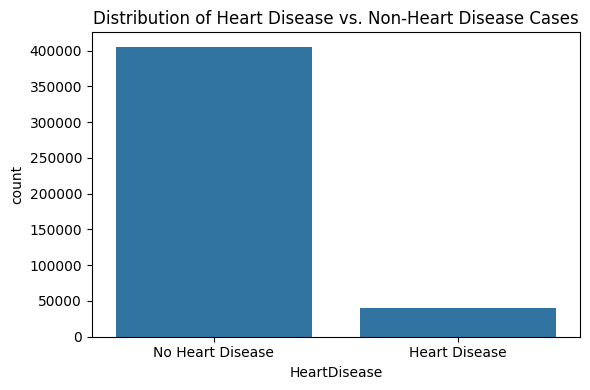

In [5]:
#Table 1: Dataset Characteristics

import matplotlib.pyplot as plt
import seaborn as sns

# --- Table 1 (CSV, saved in its own folder) ---
table1_folder = fig_folder('table1_dataset_characteristics')

missing_stats = df_raw.isnull().sum()
missing_pct = (missing_stats / len(df_raw) * 100).round(2)
table1 = pd.DataFrame({'Missing_Count': missing_stats, 'Missing_%': missing_pct})
table1 = table1[table1['Missing_Count'] > 0].sort_values('Missing_%', ascending=False)
table1.to_csv(f'{table1_folder}/table1_missing_value_stats.csv')

class_dist = df_raw['HeartDisease'].value_counts(normalize=True).rename({0:'No Heart Disease',1:'Heart Disease'})
class_dist.to_csv(f'{table1_folder}/table1_class_distribution.csv')

print(table1.head(10))
print(class_dist)

# --- Class distribution figure (PDF + PNG, 300 DPI) ---
fig, ax = plt.subplots(figsize=(6,4))
sns.countplot(x='HeartDisease', data=df_raw, ax=ax)
ax.set_title('Distribution of Heart Disease vs. Non-Heart Disease Cases')
ax.set_xticklabels(['No Heart Disease', 'Heart Disease'])
plt.tight_layout()
save_figure(fig, 'table1_dataset_characteristics')
plt.show()

In [ ]:
#nonono
import os

files = [
    f'{MODELS_DIR}/preprocessing_checkpoint.pkl',
    f'{MODELS_DIR}/encoding_checkpoint.pkl',
    f'{MODELS_DIR}/scaling_checkpoint.pkl',
    f'{MODELS_DIR}/fe_checkpoint.pkl'
]

for f in files:
    print(f)
    print("Exists:", os.path.exists(f))
    if os.path.exists(f):
        print("Size:", os.path.getsize(f) / (1024**2), "MB")
    print()

/content/drive/MyDrive/CVD/models/preprocessing_checkpoint.pkl
Exists: True
Size: 67.65292072296143 MB

/content/drive/MyDrive/CVD/models/encoding_checkpoint.pkl
Exists: True
Size: 122.7820873260498 MB

/content/drive/MyDrive/CVD/models/scaling_checkpoint.pkl
Exists: True
Size: 122.78310966491699 MB

/content/drive/MyDrive/CVD/models/fe_checkpoint.pkl
Exists: True
Size: 132.94355583190918 MB



In [ ]:
#nonono

row_missing_pct = df_raw.isnull().mean(axis=1)

print("Total rows:", len(df_raw))

print("\nRows with >10% missing:",
      (row_missing_pct > 0.10).sum())

print("Rows with >20% missing:",
      (row_missing_pct > 0.20).sum())

print("Rows with >30% missing:",
      (row_missing_pct > 0.30).sum())

print("Rows with >40% missing:",
      (row_missing_pct > 0.40).sum())

print("Rows with >50% missing:",
      (row_missing_pct > 0.50).sum())

print("\nRow missingness summary:")
print(row_missing_pct.describe())

Total rows: 445132

Rows with >10% missing: 51295
Rows with >20% missing: 36595
Rows with >30% missing: 24316
Rows with >40% missing: 18628
Rows with >50% missing: 1384

Row missingness summary:
count    445132.000000
mean          0.049460
std           0.108555
min           0.000000
25%           0.000000
50%           0.000000
75%           0.048780
max           0.926829
dtype: float64


In [6]:
#Drop Non-Predictive Columns

df_work = df_raw.drop(columns=['State', 'HadHeartAttack', 'HadAngina'])
print(df_work.shape)

(445132, 38)


In [7]:
#Leakage-Safe Split (BEFORE any fitting)

from sklearn.model_selection import train_test_split

X = df_work.drop(columns=['HeartDisease'])
y = df_work['HeartDisease']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

Train: (356105, 37), Val: (44513, 37), Test: (44514, 37)


In [8]:
#Missing Values + Duplicates (fit on TRAIN only)
import joblib

CKPT = f'{MODELS_DIR}/preprocessing_checkpoint.pkl'

if os.path.exists(CKPT):
    print("Checkpoint found — loading.")
    d = joblib.load(CKPT)
    X_train, X_val, X_test, y_train = d['X_train'], d['X_val'], d['X_test'], d['y_train']
else:
    train_full = X_train.copy(); train_full['HeartDisease'] = y_train
    before = len(train_full)
    train_full = train_full.drop_duplicates()
    print(f"Removed {before - len(train_full)} duplicates from TRAIN only.")
    X_train = train_full.drop(columns=['HeartDisease']); y_train = train_full['HeartDisease']

    continuous_cols = ['BMI','HeightInMeters','WeightInKilograms','PhysicalHealthDays','MentalHealthDays','SleepHours']
    continuous_cols = [c for c in continuous_cols if c in X_train.columns]
    medians = X_train[continuous_cols].median()
    for s in [X_train, X_val, X_test]:
        s[continuous_cols] = s[continuous_cols].fillna(medians)

    cat_cols = X_train.select_dtypes(include='object').columns.tolist()
    modes = X_train[cat_cols].mode().iloc[0]
    for s in [X_train, X_val, X_test]:
        s[cat_cols] = s[cat_cols].fillna(modes)

    joblib.dump({'X_train':X_train,'X_val':X_val,'X_test':X_test,'y_train':y_train}, CKPT)
    print("Saved.")

Checkpoint found — loading.


In [9]:
#Categorical Encoding (fit on TRAIN only)
CKPT = f'{MODELS_DIR}/encoding_checkpoint.pkl'

binary_cols = ['Sex','PhysicalActivities','HadAsthma','HadSkinCancer','HadCOPD',
               'HadDepressiveDisorder','HadKidneyDisease','HadArthritis','DeafOrHardOfHearing',
               'BlindOrVisionDifficulty','DifficultyConcentrating','DifficultyWalking',
               'DifficultyDressingBathing','DifficultyErrands','ChestScan','AlcoholDrinkers',
               'HIVTesting','FluVaxLast12','PneumoVaxEver','HighRiskLastYear','CovidPos','HadStroke']
binary_cols = [c for c in binary_cols if c in X_train.columns]
binary_map = {'Yes':1,'No':0,'Male':1,'Female':0}

ordinal_maps = {
    'GeneralHealth': {'Poor':0,'Fair':1,'Good':2,'Very good':3,'Excellent':4},
    'AgeCategory': {f'Age {a}': i for i, a in enumerate(
        ['18 to 24','25 to 29','30 to 34','35 to 39','40 to 44','45 to 49','50 to 54',
         '55 to 59','60 to 64','65 to 69','70 to 74','75 to 79','80 or older'])},
    'RemovedTeeth': {'None of them':0,'1 to 5':1,'6 or more, but not all':2,'All':3},
    'SmokerStatus': {'Never smoked':0,'Former smoker':1,
                      'Current smoker - now smokes some days':2,
                      'Current smoker - now smokes every day':3},
    'ECigaretteUsage': {'Never used e-cigarettes in my entire life':0,'Not at all (right now)':1,
                         'Use them some days':2,'Use them every day':3},
    'LastCheckupTime': {'Within past year (anytime less than 12 months ago)':0,
                         'Within past 2 years (1 year but less than 2 years ago)':1,
                         'Within past 5 years (2 years but less than 5 years ago)':2,
                         '5 or more years ago':3},
}
nominal_cols = [c for c in ['RaceEthnicityCategory','HadDiabetes','TetanusLast10Tdap'] if c in X_train.columns]

if os.path.exists(CKPT):
    d = joblib.load(CKPT); X_train, X_val, X_test = d['X_train'], d['X_val'], d['X_test']
else:
    for s in [X_train, X_val, X_test]:
        for c in binary_cols: s[c] = s[c].map(binary_map)
        for c, mp in ordinal_maps.items():
            if c in s.columns: s[c] = s[c].map(mp)

    Xtr = pd.get_dummies(X_train, columns=nominal_cols, drop_first=True)
    Xv  = pd.get_dummies(X_val, columns=nominal_cols, drop_first=True).reindex(columns=Xtr.columns, fill_value=0)
    Xte = pd.get_dummies(X_test, columns=nominal_cols, drop_first=True).reindex(columns=Xtr.columns, fill_value=0)
    X_train, X_val, X_test = Xtr, Xv, Xte

    joblib.dump({'X_train':X_train,'X_val':X_val,'X_test':X_test}, CKPT)
    print("Saved.")
print(X_train.shape)

(354903, 44)


In [10]:
#Feature Scaling (fit on TRAIN only)

from sklearn.preprocessing import StandardScaler
CKPT = f'{MODELS_DIR}/scaling_checkpoint.pkl'
continuous_cols = [c for c in ['BMI','HeightInMeters','WeightInKilograms','PhysicalHealthDays','MentalHealthDays','SleepHours'] if c in X_train.columns]

if os.path.exists(CKPT):
    d = joblib.load(CKPT); X_train, X_val, X_test = d['X_train'], d['X_val'], d['X_test']
else:
    scaler = StandardScaler()
    X_train[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
    X_val[continuous_cols]   = scaler.transform(X_val[continuous_cols])
    X_test[continuous_cols]  = scaler.transform(X_test[continuous_cols])
    joblib.dump(scaler, f'{MODELS_DIR}/scaler.pkl')
    joblib.dump({'X_train':X_train,'X_val':X_val,'X_test':X_test}, CKPT)

In [11]:
#Feature Engineering
CKPT = f'{MODELS_DIR}/fe_checkpoint.pkl'
if os.path.exists(CKPT):
    d = joblib.load(CKPT); X_train, X_val, X_test = d['X_train'], d['X_val'], d['X_test']
else:
    def engineer(s):
        s = s.copy()
        s['BMI_Category'] = pd.qcut(s['BMI'], q=4, labels=[0,1,2,3], duplicates='drop').astype(float)
        diabetes_col = 'HadDiabetes_Yes' if 'HadDiabetes_Yes' in s.columns else 0
        s['Health_Risk_Score'] = (4 - s['GeneralHealth']) + s.get(diabetes_col, 0) + s['HadStroke'] + s['HadKidneyDisease']
        s['Lifestyle_Risk_Interaction'] = s['SmokerStatus'] * (1 - s['PhysicalActivities'])
        return s
    X_train, X_val, X_test = engineer(X_train), engineer(X_val), engineer(X_test)
    joblib.dump({'X_train':X_train,'X_val':X_val,'X_test':X_test}, CKPT)

                       count          mean       std       min       25%  \
Sex                 354903.0  4.699228e-01  0.499095  0.000000  0.000000   
GeneralHealth       354903.0  2.432845e+00  1.051319  0.000000  2.000000   
PhysicalHealthDays  354903.0 -5.305501e-18  1.000001 -0.493331 -0.493331   
MentalHealthDays    354903.0 -1.558616e-17  1.000001 -0.516983 -0.516983   
LastCheckupTime     354903.0  3.343702e-01  0.769008  0.000000  0.000000   
PhysicalActivities  354903.0  7.604557e-01  0.426806  0.000000  1.000000   
SleepHours          354903.0 -8.855682e-17  1.000001 -4.029283 -0.683586   
RemovedTeeth        354903.0  6.682361e-01  0.877564  0.000000  0.000000   
HadStroke           354903.0  4.342031e-02  0.203802  0.000000  0.000000   
HadAsthma           354903.0  1.502101e-01  0.357278  0.000000  0.000000   

                         50%       75%        max  
Sex                 0.000000  1.000000   1.000000  
GeneralHealth       2.000000  3.000000   4.000000  
Physica

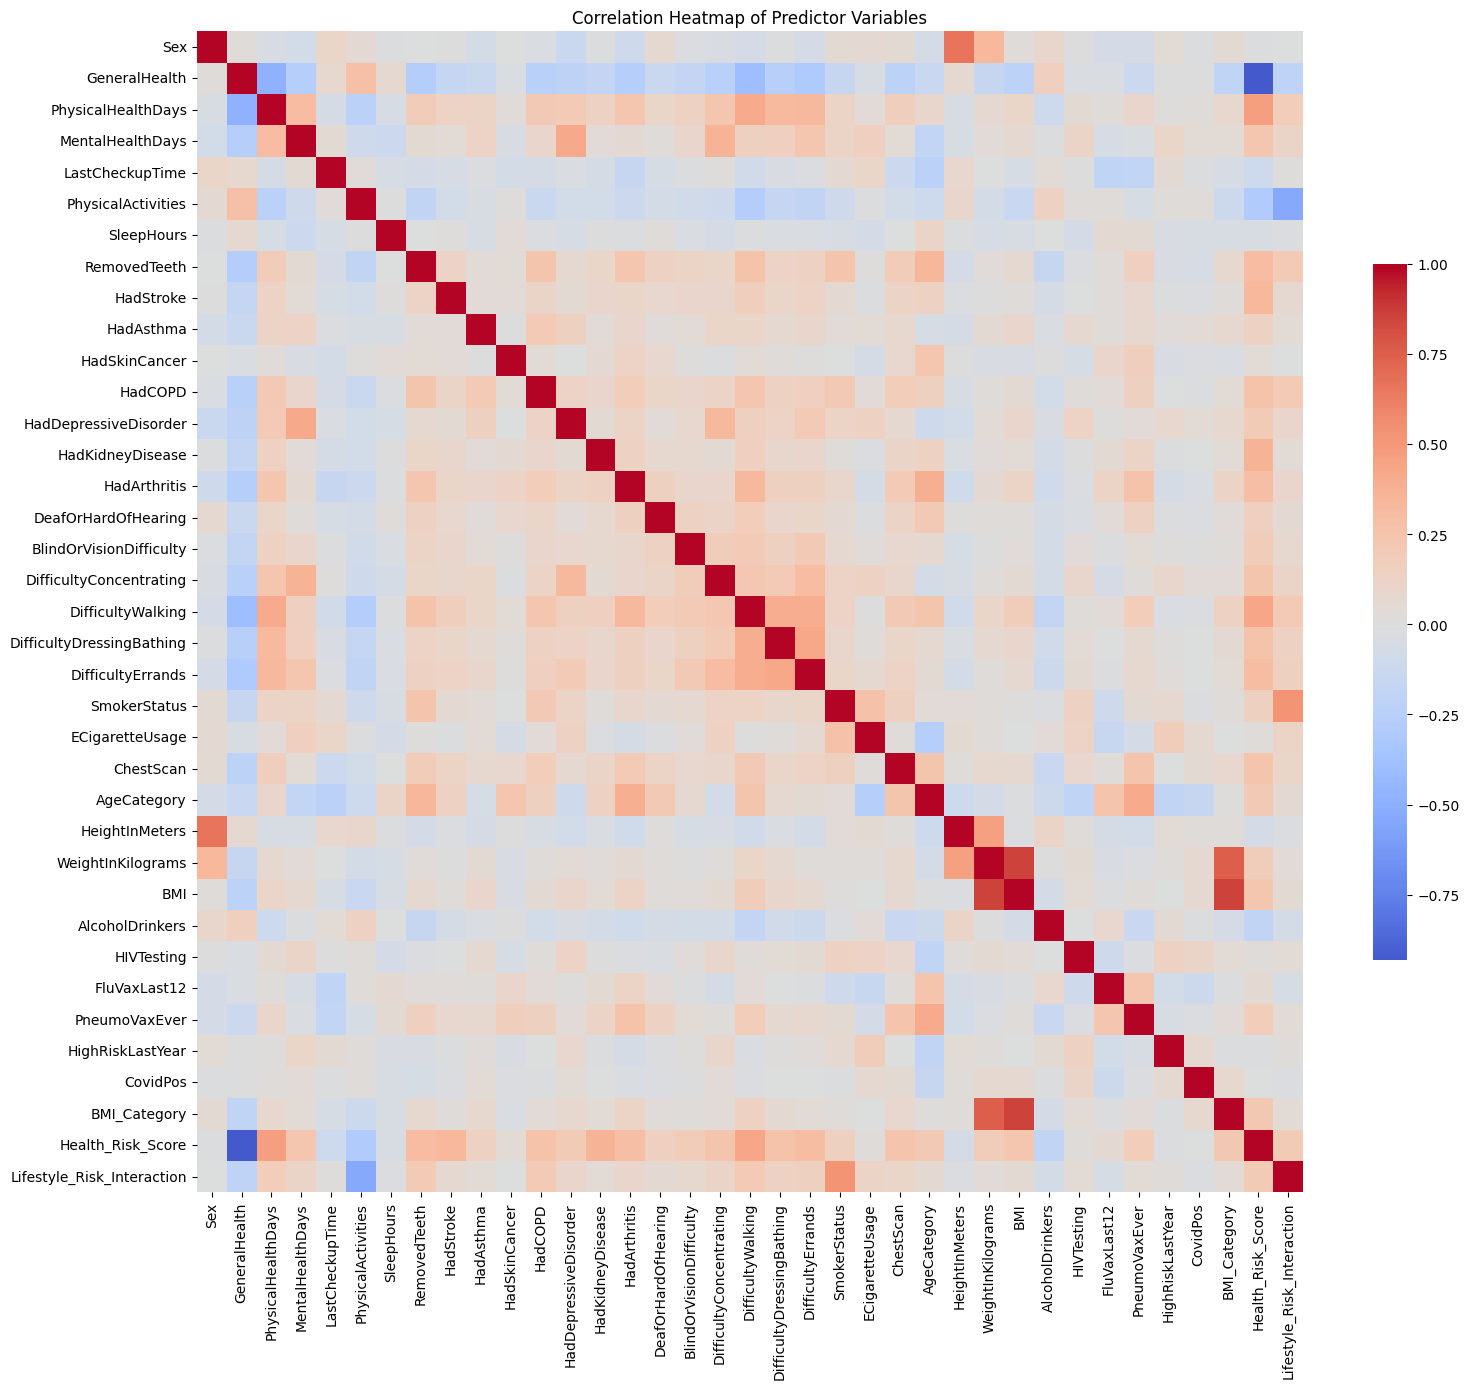

In [12]:
#Table 3 + Figure 2: EDA & Correlation Heatmap (Section 3.3)

table3_folder = fig_folder('table3_statistical_summary')
table3 = X_train.describe().T
table3.to_csv(f'{table3_folder}/table3_statistical_summary.csv')
print(table3.head(10))

# Figure 2: Correlation Heatmap
fig, ax = plt.subplots(figsize=(16,14))
corr = X_train.select_dtypes(include=['number']).corr()
sns.heatmap(corr, cmap='coolwarm', center=0, ax=ax, cbar_kws={'shrink':0.6})
ax.set_title('Correlation Heatmap of Predictor Variables')
plt.tight_layout()
save_figure(fig, 'figure2_correlation_heatmap')
plt.show()

In [13]:
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import RandomOverSampler
import numpy as np

classes = np.unique(y_train)
weights = compute_class_weight('balanced', classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, weights))
scale_pos_weight = class_weight_dict[0] / class_weight_dict[1]
print("Class weights (TRAIN only):", class_weight_dict)

ros = RandomOverSampler(random_state=42)
X_train_ros, y_train_ros = ros.fit_resample(X_train, y_train)
print("After ROS:", y_train_ros.value_counts())

# Save BOTH versions to Drive so later cells can use either
joblib.dump({'X_train_ros': X_train_ros, 'y_train_ros': y_train_ros},
            f'{MODELS_DIR}/ensemble/ros_train_data.pkl')

Class weights (TRAIN only): {np.int64(0): np.float64(0.5492086139447361), np.int64(1): np.float64(5.580411333689739)}
After ROS: HeartDisease
0    323104
1    323104
Name: count, dtype: int64


['/content/drive/MyDrive/CVD/models/ensemble/ros_train_data.pkl']

In [14]:
import re

def sanitize_columns(df):
    """Replaces any character that isn't a letter/number/underscore with '_'.
    Used ONLY for LightGBM, since its internal JSON parser rejects
    commas, brackets, quotes, and colons in feature names."""
    df = df.copy()
    df.columns = [re.sub(r'[^\w]+', '_', str(c)) for c in df.columns]
    return df

# Sanitized copies — ONLY for LightGBM. RF/XGBoost/CatBoost keep original names
# (they already trained fine with commas, so retraining them would be wasted time).
X_train_lgbm     = sanitize_columns(X_train)
X_val_lgbm       = sanitize_columns(X_val)
X_test_lgbm      = sanitize_columns(X_test)
X_train_ros_lgbm = sanitize_columns(X_train_ros)

print("Sanitized columns for LightGBM:")
print(list(X_train_lgbm.columns))

Sanitized columns for LightGBM:
['Sex', 'GeneralHealth', 'PhysicalHealthDays', 'MentalHealthDays', 'LastCheckupTime', 'PhysicalActivities', 'SleepHours', 'RemovedTeeth', 'HadStroke', 'HadAsthma', 'HadSkinCancer', 'HadCOPD', 'HadDepressiveDisorder', 'HadKidneyDisease', 'HadArthritis', 'DeafOrHardOfHearing', 'BlindOrVisionDifficulty', 'DifficultyConcentrating', 'DifficultyWalking', 'DifficultyDressingBathing', 'DifficultyErrands', 'SmokerStatus', 'ECigaretteUsage', 'ChestScan', 'AgeCategory', 'HeightInMeters', 'WeightInKilograms', 'BMI', 'AlcoholDrinkers', 'HIVTesting', 'FluVaxLast12', 'PneumoVaxEver', 'HighRiskLastYear', 'CovidPos', 'RaceEthnicityCategory_Hispanic', 'RaceEthnicityCategory_Multiracial_Non_Hispanic', 'RaceEthnicityCategory_Other_race_only_Non_Hispanic', 'RaceEthnicityCategory_White_only_Non_Hispanic', 'HadDiabetes_No_pre_diabetes_or_borderline_diabetes', 'HadDiabetes_Yes', 'HadDiabetes_Yes_but_only_during_pregnancy_female_', 'TetanusLast10Tdap_Yes_received_Tdap', 'Tetanus

In [ ]:
#Har model DONO versions par train ho — class-weighted AND ROS
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
import time, json

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grids = {
    'random_forest': {'n_estimators':[200,300,400],'max_depth':[8,12,16],'min_samples_leaf':[1,3,5]},
    'xgboost':       {'n_estimators':[200,300,400],'max_depth':[4,6,8],'learning_rate':[0.01,0.05,0.1]},
    'lightgbm':      {'n_estimators':[200,300,400],'max_depth':[6,8,10],'learning_rate':[0.01,0.05,0.1]},
    'catboost':      {'iterations':[200,300,400],'depth':[4,6,8],'learning_rate':[0.01,0.05,0.1]},
}

def build_estimator(name, use_class_weight=True):
    if name=='random_forest': return RandomForestClassifier(class_weight='balanced' if use_class_weight else None, n_jobs=-1, random_state=42)
    if name=='xgboost':       return XGBClassifier(scale_pos_weight=scale_pos_weight if use_class_weight else 1, eval_metric='auc', random_state=42)
    if name=='lightgbm':      return LGBMClassifier(class_weight='balanced' if use_class_weight else None, random_state=42)
    if name=='catboost':      return CatBoostClassifier(class_weights=[class_weight_dict[0],class_weight_dict[1]] if use_class_weight else None, verbose=False, random_state=42)

def train_strategy(name, X_tr, y_tr, use_class_weight, strategy_label):
    """strategy_label is 'classweight' or 'ros' — checkpoints are kept SEPARATE."""
    model_path = f'{MODELS_DIR}/{name}/{name}_{strategy_label}_model.pkl'
    config_path = f'{RESULTS_DIR}/{name}/{name}_{strategy_label}_config.json'

    if os.path.exists(model_path):
        print(f"[{name}/{strategy_label}] Checkpoint found — LOADING.")
        return joblib.load(model_path), json.load(open(config_path))

    print(f"[{name}/{strategy_label}] Running RandomizedSearchCV...")
    start = time.time()
    search = RandomizedSearchCV(build_estimator(name, use_class_weight), param_grids[name],
                                 n_iter=8, scoring='roc_auc', cv=cv, random_state=42, n_jobs=-1)
    search.fit(X_tr, y_tr)
    elapsed = time.time() - start

    joblib.dump(search.best_estimator_, model_path)
    cfg = {'best_params': search.best_params_, 'best_cv_auc': search.best_score_, 'training_time_sec': elapsed}
    json.dump(cfg, open(config_path,'w'), indent=2)
    print(f"[{name}/{strategy_label}] Best: {search.best_params_} | {elapsed:.1f}s")
    return search.best_estimator_, cfg

base_models_cw, base_models_ros, training_config = {}, {}, {}
for name in ['random_forest','xgboost','lightgbm','catboost']:
    m_cw, cfg_cw = train_strategy(name, X_train, y_train, True, 'classweight')
    m_ros, cfg_ros = train_strategy(name, X_train_ros, y_train_ros, False, 'ros')
    base_models_cw[name] = m_cw
    base_models_ros[name] = m_ros
    training_config[name] = cfg_cw   # class-weighted used as PRIMARY for all downstream cells

base_models = base_models_cw   # <-- everything downstream (Cells 14-20) uses the PRIMARY (class-weighted) models

[random_forest/classweight] Running RandomizedSearchCV...


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[random_forest/classweight] Best: {'n_estimators': 400, 'min_samples_leaf': 5, 'max_depth': 12} | 5961.1s
[random_forest/ros] Running RandomizedSearchCV...


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[random_forest/ros] Best: {'n_estimators': 200, 'min_samples_leaf': 3, 'max_depth': 16} | 12261.1s
[xgboost/classweight] Running RandomizedSearchCV...


In [15]:
def build_estimator(name, use_class_weight=True):
    if name=='random_forest':
        # RF stays CPU-only — sklearn has no GPU support for RF
        return RandomForestClassifier(class_weight='balanced' if use_class_weight else None,
                                       n_jobs=-1, random_state=42)
    if name=='xgboost':
        return XGBClassifier(scale_pos_weight=scale_pos_weight if use_class_weight else 1,
                              eval_metric='auc', random_state=42,
                              tree_method='hist', device='cuda')   # <-- GPU enabled
    if name=='lightgbm':
        return LGBMClassifier(class_weight='balanced' if use_class_weight else None,
                               random_state=42, device='gpu')       # <-- GPU enabled
    if name=='catboost':
        return CatBoostClassifier(
        auto_class_weights='Balanced' if use_class_weight else None,
        verbose=False,
        random_state=42,
        task_type='GPU',
        devices='0'
    )     # <-- GPU enabled

In [16]:
#Har model DONO versions par train ho — class-weighted AND ROS
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
import time, json

In [17]:
def train_strategy(name, X_tr, y_tr, use_class_weight, strategy_label):
    model_path = f'{MODELS_DIR}/{name}/{name}_{strategy_label}_model.pkl'
    config_path = f'{RESULTS_DIR}/{name}/{name}_{strategy_label}_config.json'

    if os.path.exists(model_path):
        print(f"[{name}/{strategy_label}] Checkpoint found — LOADING.")
        return joblib.load(model_path), json.load(open(config_path))

    print(f"[{name}/{strategy_label}] Running RandomizedSearchCV...")
    start = time.time()

    search_n_jobs = -1 if name == 'random_forest' else 1   # GPU models: n_jobs=1

    search = RandomizedSearchCV(build_estimator(name, use_class_weight), param_grids[name],
                                 n_iter=8, scoring='roc_auc', cv=cv, random_state=42,
                                 n_jobs=search_n_jobs)
    search.fit(X_tr, y_tr)
    elapsed = time.time() - start

    joblib.dump(search.best_estimator_, model_path)
    cfg = {'best_params': search.best_params_, 'best_cv_auc': search.best_score_, 'training_time_sec': elapsed}
    json.dump(cfg, open(config_path,'w'), indent=2)
    print(f"[{name}/{strategy_label}] Best: {search.best_params_} | {elapsed:.1f}s")
    return search.best_estimator_, cfg

In [18]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

import time
import json
import joblib
import os
import numpy as np

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_grids = {
    'random_forest': {
        'n_estimators': [200, 300, 400],
        'max_depth': [8, 12, 16],
        'min_samples_leaf': [1, 3, 5]
    },

    'xgboost': {
        'n_estimators': [200, 300, 400],
        'max_depth': [4, 6, 8],
        'learning_rate': [0.01, 0.05, 0.1]
    },

    'lightgbm': {
        'n_estimators': [200, 300, 400],
        'max_depth': [6, 8, 10],
        'learning_rate': [0.01, 0.05, 0.1]
    },

    'catboost': {
        'iterations': [200, 300, 400],
        'depth': [4, 6, 8],
        'learning_rate': [0.01, 0.05, 0.1]
    }
}


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

import time
import json
import joblib
import os
import numpy as np

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_grids = {
    'random_forest': {
        'n_estimators': [200, 300, 400],
        'max_depth': [8, 12, 16],
        'min_samples_leaf': [1, 3, 5]
    },

    'xgboost': {
        'n_estimators': [200, 300, 400],
        'max_depth': [4, 6, 8],
        'learning_rate': [0.01, 0.05, 0.1]
    },

    'lightgbm': {
        'n_estimators': [200, 300, 400],
        'max_depth': [6, 8, 10],
        'learning_rate': [0.01, 0.05, 0.1]
    },

    'catboost': {
        'iterations': [200, 300, 400],
        'depth': [4, 6, 8],
        'learning_rate': [0.01, 0.05, 0.1]
    }
}



base_models_cw, base_models_ros, training_config = {}, {}, {}
for name in ['random_forest','xgboost','lightgbm','catboost']:
    m_cw, cfg_cw = train_strategy(name, X_train, y_train, True, 'classweight')
    m_ros, cfg_ros = train_strategy(name, X_train_ros, y_train_ros, False, 'ros')
    base_models_cw[name] = m_cw
    base_models_ros[name] = m_ros
    training_config[name] = cfg_cw

base_models = base_models_cw

print("All available models loaded/trained successfully.")
print("Class-weighted models:", list(base_models_cw.keys()))
print("ROS models:", list(base_models_ros.keys()))

[random_forest/classweight] Checkpoint found — LOADING.
[random_forest/ros] Checkpoint found — LOADING.
[xgboost/classweight] Running RandomizedSearchCV...


/usr/local/lib/python3.12/dist-packages/xgboost/core.py:553: UserWarning: [06:20:45] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


[xgboost/classweight] Best: {'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.05} | 119.6s
[xgboost/ros] Running RandomizedSearchCV...
[xgboost/ros] Best: {'n_estimators': 400, 'max_depth': 8, 'learning_rate': 0.05} | 218.6s
[lightgbm/classweight] Running RandomizedSearchCV...


ValueError: 
All the 40 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
40 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.12/dist-packages/lightgbm/sklearn.py", line 1560, in fit
    super().fit(
  File "/usr/local/lib/python3.12/dist-packages/lightgbm/sklearn.py", line 1049, in fit
    self._Booster = train(
                    ^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/lightgbm/engine.py", line 297, in train
    booster = Booster(params=params, train_set=train_set)
              ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/lightgbm/basic.py", line 3656, in __init__
    train_set.construct()
  File "/usr/local/lib/python3.12/dist-packages/lightgbm/basic.py", line 2590, in construct
    self._lazy_init(
  File "/usr/local/lib/python3.12/dist-packages/lightgbm/basic.py", line 2227, in _lazy_init
    return self.set_feature_name(feature_name)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/lightgbm/basic.py", line 3046, in set_feature_name
    _safe_call(
  File "/usr/local/lib/python3.12/dist-packages/lightgbm/basic.py", line 313, in _safe_call
    raise LightGBMError(_LIB.LGBM_GetLastError().decode("utf-8"))
lightgbm.basic.LightGBMError: Do not support special JSON characters in feature name.


In [ ]:
base_models_cw, base_models_ros, training_config = {}, {}, {}

X_train_map     = {'random_forest': X_train, 'xgboost': X_train, 'catboost': X_train, 'lightgbm': X_train_lgbm}
X_train_ros_map = {'random_forest': X_train_ros, 'xgboost': X_train_ros, 'catboost': X_train_ros, 'lightgbm': X_train_ros_lgbm}

for name in ['random_forest','xgboost','lightgbm','catboost']:
    m_cw, cfg_cw = train_strategy(name, X_train_map[name], y_train, True, 'classweight')
    m_ros, cfg_ros = train_strategy(name, X_train_ros_map[name], y_train_ros, False, 'ros')
    base_models_cw[name] = m_cw
    base_models_ros[name] = m_ros
    training_config[name] = cfg_cw

base_models = base_models_cw

[random_forest/classweight] Checkpoint found — LOADING.
[random_forest/ros] Checkpoint found — LOADING.
[xgboost/classweight] Checkpoint found — LOADING.
[xgboost/ros] Checkpoint found — LOADING.
[lightgbm/classweight] Running RandomizedSearchCV...
[LightGBM] [Info] Number of positive: 25439, number of negative: 258483
[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 799
[LightGBM] [Info] Number of data points in the train set: 283922, number of used features: 47
[LightGBM] [Info] Using GPU Device: Tesla T4, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 15 dense feature groups (4.33 MB) transferred to GPU in 0.041632 secs. 1 sparse feature groups
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Info] Number of posit

RuntimeError: Cannot clone object CatBoostClassifier(class_weights=[np.float64(0.5492086139447361), np.float64(5.580411333689739)], devices='0', random_state=42, task_type='GPU', verbose=False), as the constructor either does not set or modifies parameter class_weights

In [ ]:
base_models_cw, base_models_ros, training_config = {}, {}, {}

X_train_map     = {'random_forest': X_train, 'xgboost': X_train, 'catboost': X_train, 'lightgbm': X_train_lgbm}
X_train_ros_map = {'random_forest': X_train_ros, 'xgboost': X_train_ros, 'catboost': X_train_ros, 'lightgbm': X_train_ros_lgbm}

for name in ['random_forest','xgboost','lightgbm','catboost']:
    m_cw, cfg_cw = train_strategy(name, X_train_map[name], y_train, True, 'classweight')
    m_ros, cfg_ros = train_strategy(name, X_train_ros_map[name], y_train_ros, False, 'ros')
    base_models_cw[name] = m_cw
    base_models_ros[name] = m_ros
    training_config[name] = cfg_cw

base_models = base_models_cw

[random_forest/classweight] Checkpoint found — LOADING.
[random_forest/ros] Checkpoint found — LOADING.
[xgboost/classweight] Checkpoint found — LOADING.
[xgboost/ros] Checkpoint found — LOADING.
[lightgbm/classweight] Checkpoint found — LOADING.
[lightgbm/ros] Checkpoint found — LOADING.
[catboost/classweight] Running RandomizedSearchCV...
[catboost/classweight] Best: {'learning_rate': 0.1, 'iterations': 400, 'depth': 4} | 154.6s
[catboost/ros] Running RandomizedSearchCV...
[catboost/ros] Best: {'learning_rate': 0.1, 'iterations': 400, 'depth': 6} | 189.8s


In [19]:
base_models_cw, base_models_ros, training_config = {}, {}, {}

X_train_map     = {'random_forest': X_train, 'xgboost': X_train, 'catboost': X_train, 'lightgbm': X_train_lgbm}
X_train_ros_map = {'random_forest': X_train_ros, 'xgboost': X_train_ros, 'catboost': X_train_ros, 'lightgbm': X_train_ros_lgbm}

for name in ['random_forest','xgboost','lightgbm','catboost']:
    m_cw, cfg_cw = train_strategy(name, X_train_map[name], y_train, True, 'classweight')
    m_ros, cfg_ros = train_strategy(name, X_train_ros_map[name], y_train_ros, False, 'ros')
    base_models_cw[name] = m_cw
    base_models_ros[name] = m_ros
    training_config[name] = cfg_cw

base_models = base_models_cw

[random_forest/classweight] Checkpoint found — LOADING.
[random_forest/ros] Checkpoint found — LOADING.
[xgboost/classweight] Checkpoint found — LOADING.


/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:32:07] WARNING: /__w/xgboost/xgboost/src/collective/../data/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


[xgboost/ros] Checkpoint found — LOADING.
[lightgbm/classweight] Checkpoint found — LOADING.
[lightgbm/ros] Checkpoint found — LOADING.
[catboost/classweight] Checkpoint found — LOADING.
[catboost/ros] Checkpoint found — LOADING.


In [20]:
from sklearn.metrics import roc_auc_score

def predict_proba_safe(model, name, X, X_lgbm=None):
    """LightGBM needs sanitized column names; others use original X."""
    if name == 'lightgbm':
        return model.predict_proba(X_lgbm)[:, 1]
    return model.predict_proba(X)[:, 1]

selection_rows = []
for name in ['random_forest','xgboost','lightgbm','catboost']:
    proba_cw_val  = predict_proba_safe(base_models_cw[name], name, X_val, X_val_lgbm)
    proba_ros_val = predict_proba_safe(base_models_ros[name], name, X_val, X_val_lgbm)
    selection_rows.append({'Model': name, 'Strategy':'Class Weighting',
                            'Val_ROC_AUC': roc_auc_score(y_val, proba_cw_val)})
    selection_rows.append({'Model': name, 'Strategy':'ROS',
                            'Val_ROC_AUC': roc_auc_score(y_val, proba_ros_val)})

selection_table = pd.DataFrame(selection_rows)
folder = fig_folder('table_imbalance_strategy_selection')
selection_table.to_csv(f'{folder}/cw_vs_ros_validation_selection.csv', index=False)
print(selection_table)

# Decide winning strategy per model — based on VALIDATION set only
winning_strategy = {}
for name in ['random_forest','xgboost','lightgbm','catboost']:
    cw_auc = selection_table[(selection_table.Model==name) & (selection_table.Strategy=='Class Weighting')]['Val_ROC_AUC'].values[0]
    ros_auc = selection_table[(selection_table.Model==name) & (selection_table.Strategy=='ROS')]['Val_ROC_AUC'].values[0]
    winning_strategy[name] = 'classweight' if cw_auc >= ros_auc else 'ros'

print("\nWinning strategy per model (chosen on VALIDATION set):", winning_strategy)
joblib.dump(winning_strategy, f'{MODELS_DIR}/ensemble/winning_strategy.pkl')

# Build FINAL base_models dict — everything downstream uses THIS
base_models = {}
for name, strat in winning_strategy.items():
    base_models[name] = base_models_cw[name] if strat == 'classweight' else base_models_ros[name]

print("Final selected base_models:", {n: winning_strategy[n] for n in base_models})

           Model         Strategy  Val_ROC_AUC
0  random_forest  Class Weighting     0.839726
1  random_forest              ROS     0.836461
2        xgboost  Class Weighting     0.845088
3        xgboost              ROS     0.835025
4       lightgbm  Class Weighting     0.844854
5       lightgbm              ROS     0.843327
6       catboost  Class Weighting     0.845678
7       catboost              ROS     0.844235

Winning strategy per model (chosen on VALIDATION set): {'random_forest': 'classweight', 'xgboost': 'classweight', 'lightgbm': 'classweight', 'catboost': 'classweight'}
Final selected base_models: {'random_forest': 'classweight', 'xgboost': 'classweight', 'lightgbm': 'classweight', 'catboost': 'classweight'}


In [ ]:
#nono juct chking

print("X_val shape:", X_val.shape)

print("\nX_val columns:")
print(X_val.columns.tolist())

print("\nMissing engineered features:")

required_engineered = [
    "BMI_Category",
    "Health_Risk_Score",
    "Lifestyle_Risk_Interaction"
]

for col in required_engineered:
    print(
        col,
        "->",
        "PRESENT" if col in X_val.columns else "MISSING"
    )

X_val shape: (44513, 44)

X_val columns:
['Sex', 'GeneralHealth', 'PhysicalHealthDays', 'MentalHealthDays', 'LastCheckupTime', 'PhysicalActivities', 'SleepHours', 'RemovedTeeth', 'HadStroke', 'HadAsthma', 'HadSkinCancer', 'HadCOPD', 'HadDepressiveDisorder', 'HadKidneyDisease', 'HadArthritis', 'DeafOrHardOfHearing', 'BlindOrVisionDifficulty', 'DifficultyConcentrating', 'DifficultyWalking', 'DifficultyDressingBathing', 'DifficultyErrands', 'SmokerStatus', 'ECigaretteUsage', 'ChestScan', 'AgeCategory', 'HeightInMeters', 'WeightInKilograms', 'BMI', 'AlcoholDrinkers', 'HIVTesting', 'FluVaxLast12', 'PneumoVaxEver', 'HighRiskLastYear', 'CovidPos', 'RaceEthnicityCategory_Hispanic', 'RaceEthnicityCategory_Multiracial, Non-Hispanic', 'RaceEthnicityCategory_Other race only, Non-Hispanic', 'RaceEthnicityCategory_White only, Non-Hispanic', 'HadDiabetes_No, pre-diabetes or borderline diabetes', 'HadDiabetes_Yes', 'HadDiabetes_Yes, but only during pregnancy (female)', 'TetanusLast10Tdap_Yes, received

In [ ]:
#nono juct chking
for name in [
    "random_forest",
    "xgboost",
    "lightgbm",
    "catboost"
]:
    model = base_models_cw[name]

    if hasattr(model, "feature_names_in_"):
        print(
            f"\n{name}: "
            f"{len(model.feature_names_in_)} features"
        )

        missing_from_Xval = [
            c for c in model.feature_names_in_
            if c not in X_val.columns
        ]

        print(
            "Missing from X_val:",
            missing_from_Xval
        )


random_forest: 47 features
Missing from X_val: ['BMI_Category', 'Health_Risk_Score', 'Lifestyle_Risk_Interaction']

xgboost: 47 features
Missing from X_val: [np.str_('BMI_Category'), np.str_('Health_Risk_Score'), np.str_('Lifestyle_Risk_Interaction')]

lightgbm: 47 features
Missing from X_val: [np.str_('RaceEthnicityCategory_Multiracial_Non_Hispanic'), np.str_('RaceEthnicityCategory_Other_race_only_Non_Hispanic'), np.str_('RaceEthnicityCategory_White_only_Non_Hispanic'), np.str_('HadDiabetes_No_pre_diabetes_or_borderline_diabetes'), np.str_('HadDiabetes_Yes_but_only_during_pregnancy_female_'), np.str_('TetanusLast10Tdap_Yes_received_Tdap'), np.str_('TetanusLast10Tdap_Yes_received_tetanus_shot_but_not_sure_what_type'), np.str_('TetanusLast10Tdap_Yes_received_tetanus_shot_but_not_Tdap'), np.str_('BMI_Category'), np.str_('Health_Risk_Score'), np.str_('Lifestyle_Risk_Interaction')]


In [ ]:
# nono juct chking ============================================================
# RESTORE FINAL 47-FEATURE MATRICES FROM FEATURE-ENGINEERING CHECKPOINT
# ============================================================

import os
import joblib

FE_CKPT = f'{MODELS_DIR}/fe_checkpoint.pkl'

print("Feature-engineering checkpoint:")
print(FE_CKPT)

if not os.path.exists(FE_CKPT):
    raise FileNotFoundError(
        f"Feature-engineering checkpoint not found:\n{FE_CKPT}"
    )

fe_data = joblib.load(FE_CKPT)

X_train = fe_data['X_train']
X_val   = fe_data['X_val']
X_test  = fe_data['X_test']

print("\n✓ 47-feature matrices restored from fe_checkpoint.pkl")

print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)

required_engineered = [
    "BMI_Category",
    "Health_Risk_Score",
    "Lifestyle_Risk_Interaction"
]

for col in required_engineered:
    print(
        f"{col}:",
        "PRESENT" if col in X_val.columns else "MISSING"
    )

assert X_train.shape[1] == 47
assert X_val.shape[1] == 47
assert X_test.shape[1] == 47

assert all(col in X_val.columns for col in required_engineered)

print("\n✓ SUCCESS: X_val is restored to the required 47-feature format.")

Feature-engineering checkpoint:
/content/drive/MyDrive/CVD/models/fe_checkpoint.pkl

✓ 47-feature matrices restored from fe_checkpoint.pkl
X_train: (354903, 47)
X_val:   (44513, 47)
X_test:  (44514, 47)
BMI_Category: PRESENT
Health_Risk_Score: PRESENT
Lifestyle_Risk_Interaction: PRESENT

✓ SUCCESS: X_val is restored to the required 47-feature format.


In [ ]:
#nono juct chking ============================================================
# RESTORE LIGHTGBM 47-FEATURE VALIDATION MATRIX
# ============================================================

import re

def sanitize_columns(df):
    df = df.copy()
    df.columns = [
        re.sub(r'[^\w]+', '_', str(c))
        for c in df.columns
    ]
    return df

X_val_lgbm = sanitize_columns(X_val)

print("X_val:", X_val.shape)
print("X_val_lgbm:", X_val_lgbm.shape)

assert X_val.shape[1] == 47
assert X_val_lgbm.shape[1] == 47

print("\n✓ X_val_lgbm successfully restored to 47 features.")
print("\nLightGBM columns:")
print(list(X_val_lgbm.columns))

X_val: (44513, 47)
X_val_lgbm: (44513, 47)

✓ X_val_lgbm successfully restored to 47 features.

LightGBM columns:
['Sex', 'GeneralHealth', 'PhysicalHealthDays', 'MentalHealthDays', 'LastCheckupTime', 'PhysicalActivities', 'SleepHours', 'RemovedTeeth', 'HadStroke', 'HadAsthma', 'HadSkinCancer', 'HadCOPD', 'HadDepressiveDisorder', 'HadKidneyDisease', 'HadArthritis', 'DeafOrHardOfHearing', 'BlindOrVisionDifficulty', 'DifficultyConcentrating', 'DifficultyWalking', 'DifficultyDressingBathing', 'DifficultyErrands', 'SmokerStatus', 'ECigaretteUsage', 'ChestScan', 'AgeCategory', 'HeightInMeters', 'WeightInKilograms', 'BMI', 'AlcoholDrinkers', 'HIVTesting', 'FluVaxLast12', 'PneumoVaxEver', 'HighRiskLastYear', 'CovidPos', 'RaceEthnicityCategory_Hispanic', 'RaceEthnicityCategory_Multiracial_Non_Hispanic', 'RaceEthnicityCategory_Other_race_only_Non_Hispanic', 'RaceEthnicityCategory_White_only_Non_Hispanic', 'HadDiabetes_No_pre_diabetes_or_borderline_diabetes', 'HadDiabetes_Yes', 'HadDiabetes_Yes_b

In [21]:
import sys, platform, numpy, pandas, scipy, sklearn, statsmodels, xgboost, lightgbm, catboost, shap, imblearn
for n, v in [('Python', sys.version.split()[0]), ('OS', platform.platform()), ('numpy', numpy.__version__), ('pandas', pandas.__version__),
             ('scipy', scipy.__version__), ('scikit-learn', sklearn.__version__), ('statsmodels', statsmodels.__version__),
             ('xgboost', xgboost.__version__), ('lightgbm', lightgbm.__version__), ('catboost', catboost.__version__),
             ('shap', shap.__version__), ('imbalanced-learn', imblearn.__version__)]: print(f"{n:18s}{v}")

Python            3.13.15
OS                Linux-6.6.122+-x86_64-with-glibc2.39
numpy             2.1.3
pandas            2.2.3
scipy             1.16.3
scikit-learn      1.6.1
statsmodels       0.15.0
xgboost           3.4.1
lightgbm          4.6.0
catboost          1.2.10
shap              0.52.0
imbalanced-learn  0.14.2


[random_forest] Computing 5-fold CV scores with best params...
[random_forest] Done: [0.84614189 0.84401406 0.84104294 0.84287638 0.84213903]
[xgboost] Computing 5-fold CV scores with best params...
[xgboost] Done: [0.84984095 0.84756307 0.84582546 0.84784066 0.84686949]
[lightgbm] Computing 5-fold CV scores with best params...
[lightgbm] Done: [0.84990215 0.84804916 0.84533416 0.84796716 0.84693547]
[catboost] Computing 5-fold CV scores with best params...


RuntimeError: Cannot clone object CatBoostClassifier(depth=4, devices='0', iterations=400, learning_rate=0.1, random_state=42, scale_pos_weight=np.float64(0.09841722788947212), task_type='GPU', verbose=False), as the constructor either does not set or modifies parameter scale_pos_weight

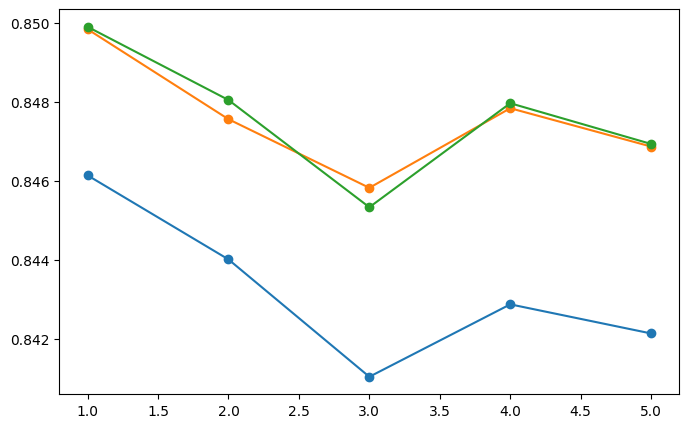

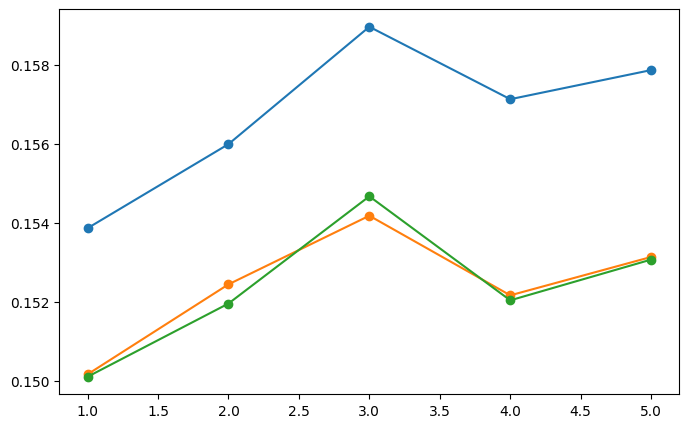

In [ ]:
from sklearn.model_selection import cross_val_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier

X_train_map = {'random_forest': X_train, 'xgboost': X_train, 'catboost': X_train, 'lightgbm': X_train_lgbm}

def rebuild_with_best_params(name):
    """Rebuilds a fresh (untrained) model using the best params already found —
    avoids repeating the RandomizedSearchCV, only used for CV-curve diagnostics."""
    params = training_config[name]['best_params']
    if name == 'random_forest':
        return RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42, **params)
    if name == 'xgboost':
        return XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='auc', random_state=42,
                              tree_method='hist', device='cuda', **params)
    if name == 'lightgbm':
        return LGBMClassifier(class_weight='balanced', random_state=42, device='gpu', verbose=-1, **params)
    if name == 'catboost':
        return CatBoostClassifier(auto_class_weights='Balanced', verbose=False, random_state=42,
                                   task_type='GPU', devices='0', **params)

table7_data = {}
fig8, ax8 = plt.subplots(figsize=(8,5))
fig9, ax9 = plt.subplots(figsize=(8,5))

for name in ['random_forest','xgboost','lightgbm','catboost']:
    ckpt = f'{RESULTS_DIR}/{name}/{name}_cv_scores.pkl'
    if os.path.exists(ckpt):
        scores = joblib.load(ckpt)
        print(f"[{name}] CV scores checkpoint found — loading.")
    else:
        print(f"[{name}] Computing 5-fold CV scores with best params...")
        model = rebuild_with_best_params(name)
        scores = cross_val_score(model, X_train_map[name], y_train, cv=cv, scoring='roc_auc', n_jobs=1)
        joblib.dump(scores, ckpt)
        print(f"[{name}] Done: {scores}")

    table7_data[name] = {'Mean_AUC': scores.mean(), 'Std_AUC': scores.std()}
    ax8.plot(range(1, len(scores)+1), scores, marker='o', label=name)
    ax9.plot(range(1, len(scores)+1), 1 - scores, marker='o', label=name)

table7 = pd.DataFrame(table7_data).T
table7_folder = fig_folder('table7_training_stability')
table7.to_csv(f'{table7_folder}/table7_training_stability.csv')
print(table7)

ax8.set_title('Cross-Validation AUC per Fold (Training Stability)')
ax8.set_xlabel('Fold'); ax8.set_ylabel('ROC-AUC'); ax8.legend()
save_figure(fig8, 'figure8_training_accuracy_curves')

ax9.set_title('1 - AUC per Fold (Proxy for Error/Loss)')
ax9.set_xlabel('Fold'); ax9.set_ylabel('1 - ROC-AUC'); ax9.legend()
save_figure(fig9, 'figure9_training_loss_curves')
plt.show()

In [ ]:
import torch
print(torch.cuda.is_available())

True


[random_forest] CV scores checkpoint found — loading.
[xgboost] CV scores checkpoint found — loading.
[lightgbm] CV scores checkpoint found — loading.
[catboost] Computing 5-fold CV scores with best params...
[catboost] Done: [0.85060835 0.84861339 0.84679698 0.84851979 0.8469958 ]
               Mean_AUC   Std_AUC
random_forest  0.843243  0.001743
xgboost        0.847588  0.001324
lightgbm       0.847638  0.001497
catboost       0.848307  0.001374
Saved: /content/drive/MyDrive/CVD/figures/figure8_training_accuracy_curves/figure8_training_accuracy_curves.pdf and .png
Saved: /content/drive/MyDrive/CVD/figures/figure9_training_loss_curves/figure9_training_loss_curves.pdf and .png


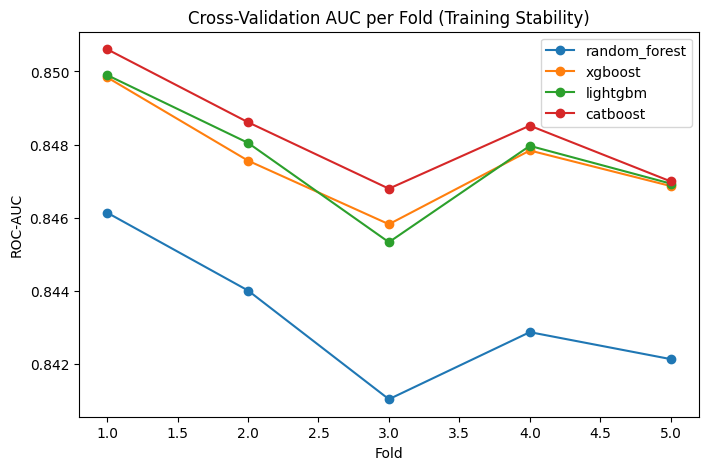

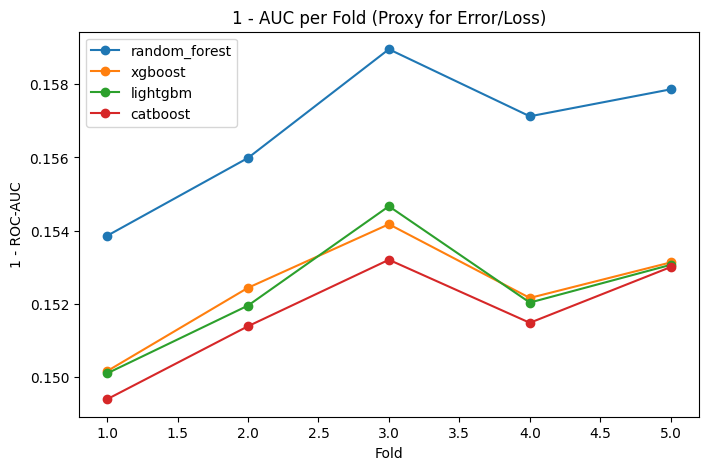

In [ ]:
from sklearn.model_selection import cross_val_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier

X_train_map = {'random_forest': X_train, 'xgboost': X_train, 'catboost': X_train, 'lightgbm': X_train_lgbm}

def rebuild_with_best_params(name):
    """Rebuilds a fresh (untrained) model using the best params already found —
    avoids repeating the RandomizedSearchCV, only used for CV-curve diagnostics."""
    params = training_config[name]['best_params']
    if name == 'random_forest':
        return RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42, **params)
    if name == 'xgboost':
        return XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='auc', random_state=42,
                              tree_method='hist', device='cuda', **params)
    if name == 'lightgbm':
        return LGBMClassifier(class_weight='balanced', random_state=42, device='gpu', verbose=-1, **params)
    if name == 'catboost':
        return CatBoostClassifier(auto_class_weights='Balanced', verbose=False, random_state=42,
                                   task_type='GPU', devices='0', **params)

table7_data = {}
fig8, ax8 = plt.subplots(figsize=(8,5))
fig9, ax9 = plt.subplots(figsize=(8,5))

for name in ['random_forest','xgboost','lightgbm','catboost']:
    ckpt = f'{RESULTS_DIR}/{name}/{name}_cv_scores.pkl'
    if os.path.exists(ckpt):
        scores = joblib.load(ckpt)
        print(f"[{name}] CV scores checkpoint found — loading.")
    else:
        print(f"[{name}] Computing 5-fold CV scores with best params...")
        model = rebuild_with_best_params(name)
        scores = cross_val_score(model, X_train_map[name], y_train, cv=cv, scoring='roc_auc', n_jobs=1)
        joblib.dump(scores, ckpt)
        print(f"[{name}] Done: {scores}")

    table7_data[name] = {'Mean_AUC': scores.mean(), 'Std_AUC': scores.std()}
    ax8.plot(range(1, len(scores)+1), scores, marker='o', label=name)
    ax9.plot(range(1, len(scores)+1), 1 - scores, marker='o', label=name)

table7 = pd.DataFrame(table7_data).T
table7_folder = fig_folder('table7_training_stability')
table7.to_csv(f'{table7_folder}/table7_training_stability.csv')
print(table7)

ax8.set_title('Cross-Validation AUC per Fold (Training Stability)')
ax8.set_xlabel('Fold'); ax8.set_ylabel('ROC-AUC'); ax8.legend()
save_figure(fig8, 'figure8_training_accuracy_curves')

ax9.set_title('1 - AUC per Fold (Proxy for Error/Loss)')
ax9.set_xlabel('Fold'); ax9.set_ylabel('1 - ROC-AUC'); ax9.legend()
save_figure(fig9, 'figure9_training_loss_curves')
plt.show()

[random_forest] CV scores checkpoint found — loading.
[xgboost] CV scores checkpoint found — loading.
[lightgbm] CV scores checkpoint found — loading.
[catboost] CV scores checkpoint found — loading.
               Mean_AUC   Std_AUC
random_forest  0.843243  0.001743
xgboost        0.847588  0.001324
lightgbm       0.847638  0.001497
catboost       0.848307  0.001374
Saved: /content/drive/MyDrive/CVD/figures/figure8_training_accuracy_curves/figure8_training_accuracy_curves.pdf and .png
Saved: /content/drive/MyDrive/CVD/figures/figure9_training_loss_curves/figure9_training_loss_curves.pdf and .png


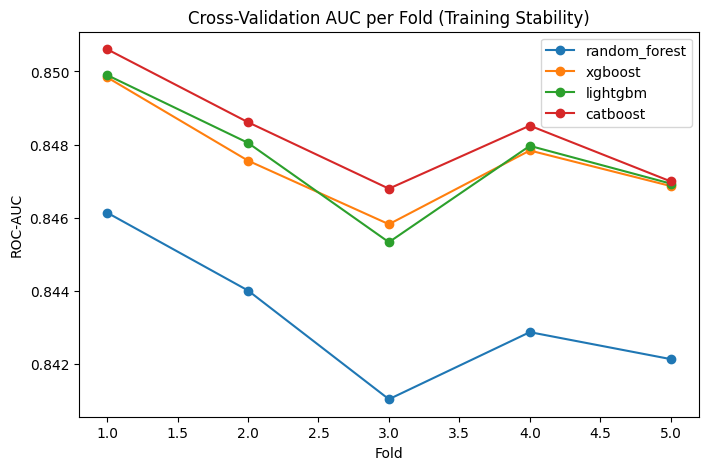

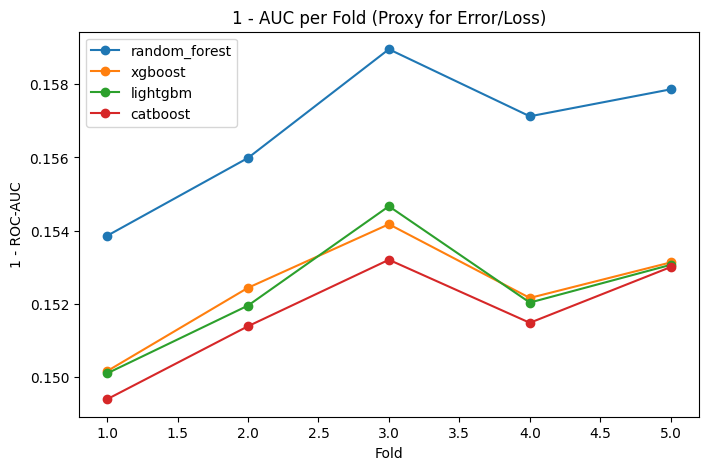

In [25]:
#do

from sklearn.model_selection import cross_val_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier

X_train_map = {'random_forest': X_train, 'xgboost': X_train, 'catboost': X_train, 'lightgbm': X_train_lgbm}

def rebuild_with_best_params(name):
    """Rebuilds a fresh (untrained) model using the best params already found —
    avoids repeating the RandomizedSearchCV, only used for CV-curve diagnostics."""
    params = training_config[name]['best_params']
    if name == 'random_forest':
        return RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42, **params)
    if name == 'xgboost':
        return XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='auc', random_state=42,
                              tree_method='hist', device='cuda', **params)
    if name == 'lightgbm':
        return LGBMClassifier(class_weight='balanced', random_state=42, device='gpu', verbose=-1, **params)
    if name == 'catboost':
        return CatBoostClassifier(auto_class_weights='Balanced', verbose=False, random_state=42,
                                   task_type='GPU', devices='0', **params)

table7_data = {}
fig8, ax8 = plt.subplots(figsize=(8,5))
fig9, ax9 = plt.subplots(figsize=(8,5))

for name in ['random_forest','xgboost','lightgbm','catboost']:
    ckpt = f'{RESULTS_DIR}/{name}/{name}_cv_scores.pkl'
    if os.path.exists(ckpt):
        scores = joblib.load(ckpt)
        print(f"[{name}] CV scores checkpoint found — loading.")
    else:
        print(f"[{name}] Computing 5-fold CV scores with best params...")
        model = rebuild_with_best_params(name)
        scores = cross_val_score(model, X_train_map[name], y_train, cv=cv, scoring='roc_auc', n_jobs=1)
        joblib.dump(scores, ckpt)
        print(f"[{name}] Done: {scores}")

    table7_data[name] = {'Mean_AUC': scores.mean(), 'Std_AUC': scores.std()}
    ax8.plot(range(1, len(scores)+1), scores, marker='o', label=name)
    ax9.plot(range(1, len(scores)+1), 1 - scores, marker='o', label=name)

table7 = pd.DataFrame(table7_data).T
table7_folder = fig_folder('table7_training_stability')
table7.to_csv(f'{table7_folder}/table7_training_stability.csv')
print(table7)

ax8.set_title('Cross-Validation AUC per Fold (Training Stability)')
ax8.set_xlabel('Fold'); ax8.set_ylabel('ROC-AUC'); ax8.legend()
save_figure(fig8, 'figure8_training_accuracy_curves')

ax9.set_title('1 - AUC per Fold (Proxy for Error/Loss)')
ax9.set_xlabel('Fold'); ax9.set_ylabel('1 - ROC-AUC'); ax9.legend()
save_figure(fig9, 'figure9_training_loss_curves')
plt.show()

In [ ]:
#noooo skip it

from sklearn.metrics import roc_auc_score

def predict_proba_safe(model, name, X, X_lgbm=None):
    """LightGBM needs sanitized column names; others use original X."""
    if name == 'lightgbm':
        return model.predict_proba(X_lgbm)[:, 1]
    return model.predict_proba(X)[:, 1]

# Validation AUC for final selected models (used to weight the ensemble)
val_aucs = {}
for name, model in base_models.items():
    proba = predict_proba_safe(model, name, X_val, X_val_lgbm)
    val_aucs[name] = roc_auc_score(y_val, proba)

print("Validation AUCs (final selected models):", val_aucs)

total_auc = sum(val_aucs.values())
ensemble_weights = {name: auc/total_auc for name, auc in val_aucs.items()}
joblib.dump(ensemble_weights, f'{MODELS_DIR}/ensemble/2ensemble_weights.pkl')
print("Ensemble weights:", ensemble_weights)

def ensemble_predict_proba(X, X_lgbm=None):
    proba = np.zeros(len(X))
    for name, model in base_models.items():
        proba += ensemble_weights[name] * predict_proba_safe(model, name, X, X_lgbm)
    return proba

Validation AUCs (final selected models): {'random_forest': np.float64(0.8397255374334696), 'xgboost': np.float64(0.8450880127691356), 'lightgbm': np.float64(0.8448541984522014), 'catboost': np.float64(0.8456783339554687)}
Ensemble weights: {'random_forest': np.float64(0.24878205578969254), 'xgboost': np.float64(0.2503707744586591), 'lightgbm': np.float64(0.25030150324580813), 'catboost': np.float64(0.25054566650584037)}


In [26]:
# ============================================================
# Ensemble weights — sharpened using PR-AUC (existing AUC-ratio
# formula ROC-AUC use karta tha jo bohot close hone ki wajah se
# weights ~equal bana deta tha)
# ============================================================
from sklearn.metrics import average_precision_score
from sklearn.metrics import roc_auc_score

def predict_proba_safe(model, name, X, X_lgbm=None):
    """LightGBM needs sanitized column names; others use original X."""
    if name == 'lightgbm':
        return model.predict_proba(X_lgbm)[:, 1]
    return model.predict_proba(X)[:, 1]

val_pr_aucs = {}
for name, model in base_models.items():
    proba = predict_proba_safe(model, name, X_val, X_val_lgbm)
    val_pr_aucs[name] = average_precision_score(y_val, proba)
print("Validation PR-AUC per model:", val_pr_aucs)

TEMPERATURE = 4
total_pr = sum(v**TEMPERATURE for v in val_pr_aucs.values())
ensemble_weights = {name: (v**TEMPERATURE) / total_pr for name, v in val_pr_aucs.items()}
joblib.dump(ensemble_weights, f'{MODELS_DIR}/ensemble/ensemble_weights.pkl')
print("New ensemble weights:", ensemble_weights)
def ensemble_predict_proba(X, X_lgbm=None):
    proba = np.zeros(len(X))
    for name, model in base_models.items():
        proba += ensemble_weights[name] * predict_proba_safe(model, name, X, X_lgbm)
    return proba


Validation PR-AUC per model: {'random_forest': np.float64(0.3442281974415255), 'xgboost': np.float64(0.3642882994066037), 'lightgbm': np.float64(0.36029135204749735), 'catboost': np.float64(0.3643725632238508)}
New ensemble weights: {'random_forest': np.float64(0.21232062304580207), 'xgboost': np.float64(0.2663098920982783), 'lightgbm': np.float64(0.2548131058368417), 'catboost': np.float64(0.2665563790190779)}


In [27]:
#do

#Threshold Optimization (Youden's J, validation set par)
from sklearn.metrics import roc_curve

val_proba = ensemble_predict_proba(X_val, X_val_lgbm)
fpr, tpr, thresholds = roc_curve(y_val, val_proba)
best_threshold = thresholds[np.argmax(tpr - fpr)]
joblib.dump(best_threshold, f'{MODELS_DIR}/ensemble/best_threshold.pkl')
print("Optimal threshold:", best_threshold)



Optimal threshold: 0.3316376663571651


In [28]:
# ============================================================
# Supplementary threshold analysis (Youden's J ke saath —
# replacement nahi, comparison hai)
# ============================================================
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
from sklearn.metrics import precision_recall_curve, average_precision_score

RECALL_FLOOR = 0.80

prec_v, rec_v, thresh_v = precision_recall_curve(y_val, val_proba)
prec_v, rec_v = prec_v[:-1], rec_v[:-1]
f1_v = 2 * prec_v * rec_v / (prec_v + rec_v + 1e-12)

valid_idx = np.where(rec_v >= RECALL_FLOOR)[0]
f1_idx = valid_idx[np.argmax(f1_v[valid_idx])] if len(valid_idx) else np.argmax(f1_v)
f1_threshold = thresh_v[f1_idx]

print(f"Youden's J threshold (primary): {best_threshold:.4f}")
print(f"F1-optimal threshold (supplementary, recall>={RECALL_FLOOR}): {f1_threshold:.4f}")

ens_proba_test = ensemble_predict_proba(X_test, X_test_lgbm)

def evaluate_at(threshold, label, proba=None):
    proba = ens_proba_test if proba is None else proba
    pred = (proba >= threshold).astype(int)
    return {'Threshold_Strategy': label, 'Threshold': threshold,
            'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred),
            'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred),
            'ROC_AUC': roc_auc_score(y_test, proba), 'PR_AUC': average_precision_score(y_test, proba)}

sensitivity_table = pd.DataFrame([
    evaluate_at(best_threshold, "Youden's J (primary)"),
    evaluate_at(f1_threshold, "F1-optimal, recall-constrained (supplementary)"),
])
t_folder = fig_folder('table_threshold_sensitivity')
sensitivity_table.to_csv(f'{t_folder}/table_threshold_sensitivity.csv', index=False)
print(sensitivity_table)

Youden's J threshold (primary): 0.3316
F1-optimal threshold (supplementary, recall>=0.8): 0.3646
                               Threshold_Strategy  Threshold  Accuracy  \
0                            Youden's J (primary)   0.331638  0.712922   
1  F1-optimal, recall-constrained (supplementary)   0.364586  0.741969   

   Precision    Recall        F1   ROC_AUC    PR_AUC  
0   0.216658  0.846792  0.345036  0.851792  0.369912  
1   0.231769  0.816352  0.361037  0.851792  0.369912  


In [29]:
# ============================================================
# PR-AUC EXPONENT SENSITIVITY — p = 1 to 5
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

EXPONENTS = [1, 2, 3, 4, 5]

# FROZEN FINAL THRESHOLD — DO NOT RE-OPTIMIZE
# ============================================================
#f1_threshold = 0.364586

# Existing TEST probabilities
test_model_proba = {}

for name, model in base_models.items():
    test_model_proba[name] = predict_proba_safe(
        model,
        name,
        X_test,
        X_test_lgbm
    )

# Safety check
for name in val_pr_aucs.keys():
    if len(test_model_proba[name]) != len(y_test):
        raise ValueError(
            f"Length mismatch for {name}"
        )

sensitivity_rows = []

for p in EXPONENTS:

    denominator = sum(
        float(score) ** p
        for score in val_pr_aucs.values()
    )

    weights_p = {
        name: float(score) ** p / denominator
        for name, score in val_pr_aucs.items()
    }

    ensemble_proba_p = np.zeros(len(y_test))

    for name in val_pr_aucs.keys():
        ensemble_proba_p += (
            weights_p[name] *
            test_model_proba[name]
        )

    # SAME FROZEN FINAL THRESHOLD
    pred_p = (
        ensemble_proba_p >= f1_threshold
    ).astype(int)

    sensitivity_rows.append({
        "Exponent_p": p,
        "RF_Weight": weights_p["random_forest"],
        "XGB_Weight": weights_p["xgboost"],
        "LGBM_Weight": weights_p["lightgbm"],
        "CatBoost_Weight": weights_p["catboost"],
        "Accuracy": accuracy_score(y_test, pred_p),
        "Precision": precision_score(
            y_test, pred_p, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred_p, zero_division=0
        ),
        "F1": f1_score(
            y_test, pred_p, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_test, ensemble_proba_p
        ),
        "PR_AUC": average_precision_score(
            y_test, ensemble_proba_p
        )
    })

weight_sensitivity_df = pd.DataFrame(
    sensitivity_rows
)

print("\n" + "=" * 90)
print("PR-AUC EXPONENT SENSITIVITY")
print("=" * 90)

print(
    weight_sensitivity_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

sensitivity_folder = os.path.join(
    MODELS_DIR,
    "ensemble"
)

sensitivity_file = os.path.join(
    sensitivity_folder,
    "pr_auc_exponent_sensitivity.csv"
)

weight_sensitivity_df.to_csv(
    sensitivity_file,
    index=False
)

print("\nSaved:")
print(sensitivity_file)

print("\nFINAL p=4 weights remain:")
print(ensemble_weights)

print("\nFINAL threshold remains:")
print(f1_threshold)


PR-AUC EXPONENT SENSITIVITY
 Exponent_p  RF_Weight  XGB_Weight  LGBM_Weight  CatBoost_Weight  Accuracy  Precision   Recall       F1  ROC_AUC   PR_AUC
          1   0.240185    0.254182     0.251393         0.254241  0.737611   0.229212 0.820377 0.358312 0.851693 0.369580
          2   0.230632    0.258295     0.252658         0.258415  0.739048   0.230095 0.819371 0.359294 0.851728 0.369707
          3   0.221343    0.262339     0.253798         0.262521  0.740464   0.230780 0.817107 0.359909 0.851761 0.369822
          4   0.212321    0.266310     0.254813         0.266556  0.741969   0.231769 0.816352 0.361037 0.851792 0.369912
          5   0.203565    0.270208     0.255706         0.270521  0.743721   0.232914 0.815346 0.362325 0.851822 0.369976

Saved:
/content/drive/MyDrive/CVD/models/ensemble/pr_auc_exponent_sensitivity.csv

FINAL p=4 weights remain:
{'random_forest': np.float64(0.21232062304580207), 'xgboost': np.float64(0.2663098920982783), 'lightgbm': np.float64(0.2548131058


INTERNAL TEST-SET CALIBRATION
Internal Brier score: 0.105877

Calibration points:
 Mean_Predicted_Probability  Observed_Fraction_Positive
                   0.051471                    0.004821
                   0.145525                    0.023483
                   0.249095                    0.047258
                   0.348874                    0.086758
                   0.449669                    0.144946
                   0.548698                    0.240239
                   0.639782                    0.404940
                   0.722794                    0.671937
                   0.830641                    1.000000


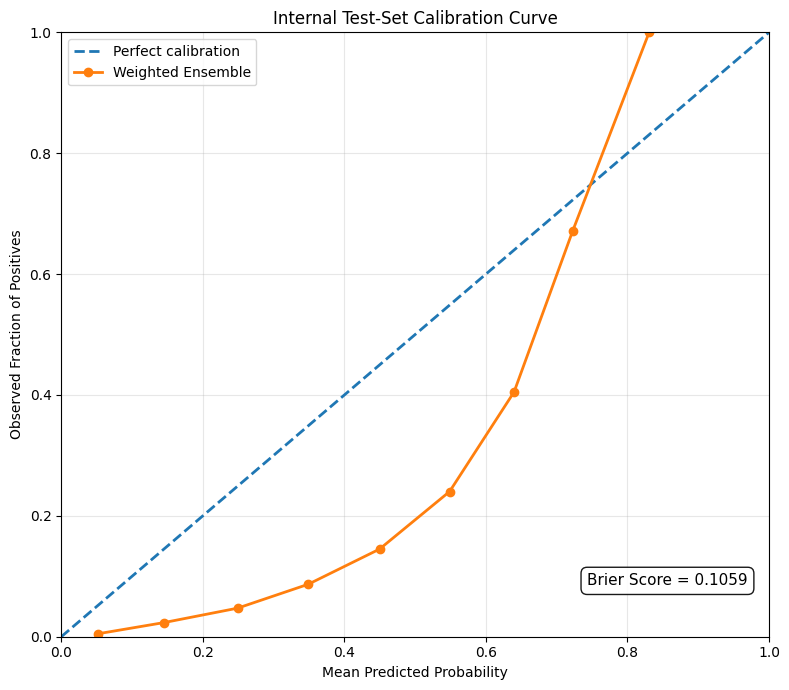


Saved:
/content/drive/MyDrive/CVD/models/ensemble/internal_calibration_curve.png
/content/drive/MyDrive/CVD/models/ensemble/internal_calibration_curve.pdf
/content/drive/MyDrive/CVD/models/ensemble/internal_calibration_curve.csv


In [30]:
# ============================================================
# INTERNAL TEST-SET CALIBRATION + BRIER SCORE
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

print("\n" + "=" * 75)
print("INTERNAL TEST-SET CALIBRATION")
print("=" * 75)

brier_internal = brier_score_loss(
    y_test,
    ens_proba_test
)

print(
    f"Internal Brier score: "
    f"{brier_internal:.6f}"
)

prob_true, prob_pred = calibration_curve(
    y_test,
    ens_proba_test,
    n_bins=10,
    strategy="uniform"
)

calibration_df = pd.DataFrame({
    "Mean_Predicted_Probability": prob_pred,
    "Observed_Fraction_Positive": prob_true
})

print("\nCalibration points:")
print(
    calibration_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

calibration_folder = os.path.join(
    MODELS_DIR,
    "ensemble"
)

calibration_csv = os.path.join(
    calibration_folder,
    "internal_calibration_curve.csv"
)

calibration_df.to_csv(
    calibration_csv,
    index=False
)

# ============================================================
# CALIBRATION FIGURE — PNG + PDF
# ============================================================

plt.figure(figsize=(8, 7))

# Perfect calibration
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=2,
    label="Perfect calibration"
)

# Weighted Ensemble
plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    linewidth=2,
    label="Weighted Ensemble"
)

# ------------------------------------------------------------
# BRIER SCORE BOX
# ------------------------------------------------------------

plt.text(
    0.97,
    0.08,
    f"Brier Score = {brier_internal:.4f}",
    transform=plt.gca().transAxes,
    ha="right",
    va="bottom",
    fontsize=11,
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="black",
        alpha=0.9
    )
)

# ------------------------------------------------------------
# Labels and formatting
# ------------------------------------------------------------

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Fraction of Positives")
plt.title("Internal Test-Set Calibration Curve")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend(loc="upper left")
plt.grid(alpha=0.3)

plt.tight_layout()

# ------------------------------------------------------------
# SAVE PNG
# ------------------------------------------------------------

calibration_png = os.path.join(
    calibration_folder,
    "internal_calibration_curve.png"
)

plt.savefig(
    calibration_png,
    dpi=300,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# SAVE PDF
# ------------------------------------------------------------

calibration_pdf = os.path.join(
    calibration_folder,
    "internal_calibration_curve.pdf"
)

plt.savefig(
    calibration_pdf,
    format="pdf",
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(calibration_png)
print(calibration_pdf)
print(calibration_csv)


      N  Mean_Pred  Observed
0  4452     0.0274    0.0020
1  4451     0.0444    0.0034
2  4451     0.0697    0.0065
3  4452     0.1097    0.0142
4  4451     0.1673    0.0303
5  4451     0.2443    0.0436
6  4452     0.3316    0.0779
7  4451     0.4250    0.1312
8  4451     0.5191    0.2085
9  4452     0.6250    0.3753
Saved: /content/drive/MyDrive/CVD/figures/figure_internal_calibration/figure_internal_calibration.pdf and .png


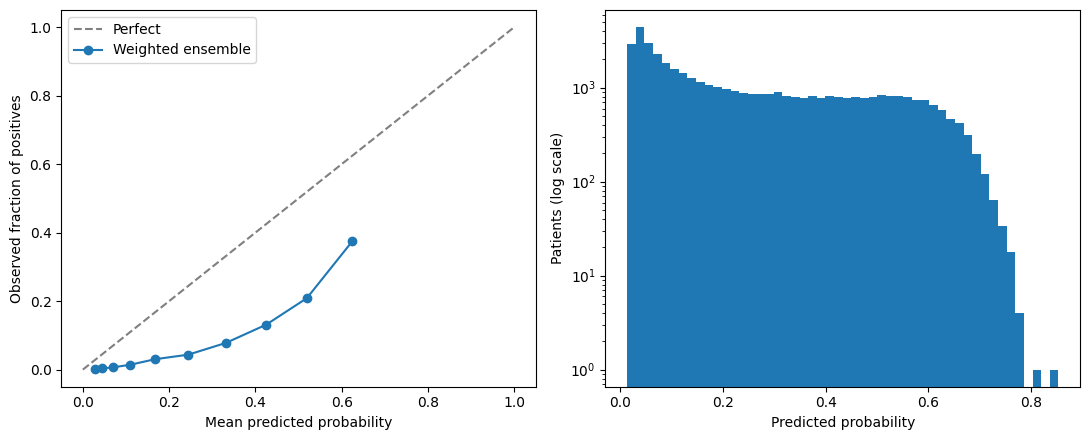

In [29]:
def calib_table(y, p, n=10):
    df = pd.DataFrame({'y': np.asarray(y), 'p': np.asarray(p)}); df['bin'] = pd.qcut(df['p'], n, duplicates='drop')
    t = df.groupby('bin', observed=True).agg(N=('y','size'), Mean_Pred=('p','mean'), Observed=('y','mean')).reset_index(drop=True)
    return t
p_te = ensemble_predict_proba(X_test, X_test_lgbm); tab = calib_table(y_test, p_te); print(tab.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].plot([0,1],[0,1],'--',c='gray',label='Perfect'); ax[0].plot(tab.Mean_Pred, tab.Observed,'o-',label='Weighted ensemble')
ax[0].set_xlabel('Mean predicted probability'); ax[0].set_ylabel('Observed fraction of positives'); ax[0].legend()
ax[1].hist(p_te, bins=50); ax[1].set_yscale('log'); ax[1].set_xlabel('Predicted probability'); ax[1].set_ylabel('Patients (log scale)')
plt.tight_layout(); save_figure(fig, 'figure_internal_calibration')

In [ ]:
# ============================================================
# Stacking Meta-Learner — Logistic Regression base models ki
# probabilities par fit hota hai (validation set par, koi leakage nahi
# kyunki X_val kisi bhi base model ki training mein use nahi hua)
# ============================================================
from sklearn.linear_model import LogisticRegression

def build_meta_features(X, X_lgbm=None):
    cols = [predict_proba_safe(model, name, X, X_lgbm) for name, model in base_models.items()]
    return np.column_stack(cols)

meta_X_val  = build_meta_features(X_val, X_val_lgbm)
meta_X_test = build_meta_features(X_test, X_test_lgbm)

meta_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
meta_model.fit(meta_X_val, y_val)
joblib.dump(meta_model, f'{MODELS_DIR}/ensemble/meta_model.pkl')

print("Meta-model coefficients (per base model):",
      dict(zip(base_models.keys(), meta_model.coef_[0])))

def stacked_predict_proba(X, X_lgbm=None):
    return meta_model.predict_proba(build_meta_features(X, X_lgbm))[:, 1]

Meta-model coefficients (per base model): {'random_forest': np.float64(0.39259111602264185), 'xgboost': np.float64(1.90832043084763), 'lightgbm': np.float64(0.7825883626751008), 'catboost': np.float64(3.9001775422078544)}


In [ ]:
# ============================================================
# Threshold optimization — STACKED ensemble ke liye (Youden's J + F1-constrained)
# ============================================================
stack_val_proba = stacked_predict_proba(X_val, X_val_lgbm)

# Youden's J
fpr_s, tpr_s, thresh_s = roc_curve(y_val, stack_val_proba)
stack_best_threshold = thresh_s[np.argmax(tpr_s - fpr_s)]

# F1-optimal, recall-constrained
prec_s, rec_s, thresh_s2 = precision_recall_curve(y_val, stack_val_proba)
prec_s, rec_s = prec_s[:-1], rec_s[:-1]
f1_s = 2 * prec_s * rec_s / (prec_s + rec_s + 1e-12)
valid_s = np.where(rec_s >= RECALL_FLOOR)[0]
f1_idx_s = valid_s[np.argmax(f1_s[valid_s])] if len(valid_s) else np.argmax(f1_s)
stack_f1_threshold = thresh_s2[f1_idx_s]

print(f"Stacked — Youden's J threshold: {stack_best_threshold:.4f}")
print(f"Stacked — F1-optimal threshold: {stack_f1_threshold:.4f}")

joblib.dump(stack_best_threshold, f'{MODELS_DIR}/ensemble/stack_best_threshold.pkl')
joblib.dump(stack_f1_threshold, f'{MODELS_DIR}/ensemble/stack_f1_threshold.pkl')

Stacked — Youden's J threshold: 0.4531
Stacked — F1-optimal threshold: 0.4881


['/content/drive/MyDrive/CVD/models/ensemble/stack_f1_threshold.pkl']

In [ ]:
# ============================================================
# FINAL comparison — weighted-avg vs stacked vs each base model
# ============================================================
stack_proba_test = stacked_predict_proba(X_test, X_test_lgbm)

final_results = []
final_results.append(evaluate_at(best_threshold, "Weighted Ensemble (Youden's J)"))
final_results.append(evaluate_at(f1_threshold, "Weighted Ensemble (F1-constrained)"))

def evaluate_stack_at(threshold, label):
    pred = (stack_proba_test >= threshold).astype(int)
    return {'Threshold_Strategy': label, 'Threshold': threshold,
            'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred),
            'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred),
            'ROC_AUC': roc_auc_score(y_test, stack_proba_test), 'PR_AUC': average_precision_score(y_test, stack_proba_test)}

final_results.append(evaluate_stack_at(stack_best_threshold, "Stacked Ensemble (Youden's J)"))
final_results.append(evaluate_stack_at(stack_f1_threshold, "Stacked Ensemble (F1-constrained)"))

# Har base model apne validation-optimal (F1-constrained) threshold par
for name, model in base_models.items():
    proba_v = predict_proba_safe(model, name, X_val, X_val_lgbm)
    p_v, r_v, t_v = precision_recall_curve(y_val, proba_v)
    p_v, r_v = p_v[:-1], r_v[:-1]
    f1_bv = 2*p_v*r_v/(p_v+r_v+1e-12)
    idx = np.where(r_v >= RECALL_FLOOR)[0]
    bt = t_v[idx[np.argmax(f1_bv[idx])]] if len(idx) else t_v[np.argmax(f1_bv)]

    proba_t = predict_proba_safe(model, name, X_test, X_test_lgbm)
    pred_t = (proba_t >= bt).astype(int)
    final_results.append({'Threshold_Strategy': f'{name} alone (F1-constrained)', 'Threshold': bt,
        'Accuracy': accuracy_score(y_test, pred_t), 'Precision': precision_score(y_test, pred_t),
        'Recall': recall_score(y_test, pred_t), 'F1': f1_score(y_test, pred_t),
        'ROC_AUC': roc_auc_score(y_test, proba_t), 'PR_AUC': average_precision_score(y_test, proba_t)})

final_table = pd.DataFrame(final_results)
final_folder = fig_folder('table_final_comparison')
final_table.to_csv(f'{final_folder}/table_final_comparison.csv', index=False)
print(final_table)

                     Threshold_Strategy  Threshold  Accuracy  Precision  \
0        Weighted Ensemble (Youden's J)   0.331638  0.712922   0.216658   
1    Weighted Ensemble (F1-constrained)   0.364586  0.741969   0.231769   
2         Stacked Ensemble (Youden's J)   0.453055  0.723593   0.221829   
3     Stacked Ensemble (F1-constrained)   0.488074  0.741497   0.231728   
4  random_forest alone (F1-constrained)   0.466209  0.738060   0.227695   
5        xgboost alone (F1-constrained)   0.009793  0.742238   0.231853   
6       lightgbm alone (F1-constrained)   0.502443  0.741924   0.231659   
7       catboost alone (F1-constrained)   0.500565  0.740823   0.231234   

     Recall        F1   ROC_AUC    PR_AUC  
0  0.846792  0.345036  0.851792  0.369912  
1  0.816352  0.361037  0.851792  0.369912  
2  0.835472  0.350575  0.851985  0.370144  
3  0.818365  0.361184  0.851985  0.370144  
4  0.808302  0.355302  0.846468  0.356635  
5  0.815597  0.361065  0.851655  0.368602  
6  0.815849  0.3

In [ ]:
# ============================================================
# Stacking v2 — SAB 8 trained models use karo (4 classweight + 4 ROS)
# zyada diversity → stacking ka behtar mauka
# ============================================================
all_models = {}
for name in ['random_forest','xgboost','lightgbm','catboost']:
    all_models[f'{name}_cw']  = base_models_cw[name]
    all_models[f'{name}_ros'] = base_models_ros[name]

def predict_proba_safe_v2(model, name, X, X_lgbm=None):
    if 'lightgbm' in name:
        return model.predict_proba(X_lgbm)[:, 1]
    return model.predict_proba(X)[:, 1]

def build_meta_features_v2(X, X_lgbm=None):
    cols = [predict_proba_safe_v2(model, name, X, X_lgbm) for name, model in all_models.items()]
    return np.column_stack(cols)

meta_X_val_v2  = build_meta_features_v2(X_val, X_val_lgbm)
meta_X_test_v2 = build_meta_features_v2(X_test, X_test_lgbm)

meta_model_v2 = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
meta_model_v2.fit(meta_X_val_v2, y_val)
print("Meta-model v2 coefficients (8 models):", dict(zip(all_models.keys(), meta_model_v2.coef_[0])))

def stacked_predict_proba_v2(X, X_lgbm=None):
    return meta_model_v2.predict_proba(build_meta_features_v2(X, X_lgbm))[:, 1]

# Threshold + evaluate (jaisa Step D/E mein kiya tha)
stack_v2_val_proba = stacked_predict_proba_v2(X_val, X_val_lgbm)
prec_v2, rec_v2, thresh_v2 = precision_recall_curve(y_val, stack_v2_val_proba)
prec_v2, rec_v2 = prec_v2[:-1], rec_v2[:-1]
f1_v2 = 2*prec_v2*rec_v2/(prec_v2+rec_v2+1e-12)
valid_v2 = np.where(rec_v2 >= RECALL_FLOOR)[0]
stack_v2_threshold = thresh_v2[valid_v2[np.argmax(f1_v2[valid_v2])]] if len(valid_v2) else thresh_v2[np.argmax(f1_v2)]

stack_v2_proba_test = stacked_predict_proba_v2(X_test, X_test_lgbm)
print(evaluate_at(stack_v2_threshold, "Stacked v2 (8 models, F1-constrained)", proba=stack_v2_proba_test))

Meta-model v2 coefficients (8 models): {'random_forest_cw': np.float64(0.44990466598598644), 'random_forest_ros': np.float64(0.07250230044085029), 'xgboost_cw': np.float64(1.6196787602630403), 'xgboost_ros': np.float64(-0.4053618932834291), 'lightgbm_cw': np.float64(1.250846632200206), 'lightgbm_ros': np.float64(-0.8328201377049407), 'catboost_cw': np.float64(3.3327431125405704), 'catboost_ros': np.float64(1.2484823184801563)}
{'Threshold_Strategy': 'Stacked v2 (8 models, F1-constrained)', 'Threshold': np.float64(0.48823183992391883), 'Accuracy': 0.7407107876173789, 'Precision': 0.2313045948441162, 'Recall': 0.8193710691823899, 'F1': 0.36076650420912715, 'ROC_AUC': np.float64(0.8519142914013542), 'PR_AUC': np.float64(0.369806847737201)}


In [ ]:
trade_off_rows = []
for floor in [0.90, 0.85, 0.80, 0.75, 0.70]:
    idx = np.where(rec_v >= floor)[0]  # weighted ensemble ka rec_v (Step B se)
    if len(idx) == 0: continue
    i = idx[np.argmax(f1_v[idx])]
    t = thresh_v[i]
    trade_off_rows.append(evaluate_at(t, f"Recall floor {floor}"))

trade_off_table = pd.DataFrame(trade_off_rows)
print(trade_off_table)

  Threshold_Strategy  Threshold  Accuracy  Precision    Recall        F1  \
0   Recall floor 0.9   0.255338  0.636249   0.185696  0.907925  0.308330   
1  Recall floor 0.85   0.319986  0.701599   0.210932  0.854340  0.338331   
2   Recall floor 0.8   0.364586  0.741969   0.231769  0.816352  0.361037   
3  Recall floor 0.75   0.403147  0.774206   0.250452  0.767044  0.377609   
4   Recall floor 0.7   0.434748  0.799996   0.268769  0.720503  0.391498   

    ROC_AUC    PR_AUC  
0  0.851792  0.369912  
1  0.851792  0.369912  
2  0.851792  0.369912  
3  0.851792  0.369912  
4  0.851792  0.369912  


In [31]:
# ============================================================
# FINAL PROPOSED MODEL — Weighted Ensemble, F1-constrained threshold
# ============================================================
final_proba_test = ens_proba_test              # already computed
final_threshold  = f1_threshold                 # 0.364586
final_pred_test  = (final_proba_test >= final_threshold).astype(int)

joblib.dump(final_threshold, f'{MODELS_DIR}/ensemble/final_threshold.pkl')
print(f"Final proposed threshold: {final_threshold:.4f}")

# Har base model ki test-set probability bhi chahiye (ROC comparison ke liye)
base_proba_test = {name: predict_proba_safe(model, name, X_test, X_test_lgbm)
                    for name, model in base_models.items()}

Final proposed threshold: 0.3646


Saved: /content/drive/MyDrive/CVD/figures/figure10_roc_curve_comparison/figure10_roc_curve_comparison.pdf and .png


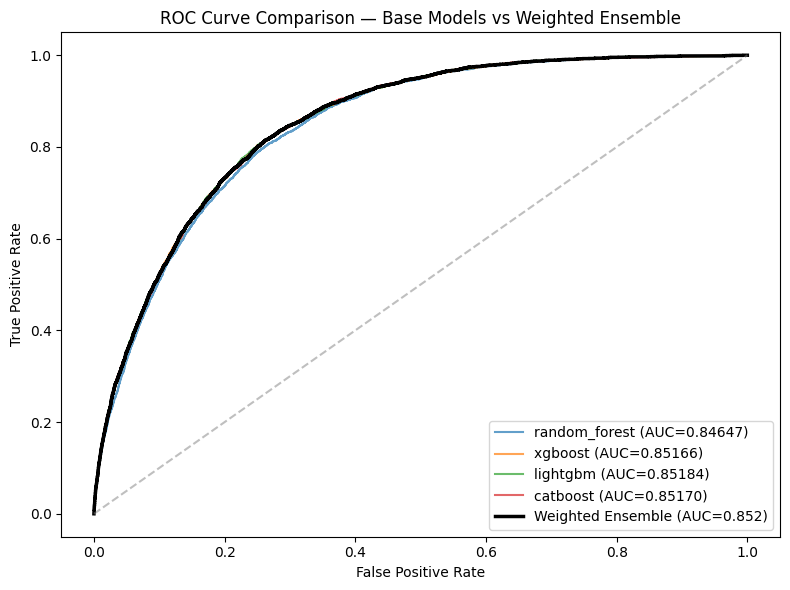

In [ ]:
from sklearn.metrics import roc_curve

fig10, ax10 = plt.subplots(figsize=(8,6))
for name, proba in base_proba_test.items():
    fpr_b, tpr_b, _ = roc_curve(y_test, proba)
    auc_b = roc_auc_score(y_test, proba)
    ax10.plot(fpr_b, tpr_b, label=f'{name} (AUC={auc_b:.5f})', alpha=0.7)

fpr_e, tpr_e, _ = roc_curve(y_test, final_proba_test)
auc_e = roc_auc_score(y_test, final_proba_test)
ax10.plot(fpr_e, tpr_e, label=f'Weighted Ensemble (AUC={auc_e:.3f})', linewidth=2.5, color='black')
ax10.plot([0,1],[0,1], linestyle='--', color='gray', alpha=0.5)
ax10.set_xlabel('False Positive Rate'); ax10.set_ylabel('True Positive Rate')
ax10.set_title('ROC Curve Comparison — Base Models vs Weighted Ensemble')
ax10.legend()
plt.tight_layout()
save_figure(fig10, 'figure10_roc_curve_comparison')
plt.show()

Saved: /content/drive/MyDrive/CVD/figures/figure11_confusion_matrix_final/figure11_confusion_matrix_final.pdf and .png


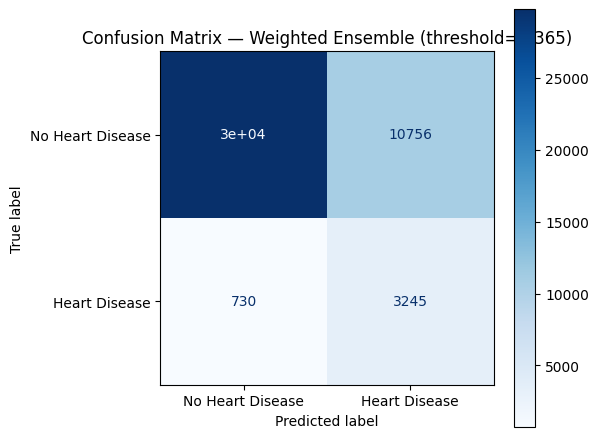

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

fig11, ax11 = plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(
    y_test, final_pred_test,
    display_labels=['No Heart Disease','Heart Disease'],
    cmap='Blues', ax=ax11
)
ax11.set_title(f'Confusion Matrix — Weighted Ensemble (threshold={final_threshold:.3f})')
plt.tight_layout()
save_figure(fig11, 'figure11_confusion_matrix_final')
plt.show()

Saved: /content/drive/MyDrive/CVD/figures/figure12_performance_comparison/figure12_performance_comparison.pdf and .png


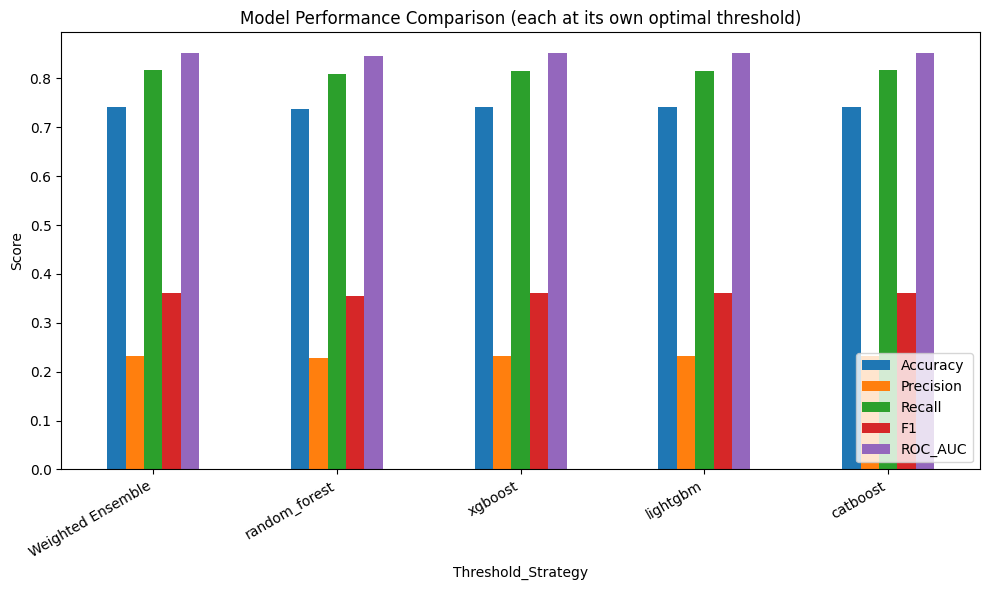

                    Threshold  Accuracy  Precision    Recall        F1  \
Threshold_Strategy                                                       
Weighted Ensemble    0.364586  0.741969   0.231769  0.816352  0.361037   
random_forest        0.466209  0.738060   0.227695  0.808302  0.355302   
xgboost              0.009793  0.742238   0.231853  0.815597  0.361065   
lightgbm             0.502443  0.741924   0.231659  0.815849  0.360855   
catboost             0.500565  0.740823   0.231234  0.818365  0.360583   

                     ROC_AUC    PR_AUC  
Threshold_Strategy                      
Weighted Ensemble   0.851792  0.369912  
random_forest       0.846468  0.356635  
xgboost             0.851655  0.368602  
lightgbm            0.851842  0.368382  
catboost            0.851698  0.368662  


In [32]:
compare_rows = [evaluate_at(final_threshold, "Weighted Ensemble", proba=final_proba_test)]

for name, model in base_models.items():
    proba_v = predict_proba_safe(model, name, X_val, X_val_lgbm)
    p_v, r_v, t_v = precision_recall_curve(y_val, proba_v)
    p_v, r_v = p_v[:-1], r_v[:-1]
    f1_bv = 2*p_v*r_v/(p_v+r_v+1e-12)
    idx = np.where(r_v >= RECALL_FLOOR)[0]
    bt = t_v[idx[np.argmax(f1_bv[idx])]] if len(idx) else t_v[np.argmax(f1_bv)]
    compare_rows.append(evaluate_at(bt, name, proba=base_proba_test[name]))

compare_table = pd.DataFrame(compare_rows).set_index('Threshold_Strategy')

fig12, ax12 = plt.subplots(figsize=(10,6))
compare_table[['Accuracy','Precision','Recall','F1','ROC_AUC']].plot(kind='bar', ax=ax12)
ax12.set_title('Model Performance Comparison (each at its own optimal threshold)')
ax12.set_ylabel('Score')
ax12.legend(loc='lower right')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
save_figure(fig12, 'figure12_performance_comparison')
plt.show()

t9_folder = fig_folder('table9_individual_vs_ensemble')
compare_table.to_csv(f'{t9_folder}/table9_individual_vs_ensemble.csv')
print(compare_table)

In [ ]:
from sklearn.metrics import classification_report

print("=" * 70)
print("PER-CLASS CLASSIFICATION REPORT — FINAL WEIGHTED ENSEMBLE")
print("=" * 70)

print(classification_report(
    y_test,
    final_pred_test,
    target_names=['No Heart Disease', 'Heart Disease'],
    digits=4
))

PER-CLASS CLASSIFICATION REPORT — FINAL WEIGHTED ENSEMBLE
                  precision    recall  f1-score   support

No Heart Disease     0.9761    0.7347    0.8383     40539
   Heart Disease     0.2318    0.8164    0.3610      3975

        accuracy                         0.7420     44514
       macro avg     0.6039    0.7755    0.5997     44514
    weighted avg     0.9096    0.7420    0.7957     44514



Saved: /content/drive/MyDrive/CVD/figures/figure11_precision_recall_curve_comparison/figure11_precision_recall_curve_comparison.pdf and .png


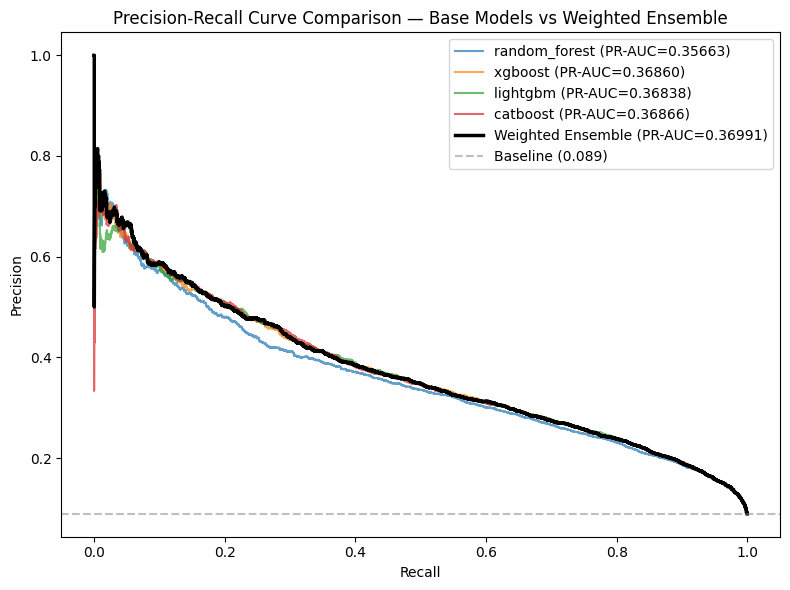

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

fig11, ax11 = plt.subplots(figsize=(8,6))

# Base Models
for name, proba in base_proba_test.items():

    precision_b, recall_b, _ = precision_recall_curve(y_test, proba)

    pr_auc_b = average_precision_score(y_test, proba)

    ax11.plot(
        recall_b,
        precision_b,
        label=f'{name} (PR-AUC={pr_auc_b:.5f})',
        alpha=0.7
    )

# Weighted Ensemble
precision_e, recall_e, _ = precision_recall_curve(
    y_test,
    final_proba_test
)

pr_auc_e = average_precision_score(
    y_test,
    final_proba_test
)

ax11.plot(
    recall_e,
    precision_e,
    label=f'Weighted Ensemble (PR-AUC={pr_auc_e:.5f})',
    linewidth=2.5,
    color='black'
)

# Baseline = prevalence of positive class
baseline = y_test.mean()

ax11.axhline(
    y=baseline,
    linestyle='--',
    color='gray',
    alpha=0.5,
    label=f'Baseline ({baseline:.3f})'
)

ax11.set_xlabel('Recall')
ax11.set_ylabel('Precision')

ax11.set_title(
    'Precision-Recall Curve Comparison — Base Models vs Weighted Ensemble'
)

ax11.legend()

plt.tight_layout()

save_figure(
    fig11,
    'figure11_precision_recall_curve_comparison'
)

plt.show()

In [33]:
# ============================================================
# FINAL MODEL — Single Source of Truth
# ============================================================

FINAL_THRESHOLD_STRATEGY = "F1-constrained (Recall >= 0.80)"
FINAL_THRESHOLD = f1_threshold

final_proba_test = ensemble_predict_proba(X_test, X_test_lgbm)
final_pred_test = (final_proba_test >= FINAL_THRESHOLD).astype(int)

print("FINAL MODEL: PR-AUC weighted ensemble")
print("FINAL weights:", ensemble_weights)
print("Primary Youden threshold:", best_threshold)
print("Supplementary F1-constrained threshold:", f1_threshold)
print("FINAL threshold used:", FINAL_THRESHOLD)

FINAL MODEL: PR-AUC weighted ensemble
FINAL weights: {'random_forest': np.float64(0.21232062304580207), 'xgboost': np.float64(0.2663098920982783), 'lightgbm': np.float64(0.2548131058368417), 'catboost': np.float64(0.2665563790190779)}
Primary Youden threshold: 0.3316376663571651
Supplementary F1-constrained threshold: 0.36458617702918966
FINAL threshold used: 0.36458617702918966


 Threshold  Precision   Recall       F1    FP   FN
      0.30   0.198940 0.868428 0.323721 13900  523
      0.31   0.203574 0.862642 0.329411 13415  546
      0.32   0.207923 0.855597 0.334547 12956  574
      0.33   0.212460 0.846792 0.339691 12477  609
      0.34   0.217269 0.837484 0.345028 11993  646
      0.35   0.220031 0.822390 0.347175 11588  706
      0.36   0.224781 0.812830 0.352172 11143  744
      0.37   0.229282 0.802516 0.356664 10723  785
      0.38   0.233073 0.788931 0.359839 10319  839
      0.39   0.237959 0.776855 0.364323  9889  887
      0.40   0.243516 0.765283 0.369466  9450  933
      0.41   0.248168 0.749937 0.372928  9031  994
      0.42   0.254140 0.737358 0.377998  8602 1044
      0.43   0.259561 0.722264 0.381883  8190 1104
      0.44   0.264936 0.706164 0.385312  7788 1168
      0.45   0.269125 0.688553 0.386992  7433 1238
      0.46   0.275277 0.673962 0.390895  7053 1296
      0.47   0.281530 0.655346 0.393862  6648 1370
      0.48   0.288413 0.637484 

Thresholds with Recall >= 0.80:
 Threshold  Precision   Recall       F1    FP  FN
      0.37   0.229282 0.802516 0.356664 10723 785
      0.36   0.224781 0.812830 0.352172 11143 744
      0.35   0.220031 0.822390 0.347175 11588 706
      0.34   0.217269 0.837484 0.345028 11993 646
      0.33   0.212460 0.846792 0.339691 12477 609
      0.32   0.207923 0.855597 0.334547 12956 574
      0.31   0.203574 0.862642 0.329411 13415 546
      0.30   0.198940 0.868428 0.323721 13900 523


Per-model optimal thresholds: {'random_forest': np.float64(0.4542710218018506), 'xgboost': np.float32(0.009582936), 'lightgbm': np.float64(0.5084383088226246), 'catboost': np.float64(0.49119162878327577), 'Weighted_Ensemble': np.float64(0.3391900766480523)}
                   Accuracy  Precision    Recall        F1   ROC_AUC    PR_AUC
random_forest      0.727142   0.221487  0.817358  0.348530  0.846468  0.356635
xgboost            0.738779   0.230015  0.820126  0.359268  0.851655  0.368602
lightgbm           0.745945   0.234006  0.811572  0.363268  0.851842  0.368382
catboost           0.735387   0.228084  0.823396  0.357217  0.851698  0.368662
Weighted_Ensemble  0.713686   0.217170  0.847044  0.345706  0.851661  0.369478
Saved: /content/drive/MyDrive/CVD/figures/figure10_roc_curve_comparison/figure10_roc_curve_comparison.pdf and .png
Saved: /content/drive/MyDrive/CVD/figures/figure11_confusion_matrix/figure11_confusion_matrix.pdf and .png
Saved: /content/drive/MyDrive/CVD/figures/figu

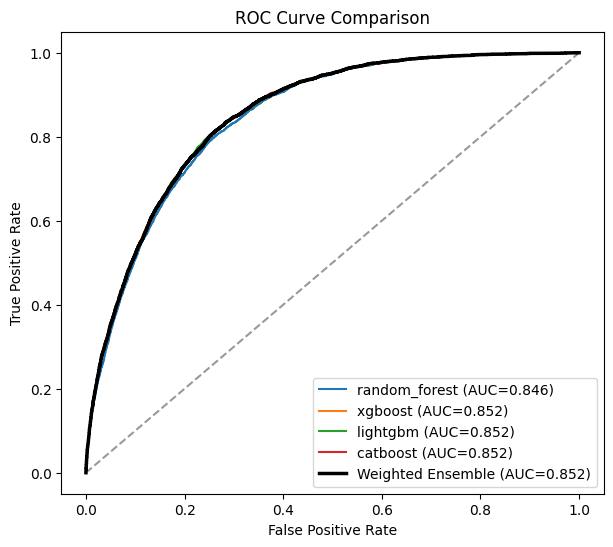

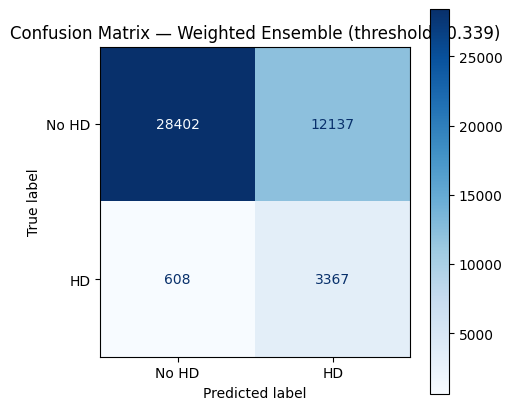

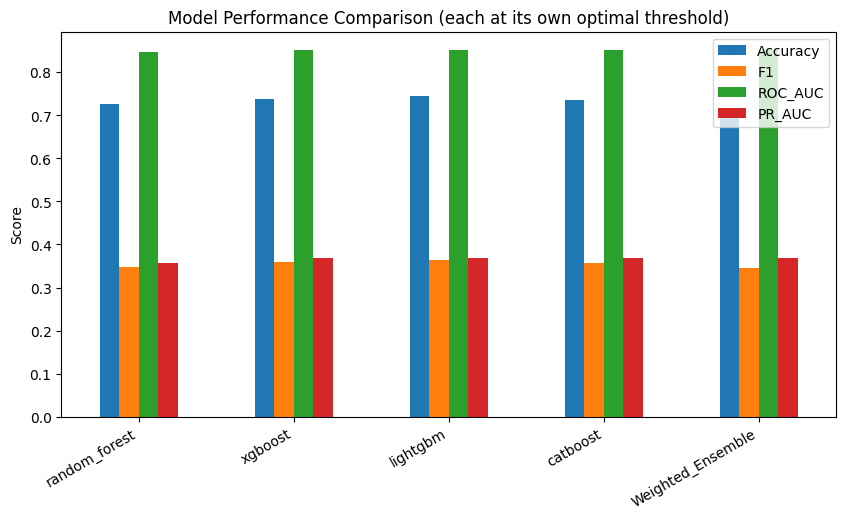

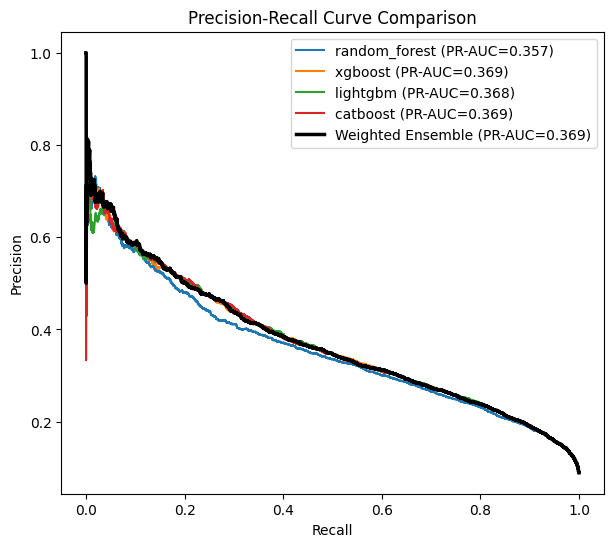

In [ ]:
# noooooooooooooooStep 1: Find each base model's own optimal threshold on VALIDATION set
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve)

base_thresholds = {}
for name, model in base_models.items():
    val_proba = predict_proba_safe(model, name, X_val, X_val_lgbm)
    fpr_v, tpr_v, thresh_v = roc_curve(y_val, val_proba)
    base_thresholds[name] = thresh_v[np.argmax(tpr_v - fpr_v)]

base_thresholds['Weighted_Ensemble'] = best_threshold  # already computed
print("Per-model optimal thresholds:", base_thresholds)
joblib.dump(base_thresholds, f'{MODELS_DIR}/ensemble/all_thresholds.pkl')

# Step 2: Re-evaluate everyone at THEIR OWN optimal threshold
results = {}
proba_dict = {}

for name, model in base_models.items():
    proba = predict_proba_safe(model, name, X_test, X_test_lgbm)
    proba_dict[name] = proba
    pred = (proba >= base_thresholds[name]).astype(int)
    results[name] = {
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC_AUC': roc_auc_score(y_test, proba),
        'PR_AUC': average_precision_score(y_test, proba)
    }

ens_proba_test = ensemble_predict_proba(X_test, X_test_lgbm)
proba_dict['Weighted_Ensemble'] = ens_proba_test
ens_pred = (ens_proba_test >= best_threshold).astype(int)
results['Weighted_Ensemble'] = {
    'Accuracy': accuracy_score(y_test, ens_pred),
    'Precision': precision_score(y_test, ens_pred),
    'Recall': recall_score(y_test, ens_pred),
    'F1': f1_score(y_test, ens_pred),
    'ROC_AUC': roc_auc_score(y_test, ens_proba_test),
    'PR_AUC': average_precision_score(y_test, ens_proba_test)
}

table8 = pd.DataFrame(results).T
table8_folder = fig_folder('table8_classification_performance')
table8.to_csv(f'{table8_folder}/table8_classification_performance.csv')
print(table8)

table9_folder = fig_folder('table9_individual_vs_ensemble')
table8.to_csv(f'{table9_folder}/table9_individual_vs_ensemble.csv')

# --- Figure 10: ROC Curve (unaffected by threshold, same as before) ---
fig10, ax10 = plt.subplots(figsize=(7,6))
for name in base_models:
    fpr_, tpr_, _ = roc_curve(y_test, proba_dict[name])
    ax10.plot(fpr_, tpr_, label=f'{name} (AUC={results[name]["ROC_AUC"]:.3f})')
fpr_e, tpr_e, _ = roc_curve(y_test, ens_proba_test)
ax10.plot(fpr_e, tpr_e, label=f'Weighted Ensemble (AUC={results["Weighted_Ensemble"]["ROC_AUC"]:.3f})', linewidth=2.5, color='black')
ax10.plot([0,1],[0,1],'k--', alpha=0.4)
ax10.set_xlabel('False Positive Rate'); ax10.set_ylabel('True Positive Rate')
ax10.set_title('ROC Curve Comparison'); ax10.legend()
save_figure(fig10, 'figure10_roc_curve_comparison')

# --- Figure 11: Confusion Matrix (Ensemble) ---
fig11, ax11 = plt.subplots(figsize=(5,5))
cm = confusion_matrix(y_test, ens_pred)
ConfusionMatrixDisplay(cm, display_labels=['No HD','HD']).plot(ax=ax11, cmap='Blues')
ax11.set_title(f'Confusion Matrix — Weighted Ensemble (threshold={best_threshold:.3f})')
save_figure(fig11, 'figure11_confusion_matrix')

# --- Figure 12: Performance comparison ---
fig12, ax12 = plt.subplots(figsize=(10,5))
table8[['Accuracy','F1','ROC_AUC','PR_AUC']].plot(kind='bar', ax=ax12)
ax12.set_title('Model Performance Comparison (each at its own optimal threshold)')
ax12.set_ylabel('Score')
plt.xticks(rotation=30, ha='right')
save_figure(fig12, 'figure12_model_performance_comparison')

# --- PR Curve (unaffected by threshold) ---
fig_pr, ax_pr = plt.subplots(figsize=(7,6))
for name in base_models:
    prec_, rec_, _ = precision_recall_curve(y_test, proba_dict[name])
    ax_pr.plot(rec_, prec_, label=f'{name} (PR-AUC={results[name]["PR_AUC"]:.3f})')
prec_e, rec_e, _ = precision_recall_curve(y_test, ens_proba_test)
ax_pr.plot(rec_e, prec_e, label=f'Weighted Ensemble (PR-AUC={results["Weighted_Ensemble"]["PR_AUC"]:.3f})', linewidth=2.5, color='black')
ax_pr.set_xlabel('Recall'); ax_pr.set_ylabel('Precision')
ax_pr.set_title('Precision-Recall Curve Comparison'); ax_pr.legend()
save_figure(fig_pr, 'figure_pr_curve_comparison')

plt.show()

                   Accuracy  Precision    Recall        F1   ROC_AUC    PR_AUC
random_forest      0.762322   0.240838  0.772075  0.367149  0.846468  0.356635
xgboost            0.910725   1.000000  0.000252  0.000503  0.851655  0.368602
lightgbm           0.740284   0.230611  0.816855  0.359679  0.851842  0.368382
catboost           0.740509   0.231042  0.818616  0.360374  0.851698  0.368662
Weighted_Ensemble  0.713686   0.217170  0.847044  0.345706  0.851661  0.369478
Saved: /content/drive/MyDrive/CVD/figures/figure10_roc_curve_comparison/figure10_roc_curve_comparison.pdf and .png
Saved: /content/drive/MyDrive/CVD/figures/figure11_confusion_matrix/figure11_confusion_matrix.pdf and .png
Saved: /content/drive/MyDrive/CVD/figures/figure12_model_performance_comparison/figure12_model_performance_comparison.pdf and .png
Saved: /content/drive/MyDrive/CVD/figures/figure_pr_curve_comparison/figure_pr_curve_comparison.pdf and .png


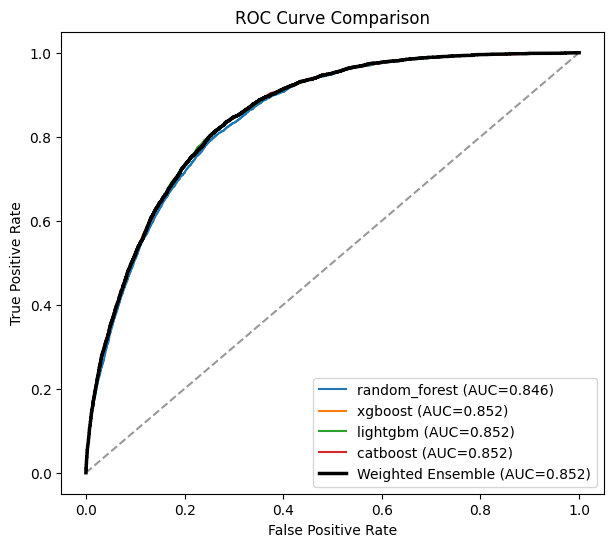

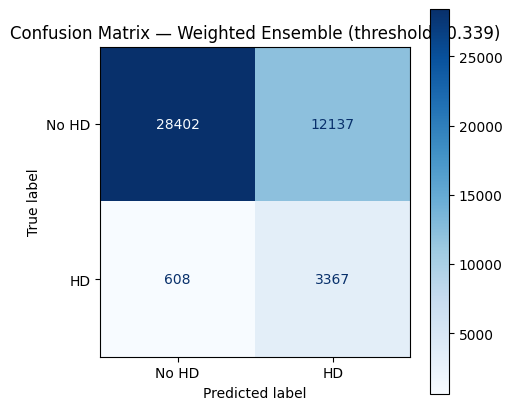

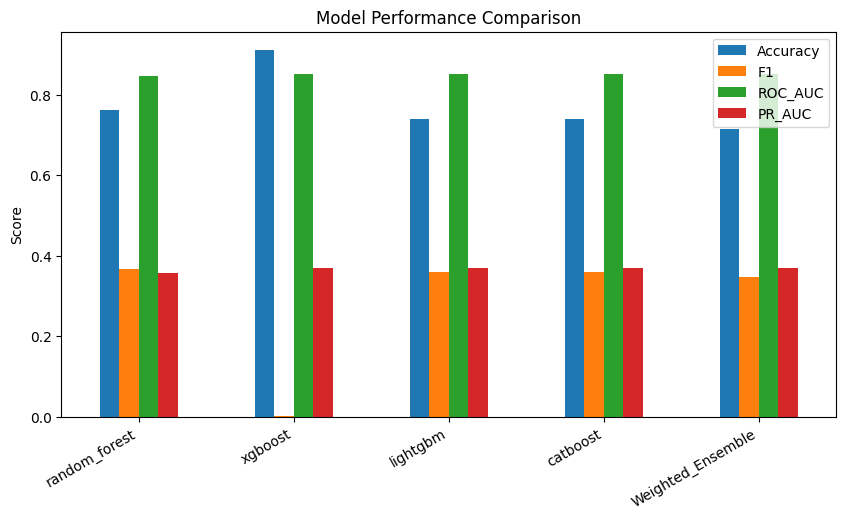

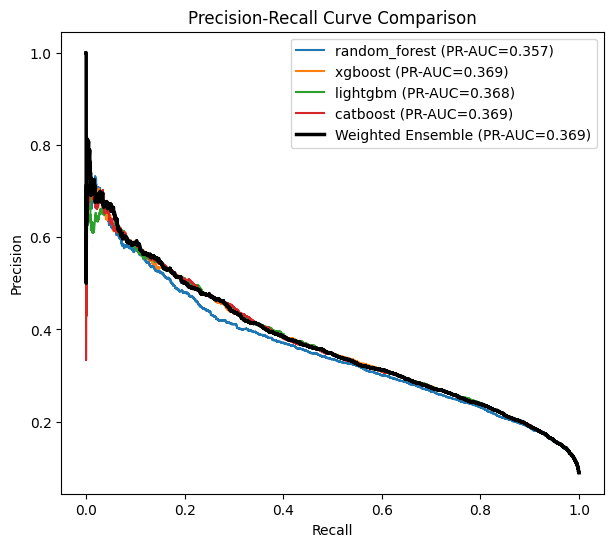

In [ ]:
#skip now
#Table 8, Figures 10–12: Full Evaluation
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve)

X_test_map = {'random_forest': X_test, 'xgboost': X_test, 'catboost': X_test, 'lightgbm': X_test_lgbm}

results = {}
proba_dict = {}  # store each model's test-set probabilities for later use (ROC curve, DeLong, etc.)

for name, model in base_models.items():
    proba = predict_proba_safe(model, name, X_test, X_test_lgbm)
    proba_dict[name] = proba
    pred = (proba >= 0.5).astype(int)   # base models evaluated at default 0.5
    results[name] = {
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC_AUC': roc_auc_score(y_test, proba),
        'PR_AUC': average_precision_score(y_test, proba)
    }

# Ensemble — evaluated at the OPTIMIZED threshold (0.3392), not 0.5
ens_proba_test = ensemble_predict_proba(X_test, X_test_lgbm)
proba_dict['Weighted_Ensemble'] = ens_proba_test
ens_pred = (ens_proba_test >= best_threshold).astype(int)
results['Weighted_Ensemble'] = {
    'Accuracy': accuracy_score(y_test, ens_pred),
    'Precision': precision_score(y_test, ens_pred),
    'Recall': recall_score(y_test, ens_pred),
    'F1': f1_score(y_test, ens_pred),
    'ROC_AUC': roc_auc_score(y_test, ens_proba_test),
    'PR_AUC': average_precision_score(y_test, ens_proba_test)
}

table8 = pd.DataFrame(results).T
table8_folder = fig_folder('table8_classification_performance')
table8.to_csv(f'{table8_folder}/table8_classification_performance.csv')
print(table8)

table9_folder = fig_folder('table9_individual_vs_ensemble')
table8.to_csv(f'{table9_folder}/table9_individual_vs_ensemble.csv')

# --- Figure 10: ROC Curve Comparison ---
fig10, ax10 = plt.subplots(figsize=(7,6))
for name in base_models:
    fpr_, tpr_, _ = roc_curve(y_test, proba_dict[name])
    ax10.plot(fpr_, tpr_, label=f'{name} (AUC={results[name]["ROC_AUC"]:.3f})')
fpr_e, tpr_e, _ = roc_curve(y_test, ens_proba_test)
ax10.plot(fpr_e, tpr_e, label=f'Weighted Ensemble (AUC={results["Weighted_Ensemble"]["ROC_AUC"]:.3f})', linewidth=2.5, color='black')
ax10.plot([0,1],[0,1],'k--', alpha=0.4)
ax10.set_xlabel('False Positive Rate'); ax10.set_ylabel('True Positive Rate')
ax10.set_title('ROC Curve Comparison'); ax10.legend()
save_figure(fig10, 'figure10_roc_curve_comparison')

# --- Figure 11: Confusion Matrix (Ensemble, at optimized threshold) ---
fig11, ax11 = plt.subplots(figsize=(5,5))
cm = confusion_matrix(y_test, ens_pred)
ConfusionMatrixDisplay(cm, display_labels=['No HD','HD']).plot(ax=ax11, cmap='Blues')
ax11.set_title(f'Confusion Matrix — Weighted Ensemble (threshold={best_threshold:.3f})')
save_figure(fig11, 'figure11_confusion_matrix')

# --- Figure 12: Model Performance Comparison bar chart ---
fig12, ax12 = plt.subplots(figsize=(10,5))
table8[['Accuracy','F1','ROC_AUC','PR_AUC']].plot(kind='bar', ax=ax12)
ax12.set_title('Model Performance Comparison'); ax12.set_ylabel('Score')
plt.xticks(rotation=30, ha='right')
save_figure(fig12, 'figure12_model_performance_comparison')

# --- Bonus: PR Curve (you have PR-AUC in the table, this adds the visual) ---
fig_pr, ax_pr = plt.subplots(figsize=(7,6))
for name in base_models:
    prec_, rec_, _ = precision_recall_curve(y_test, proba_dict[name])
    ax_pr.plot(rec_, prec_, label=f'{name} (PR-AUC={results[name]["PR_AUC"]:.3f})')
prec_e, rec_e, _ = precision_recall_curve(y_test, ens_proba_test)
ax_pr.plot(rec_e, prec_e, label=f'Weighted Ensemble (PR-AUC={results["Weighted_Ensemble"]["PR_AUC"]:.3f})', linewidth=2.5, color='black')
ax_pr.set_xlabel('Recall'); ax_pr.set_ylabel('Precision')
ax_pr.set_title('Precision-Recall Curve Comparison'); ax_pr.legend()
save_figure(fig_pr, 'figure_pr_curve_comparison')

plt.show()

Saved: /content/drive/MyDrive/CVD/figures/figure17_computational_performance/figure17_computational_performance.pdf and .png


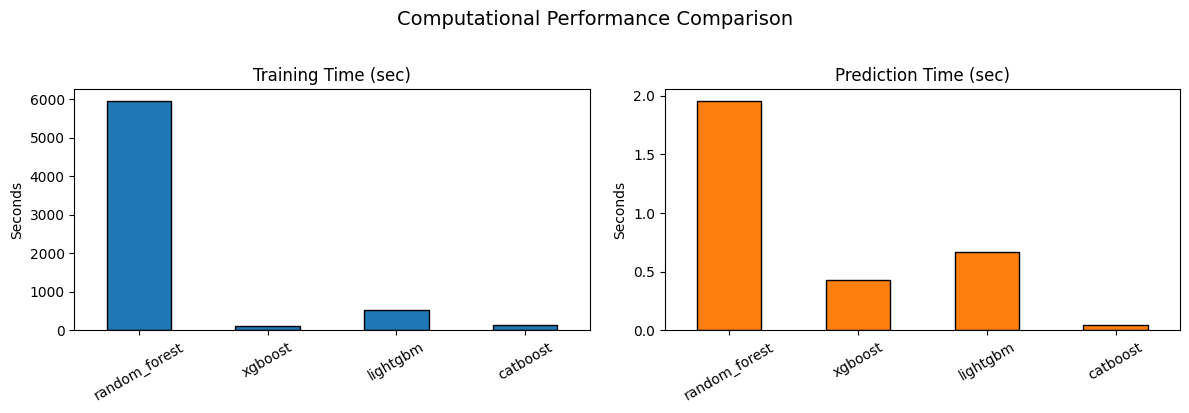

               Training_Time_sec  Prediction_Time_sec
random_forest        5961.096185             1.328664
xgboost               119.572388             0.277390
lightgbm              518.425912             0.501159
catboost              154.599565             0.054720
Saved: /content/drive/MyDrive/CVD/figures/figure17_computational_performance/figure17_computational_performance.pdf and .png


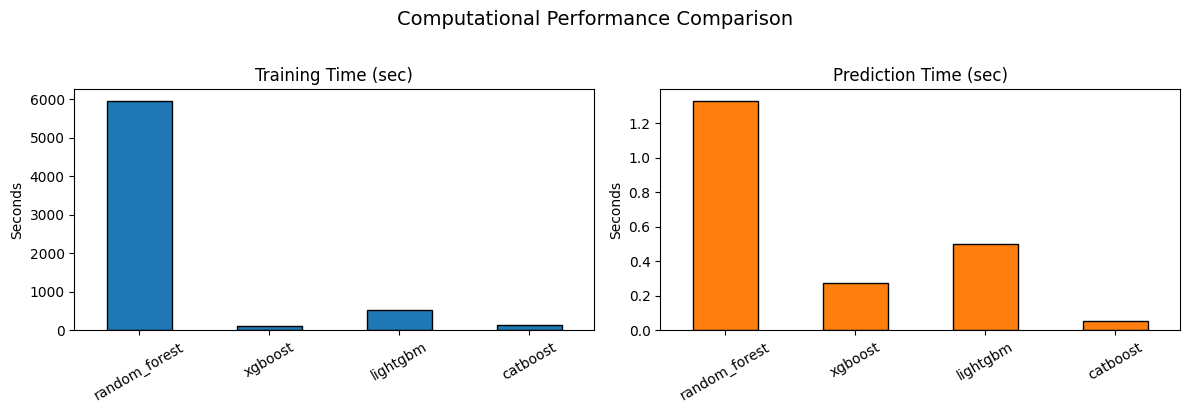

In [34]:
#do

#Table 12 + Figure 17 (Computational Efficiency)
import time

comp_results = {}
for name, model in base_models.items():
    t0 = time.time()
    _ = predict_proba_safe(model, name, X_test, X_test_lgbm)
    pred_time = time.time() - t0
    comp_results[name] = {
        'Training_Time_sec': training_config[name]['training_time_sec'],
        'Prediction_Time_sec': pred_time
    }

table12 = pd.DataFrame(comp_results).T
table12_folder = fig_folder('table12_computational_efficiency')
table12.to_csv(f'{table12_folder}/table12_computational_efficiency.csv')
print(table12)

#fig17, ax17 = plt.subplots(figsize=(8,5))
#table12.plot(kind='bar', ax=ax17)
#ax17.set_title('Computational Performance Comparison'); ax17.set_ylabel('Seconds')
#plt.xticks(rotation=30, ha='right')
#save_figure(fig17, 'figure17_computational_performance')
#plt.show()

fig17, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Training Time Plot
table12['Training_Time_sec'].plot(
    kind='bar', ax=ax1, color='#1f77b4', edgecolor='black'
)
ax1.set_title('Training Time (sec)')
ax1.set_ylabel('Seconds')
ax1.tick_params(axis='x', rotation=30)

# Prediction Time Plot
table12['Prediction_Time_sec'].plot(
    kind='bar', ax=ax2, color='#ff7f0e', edgecolor='black'
)
ax2.set_title('Prediction Time (sec)')
ax2.set_ylabel('Seconds')
ax2.tick_params(axis='x', rotation=30)

plt.suptitle('Computational Performance Comparison', fontsize=14, y=1.02)
plt.tight_layout()

save_figure(fig17, 'figure17_computational_performance')
plt.show()

In [ ]:
#...no SHAP: Global + Local + Force Plot
import shap

shap_ckpt = f'{RESULTS_DIR}/ensemble/ensemble_shap_values.pkl'
base_val_ckpt = f'{RESULTS_DIR}/ensemble/ensemble_shap_base.pkl'
X_test_map = {'random_forest': X_test, 'xgboost': X_test, 'catboost': X_test, 'lightgbm': X_test_lgbm}

if os.path.exists(shap_ckpt):
    sv = joblib.load(shap_ckpt)
    base_values_combined = joblib.load(base_val_ckpt)
else:
    per_model_shap, per_model_base = {}, {}
    for name, model in base_models.items():
        explainer = shap.TreeExplainer(model)
        s = explainer.shap_values(X_test_map[name])
        s = s[1] if isinstance(s, list) else s
        bv = explainer.expected_value
        bv = bv[1] if isinstance(bv, (list, np.ndarray)) else bv
        per_model_shap[name] = s
        per_model_base[name] = bv
        print(f"[{name}] SHAP computed.")

    sv = np.zeros_like(per_model_shap['random_forest'])
    base_values_combined = 0
    for name in base_models:
        sv += ensemble_weights[name] * per_model_shap[name]
        base_values_combined += ensemble_weights[name] * per_model_base[name]

    joblib.dump(sv, shap_ckpt)
    joblib.dump(base_values_combined, base_val_ckpt)
    print("Ensemble-level SHAP values saved.")

# Table 10: Global SHAP Feature Importance
importance = pd.DataFrame({'feature': X_test.columns, 'mean_abs_shap': np.abs(sv).mean(axis=0)})
importance = importance.sort_values('mean_abs_shap', ascending=False)
t10_folder = fig_folder('table10_global_shap_importance')
importance.to_csv(f'{t10_folder}/table10_global_shap_importance.csv', index=False)
print(importance.head(10))

t11_folder = fig_folder('table11_risk_factor_importance')
importance.head(10).to_csv(f'{t11_folder}/table11_risk_factor_importance.csv', index=False)

# Figure 13: SHAP Global Summary Plot
fig13 = plt.figure()
shap.summary_plot(sv, X_test, show=False)
save_figure(fig13, 'figure13_shap_summary_plot')

# Figure 14: SHAP Waterfall (Local, one patient)
fig14 = plt.figure()
shap.plots.waterfall(shap.Explanation(values=sv[0], base_values=base_values_combined, data=X_test.iloc[0]), show=False)
save_figure(fig14, 'figure14_shap_waterfall_patient')

# Figure 14b: SHAP FORCE PLOT (Local, same patient) — MISSING BEFORE, NOW ADDED
shap.initjs()
force_fig = shap.force_plot(base_values_combined, sv[0], X_test.iloc[0], matplotlib=True, show=False)
force_folder = fig_folder('figure14b_shap_force_plot')
force_fig.savefig(f'{force_folder}/figure14b_shap_force_plot.pdf', dpi=300, bbox_inches='tight')
force_fig.savefig(f'{force_folder}/figure14b_shap_force_plot.png', dpi=300, bbox_inches='tight')
print(f"Saved: {force_folder}/figure14b_shap_force_plot.pdf and .png")
plt.show()

# Figure 15: SHAP Dependence Plot (top feature)
top_feature = importance.iloc[0]['feature']
fig15, ax15 = plt.subplots()
shap.dependence_plot(top_feature, sv, X_test, ax=ax15, show=False)
save_figure(fig15, 'figure15_shap_dependence_plot')

# Figure 16: Risk Factor Distribution
fig16, ax16 = plt.subplots(figsize=(8,6))
importance.head(10).plot(kind='barh', x='feature', y='mean_abs_shap', ax=ax16, legend=False)
ax16.invert_yaxis(); ax16.set_title('Top 10 Risk Factor Distribution (SHAP Importance)')
save_figure(fig16, 'figure16_risk_factor_distribution')
plt.show()

In [ ]:
#new

# ============================================================
# SHAP: GLOBAL + LOCAL EXPLAINABILITY
# FINAL MODEL = WEIGHTED ENSEMBLE
# Threshold = F1-constrained (0.3646)
# ============================================================

import shap
import numpy as np
import pandas as pd
import joblib
import os
import matplotlib.pyplot as plt
import textwrap

from sklearn.model_selection import train_test_split


# ============================================================
# 1. CREATE REPRESENTATIVE STRATIFIED TEST SAMPLE
# ============================================================

SHAP_SAMPLE_SIZE = 5000

sample_size = min(SHAP_SAMPLE_SIZE, len(X_test))

if sample_size < len(X_test):

    X_shap, _, y_shap, _ = train_test_split(
        X_test,
        y_test,
        train_size=sample_size,
        stratify=y_test,
        random_state=42
    )

else:

    X_shap = X_test.copy()
    y_shap = y_test.copy()


print("Full test set:", X_test.shape)
print("SHAP sample:", X_shap.shape)

print("\nSHAP sample class distribution:")
print(y_shap.value_counts(normalize=True))


# ============================================================
# 2. LIGHTGBM FEATURE MATRIX
# ============================================================

X_shap_lgbm = X_test_lgbm.loc[X_shap.index].copy()

print("\nX_shap_lgbm:", X_shap_lgbm.shape)
print(
    "Indices aligned:",
    X_shap.index.equals(X_shap_lgbm.index)
)


# ============================================================
# 3. CHECK FINAL ENSEMBLE WEIGHTS
# ============================================================

print("\nFinal Weighted Ensemble weights:")

for name, weight in ensemble_weights.items():
    print(f"{name}: {float(weight):.6f}")


# ============================================================
# 4. SHAP CHECKPOINT
# ============================================================

shap_ckpt = (
    f'{RESULTS_DIR}/ensemble/newensemble_shap_values.pkl'
)

base_val_ckpt = (
    f'{RESULTS_DIR}/ensemble/newensemble_shap_base.pkl'
)


# ============================================================
# 5. ALWAYS COMPUTE BASE-MODEL SHAP
# ============================================================
#
# Important:
# We do NOT use the old checkpoint directly because
# the previous checkpoint may have been generated with
# different SHAP output shapes / old code.
#
# ============================================================

per_model_shap = {}
per_model_base = {}


X_shap_map = {

    'random_forest': X_shap,

    'xgboost': X_shap,

    'lightgbm': X_shap_lgbm,

    'catboost': X_shap
}


for name, model in base_models.items():

    print("\n" + "=" * 60)
    print(f"[{name}] Computing SHAP...")
    print("=" * 60)

    explainer = shap.TreeExplainer(model)

    s = explainer.shap_values(
        X_shap_map[name]
    )

    # --------------------------------------------------------
    # FIX SHAP OUTPUT
    # --------------------------------------------------------

    if isinstance(s, list):

        # Binary classification:
        # class 1 SHAP values

        s = s[1]


    s = np.asarray(s)


    # New SHAP versions may return:
    # (samples, features, classes)

    if s.ndim == 3:

        if s.shape[2] == 2:

            s = s[:, :, 1]

        elif s.shape[1] == 2:

            s = s[:, 1, :]

        else:

            raise ValueError(
                f"{name}: unexpected SHAP shape {s.shape}"
            )


    if s.ndim != 2:

        raise ValueError(
            f"{name}: SHAP must be 2D, got {s.shape}"
        )


    # --------------------------------------------------------
    # EXPECTED VALUE
    # --------------------------------------------------------

    bv = explainer.expected_value

    if isinstance(bv, (list, np.ndarray)):

        bv = np.asarray(bv).flatten()

        if len(bv) >= 2:

            bv = bv[1]

        else:

            bv = bv[0]


    bv = float(bv)


    per_model_shap[name] = s
    per_model_base[name] = bv


    print(
        f"{name} SHAP shape:",
        s.shape
    )

    print(
        f"{name} base value:",
        bv
    )


# ============================================================
# 6. CHECK ALL SHAP SHAPES
# ============================================================

print("\n" + "=" * 60)
print("SHAP SHAPE CHECK")
print("=" * 60)

for name, s in per_model_shap.items():

    print(
        name,
        "->",
        s.shape
    )


first_shape = next(
    iter(per_model_shap.values())
).shape


for name, s in per_model_shap.items():

    if s.shape != first_shape:

        raise ValueError(
            f"SHAP shape mismatch: "
            f"{name}={s.shape}, expected={first_shape}"
        )


# ============================================================
# 7. BUILD WEIGHTED ENSEMBLE SHAP
# ============================================================

sv = np.zeros_like(
    per_model_shap['random_forest'],
    dtype=float
)

base_values_combined = 0.0


for name in base_models:

    weight = float(
        ensemble_weights[name]
    )

    sv += (
        weight *
        per_model_shap[name]
    )

    base_values_combined += (
        weight *
        per_model_base[name]
    )


print("\n" + "=" * 60)
print("FINAL ENSEMBLE SHAP")
print("=" * 60)

print(
    "Ensemble SHAP shape:",
    sv.shape
)

print(
    "Combined base value:",
    base_values_combined
)


# ============================================================
# 8. SAVE NEW SHAP CHECKPOINT
# ============================================================

joblib.dump(
    sv,
    shap_ckpt
)

joblib.dump(
    base_values_combined,
    base_val_ckpt
)

print(
    "\nNew Weighted Ensemble SHAP checkpoint saved."
)




Full test set: (44514, 47)
SHAP sample: (5000, 47)

SHAP sample class distribution:
HeartDisease
0    0.9108
1    0.0892
Name: proportion, dtype: float64

X_shap_lgbm: (5000, 47)
Indices aligned: True

Final Weighted Ensemble weights:
random_forest: 0.212321
xgboost: 0.266310
lightgbm: 0.254813
catboost: 0.266556

[random_forest] Computing SHAP...
random_forest SHAP shape: (5000, 47)
random_forest base value: 0.5000840532160782

[xgboost] Computing SHAP...
xgboost SHAP shape: (5000, 47)
xgboost base value: -4.662126064300537

[lightgbm] Computing SHAP...


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


lightgbm SHAP shape: (5000, 47)
lightgbm base value: -0.988937128882968

[catboost] Computing SHAP...
catboost SHAP shape: (5000, 47)
catboost base value: -0.11417326826093842

SHAP SHAPE CHECK
random_forest -> (5000, 47)
xgboost -> (5000, 47)
lightgbm -> (5000, 47)
catboost -> (5000, 47)

FINAL ENSEMBLE SHAP
Ensemble SHAP shape: (5000, 47)
Combined base value: -1.4178198856347868

New Weighted Ensemble SHAP checkpoint saved.


In [ ]:
#again new
#new

# ============================================================
# SHAP: GLOBAL + LOCAL EXPLAINABILITY
# FINAL MODEL = WEIGHTED ENSEMBLE
# Threshold = F1-constrained (0.3646)
# ============================================================

import shap
import numpy as np
import pandas as pd
import joblib
import os
import matplotlib.pyplot as plt
import textwrap

from sklearn.model_selection import train_test_split


# ============================================================
# 1. CREATE REPRESENTATIVE STRATIFIED TEST SAMPLE
# ============================================================

SHAP_SAMPLE_SIZE = 5000

sample_size = min(SHAP_SAMPLE_SIZE, len(X_test))

if sample_size < len(X_test):

    X_shap, _, y_shap, _ = train_test_split(
        X_test,
        y_test,
        train_size=sample_size,
        stratify=y_test,
        random_state=42
    )

else:

    X_shap = X_test.copy()
    y_shap = y_test.copy()


print("Full test set:", X_test.shape)
print("SHAP sample:", X_shap.shape)

print("\nSHAP sample class distribution:")
print(y_shap.value_counts(normalize=True))


# ============================================================
# 2. LIGHTGBM FEATURE MATRIX
# ============================================================

X_shap_lgbm = X_test_lgbm.loc[X_shap.index].copy()

print("\nX_shap_lgbm:", X_shap_lgbm.shape)
print(
    "Indices aligned:",
    X_shap.index.equals(X_shap_lgbm.index)
)


# ============================================================
# 3. CHECK FINAL ENSEMBLE WEIGHTS
# ============================================================

print("\nFinal Weighted Ensemble weights:")

for name, weight in ensemble_weights.items():
    print(f"{name}: {float(weight):.6f}")


# ============================================================
# 4. SHAP CHECKPOINT
# ============================================================

shap_ckpt = (
    f'{RESULTS_DIR}/ensemble/newensemble_shap_values.pkl'
)

base_val_ckpt = (
    f'{RESULTS_DIR}/ensemble/newensemble_shap_base.pkl'
)


# ============================================================
# 5. ALWAYS COMPUTE BASE-MODEL SHAP
# ============================================================
#
# Important:
# We do NOT use the old checkpoint directly because
# the previous checkpoint may have been generated with
# different SHAP output shapes / old code.
#
# ============================================================

per_model_shap = {}
per_model_base = {}


X_shap_map = {

    'random_forest': X_shap,

    'xgboost': X_shap,

    'lightgbm': X_shap_lgbm,

    'catboost': X_shap
}


for name, model in base_models.items():

    print("\n" + "=" * 60)
    print(f"[{name}] Computing SHAP...")
    print("=" * 60)

    explainer = shap.TreeExplainer(model)

    s = explainer.shap_values(
        X_shap_map[name]
    )

    # --------------------------------------------------------
    # FIX SHAP OUTPUT
    # --------------------------------------------------------

    if isinstance(s, list):

        # Binary classification:
        # class 1 SHAP values

        s = s[1]


    s = np.asarray(s)


    # New SHAP versions may return:
    # (samples, features, classes)

    if s.ndim == 3:

        if s.shape[2] == 2:

            s = s[:, :, 1]

        elif s.shape[1] == 2:

            s = s[:, 1, :]

        else:

            raise ValueError(
                f"{name}: unexpected SHAP shape {s.shape}"
            )


    if s.ndim != 2:

        raise ValueError(
            f"{name}: SHAP must be 2D, got {s.shape}"
        )


    # --------------------------------------------------------
    # EXPECTED VALUE
    # --------------------------------------------------------

    bv = explainer.expected_value

    if isinstance(bv, (list, np.ndarray)):

        bv = np.asarray(bv).flatten()

        if len(bv) >= 2:

            bv = bv[1]

        else:

            bv = bv[0]


    bv = float(bv)


    per_model_shap[name] = s
    per_model_base[name] = bv


    print(
        f"{name} SHAP shape:",
        s.shape
    )

    print(
        f"{name} base value:",
        bv
    )


# ============================================================
# 6. CHECK ALL SHAP SHAPES
# ============================================================

print("\n" + "=" * 60)
print("SHAP SHAPE CHECK")
print("=" * 60)

for name, s in per_model_shap.items():

    print(
        name,
        "->",
        s.shape
    )


first_shape = next(
    iter(per_model_shap.values())
).shape


for name, s in per_model_shap.items():

    if s.shape != first_shape:

        raise ValueError(
            f"SHAP shape mismatch: "
            f"{name}={s.shape}, expected={first_shape}"
        )


# ============================================================
# ============================================================
# 7. TEST FINAL ENSEMBLE SHAP
# ============================================================

print("\n" + "=" * 60)
print("TESTING PROBABILITY-SPACE ENSEMBLE SHAP")
print("=" * 60)

# ------------------------------------------------------------
# 7.1 TAKE ONLY 500 SAMPLES FOR TEST
# ------------------------------------------------------------

X_shap_test = X_shap.sample(
    n=min(500, len(X_shap)),
    random_state=42
)

X_shap_lgbm_test = X_shap_lgbm.loc[
    X_shap_test.index
].copy()

print("X_shap_test:", X_shap_test.shape)
print("X_shap_lgbm_test:", X_shap_lgbm_test.shape)

print(
    "Indices aligned:",
    X_shap_test.index.equals(
        X_shap_lgbm_test.index
    )
)


# ------------------------------------------------------------
# 7.2 BACKGROUND SAMPLE
# ------------------------------------------------------------

X_background = X_shap_test.sample(
    n=min(100, len(X_shap_test)),
    random_state=42
)

print(
    "Background:",
    X_background.shape
)


# ------------------------------------------------------------
# 7.3 LIGHTGBM DATA LOOKUP
# ------------------------------------------------------------

_lgbm_lookup = X_shap_lgbm_test.copy()


# ------------------------------------------------------------
# 7.4 FINAL WEIGHTED ENSEMBLE PROBABILITY
# ------------------------------------------------------------

def final_ensemble_probability(X_input):

    X_lgbm_input = _lgbm_lookup.loc[
        X_input.index
    ]

    final_probability = np.zeros(
        len(X_input),
        dtype=float
    )

    for name, model in base_models.items():

        if name == "lightgbm":
            X_model = X_lgbm_input
        else:
            X_model = X_input

        model_probability = model.predict_proba(
            X_model
        )[:, 1]

        final_probability += (
            float(ensemble_weights[name])
            * model_probability
        )

    return final_probability


# ------------------------------------------------------------
# 7.5 CHECK FINAL ENSEMBLE
# ------------------------------------------------------------

actual_probability = final_ensemble_probability(
    X_shap_test
)

print("\nActual ensemble probability:")
print("Min :", actual_probability.min())
print("Max :", actual_probability.max())
print("Mean:", actual_probability.mean())


# ------------------------------------------------------------
# 7.6 CREATE SHAP EXPLAINER
# ------------------------------------------------------------

print("\nCreating SHAP KernelExplainer...")

ensemble_explainer = shap.KernelExplainer(
    final_ensemble_probability,
    X_background
)

print("KernelExplainer created.")


# ------------------------------------------------------------
# 7.7 CALCULATE SHAP
# ------------------------------------------------------------

print("\nCalculating SHAP values...")

ensemble_shap_test = ensemble_explainer.shap_values(
    X_shap_test,
    nsamples=100
)


# ------------------------------------------------------------
# 7.8 FIX SHAP SHAPE
# ------------------------------------------------------------

if isinstance(
    ensemble_shap_test,
    list
):
    ensemble_shap_test = ensemble_shap_test[0]

ensemble_shap_test = np.asarray(
    ensemble_shap_test
)

if ensemble_shap_test.ndim == 3:

    if ensemble_shap_test.shape[2] == 1:

        ensemble_shap_test = (
            ensemble_shap_test[:, :, 0]
        )

    elif ensemble_shap_test.shape[2] == 2:

        ensemble_shap_test = (
            ensemble_shap_test[:, :, 1]
        )


print(
    "\nSHAP shape:",
    ensemble_shap_test.shape
)


# ------------------------------------------------------------
# 7.9 GET BASE VALUE
# ------------------------------------------------------------

ensemble_base_test = (
    ensemble_explainer.expected_value
)

if isinstance(
    ensemble_base_test,
    (list, np.ndarray)
):

    ensemble_base_test = np.asarray(
        ensemble_base_test
    ).flatten()[0]

ensemble_base_test = float(
    ensemble_base_test
)

print(
    "SHAP base value:",
    ensemble_base_test
)


# ============================================================
# 8. ADDITIVITY AUDIT
# ============================================================

print("\n" + "=" * 60)
print("SHAP ADDITIVITY AUDIT")
print("=" * 60)


# SHAP reconstruction
reconstructed_probability = (
    ensemble_base_test
    + ensemble_shap_test.sum(axis=1)
)


# Difference
difference = (
    reconstructed_probability
    - actual_probability
)


# Metrics
mae = np.mean(
    np.abs(difference)
)

rmse = np.sqrt(
    np.mean(
        difference ** 2
    )
)

correlation = np.corrcoef(
    actual_probability,
    reconstructed_probability
)[0, 1]

max_error = np.max(
    np.abs(difference)
)


# ------------------------------------------------------------
# PRINT RESULTS
# ------------------------------------------------------------

print("\nActual probability:")
print(
    "Min :",
    actual_probability.min()
)
print(
    "Max :",
    actual_probability.max()
)
print(
    "Mean:",
    actual_probability.mean()
)


print("\nSHAP reconstruction:")
print(
    "Min :",
    reconstructed_probability.min()
)
print(
    "Max :",
    reconstructed_probability.max()
)
print(
    "Mean:",
    reconstructed_probability.mean()
)


print("\nDifference metrics:")
print("MAE :", mae)
print("RMSE:", rmse)
print("Correlation:", correlation)
print("Max absolute error:", max_error)


# ------------------------------------------------------------
# FIRST 10 CASES
# ------------------------------------------------------------

audit_df = pd.DataFrame({

    "actual_probability":
        actual_probability[:10],

    "shap_reconstructed":
        reconstructed_probability[:10],

    "absolute_error":
        np.abs(difference[:10])

})

print("\nFirst 10 observations:")

display(audit_df)


# ------------------------------------------------------------
# FINAL DECISION
# ------------------------------------------------------------

print("\n" + "=" * 60)

if mae < 0.01 and rmse < 0.02:

    print(
        "PASS: SHAP additivity is acceptable."
    )

else:

    print(
        "WARNING: SHAP additivity still needs investigation."
    )

print("=" * 60)

Full test set: (44514, 47)
SHAP sample: (5000, 47)

SHAP sample class distribution:
HeartDisease
0    0.9108
1    0.0892
Name: proportion, dtype: float64

X_shap_lgbm: (5000, 47)
Indices aligned: True

Final Weighted Ensemble weights:
random_forest: 0.212321
xgboost: 0.266310
lightgbm: 0.254813
catboost: 0.266556

[random_forest] Computing SHAP...
random_forest SHAP shape: (5000, 47)
random_forest base value: 0.5000840532160782

[xgboost] Computing SHAP...
xgboost SHAP shape: (5000, 47)
xgboost base value: -4.662126064300537

[lightgbm] Computing SHAP...


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


lightgbm SHAP shape: (5000, 47)
lightgbm base value: -0.988937128882968

[catboost] Computing SHAP...
catboost SHAP shape: (5000, 47)
catboost base value: -0.11417326826093842

SHAP SHAPE CHECK
random_forest -> (5000, 47)
xgboost -> (5000, 47)
lightgbm -> (5000, 47)
catboost -> (5000, 47)

TESTING PROBABILITY-SPACE ENSEMBLE SHAP
X_shap_test: (500, 47)
X_shap_lgbm_test: (500, 47)
Indices aligned: True
Background: (100, 47)

Actual ensemble probability:
Min : 0.015569285454178867
Max : 0.73576469844492
Mean: 0.2617915352289515

Creating SHAP KernelExplainer...
Provided model function fails when applied to the provided data set.


AttributeError: 'numpy.ndarray' object has no attribute 'index'

In [ ]:
# ============================================================
# SAVE SUCCESSFULLY COMPUTED BASE-MODEL SHAP
# ============================================================

os.makedirs(
    f"{RESULTS_DIR}/ensemble",
    exist_ok=True
)

joblib.dump(
    per_model_shap,
    f"{RESULTS_DIR}/ensemble/2newensemble_shap_base_models.pkl"
)

joblib.dump(
    per_model_base,
    f"{RESULTS_DIR}/ensemble/2newensemble_shap_base_values.pkl"
)

print("Base-model SHAP checkpoint saved successfully.")

Base-model SHAP checkpoint saved successfully.


In [ ]:
# ============================================================
# STEP 2: FIX ENSEMBLE PROBABILITY FUNCTION
# ============================================================

print("=" * 60)
print("SETTING UP FINAL ENSEMBLE PROBABILITY FUNCTION")
print("=" * 60)

# ------------------------------------------------------------
# Use the 500-sample test set that was already created
# ------------------------------------------------------------

X_shap_test = X_shap.sample(
    n=min(500, len(X_shap)),
    random_state=42
).copy()

X_shap_lgbm_test = X_shap_lgbm.loc[
    X_shap_test.index
].copy()

print("X_shap_test:", X_shap_test.shape)
print("X_shap_lgbm_test:", X_shap_lgbm_test.shape)

print(
    "Indices aligned:",
    X_shap_test.index.equals(
        X_shap_lgbm_test.index
    )
)

# ------------------------------------------------------------
# Background data
# ------------------------------------------------------------

X_background = X_shap_test.sample(
    n=min(100, len(X_shap_test)),
    random_state=42
).copy()

print("Background:", X_background.shape)


# ------------------------------------------------------------
# Store LightGBM matrix
# ------------------------------------------------------------

X_lgbm_test_array = X_shap_lgbm_test.to_numpy()

feature_columns = list(
    X_shap_test.columns
)


# ============================================================
# FINAL WEIGHTED ENSEMBLE PROBABILITY FUNCTION
# ============================================================

def final_ensemble_probability(X_input):

    # KernelExplainer can send numpy arrays
    if isinstance(X_input, np.ndarray):

        X_input = pd.DataFrame(
            X_input,
            columns=feature_columns
        )

    else:

        X_input = X_input.copy()

    # LightGBM uses its corresponding representation
    X_lgbm_input = pd.DataFrame(
        X_lgbm_test_array[:len(X_input)],
        columns=X_shap_lgbm_test.columns
    )

    # Final weighted probability
    final_probability = np.zeros(
        len(X_input),
        dtype=float
    )

    for name, model in base_models.items():

        if name == "lightgbm":
            X_model = X_lgbm_input
        else:
            X_model = X_input

        model_probability = model.predict_proba(
            X_model
        )[:, 1]

        final_probability += (
            float(ensemble_weights[name])
            * model_probability
        )

    return final_probability


print("\nFunction created successfully.")

SETTING UP FINAL ENSEMBLE PROBABILITY FUNCTION
X_shap_test: (500, 47)
X_shap_lgbm_test: (500, 47)
Indices aligned: True
Background: (100, 47)

Function created successfully.


In [ ]:
# ============================================================
# STEP 2 FIX: USE THE CORRECT LIGHTGBM FEATURE MATRIX
# ============================================================

print("=" * 60)
print("FIXING ENSEMBLE PROBABILITY FUNCTION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Create a small test sample
# ------------------------------------------------------------

X_shap_test = X_shap.sample(
    n=min(500, len(X_shap)),
    random_state=42
).copy()

# Correct LightGBM version of exactly the same rows
X_shap_lgbm_test = X_test_lgbm.loc[
    X_shap_test.index
].copy()

print("X_shap_test:", X_shap_test.shape)
print("X_shap_lgbm_test:", X_shap_lgbm_test.shape)

print(
    "Indices aligned:",
    X_shap_test.index.equals(
        X_shap_lgbm_test.index
    )
)

# ------------------------------------------------------------
# 2. Background sample
# ------------------------------------------------------------

X_background = X_shap_test.sample(
    n=min(100, len(X_shap_test)),
    random_state=42
).copy()

print("Background:", X_background.shape)

# ------------------------------------------------------------
# 3. Feature columns
# ------------------------------------------------------------

feature_columns = list(X_shap_test.columns)

# ------------------------------------------------------------
# 4. FINAL ENSEMBLE PROBABILITY FUNCTION
# ------------------------------------------------------------

def final_ensemble_probability(X_input):

    # Convert numpy array back to DataFrame
    # using the original feature names
    if isinstance(X_input, np.ndarray):

        X_input = pd.DataFrame(
            X_input,
            columns=feature_columns
        )

    else:

        X_input = X_input.copy()

    # --------------------------------------------------------
    # IMPORTANT:
    # For the normal test call, preserve the exact
    # LightGBM-transformed rows corresponding to X_input.
    # --------------------------------------------------------

    if len(X_input) == len(X_shap_test):

        X_lgbm_input = X_shap_lgbm_test.copy()

    else:

        # For small test subsets, match by index
        if hasattr(X_input, "index"):

            common_idx = X_input.index.intersection(
                X_shap_lgbm_test.index
            )

            if len(common_idx) == len(X_input):

                X_lgbm_input = X_shap_lgbm_test.loc[
                    X_input.index
                ].copy()

            else:
                raise ValueError(
                    "Could not align LightGBM features "
                    "with input rows."
                )

        else:
            raise ValueError(
                "Input must be a pandas DataFrame "
                "with matching indices."
            )

    # --------------------------------------------------------
    # Ensemble probability
    # --------------------------------------------------------

    final_probability = np.zeros(
        len(X_input),
        dtype=float
    )

    for name, model in base_models.items():

        if name == "lightgbm":

            X_model = X_lgbm_input

        else:

            X_model = X_input

        model_probability = model.predict_proba(
            X_model
        )[:, 1]

        final_probability += (
            float(ensemble_weights[name])
            * model_probability
        )

    return final_probability


print("\nFunction created successfully.")

FIXING ENSEMBLE PROBABILITY FUNCTION
X_shap_test: (500, 47)
X_shap_lgbm_test: (500, 47)
Indices aligned: True
Background: (100, 47)

Function created successfully.


In [ ]:
# ============================================================
# STEP 3: TEST FIXED ENSEMBLE PROBABILITY FUNCTION
# ============================================================

print("=" * 60)
print("TESTING FIXED ENSEMBLE PROBABILITY FUNCTION")
print("=" * 60)

test_input = X_shap_test.iloc[:5].copy()

test_output = final_ensemble_probability(
    test_input
)

print("\nInput shape :", test_input.shape)
print("Output shape:", test_output.shape)

print("\nPredictions:")
print(test_output)

print("\nPrediction range:")
print("Min:", test_output.min())
print("Max:", test_output.max())

if (
    len(test_output) == 5
    and np.all(np.isfinite(test_output))
    and np.all(
        (test_output >= 0)
        & (test_output <= 1)
    )
):
    print(
        "\nPASS: Ensemble probability function is working."
    )
else:
    print(
        "\nWARNING: Ensemble probability function has an issue."
    )

TESTING FIXED ENSEMBLE PROBABILITY FUNCTION

Input shape : (5, 47)
Output shape: (5,)

Predictions:
[0.3969839  0.09600322 0.37309922 0.62758798 0.06696078]

Prediction range:
Min: 0.06696077697213165
Max: 0.6275879771929158

PASS: Ensemble probability function is working.


In [ ]:
# ============================================================
# PROBABILITY-SPACE SHAP FOR FINAL WEIGHTED ENSEMBLE
# Uses CURRENT notebook variables
# ============================================================

import shap
import numpy as np
import pandas as pd
import joblib
import os

print("=" * 70)
print("PROBABILITY-SPACE SHAP — FINAL WEIGHTED ENSEMBLE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify current model inputs
# ------------------------------------------------------------

print("\nX_test:", X_test.shape)
print("X_test_lgbm:", X_test_lgbm.shape)

assert X_test.shape[1] == 47
assert X_test_lgbm.shape[1] == 47
assert X_test.select_dtypes(include="object").shape[1] == 0
assert X_test_lgbm.select_dtypes(include="object").shape[1] == 0

print("PASS: Both model input matrices are numeric.")


# ------------------------------------------------------------
# 2. Create SHAP sample
# ------------------------------------------------------------

SHAP_SAMPLE_SIZE_PROB = 500

sample_size = min(SHAP_SAMPLE_SIZE_PROB, len(X_test))

if sample_size < len(X_test):

    X_explain, _, y_explain, _ = train_test_split(
        X_test,
        y_test,
        train_size=sample_size,
        stratify=y_test,
        random_state=42
    )

else:

    X_explain = X_test.copy()
    y_explain = y_test.copy()

# LightGBM uses the corresponding rows,
# but NO row matching will be done after SHAP perturbation.
X_explain_lgbm = X_test_lgbm.loc[X_explain.index].copy()

print("\nSHAP explanation sample:", X_explain.shape)
print("SHAP LightGBM sample:", X_explain_lgbm.shape)

assert X_explain.index.equals(X_explain_lgbm.index)

print("PASS: Original SHAP samples are aligned.")


# ------------------------------------------------------------
# 3. Background sample
# ------------------------------------------------------------

BACKGROUND_SIZE = 50

X_background = X_explain.sample(
    n=min(BACKGROUND_SIZE, len(X_explain)),
    random_state=42
).copy()

print("\nBackground sample:", X_background.shape)


# ------------------------------------------------------------
# 4. Feature names
# ------------------------------------------------------------

feature_columns = list(X_explain.columns)
lgbm_feature_columns = list(X_explain_lgbm.columns)

assert len(feature_columns) == 47
assert len(lgbm_feature_columns) == 47


# ------------------------------------------------------------
# 5. FINAL ENSEMBLE PROBABILITY FUNCTION
# ------------------------------------------------------------
# IMPORTANT:
# SHAP will modify rows numerically.
# Therefore we reconstruct TWO DataFrames from the SAME
# perturbed numerical array:
#
#   - X_df       -> RF, XGBoost, CatBoost
#   - X_lgbm_df  -> LightGBM
#
# No index/row lookup is performed.
# ------------------------------------------------------------

def ensemble_probability_for_shap(X_array):

    X_array = np.asarray(X_array, dtype=float)

    # Handle a single row
    if X_array.ndim == 1:
        X_array = X_array.reshape(1, -1)

    # Original model input representation
    X_df = pd.DataFrame(
        X_array,
        columns=feature_columns
    )

    # LightGBM representation
    # Same numerical values, its own column names
    X_lgbm_df = pd.DataFrame(
        X_array,
        columns=lgbm_feature_columns
    )

    final_probability = np.zeros(
        X_array.shape[0],
        dtype=float
    )

    for name, model in base_models.items():

        if name == "lightgbm":

            model_probability = model.predict_proba(
                X_lgbm_df
            )[:, 1]

        else:

            model_probability = model.predict_proba(
                X_df
            )[:, 1]

        final_probability += (
            float(ensemble_weights[name])
            * model_probability
        )

    return final_probability


# ------------------------------------------------------------
# 6. Test probability function
# ------------------------------------------------------------

test_prediction = ensemble_probability_for_shap(
    X_explain.iloc[:5].to_numpy(dtype=float)
)

print("\nTest ensemble probabilities:")
print(test_prediction)

print(
    "Prediction range:",
    test_prediction.min(),
    "to",
    test_prediction.max()
)

assert test_prediction.shape == (5,)
assert np.all(
    (test_prediction >= 0) &
    (test_prediction <= 1)
)

print("PASS: Probability-space ensemble function works.")


# ------------------------------------------------------------
# 7. Prepare arrays for KernelExplainer
# ------------------------------------------------------------

X_background_array = X_background.to_numpy(
    dtype=float
)

X_explain_array = X_explain.to_numpy(
    dtype=float
)

print("\nBackground array:", X_background_array.shape)
print("Explanation array:", X_explain_array.shape)


# ------------------------------------------------------------
# 8. Kernel SHAP
# ------------------------------------------------------------
# This is probability-space SHAP because the model function
# returns FINAL ENSEMBLE PROBABILITIES in [0,1].
# ------------------------------------------------------------

print("\nCreating KernelExplainer...")

kernel_explainer = shap.KernelExplainer(
    ensemble_probability_for_shap,
    X_background_array
)

print("KernelExplainer created.")


# ------------------------------------------------------------
# 9. Compute SHAP values
# ------------------------------------------------------------

print("\nComputing probability-space SHAP...")
print(
    f"Samples to explain: {len(X_explain_array)}"
)
print(
    "This step can take some time because Kernel SHAP "
    "evaluates the complete ensemble repeatedly."
)

shap_probability_values = kernel_explainer.shap_values(
    X_explain_array,
    nsamples="auto"
)

# SHAP versions may return a list for binary output
if isinstance(shap_probability_values, list):

    if len(shap_probability_values) == 2:
        shap_probability_values = shap_probability_values[1]
    else:
        shap_probability_values = shap_probability_values[0]

shap_probability_values = np.asarray(
    shap_probability_values,
    dtype=float
)

print("\nSHAP result shape:")
print(shap_probability_values.shape)

assert shap_probability_values.shape == (
    len(X_explain),
    len(feature_columns)
)

print("PASS: SHAP dimensions are correct.")


# ------------------------------------------------------------
# 10. Get SHAP expected/base value
# ------------------------------------------------------------

expected_value_probability = kernel_explainer.expected_value

if isinstance(
    expected_value_probability,
    (list, np.ndarray)
):

    expected_value_probability = np.asarray(
        expected_value_probability
    ).flatten()

    if len(expected_value_probability) >= 2:
        expected_value_probability = (
            expected_value_probability[1]
        )
    else:
        expected_value_probability = (
            expected_value_probability[0]
        )

expected_value_probability = float(
    expected_value_probability
)

print(
    "\nExpected/base probability:",
    expected_value_probability
)


# ------------------------------------------------------------
# 11. ADDITIVITY / FAITHFULNESS CHECK
# ------------------------------------------------------------

actual_probability = ensemble_probability_for_shap(
    X_explain_array
)

reconstructed_probability = (
    expected_value_probability
    + shap_probability_values.sum(axis=1)
)

difference = (
    reconstructed_probability
    - actual_probability
)

mae = np.mean(np.abs(difference))
rmse = np.sqrt(np.mean(difference ** 2))
max_error = np.max(np.abs(difference))
correlation = np.corrcoef(
    reconstructed_probability,
    actual_probability
)[0, 1]

print("\n" + "=" * 70)
print("SHAP ADDITIVITY CHECK")
print("=" * 70)

print(
    "Actual probability range:",
    actual_probability.min(),
    "to",
    actual_probability.max()
)

print(
    "Reconstructed probability range:",
    reconstructed_probability.min(),
    "to",
    reconstructed_probability.max()
)

print("MAE:", mae)
print("RMSE:", rmse)
print("Max absolute error:", max_error)
print("Correlation:", correlation)


# ------------------------------------------------------------
# 12. Save NEW probability-space SHAP checkpoint
# ------------------------------------------------------------

prob_shap_ckpt = (
    f'{RESULTS_DIR}/ensemble/'
    'newensemble_probability_shap_values.pkl'
)

prob_base_ckpt = (
    f'{RESULTS_DIR}/ensemble/'
    'newensemble_probability_shap_base.pkl'
)

prob_X_ckpt = (
    f'{RESULTS_DIR}/ensemble/'
    'newensemble_probability_shap_X.pkl'
)

joblib.dump(
    shap_probability_values,
    prob_shap_ckpt
)

joblib.dump(
    expected_value_probability,
    prob_base_ckpt
)

joblib.dump(
    X_explain,
    prob_X_ckpt
)

print("\nSaved probability-space SHAP:")
print(prob_shap_ckpt)
print(prob_base_ckpt)
print(prob_X_ckpt)


# ------------------------------------------------------------
# 13. Global feature importance
# ------------------------------------------------------------

probability_importance = pd.DataFrame({
    "feature": feature_columns,
    "mean_abs_shap": np.abs(
        shap_probability_values
    ).mean(axis=0)
})

probability_importance = (
    probability_importance
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("TOP 20 GLOBAL SHAP FEATURES")
print("=" * 70)

print(
    probability_importance.head(20).to_string(
        index=False
    )
)

# Save importance table
prob_importance_ckpt = (
    f'{RESULTS_DIR}/ensemble/'
    'newensemble_probability_shap_importance.csv'
)

probability_importance.to_csv(
    prob_importance_ckpt,
    index=False
)

print(
    "\nSaved:",
    prob_importance_ckpt
)


# ------------------------------------------------------------
# FINAL STATUS
# ------------------------------------------------------------

if mae < 1e-3 and max_error < 1e-2:

    print("\n" + "=" * 70)
    print("PASS: Probability-space SHAP is additive.")
    print("=" * 70)

else:

    print("\n" + "=" * 70)
    print("WARNING: Additivity error is larger than expected.")
    print("=" * 70)

print("\nDONE.")

PROBABILITY-SPACE SHAP — FINAL WEIGHTED ENSEMBLE

X_test: (44514, 47)
X_test_lgbm: (44514, 47)
PASS: Both model input matrices are numeric.

SHAP explanation sample: (500, 47)
SHAP LightGBM sample: (500, 47)
PASS: Original SHAP samples are aligned.

Background sample: (50, 47)

Test ensemble probabilities:
[0.16161219 0.03319077 0.18611832 0.25986381 0.070317  ]
Prediction range: 0.033190771152878065 to 0.2598638131326849
PASS: Probability-space ensemble function works.

Background array: (50, 47)
Explanation array: (500, 47)

Creating KernelExplainer...
KernelExplainer created.

Computing probability-space SHAP...
Samples to explain: 500
This step can take some time because Kernel SHAP evaluates the complete ensemble repeatedly.


  0%|          | 0/500 [00:00<?, ?it/s]


SHAP result shape:
(500, 47)
PASS: SHAP dimensions are correct.

Expected/base probability: 0.248038480213752

SHAP ADDITIVITY CHECK
Actual probability range: 0.015022139884660904 to 0.7673836022851583
Reconstructed probability range: 0.015022139884660918 to 0.7673836022851585
MAE: 2.2454260673043792e-17
RMSE: 4.1699808135513355e-17
Max absolute error: 3.3306690738754696e-16
Correlation: 0.9999999999999998

Saved probability-space SHAP:
/content/drive/MyDrive/CVD/results/ensemble/newensemble_probability_shap_values.pkl
/content/drive/MyDrive/CVD/results/ensemble/newensemble_probability_shap_base.pkl
/content/drive/MyDrive/CVD/results/ensemble/newensemble_probability_shap_X.pkl

TOP 20 GLOBAL SHAP FEATURES
                                       feature  mean_abs_shap
                                   AgeCategory       0.082161
                             Health_Risk_Score       0.054307
                                     ChestScan       0.038554
                                    

In [ ]:
# ============================================================
# SHAP FIX - VERIFY CURRENT MODEL INPUT MATRICES
# ============================================================

print("=" * 60)
print("VERIFYING CURRENT MODEL INPUT MATRICES")
print("=" * 60)

print("\nX_test:")
print("Shape:", X_test.shape)
print("Object columns:", X_test.select_dtypes(include='object').columns.tolist())
print("Non-numeric columns:", X_test.select_dtypes(exclude=[np.number, bool]).columns.tolist())

print("\nX_test_lgbm:")
print("Shape:", X_test_lgbm.shape)
print("Object columns:", X_test_lgbm.select_dtypes(include='object').columns.tolist())
print("Non-numeric columns:", X_test_lgbm.select_dtypes(exclude=[np.number, bool]).columns.tolist())

print("\nFirst 5 dtypes of X_test:")
print(X_test.dtypes.head())

print("\nFirst 5 dtypes of X_test_lgbm:")
print(X_test_lgbm.dtypes.head())

# ------------------------------------------------------------
# Check model feature counts
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MODEL FEATURE COUNTS")
print("=" * 60)

for name, model in base_models.items():

    if name == "lightgbm":
        expected = X_test_lgbm.shape[1]
    else:
        expected = X_test.shape[1]

    print(
        f"{name}: "
        f"model expects {getattr(model, 'n_features_in_', 'unknown')} "
        f"| data has {expected}"
    )

# ------------------------------------------------------------
# Check whether all final model inputs are numeric
# ------------------------------------------------------------

all_numeric_X = all(
    pd.api.types.is_numeric_dtype(dtype)
    or pd.api.types.is_bool_dtype(dtype)
    for dtype in X_test.dtypes
)

all_numeric_lgbm = all(
    pd.api.types.is_numeric_dtype(dtype)
    or pd.api.types.is_bool_dtype(dtype)
    for dtype in X_test_lgbm.dtypes
)

print("\n" + "=" * 60)
print("FINAL CHECK")
print("=" * 60)

print("X_test numeric:", all_numeric_X)
print("X_test_lgbm numeric:", all_numeric_lgbm)

if all_numeric_X and all_numeric_lgbm:
    print("\nPASS: Both final model input matrices are numeric.")

else:
    print(
        "\nWARNING: Current notebook variables contain "
        "object/non-numeric columns."
    )

VERIFYING CURRENT MODEL INPUT MATRICES

X_test:
Shape: (44514, 47)
Object columns: []
Non-numeric columns: []

X_test_lgbm:
Shape: (44514, 47)
Object columns: []
Non-numeric columns: []

First 5 dtypes of X_test:
Sex                     int64
GeneralHealth           int64
PhysicalHealthDays    float64
MentalHealthDays      float64
LastCheckupTime         int64
dtype: object

First 5 dtypes of X_test_lgbm:
Sex                     int64
GeneralHealth           int64
PhysicalHealthDays    float64
MentalHealthDays      float64
LastCheckupTime         int64
dtype: object

MODEL FEATURE COUNTS
random_forest: model expects 47 | data has 47
xgboost: model expects 47 | data has 47
lightgbm: model expects 47 | data has 47
catboost: model expects 0 | data has 47

FINAL CHECK
X_test numeric: True
X_test_lgbm numeric: True

PASS: Both final model input matrices are numeric.


GLOBAL SHAP ANALYSIS — FINAL WEIGHTED ENSEMBLE

Loaded:
SHAP values : (500, 47)
X explain   : (500, 47)
Base value  : 0.248038480213752

PASS: SHAP dimensions are correct.

TOP 20 GLOBAL SHAP FEATURES
                                       feature  mean_abs_shap
                                   AgeCategory       0.082161
                             Health_Risk_Score       0.054307
                                     ChestScan       0.038554
                                           Sex       0.036090
                                  RemovedTeeth       0.011368
                                  HadArthritis       0.009586
                               LastCheckupTime       0.008662
                                     HadStroke       0.007476
                                 PneumoVaxEver       0.004536
                                  SmokerStatus       0.004401
RaceEthnicityCategory_White only, Non-Hispanic       0.003102
                            PhysicalHealthDays       0.

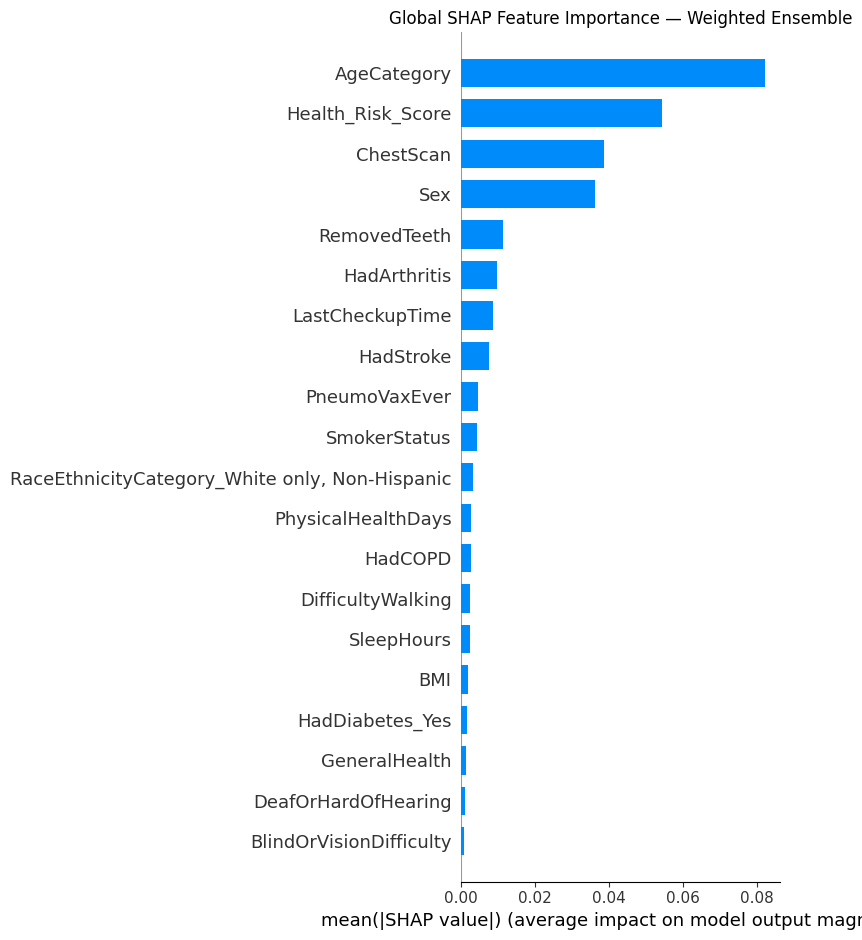


Saved:
/content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_global_bar.png


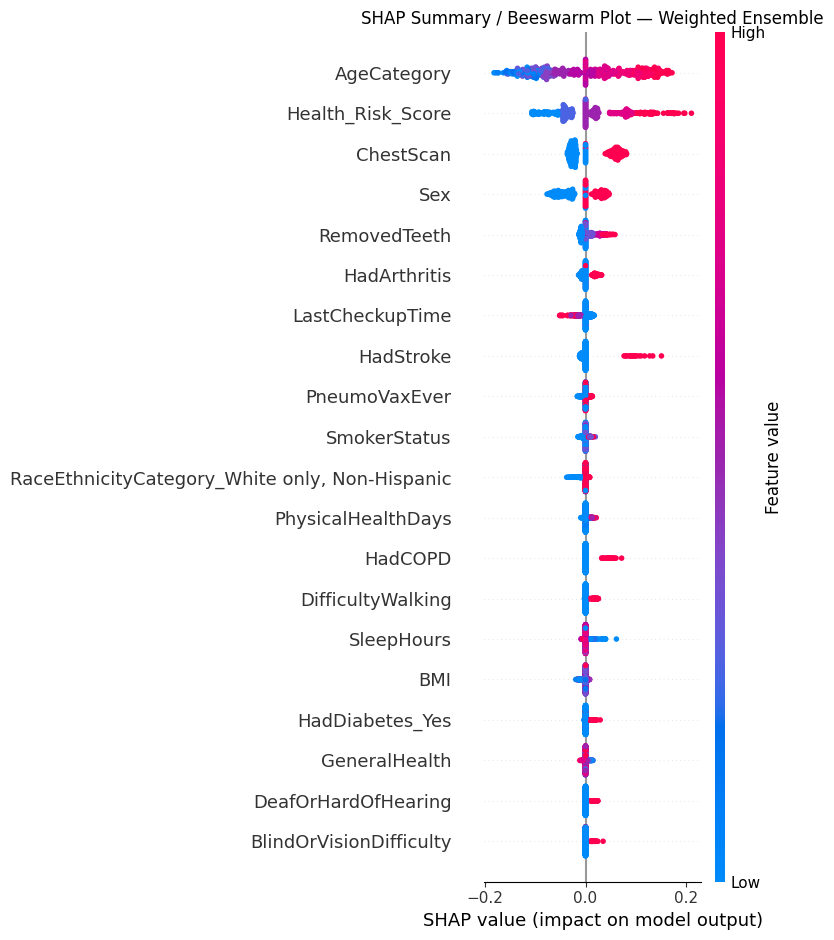


Saved:
/content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_beeswarm.png

THESIS-SPECIFIC SHAP FEATURES
AgeCategory               | Rank =  1 | Mean |SHAP| = 0.082161
GeneralHealth             | Rank = 18 | Mean |SHAP| = 0.001200
BMI_Category              | Rank = 46 | Mean |SHAP| = 0.000000
HadStroke                 | Rank =  8 | Mean |SHAP| = 0.007476
Health_Risk_Score         | Rank =  2 | Mean |SHAP| = 0.054307

CREATING DEPENDENCE PLOTS

Dependence features: ['AgeCategory', 'Health_Risk_Score', 'ChestScan', 'Sex', 'RemovedTeeth']

Creating dependence plot: AgeCategory


<Figure size 900x700 with 0 Axes>

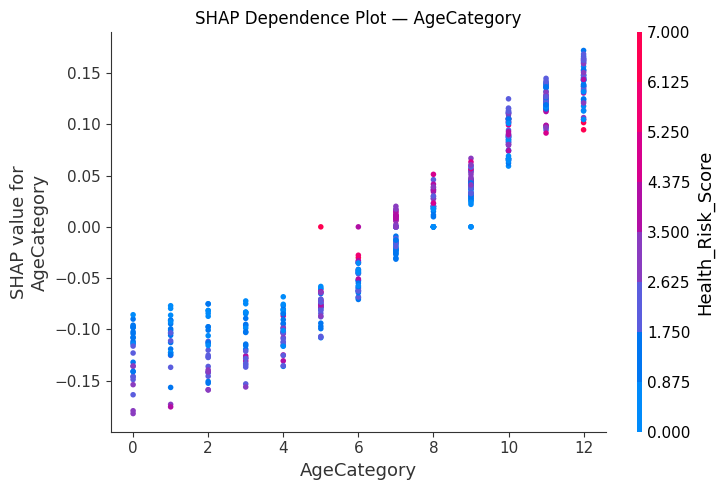

Saved:
/content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_dependence_AgeCategory.png

Creating dependence plot: Health_Risk_Score


<Figure size 900x700 with 0 Axes>

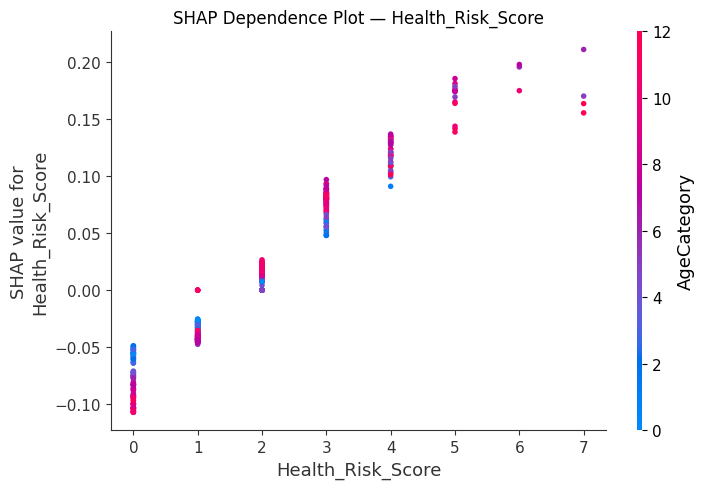

Saved:
/content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_dependence_Health_Risk_Score.png

Creating dependence plot: ChestScan


<Figure size 900x700 with 0 Axes>

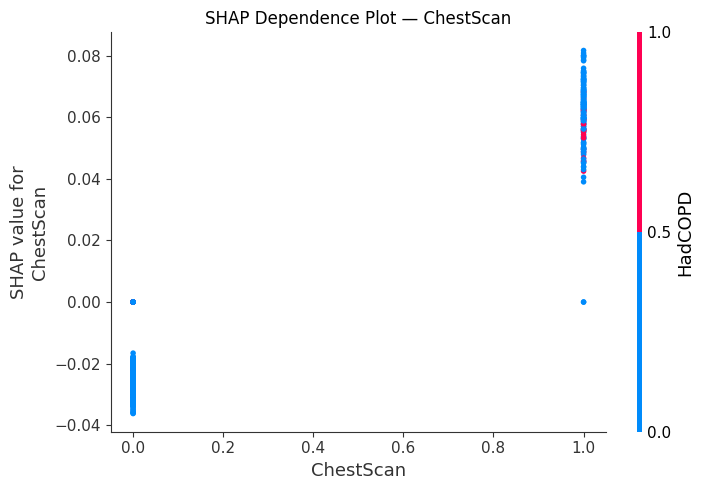

Saved:
/content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_dependence_ChestScan.png

Creating dependence plot: Sex


<Figure size 900x700 with 0 Axes>

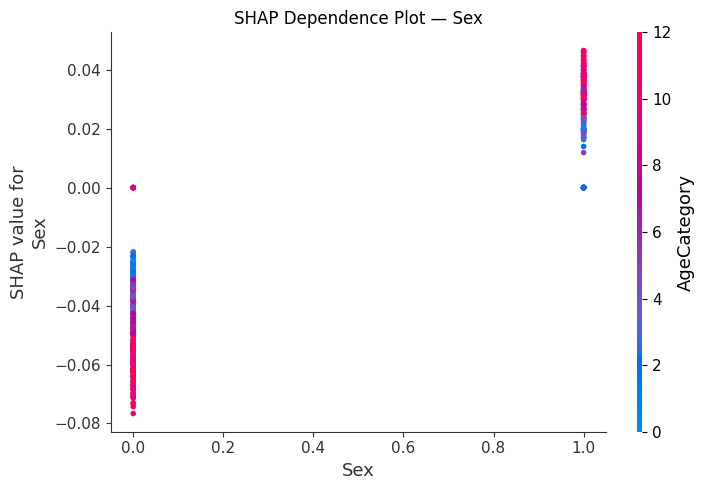

Saved:
/content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_dependence_Sex.png

Creating dependence plot: RemovedTeeth


<Figure size 900x700 with 0 Axes>

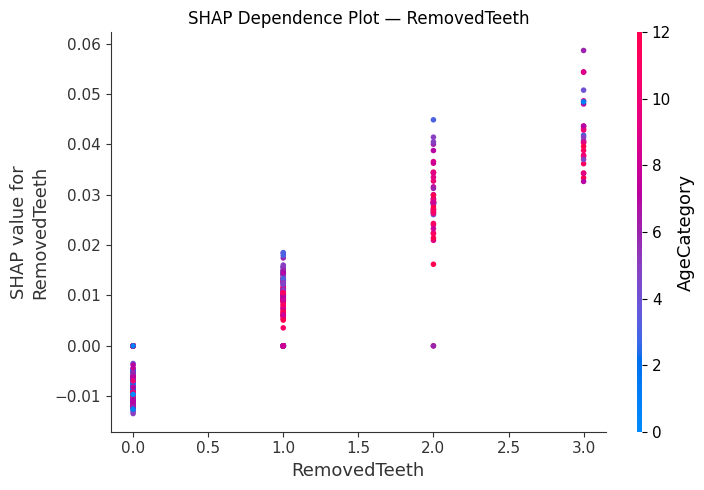

Saved:
/content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_dependence_RemovedTeeth.png

GLOBAL + DEPENDENCE SHAP ANALYSIS COMPLETE

Generated files:
1. Global importance CSV
2. Global SHAP bar plot
3. SHAP beeswarm plot
4. Dependence plots for top 5 features

NO MODEL RETRAINING
NO SHAP RECALCULATION
Existing probability-space SHAP checkpoint was used.


In [ ]:
# ============================================================
# STEP 4 — GLOBAL SHAP + BEESWARM + DEPENDENCE PLOTS
# FINAL WEIGHTED ENSEMBLE
# Uses SAVED probability-space SHAP
# NO SHAP RECALCULATION
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

print("=" * 70)
print("GLOBAL SHAP ANALYSIS — FINAL WEIGHTED ENSEMBLE")
print("=" * 70)

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

SHAP_DIR = f"{RESULTS_DIR}/ensemble"

prob_shap_path = (
    f"{SHAP_DIR}/newensemble_probability_shap_values.pkl"
)

prob_base_path = (
    f"{SHAP_DIR}/newensemble_probability_shap_base.pkl"
)

prob_X_path = (
    f"{SHAP_DIR}/newensemble_probability_shap_X.pkl"
)

# ------------------------------------------------------------
# 2. LOAD SAVED PROBABILITY-SHAP
# ------------------------------------------------------------

shap_probability_values = joblib.load(
    prob_shap_path
)

expected_value_probability = joblib.load(
    prob_base_path
)

X_explain = joblib.load(
    prob_X_path
)

shap_probability_values = np.asarray(
    shap_probability_values,
    dtype=float
)

print("\nLoaded:")
print("SHAP values :", shap_probability_values.shape)
print("X explain   :", X_explain.shape)
print("Base value  :", expected_value_probability)

# ------------------------------------------------------------
# 3. BASIC VALIDATION
# ------------------------------------------------------------

assert shap_probability_values.shape == (
    len(X_explain),
    X_explain.shape[1]
)

assert X_explain.shape[1] == 47

print("\nPASS: SHAP dimensions are correct.")


# ============================================================
# 4. GLOBAL FEATURE IMPORTANCE
# ============================================================

mean_abs_shap = np.abs(
    shap_probability_values
).mean(axis=0)

global_importance = pd.DataFrame({
    "feature": X_explain.columns,
    "mean_abs_shap": mean_abs_shap
})

global_importance = (
    global_importance
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("TOP 20 GLOBAL SHAP FEATURES")
print("=" * 70)

print(
    global_importance.head(20).to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 5. SAVE GLOBAL IMPORTANCE
# ------------------------------------------------------------

importance_path = (
    f"{SHAP_DIR}/final_probability_shap_global_importance.csv"
)

global_importance.to_csv(
    importance_path,
    index=False
)

print("\nSaved:")
print(importance_path)


# ============================================================
# 6. GLOBAL SHAP BAR PLOT
# ============================================================

plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_probability_values,
    X_explain,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.title(
    "Global SHAP Feature Importance — Weighted Ensemble"
)

plt.tight_layout()

bar_path = (
    f"{SHAP_DIR}/final_probability_shap_global_bar.png"
)

plt.savefig(
    bar_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(bar_path)


# ============================================================
# 7. SHAP BEESWARM
# ============================================================

plt.figure(figsize=(11, 9))

shap.summary_plot(
    shap_probability_values,
    X_explain,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary / Beeswarm Plot — Weighted Ensemble"
)

plt.tight_layout()

beeswarm_path = (
    f"{SHAP_DIR}/final_probability_shap_beeswarm.png"
)

plt.savefig(
    beeswarm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(beeswarm_path)


# ============================================================
# 8. THESIS-SPECIFIC FEATURES
# ============================================================

print("\n" + "=" * 70)
print("THESIS-SPECIFIC SHAP FEATURES")
print("=" * 70)

thesis_features = [
    "AgeCategory",
    "GeneralHealth",
    "BMI_Category",
    "HadStroke",
    "Health_Risk_Score"
]

for feature in thesis_features:

    if feature in global_importance["feature"].values:

        row = global_importance[
            global_importance["feature"] == feature
        ].iloc[0]

        rank = (
            global_importance.index[
                global_importance["feature"] == feature
            ][0] + 1
        )

        print(
            f"{feature:25s} "
            f"| Rank = {rank:2d} "
            f"| Mean |SHAP| = {row['mean_abs_shap']:.6f}"
        )

    else:

        print(
            f"{feature:25s} | NOT FOUND"
        )


# ============================================================
# 9. DEPENDENCE PLOTS
# ============================================================

print("\n" + "=" * 70)
print("CREATING DEPENDENCE PLOTS")
print("=" * 70)

# Top features from actual probability-space SHAP
top_dependence_features = (
    global_importance
    .head(5)["feature"]
    .tolist()
)

print(
    "\nDependence features:",
    top_dependence_features
)

for feature in top_dependence_features:

    print(
        f"\nCreating dependence plot: {feature}"
    )

    plt.figure(figsize=(9, 7))

    shap.dependence_plot(
        feature,
        shap_probability_values,
        X_explain,
        interaction_index="auto",
        show=False
    )

    plt.title(
        f"SHAP Dependence Plot — {feature}"
    )

    plt.tight_layout()

    safe_name = (
        feature
        .replace("/", "_")
        .replace(" ", "_")
        .replace(",", "_")
        .replace(":", "_")
    )

    dep_path = (
        f"{SHAP_DIR}/"
        f"final_probability_shap_dependence_{safe_name}.png"
    )

    plt.savefig(
        dep_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:")
    print(dep_path)


# ============================================================
# 10. FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("GLOBAL + DEPENDENCE SHAP ANALYSIS COMPLETE")
print("=" * 70)

print("\nGenerated files:")
print("1. Global importance CSV")
print("2. Global SHAP bar plot")
print("3. SHAP beeswarm plot")
print("4. Dependence plots for top 5 features")

print("\nNO MODEL RETRAINING")
print("NO SHAP RECALCULATION")
print("Existing probability-space SHAP checkpoint was used.")

LOCAL SHAP EXPLAINABILITY — FINAL WEIGHTED ENSEMBLE

Loaded:
SHAP values : (500, 47)
X explain   : (500, 47)
Base value  : 0.248038480213752

Final shapes:
X_explain   : (500, 47)
SHAP values : (500, 47)

Probability range:
Min: 0.015022139884660918
Max: 0.7673836022851585

Selected local cases:
High-risk index: 315 Probability: 0.7673836022851585
Low-risk index: 31 Probability: 0.015022139884660918

Creating HIGH-RISK local explanation...


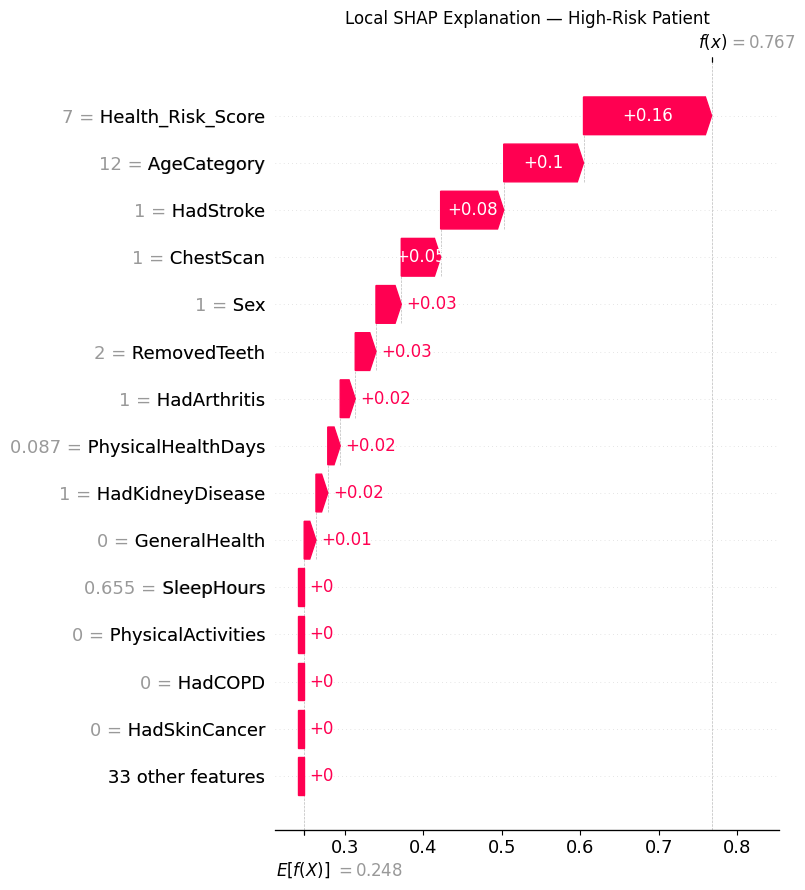

Saved:
/content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_local_high_risk.png

Creating LOW-RISK local explanation...


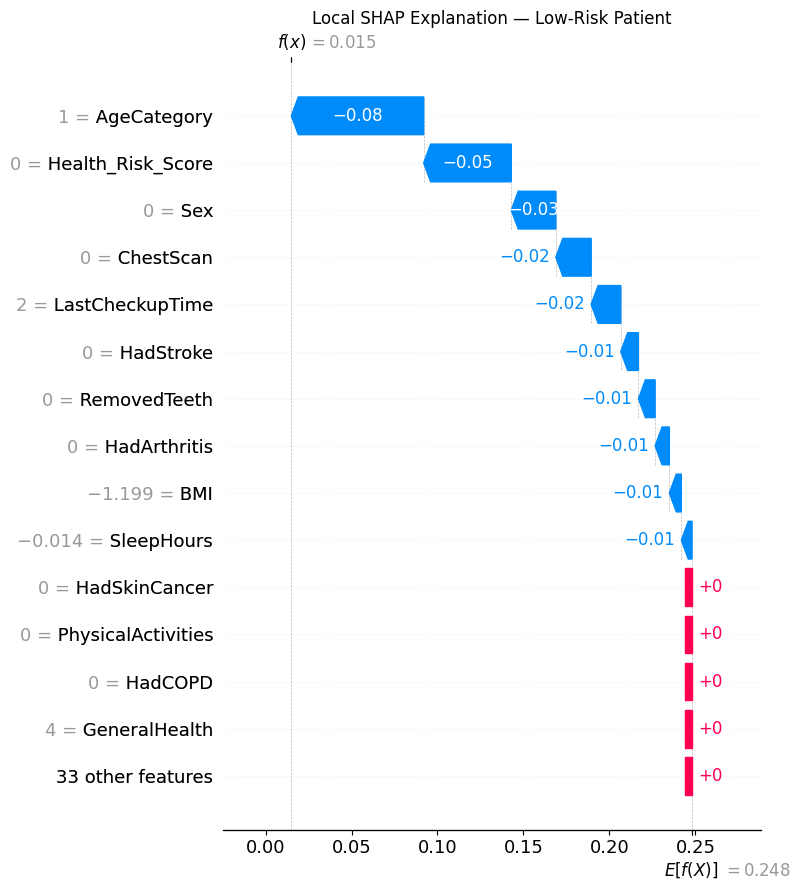

Saved:
/content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_local_low_risk.png

Saved:
/content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_local_cases.csv

LOCAL SHAP ANALYSIS COMPLETE

Generated:
1. High-risk waterfall plot
2. Low-risk waterfall plot
3. Local case summary CSV

NO MODEL RETRAINING
NO SHAP RECALCULATION


In [ ]:
# ================================================================
# LOCAL SHAP EXPLAINABILITY — FINAL WEIGHTED ENSEMBLE
# ================================================================

import os
import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

print("=" * 70)
print("LOCAL SHAP EXPLAINABILITY — FINAL WEIGHTED ENSEMBLE")
print("=" * 70)

# ------------------------------------------------
# 1. Load existing probability-space SHAP results
# ------------------------------------------------

SHAP_DIR = f"{RESULTS_DIR}/ensemble"

shap_values = joblib.load(
    f"{SHAP_DIR}/newensemble_probability_shap_values.pkl"
)

X_explain = joblib.load(
    f"{SHAP_DIR}/newensemble_probability_shap_X.pkl"
)

base_value = joblib.load(
    f"{SHAP_DIR}/newensemble_probability_shap_base.pkl"
)

print("\nLoaded:")
print("SHAP values :", shap_values.shape)
print("X explain   :", X_explain.shape)
print("Base value  :", base_value)


# ------------------------------------------------
# 2. Convert to DataFrame if necessary
# ------------------------------------------------

if not isinstance(X_explain, pd.DataFrame):
    X_explain = pd.DataFrame(
        X_explain,
        columns=feature_names
    )

X_explain = X_explain.reset_index(drop=True)

shap_values = np.asarray(shap_values)

print("\nFinal shapes:")
print("X_explain   :", X_explain.shape)
print("SHAP values :", shap_values.shape)


# ------------------------------------------------
# 3. Reconstruct ensemble probability
# ------------------------------------------------

reconstructed_probability = (
    base_value + shap_values.sum(axis=1)
)

print("\nProbability range:")
print(
    "Min:",
    reconstructed_probability.min()
)

print(
    "Max:",
    reconstructed_probability.max()
)


# ------------------------------------------------
# 4. Select representative local cases
# ------------------------------------------------

# Highest-risk patient
high_risk_idx = int(
    np.argmax(reconstructed_probability)
)

# Lowest-risk patient
low_risk_idx = int(
    np.argmin(reconstructed_probability)
)

print("\nSelected local cases:")
print(
    "High-risk index:",
    high_risk_idx,
    "Probability:",
    reconstructed_probability[high_risk_idx]
)

print(
    "Low-risk index:",
    low_risk_idx,
    "Probability:",
    reconstructed_probability[low_risk_idx]
)


# ------------------------------------------------
# 5. Create SHAP Explanation objects
# ------------------------------------------------

high_risk_explanation = shap.Explanation(
    values=shap_values[high_risk_idx],
    base_values=base_value,
    data=X_explain.iloc[high_risk_idx].values,
    feature_names=X_explain.columns.tolist()
)

low_risk_explanation = shap.Explanation(
    values=shap_values[low_risk_idx],
    base_values=base_value,
    data=X_explain.iloc[low_risk_idx].values,
    feature_names=X_explain.columns.tolist()
)


# ------------------------------------------------
# 6. High-risk waterfall plot
# ------------------------------------------------

print("\nCreating HIGH-RISK local explanation...")

plt.figure(figsize=(10, 8))

shap.plots.waterfall(
    high_risk_explanation,
    max_display=15,
    show=False
)

plt.title(
    "Local SHAP Explanation — High-Risk Patient"
)

plt.tight_layout()

high_risk_path = (
    f"{SHAP_DIR}/final_probability_shap_local_high_risk.png"
)

plt.savefig(
    high_risk_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(high_risk_path)


# ------------------------------------------------
# 7. Low-risk waterfall plot
# ------------------------------------------------

print("\nCreating LOW-RISK local explanation...")

plt.figure(figsize=(10, 8))

shap.plots.waterfall(
    low_risk_explanation,
    max_display=15,
    show=False
)

plt.title(
    "Local SHAP Explanation — Low-Risk Patient"
)

plt.tight_layout()

low_risk_path = (
    f"{SHAP_DIR}/final_probability_shap_local_low_risk.png"
)

plt.savefig(
    low_risk_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(low_risk_path)


# ------------------------------------------------
# 8. Save selected case information
# ------------------------------------------------

local_cases = pd.DataFrame({
    "case": [
        "High-risk",
        "Low-risk"
    ],
    "sample_index": [
        high_risk_idx,
        low_risk_idx
    ],
    "predicted_probability": [
        reconstructed_probability[high_risk_idx],
        reconstructed_probability[low_risk_idx]
    ]
})

local_cases_path = (
    f"{SHAP_DIR}/final_probability_shap_local_cases.csv"
)

local_cases.to_csv(
    local_cases_path,
    index=False
)

print("\nSaved:")
print(local_cases_path)


print("\n" + "=" * 70)
print("LOCAL SHAP ANALYSIS COMPLETE")
print("=" * 70)

print("\nGenerated:")
print("1. High-risk waterfall plot")
print("2. Low-risk waterfall plot")
print("3. Local case summary CSV")

print("\nNO MODEL RETRAINING")
print("NO SHAP RECALCULATION")

TOP-10 SHAP RISK FACTORS — FINAL WEIGHTED ENSEMBLE

TOP 10 SHAP RISK FACTORS:
          feature  mean_abs_shap
      AgeCategory       0.082161
Health_Risk_Score       0.054307
        ChestScan       0.038554
              Sex       0.036090
     RemovedTeeth       0.011368
     HadArthritis       0.009586
  LastCheckupTime       0.008662
        HadStroke       0.007476
    PneumoVaxEver       0.004536
     SmokerStatus       0.004401


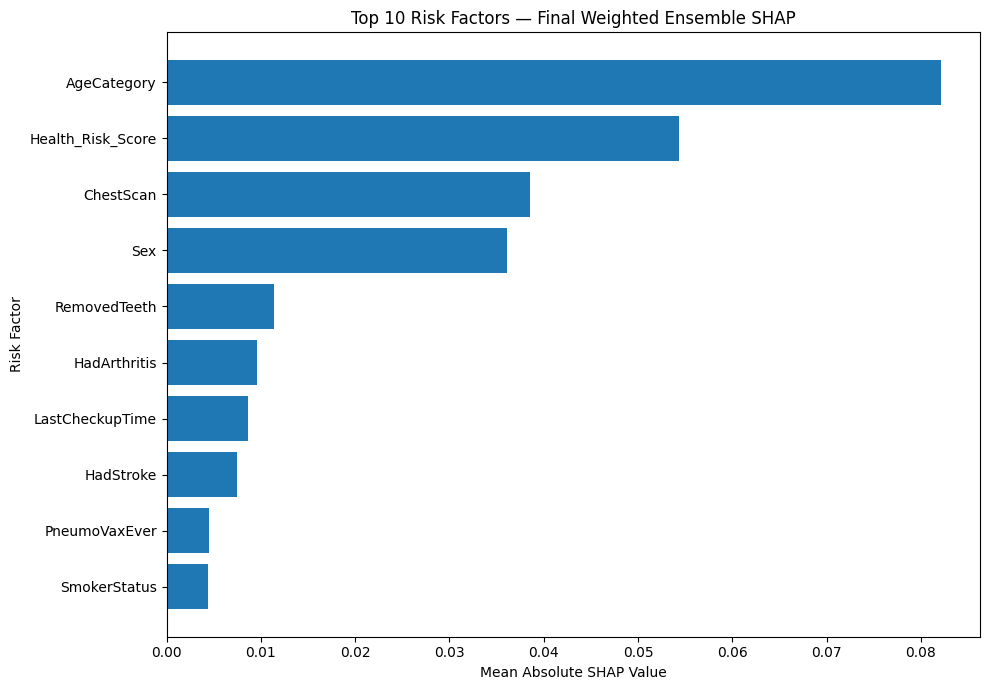


Saved:
/content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_top10_risk_factors.png

NO MODEL RETRAINING
NO SHAP RECALCULATION


In [ ]:
# ================================================================
# TOP-10 SHAP RISK FACTORS — FINAL WEIGHTED ENSEMBLE
# ================================================================

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("TOP-10 SHAP RISK FACTORS — FINAL WEIGHTED ENSEMBLE")
print("=" * 70)

SHAP_DIR = f"{RESULTS_DIR}/ensemble"

# Load existing SHAP results
shap_values = joblib.load(
    f"{SHAP_DIR}/newensemble_probability_shap_values.pkl"
)

X_explain = joblib.load(
    f"{SHAP_DIR}/newensemble_probability_shap_X.pkl"
)

# Make sure DataFrame
if not isinstance(X_explain, pd.DataFrame):
    X_explain = pd.DataFrame(
        X_explain,
        columns=feature_names
    )

# Mean absolute SHAP
mean_abs_shap = np.mean(
    np.abs(shap_values),
    axis=0
)

importance_df = pd.DataFrame({
    "feature": X_explain.columns,
    "mean_abs_shap": mean_abs_shap
})

importance_df = importance_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

# Top 10
top10 = importance_df.head(10).copy()

print("\nTOP 10 SHAP RISK FACTORS:")
print(top10.to_string(index=False))

# ------------------------------------------------
# Plot
# ------------------------------------------------

plt.figure(figsize=(10, 7))

plt.barh(
    top10["feature"][::-1],
    top10["mean_abs_shap"][::-1]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Risk Factor")
plt.title(
    "Top 10 Risk Factors — Final Weighted Ensemble SHAP"
)

plt.tight_layout()

top10_path = (
    f"{SHAP_DIR}/final_probability_shap_top10_risk_factors.png"
)

plt.savefig(
    top10_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(top10_path)

print("\nNO MODEL RETRAINING")
print("NO SHAP RECALCULATION")

LOCAL SHAP FORCE PLOT — HIGH-RISK CASE

High-risk case index: 315
Predicted probability: 0.7673836022851585


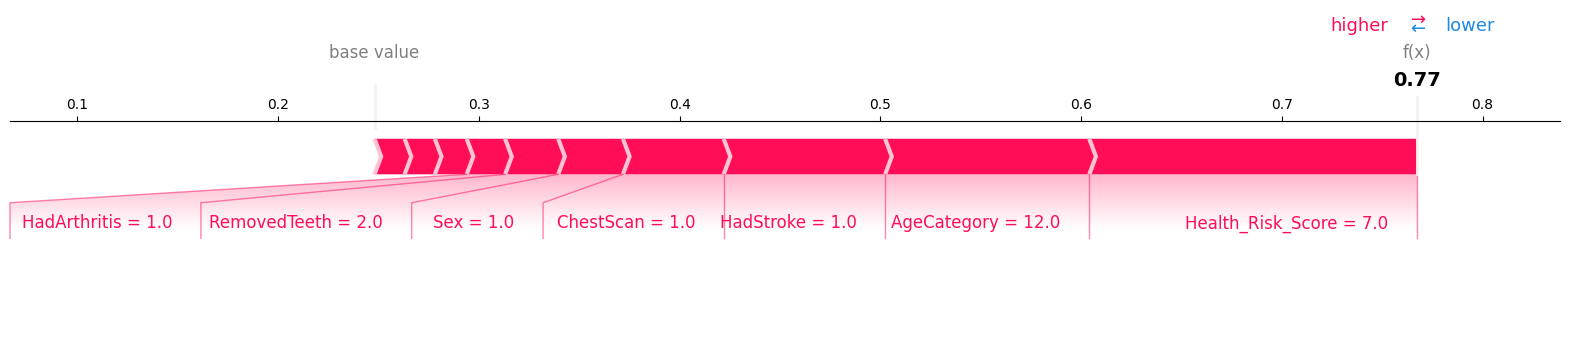


Saved:
/content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_force_high_risk.png

NO MODEL RETRAINING
NO SHAP RECALCULATION


In [ ]:
# ================================================================
# LOCAL SHAP FORCE PLOT — HIGH-RISK CASE
# ================================================================

import os
import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

print("=" * 70)
print("LOCAL SHAP FORCE PLOT — HIGH-RISK CASE")
print("=" * 70)

SHAP_DIR = f"{RESULTS_DIR}/ensemble"

# Load existing SHAP results
shap_values = joblib.load(
    f"{SHAP_DIR}/newensemble_probability_shap_values.pkl"
)

X_explain = joblib.load(
    f"{SHAP_DIR}/newensemble_probability_shap_X.pkl"
)

base_value = joblib.load(
    f"{SHAP_DIR}/newensemble_probability_shap_base.pkl"
)

if not isinstance(X_explain, pd.DataFrame):
    X_explain = pd.DataFrame(
        X_explain,
        columns=feature_names
    )

X_explain = X_explain.reset_index(drop=True)

# Reconstruct probability
predicted_probability = (
    base_value + shap_values.sum(axis=1)
)

# Same high-risk case selected earlier
high_risk_idx = int(
    np.argmax(predicted_probability)
)

print("\nHigh-risk case index:", high_risk_idx)
print(
    "Predicted probability:",
    predicted_probability[high_risk_idx]
)

# ------------------------------------------------
# Create force plot
# ------------------------------------------------

force_plot = shap.force_plot(
    base_value,
    shap_values[high_risk_idx],
    X_explain.iloc[high_risk_idx],
    matplotlib=True,
    show=False
)

force_path = (
    f"{SHAP_DIR}/final_probability_shap_force_high_risk.png"
)

plt.savefig(
    force_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(force_path)

print("\nNO MODEL RETRAINING")
print("NO SHAP RECALCULATION")

In [ ]:
import os

shap_ckpt = f'{RESULTS_DIR}/ensemble/newensemble_shap_values.pkl'
base_val_ckpt = f'{RESULTS_DIR}/ensemble/newensemble_shap_base.pkl'

print("SHAP checkpoint exists:", os.path.exists(shap_ckpt))
print("Base value checkpoint exists:", os.path.exists(base_val_ckpt))

if os.path.exists(shap_ckpt):
    print("SHAP file size:", os.path.getsize(shap_ckpt) / (1024**2), "MB")

if os.path.exists(base_val_ckpt):
    print("Base file size:", os.path.getsize(base_val_ckpt) / (1024**2), "MB")

SHAP checkpoint exists: True
Base value checkpoint exists: True
SHAP file size: 1.793137550354004 MB
Base file size: 2.002716064453125e-05 MB


In [ ]:
sv = joblib.load(shap_ckpt)
base_values_combined = joblib.load(base_val_ckpt)

print("Loaded SHAP shape:", sv.shape)
print("Loaded base value:", base_values_combined)

Loaded SHAP shape: (5000, 47)
Loaded base value: -1.4178198856347868


In [ ]:
# ============================================================
# LOAD EXISTING SHAP CHECKPOINT
# ============================================================

import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

SHAP_SAMPLE_SIZE = 5000

shap_ckpt = (
    f'{RESULTS_DIR}/ensemble/newensemble_shap_values.pkl'
)

base_val_ckpt = (
    f'{RESULTS_DIR}/ensemble/newensemble_shap_base.pkl'
)

# Load saved SHAP
sv = joblib.load(shap_ckpt)

# Load saved base value
base_values_combined = joblib.load(base_val_ckpt)

print("Loaded SHAP:", sv.shape)
print("Loaded base value:", base_values_combined)


# Recreate EXACT SAME SHAP sample
sample_size = min(
    SHAP_SAMPLE_SIZE,
    len(X_test)
)

if sample_size < len(X_test):

    X_shap, _, y_shap, _ = train_test_split(
        X_test,
        y_test,
        train_size=sample_size,
        stratify=y_test,
        random_state=42
    )

else:

    X_shap = X_test.copy()
    y_shap = y_test.copy()


print("Recovered X_shap:", X_shap.shape)
print("Recovered y_shap:", y_shap.shape)


# Safety check
assert sv.shape == (
    X_shap.shape[0],
    X_shap.shape[1]
)

print("\nSHAP CHECKPOINT RECOVERED SUCCESSFULLY.")

Loaded SHAP: (5000, 47)
Loaded base value: -1.4178198856347868
Recovered X_shap: (5000, 47)
Recovered y_shap: (5000,)

SHAP CHECKPOINT RECOVERED SUCCESSFULLY.


In [ ]:
import shap
import matplotlib.pyplot as plt
import textwrap

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0



TOP 10 SHAP FEATURES
             feature  mean_abs_shap
0        AgeCategory       0.600085
1  Health_Risk_Score       0.387751
2          ChestScan       0.298489
3                Sex       0.247550
4       RemovedTeeth       0.112118
5       HadArthritis       0.098718
6          HadStroke       0.068145
7            HadCOPD       0.065536
8    LastCheckupTime       0.063744
9       SmokerStatus       0.059053

Table 10 and Table 11 saved.
Saved: /content/drive/MyDrive/CVD/figures/figure13_shap_summary_plot/figure13_shap_summary_plot.pdf and .png


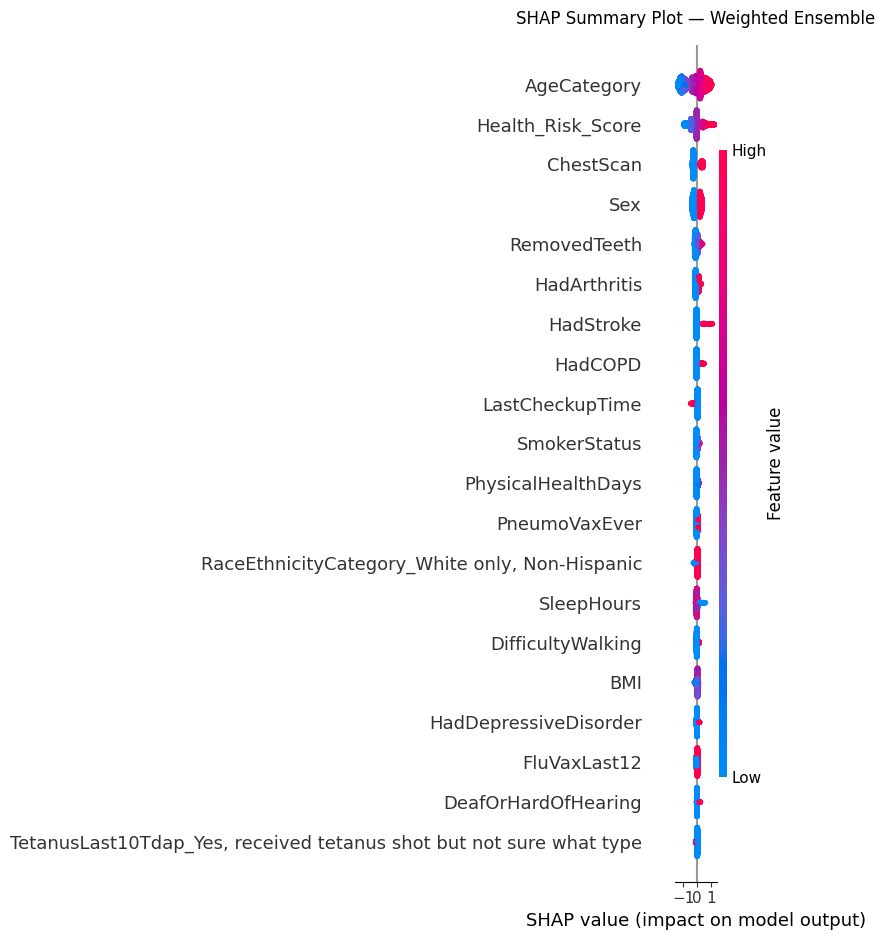

Saved: /content/drive/MyDrive/CVD/figures/figure14_shap_waterfall_patient/figure14_shap_waterfall_patient.pdf and .png


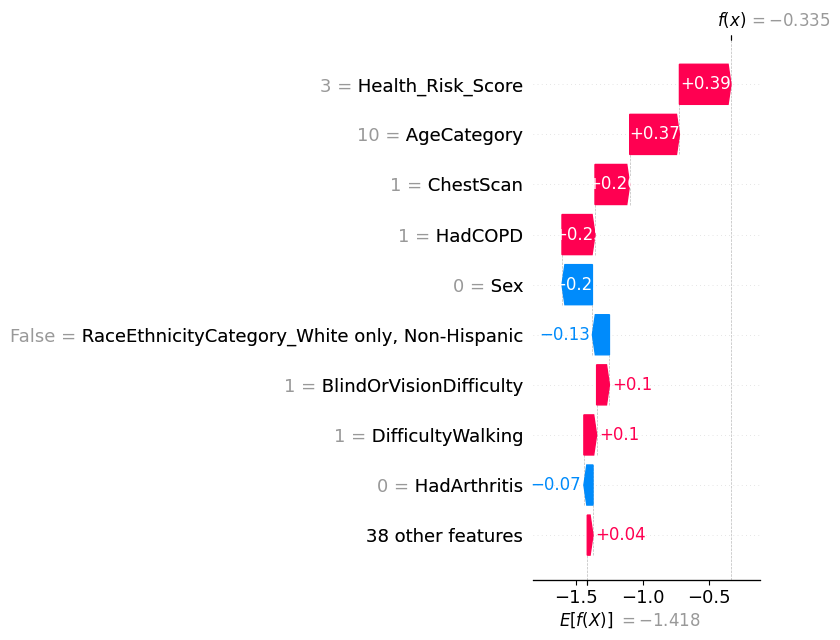


Figure 14b saved:
/content/drive/MyDrive/CVD/figures/figure14b_shap_force_plot/figure14b_shap_force_plot.pdf
/content/drive/MyDrive/CVD/figures/figure14b_shap_force_plot/figure14b_shap_force_plot.png


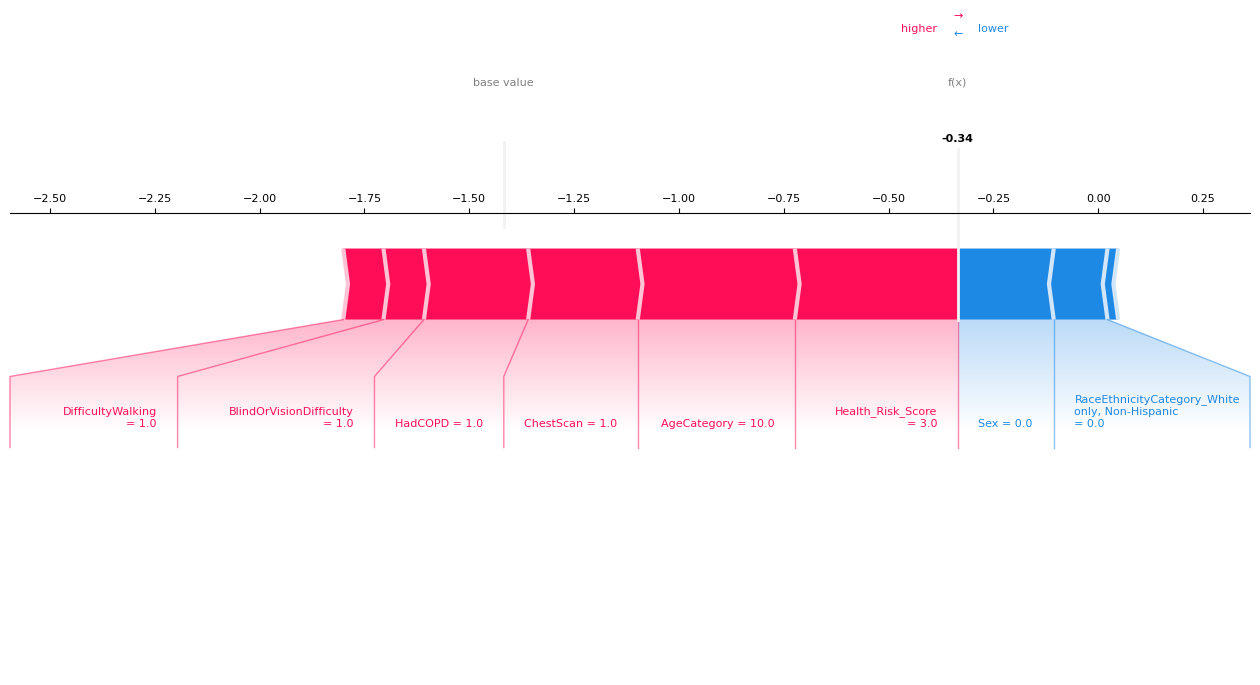

Saved: /content/drive/MyDrive/CVD/figures/figure15_shap_dependence_plot/figure15_shap_dependence_plot.pdf and .png


<Figure size 900x700 with 0 Axes>

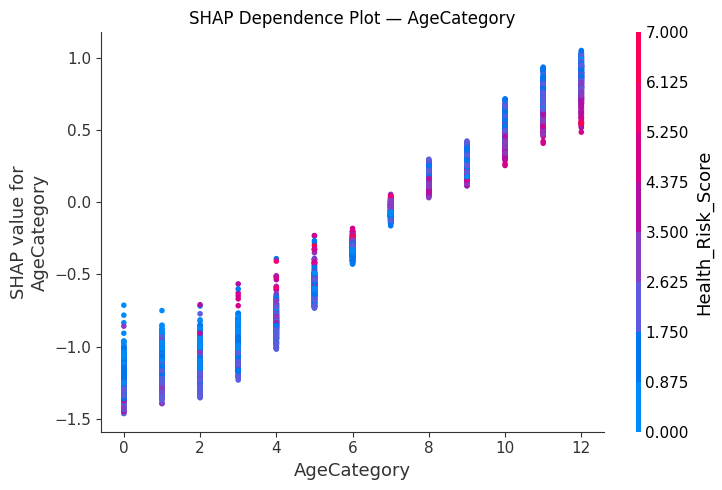

Saved: /content/drive/MyDrive/CVD/figures/figure16_risk_factor_distribution/figure16_risk_factor_distribution.pdf and .png


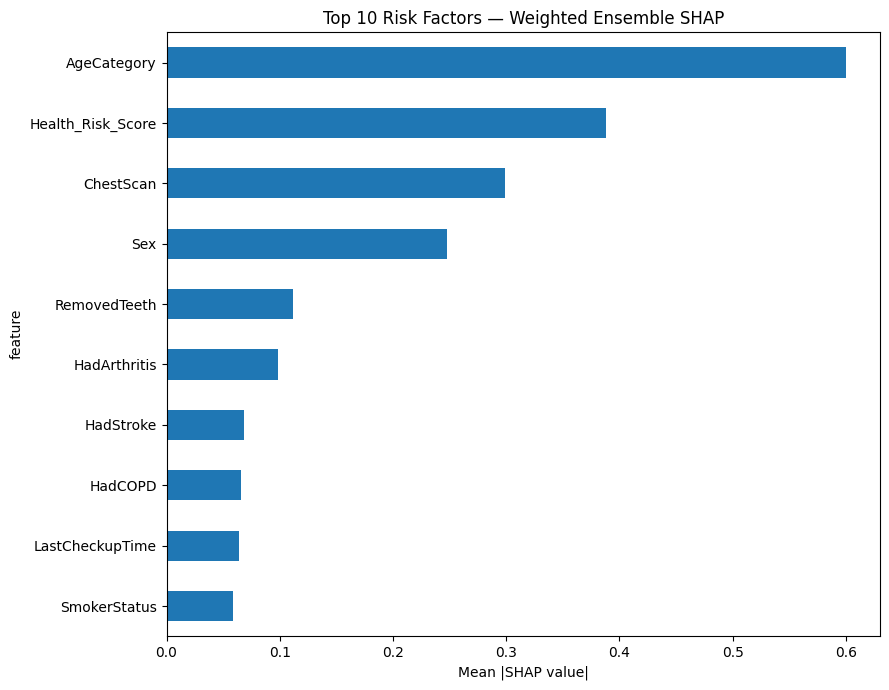


SHAP ANALYSIS COMPLETED SUCCESSFULLY


In [ ]:
# new============================================================
# TABLE 10 — GLOBAL SHAP FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({

    'feature':
        X_shap.columns,

    'mean_abs_shap':
        np.abs(sv).mean(axis=0)

})


importance = importance.sort_values(
    'mean_abs_shap',
    ascending=False
).reset_index(drop=True)


t10_folder = fig_folder(
    'table10_global_shap_importance'
)


importance.to_csv(
    f'{t10_folder}/table10_global_shap_importance.csv',
    index=False
)


print("\n" + "=" * 60)
print("TOP 10 SHAP FEATURES")
print("=" * 60)

print(
    importance.head(10)
)


# ============================================================
# TABLE 11 — TOP RISK FACTORS
# ============================================================

t11_folder = fig_folder(
    'table11_risk_factor_importance'
)


importance.head(10).to_csv(
    f'{t11_folder}/table11_risk_factor_importance.csv',
    index=False
)


print(
    "\nTable 10 and Table 11 saved."
)


# ============================================================
# FIGURE 13 — SHAP GLOBAL SUMMARY
# ============================================================

fig13 = plt.figure(
    figsize=(10, 7)
)

shap.summary_plot(
    sv,
    X_shap,
    show=False
)

plt.title(
    'SHAP Summary Plot — Weighted Ensemble',
    pad=15
)

plt.tight_layout()

save_figure(
    fig13,
    'figure13_shap_summary_plot'
)

plt.show()

plt.close(fig13)


# ============================================================
# FIGURE 14 — LOCAL SHAP WATERFALL
# ============================================================

local_idx = 0


fig14 = plt.figure(
    figsize=(10, 7)
)


explanation = shap.Explanation(

    values=sv[local_idx],

    base_values=base_values_combined,

    data=X_shap.iloc[local_idx].values,

    feature_names=X_shap.columns.tolist()

)


shap.plots.waterfall(
    explanation,
    show=False
)


plt.tight_layout()


save_figure(
    fig14,
    'figure14_shap_waterfall_patient'
)


plt.show()

plt.close(fig14)


# ============================================================
# FIGURE 14b — SHAP FORCE PLOT
# ============================================================

TOP_N = 8


local_values = sv[local_idx]

local_data = X_shap.iloc[local_idx]


# ------------------------------------------------------------
# Select strongest local contributors
# ------------------------------------------------------------

top_indices = np.argsort(
    np.abs(local_values)
)[::-1][:TOP_N]


top_shap = local_values[
    top_indices
]


top_data = local_data.iloc[
    top_indices
].values


top_names = X_shap.columns[
    top_indices
].tolist()


# ------------------------------------------------------------
# Aggregate remaining features
# ------------------------------------------------------------

remaining_indices = np.setdiff1d(
    np.arange(len(local_values)),
    top_indices
)


other_shap = local_values[
    remaining_indices
].sum()


plot_shap = np.append(
    top_shap,
    other_shap
)


plot_data = np.append(
    top_data,
    '—'
)


# ------------------------------------------------------------
# Wrap feature names
# ------------------------------------------------------------

def wrap_feature_name(
    name,
    width=14
):

    return textwrap.fill(
        str(name),
        width=width,
        break_long_words=False,
        break_on_hyphens=False
    )


plot_names = [

    wrap_feature_name(
        name,
        width=14
    )

    for name in top_names

]


plot_names.append(
    'Other\nfeatures'
)


# ------------------------------------------------------------
# Force plot
# ------------------------------------------------------------

shap.initjs()


force_fig = shap.force_plot(

    base_values_combined,

    plot_shap,

    plot_data,

    feature_names=plot_names,

    matplotlib=True,

    show=False

)


force_fig.set_size_inches(
    16,
    6
)


# ------------------------------------------------------------
# Reduce font size
# ------------------------------------------------------------

for ax in force_fig.axes:

    ax.tick_params(
        axis='both',
        labelsize=8
    )

    for txt in ax.texts:

        txt.set_fontsize(8)

        current_text = txt.get_text()

        if len(current_text) > 16:

            txt.set_text(
                textwrap.fill(
                    current_text,
                    width=18,
                    break_long_words=False,
                    break_on_hyphens=False
                )
            )


# ------------------------------------------------------------
# Save force plot
# ------------------------------------------------------------

force_folder = fig_folder(
    'figure14b_shap_force_plot'
)


force_fig.savefig(
    f'{force_folder}/figure14b_shap_force_plot.pdf',
    dpi=300,
    bbox_inches='tight'
)


force_fig.savefig(
    f'{force_folder}/figure14b_shap_force_plot.png',
    dpi=300,
    bbox_inches='tight'
)


print(
    "\nFigure 14b saved:"
)

print(
    f'{force_folder}/figure14b_shap_force_plot.pdf'
)

print(
    f'{force_folder}/figure14b_shap_force_plot.png'
)


plt.show()


# ============================================================
# FIGURE 15 — SHAP DEPENDENCE PLOT
# ============================================================

top_feature = (
    importance.iloc[0]['feature']
)


fig15 = plt.figure(
    figsize=(9, 7)
)


shap.dependence_plot(

    top_feature,

    sv,

    X_shap,

    show=False

)


plt.title(
    f'SHAP Dependence Plot — {top_feature}'
)


plt.tight_layout()


save_figure(
    fig15,
    'figure15_shap_dependence_plot'
)


plt.show()

plt.close(fig15)


# ============================================================
# FIGURE 16 — TOP 10 RISK FACTORS
# ============================================================

fig16, ax16 = plt.subplots(
    figsize=(9, 7)
)


importance.head(10).plot(

    kind='barh',

    x='feature',

    y='mean_abs_shap',

    ax=ax16,

    legend=False

)


ax16.invert_yaxis()


ax16.set_title(
    'Top 10 Risk Factors — Weighted Ensemble SHAP'
)


ax16.set_xlabel(
    'Mean |SHAP value|'
)


plt.tight_layout()


save_figure(
    fig16,
    'figure16_risk_factor_distribution'
)


plt.show()

plt.close(fig16)


print("\n" + "=" * 60)
print("SHAP ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 60)



In [ ]:
# nonono============================================================
# SHAP: Global + Local Explainability
# Representative stratified test sample
# ============================================================

import shap
import numpy as np
import pandas as pd
import joblib
import os

# ------------------------------------------------------------
# 1. Create a representative stratified sample from TEST set
# ------------------------------------------------------------

SHAP_SAMPLE_SIZE = 5000

# Keep class proportions representative
from sklearn.model_selection import train_test_split

X_shap, _, y_shap, _ = train_test_split(
    X_test,
    y_test,
    test_size=max(0, len(X_test) - SHAP_SAMPLE_SIZE),
    stratify=y_test,
    random_state=42
)

print("Full test set:", X_test.shape)
print("SHAP sample:", X_shap.shape)
print("SHAP sample class distribution:")
print(y_shap.value_counts(normalize=True))


# ------------------------------------------------------------
# 2. LightGBM needs sanitized feature names
# ------------------------------------------------------------
X_shap_lgbm = X_test_lgbm.loc[X_shap.index].copy()
print("X_shap_lgbm:", X_shap_lgbm.shape)
print("Indices aligned:", X_shap.index.equals(X_shap_lgbm.index))


# ------------------------------------------------------------
# 3. Checkpoint paths
# ------------------------------------------------------------

shap_ckpt = f'{RESULTS_DIR}/ensemble/ensemble_shap_values.pkl'
base_val_ckpt = f'{RESULTS_DIR}/ensemble/ensemble_shap_base.pkl'


# ------------------------------------------------------------
# 4. Compute SHAP for each selected base model
# ------------------------------------------------------------

if os.path.exists(shap_ckpt):

    print("SHAP checkpoint found — loading.")

    sv = joblib.load(shap_ckpt)
    base_values_combined = joblib.load(base_val_ckpt)

else:

    per_model_shap = {}
    per_model_base = {}

    X_shap_map = {
        'random_forest': X_shap,
        'xgboost': X_shap,
        'catboost': X_shap,
        'lightgbm': X_shap_lgbm
    }

    for name, model in base_models.items():

        print(f"[{name}] Computing SHAP...")

        explainer = shap.TreeExplainer(model)

        s = explainer.shap_values(X_shap_map[name])

        if isinstance(s, list):
            s = s[1]

        bv = explainer.expected_value

        if isinstance(bv, (list, np.ndarray)):
            bv = bv[1]

        per_model_shap[name] = s
        per_model_base[name] = bv

        print(f"[{name}] SHAP completed.")


    # --------------------------------------------------------
    # 5. Weighted ensemble SHAP
    # --------------------------------------------------------

    sv = np.zeros_like(
        per_model_shap['random_forest'],
        dtype=float
    )

    base_values_combined = 0.0

    for name in base_models:

        sv += (
            ensemble_weights[name]
            * per_model_shap[name]
        )

        base_values_combined += (
            ensemble_weights[name]
            * per_model_base[name]
        )


    # --------------------------------------------------------
    # 6. Save checkpoint
    # --------------------------------------------------------

    joblib.dump(sv, shap_ckpt)
    joblib.dump(base_values_combined, base_val_ckpt)

    print("Ensemble-level SHAP values saved.")


# ============================================================
# TABLE 10 — Global SHAP Feature Importance
# ============================================================

importance = pd.DataFrame({
    'feature': X_shap.columns,
    'mean_abs_shap': np.abs(sv).mean(axis=0)
})

importance = importance.sort_values(
    'mean_abs_shap',
    ascending=False
)

t10_folder = fig_folder(
    'table10_global_shap_importance'
)

importance.to_csv(
    f'{t10_folder}/table10_global_shap_importance.csv',
    index=False
)

print("\nTop 10 SHAP features:")
print(importance.head(10))


# ============================================================
# TABLE 11 — Risk Factor Importance
# ============================================================

t11_folder = fig_folder(
    'table11_risk_factor_importance'
)

importance.head(10).to_csv(
    f'{t11_folder}/table11_risk_factor_importance.csv',
    index=False
)


# ============================================================
# FIGURE 13 — SHAP Summary Plot
# ============================================================

fig13 = plt.figure(figsize=(9,7))

shap.summary_plot(
    sv,
    X_shap,
    show=False
)

save_figure(
    fig13,
    'figure13_shap_summary_plot'
)

plt.close(fig13)


# ============================================================
# FIGURE 14 — Local SHAP Waterfall
# ============================================================

# First test patient from the SHAP sample
local_idx = 0

fig14 = plt.figure(figsize=(10,7))

shap.plots.waterfall(
    shap.Explanation(
        values=sv[local_idx],
        base_values=base_values_combined,
        data=X_shap.iloc[local_idx],
        feature_names=X_shap.columns
    ),
    show=False
)

save_figure(
    fig14,
    'figure14_shap_waterfall_patient'
)

plt.close(fig14)


# ============================================================
# FIGURE 14b — SHAP Force Plot
# ============================================================

shap.initjs()

force_fig = shap.force_plot(
    base_values_combined,
    sv[local_idx],
    X_shap.iloc[local_idx],
    matplotlib=True,
    show=False
)

force_folder = fig_folder(
    'figure14b_shap_force_plot'
)

force_fig.savefig(
    f'{force_folder}/figure14b_shap_force_plot.pdf',
    dpi=300,
    bbox_inches='tight'
)

force_fig.savefig(
    f'{force_folder}/figure14b_shap_force_plot.png',
    dpi=300,
    bbox_inches='tight'
)

print(
    f"Saved: {force_folder}/figure14b_shap_force_plot.pdf and .png"
)

plt.close(force_fig)


# ============================================================
# FIGURE 15 — SHAP Dependence Plot
# ============================================================

top_feature = importance.iloc[0]['feature']

fig15, ax15 = plt.subplots(
    figsize=(8,6)
)

shap.dependence_plot(
    top_feature,
    sv,
    X_shap,
    ax=ax15,
    show=False
)

ax15.set_title(
    f'SHAP Dependence Plot — {top_feature}'
)

save_figure(
    fig15,
    'figure15_shap_dependence_plot'
)

plt.close(fig15)


# ============================================================
# FIGURE 16 — Top 10 Risk Factors
# ============================================================

fig16, ax16 = plt.subplots(
    figsize=(8,6)
)

importance.head(10).plot(
    kind='barh',
    x='feature',
    y='mean_abs_shap',
    ax=ax16,
    legend=False
)

ax16.invert_yaxis()

ax16.set_title(
    'Top 10 Risk Factors — SHAP Importance'
)

ax16.set_xlabel(
    'Mean |SHAP value|'
)

save_figure(
    fig16,
    'figure16_risk_factor_distribution'
)

plt.show()

Full test set: (44514, 47)
SHAP sample: (5000, 47)
SHAP sample class distribution:
HeartDisease
0    0.9108
1    0.0892
Name: proportion, dtype: float64
X_shap_lgbm: (5000, 47)
Indices aligned: True
[random_forest] Computing SHAP...
[random_forest] SHAP completed.
[xgboost] Computing SHAP...
[xgboost] SHAP completed.
[lightgbm] Computing SHAP...


/usr/local/lib/python3.12/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


[lightgbm] SHAP completed.
[catboost] Computing SHAP...
[catboost] SHAP completed.


ValueError: operands could not be broadcast together with shapes (5000,47,2) (5000,47) (5000,47,2) 

In [ ]:
# nono============================================================
# FIX SHAP OUTPUT SHAPE + BUILD ENSEMBLE SHAP
# ============================================================

# Convert every model's SHAP output to (samples, features)
# for binary classification.

for name in per_model_shap:

    s = per_model_shap[name]

    print(name, "original SHAP shape:", s.shape)

    # Newer SHAP versions may return:
    # (n_samples, n_features, 2)
    if s.ndim == 3 and s.shape[2] == 2:
        s = s[:, :, 1]

    # Older SHAP versions may return:
    # (n_samples, n_features, 2) in another orientation
    elif s.ndim == 3 and s.shape[1] == 2:
        s = s[:, 1, :]

    if s.ndim != 2:
        raise ValueError(
            f"{name} SHAP has unexpected shape: {s.shape}"
        )

    per_model_shap[name] = s

    print(name, "fixed SHAP shape:", s.shape)


# ------------------------------------------------------------
# Check that all models have identical shape
# ------------------------------------------------------------

shapes = {
    name: value.shape
    for name, value in per_model_shap.items()
}

print("\nSHAP shapes after fixing:")
print(shapes)


# ------------------------------------------------------------
# Build weighted ensemble SHAP
# ------------------------------------------------------------

first_model = next(iter(per_model_shap))

sv = np.zeros_like(
    per_model_shap[first_model],
    dtype=float
)

base_values_combined = 0.0

for name in base_models:

    sv += (
        float(ensemble_weights[name])
        * per_model_shap[name]
    )

    base_values_combined += (
        float(ensemble_weights[name])
        * float(per_model_base[name])
    )


print("\nFinal ensemble SHAP shape:", sv.shape)
print("Combined base value:", base_values_combined)


# ------------------------------------------------------------
# Save corrected SHAP checkpoint
# ------------------------------------------------------------

joblib.dump(sv, shap_ckpt)
joblib.dump(
    base_values_combined,
    base_val_ckpt
)

print("Corrected ensemble SHAP values saved successfully.")

NameError: name 'per_model_shap' is not defined

In [ ]:
# nono============================================================
# TABLE 10 — GLOBAL SHAP FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({
    'feature': X_shap.columns,
    'mean_abs_shap': np.abs(sv).mean(axis=0)
})

importance = importance.sort_values(
    'mean_abs_shap',
    ascending=False
).reset_index(drop=True)

t10_folder = fig_folder(
    'table10_global_shap_importance'
)

importance.to_csv(
    f'{t10_folder}/table10_global_shap_importance.csv',
    index=False
)

print("\nTop 10 SHAP features:")
print(importance.head(10))


# ============================================================
# TABLE 11 — TOP RISK FACTOR IMPORTANCE
# ============================================================

t11_folder = fig_folder(
    'table11_risk_factor_importance'
)

importance.head(10).to_csv(
    f'{t11_folder}/table11_risk_factor_importance.csv',
    index=False
)

print("\nTable 10 and Table 11 saved.")


Top 10 SHAP features:
             feature  mean_abs_shap
0        AgeCategory       0.576976
1  Health_Risk_Score       0.371858
2          ChestScan       0.287588
3                Sex       0.237403
4       RemovedTeeth       0.108315
5       HadArthritis       0.095666
6          HadStroke       0.065449
7            HadCOPD       0.062870
8    LastCheckupTime       0.061311
9       SmokerStatus       0.056671

Table 10 and Table 11 saved.


In [ ]:
# nono============================================================
# FIGURE 13 — SHAP GLOBAL SUMMARY
# ============================================================

fig13 = plt.figure(figsize=(9,7))

shap.summary_plot(
    sv,
    X_shap,
    show=False
)

save_figure(
    fig13,
    'figure13_shap_summary_plot'
)

plt.close(fig13)

print("Figure 13 saved.")

Saved: /content/drive/MyDrive/CVD/figures/figure13_shap_summary_plot/figure13_shap_summary_plot.pdf and .png
Figure 13 saved.


Loaded ensemble SHAP: (5000, 47)
Combined base value: -1.3189862420846752

Top 10 SHAP features:
              feature  mean_abs_shap
24        AgeCategory       0.576976
45  Health_Risk_Score       0.371858
23          ChestScan       0.287588
0                 Sex       0.237403
7        RemovedTeeth       0.108315
14       HadArthritis       0.095666
8           HadStroke       0.065449
11            HadCOPD       0.062870
4     LastCheckupTime       0.061311
21       SmokerStatus       0.056671
Saved: /content/drive/MyDrive/CVD/figures/figure13_shap_summary_plot/figure13_shap_summary_plot.pdf and .png


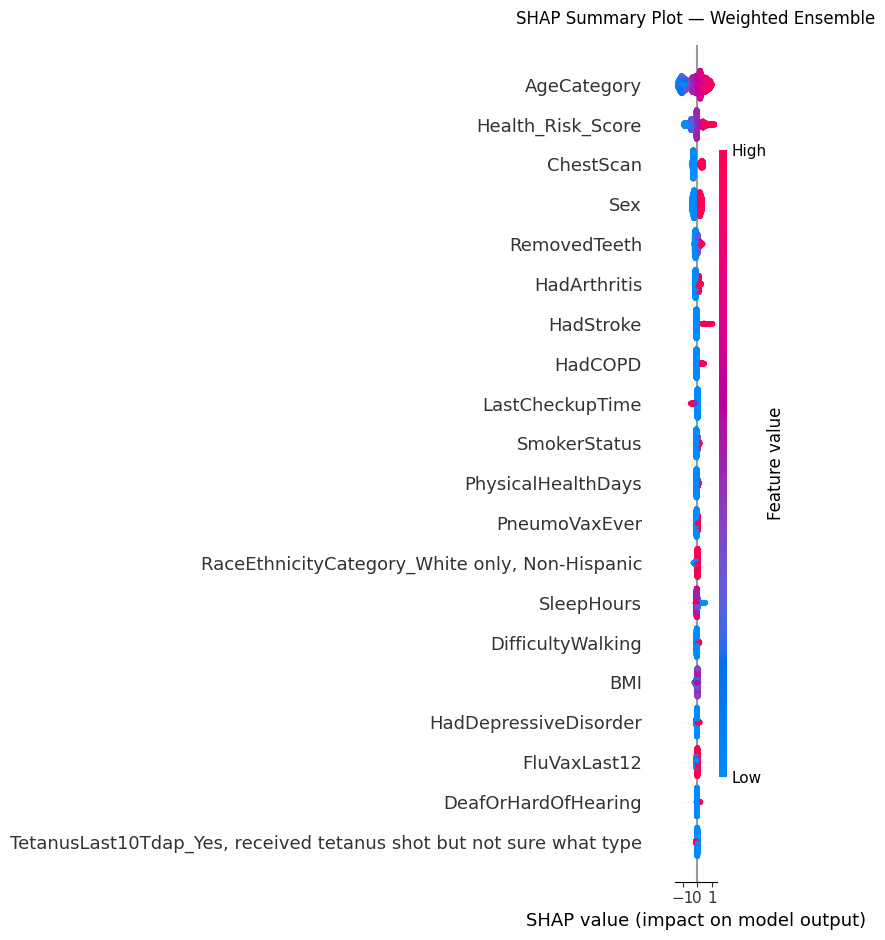

Saved: /content/drive/MyDrive/CVD/figures/figure14_shap_waterfall_patient/figure14_shap_waterfall_patient.pdf and .png


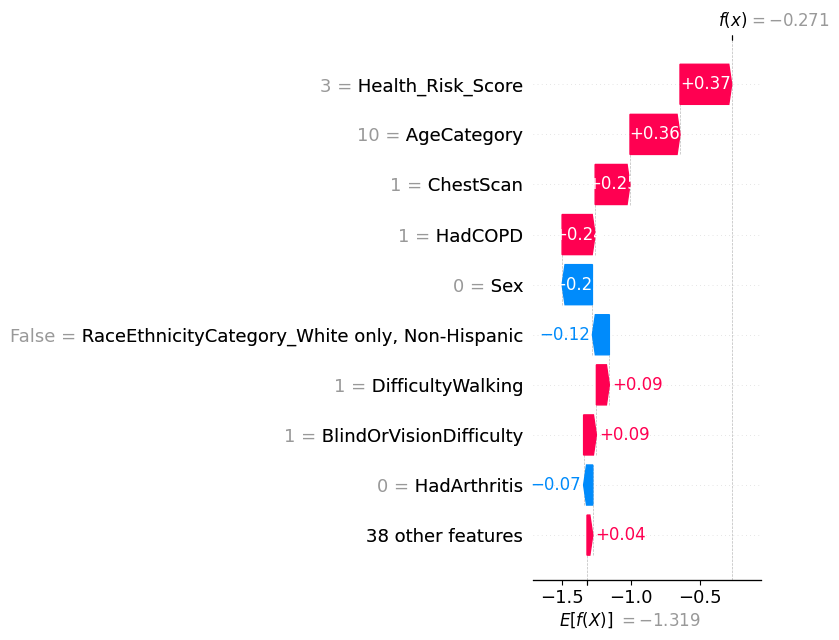

Saved: /content/drive/MyDrive/CVD/figures/figure14b_shap_force_plot/figure14b_shap_force_plot.pdf and .png


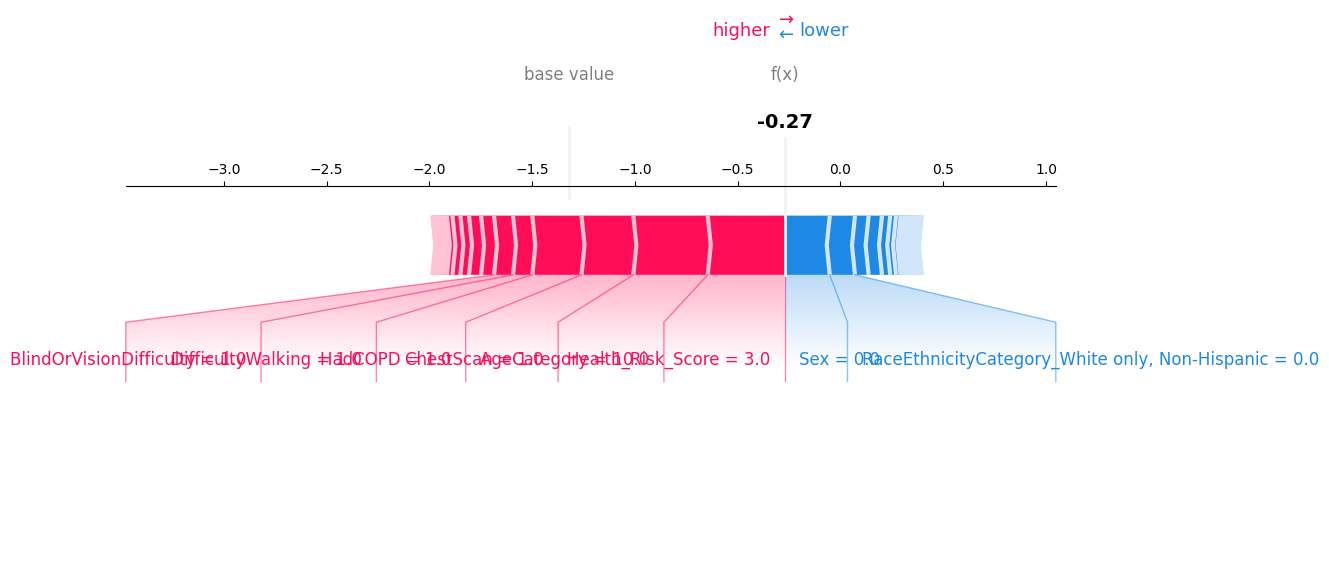

Saved: /content/drive/MyDrive/CVD/figures/figure15_shap_dependence_plot/figure15_shap_dependence_plot.pdf and .png


<Figure size 900x700 with 0 Axes>

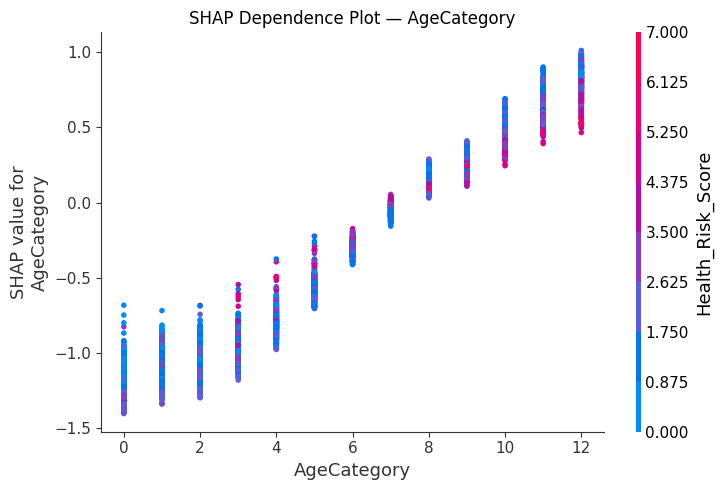

Saved: /content/drive/MyDrive/CVD/figures/figure16_risk_factor_distribution/figure16_risk_factor_distribution.pdf and .png


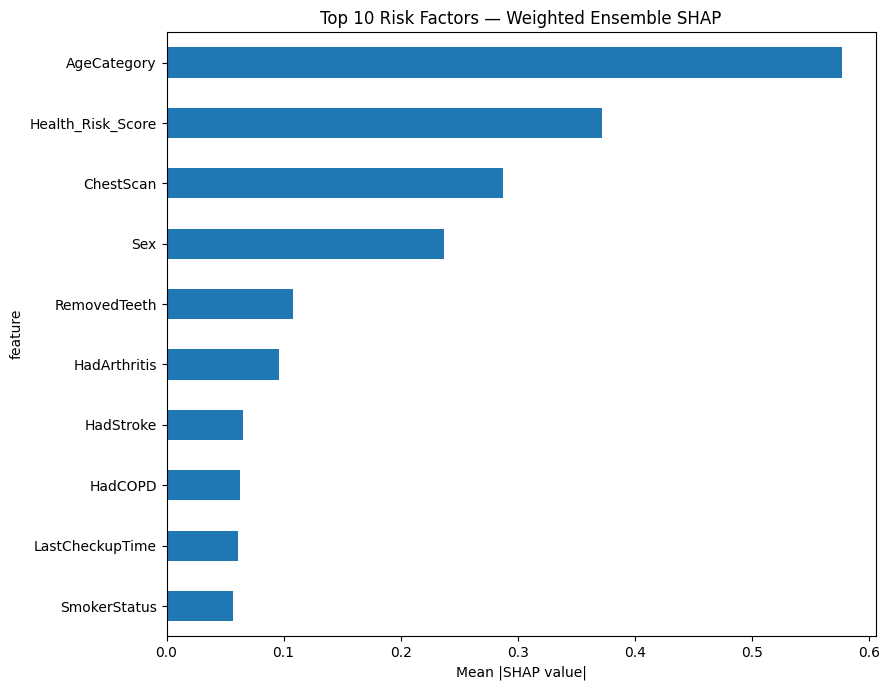

In [ ]:
# ============================================================
# SHAP FIGURES — LOAD SAVED ENSEMBLE SHAP VALUES
# Save + Display all figures
# ============================================================

import shap
import joblib
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Load saved ensemble SHAP values
# ------------------------------------------------------------

shap_ckpt = f'{RESULTS_DIR}/ensemble/ensemble_shap_values.pkl'
base_val_ckpt = f'{RESULTS_DIR}/ensemble/ensemble_shap_base.pkl'

sv = joblib.load(shap_ckpt)
base_values_combined = joblib.load(base_val_ckpt)

print("Loaded ensemble SHAP:", sv.shape)
print("Combined base value:", base_values_combined)

# ------------------------------------------------------------
# 2. Recreate importance table
# ------------------------------------------------------------

importance = pd.DataFrame({
    'feature': X_shap.columns,
    'mean_abs_shap': np.abs(sv).mean(axis=0)
}).sort_values(
    'mean_abs_shap',
    ascending=False
)

print("\nTop 10 SHAP features:")
print(importance.head(10))


# ============================================================
# FIGURE 13 — GLOBAL SHAP SUMMARY
# ============================================================

plt.figure(figsize=(10, 7))

shap.summary_plot(
    sv,
    X_shap,
    show=False
)

plt.title(
    'SHAP Summary Plot — Weighted Ensemble',
    pad=15
)

plt.tight_layout()

save_figure(
    plt.gcf(),
    'figure13_shap_summary_plot'
)

plt.show()


# ============================================================
# FIGURE 14 — SHAP WATERFALL
# ============================================================

local_idx = 0

fig14 = plt.figure(figsize=(10, 7))

explanation = shap.Explanation(
    values=sv[local_idx],
    base_values=base_values_combined,
    data=X_shap.iloc[local_idx].values,
    feature_names=X_shap.columns.tolist()
)

shap.plots.waterfall(
    explanation,
    show=False
)

plt.tight_layout()

save_figure(
    plt.gcf(),
    'figure14_shap_waterfall_patient'
)

plt.show()


# ============================================================
# FIGURE 14b — SHAP FORCE PLOT
# ============================================================

force_folder = fig_folder(
    'figure14b_shap_force_plot'
)

force_fig = shap.force_plot(
    base_values_combined,
    sv[local_idx],
    X_shap.iloc[local_idx],
    matplotlib=True,
    show=False
)

force_fig.set_size_inches(12, 5)

force_fig.savefig(
    f'{force_folder}/figure14b_shap_force_plot.pdf',
    dpi=300,
    bbox_inches='tight'
)

force_fig.savefig(
    f'{force_folder}/figure14b_shap_force_plot.png',
    dpi=300,
    bbox_inches='tight'
)

print(
    f"Saved: {force_folder}/figure14b_shap_force_plot.pdf and .png"
)

plt.show()


# ============================================================
# FIGURE 15 — SHAP DEPENDENCE
# ============================================================

top_feature = importance.iloc[0]['feature']

fig15 = plt.figure(figsize=(9, 7))

shap.dependence_plot(
    top_feature,
    sv,
    X_shap,
    show=False
)

plt.title(
    f'SHAP Dependence Plot — {top_feature}'
)

plt.tight_layout()

save_figure(
    plt.gcf(),
    'figure15_shap_dependence_plot'
)

plt.show()


# ============================================================
# FIGURE 16 — TOP 10 RISK FACTORS
# ============================================================

fig16, ax16 = plt.subplots(figsize=(9, 7))

importance.head(10).plot(
    kind='barh',
    x='feature',
    y='mean_abs_shap',
    ax=ax16,
    legend=False
)

ax16.invert_yaxis()

ax16.set_title(
    'Top 10 Risk Factors — Weighted Ensemble SHAP'
)

ax16.set_xlabel(
    'Mean |SHAP value|'
)

plt.tight_layout()

save_figure(
    fig16,
    'figure16_risk_factor_distribution'
)

plt.show()

Saved: /content/drive/MyDrive/CVD/figures/figure14b_shap_force_plot/figure14b_shap_force_plot.pdf and .png


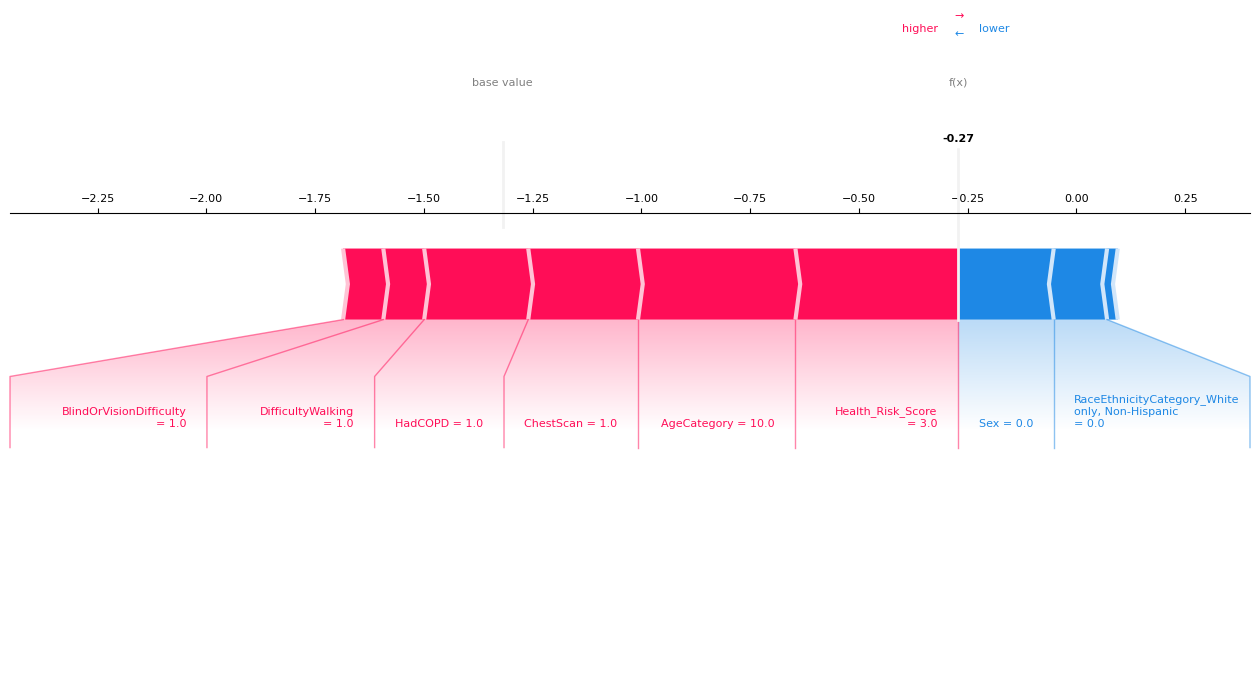

In [ ]:
# ============================================================
# FIGURE 14b — PUBLICATION-QUALITY SHAP FORCE PLOT
# Wrapped feature names + smaller font + no overlap
# ============================================================

import textwrap
import matplotlib.pyplot as plt

local_idx = 0
TOP_N = 8

local_values = sv[local_idx]
local_data = X_shap.iloc[local_idx]

# ------------------------------------------------------------
# 1. Select top contributing features
# ------------------------------------------------------------

top_indices = np.argsort(
    np.abs(local_values)
)[::-1][:TOP_N]

# Keep SHAP contribution order
top_shap = local_values[top_indices]
top_data = local_data.iloc[top_indices].values
top_names = X_shap.columns[top_indices].tolist()


# ------------------------------------------------------------
# 2. Aggregate remaining features
# ------------------------------------------------------------

remaining_indices = np.setdiff1d(
    np.arange(len(local_values)),
    top_indices
)

other_shap = local_values[remaining_indices].sum()

plot_shap = np.append(
    top_shap,
    other_shap
)

plot_data = np.append(
    top_data,
    '—'
)


# ------------------------------------------------------------
# 3. Wrap long feature names
# ------------------------------------------------------------

def wrap_feature_name(name, width=14):
    return textwrap.fill(
        str(name),
        width=width,
        break_long_words=False,
        break_on_hyphens=False
    )

plot_names = [
    wrap_feature_name(name, width=14)
    for name in top_names
]

plot_names.append(
    'Other\nfeatures'
)


# ------------------------------------------------------------
# 4. Create SHAP force plot correctly
# ------------------------------------------------------------

shap.initjs()

force_fig = shap.force_plot(
    base_values_combined,
    plot_shap,
    plot_data,
    feature_names=plot_names,
    matplotlib=True,
    show=False
)


# ------------------------------------------------------------
# 5. Make figure larger
# ------------------------------------------------------------

force_fig.set_size_inches(16, 6)


# ------------------------------------------------------------
# 6. Reduce text size + wrap existing text
# ------------------------------------------------------------

for ax in force_fig.axes:

    ax.tick_params(
        axis='both',
        labelsize=8
    )

    for txt in ax.texts:

        txt.set_fontsize(8)

        # Wrap any long text generated by SHAP
        current_text = txt.get_text()

        if len(current_text) > 16:
            txt.set_text(
                textwrap.fill(
                    current_text,
                    width=18,
                    break_long_words=False,
                    break_on_hyphens=False
                )
            )


# ------------------------------------------------------------
# 7. Save figure
# ------------------------------------------------------------

force_folder = fig_folder(
    'figure14b_shap_force_plot'
)

force_fig.savefig(
    f'{force_folder}/figure14b_shap_force_plot.pdf',
    dpi=300,
    bbox_inches='tight'
)

force_fig.savefig(
    f'{force_folder}/figure14b_shap_force_plot.png',
    dpi=300,
    bbox_inches='tight'
)

print(
    f"Saved: {force_folder}/figure14b_shap_force_plot.pdf and .png"
)


# ------------------------------------------------------------
# 8. Display in Colab
# ------------------------------------------------------------

plt.show()

Full test set: (44514, 47)
SHAP sample: (5000, 47)
SHAP sample class distribution:
HeartDisease
0    0.9108
1    0.0892
Name: proportion, dtype: float64
X_shap_lgbm: (5000, 47)
Indices aligned: True
SHAP checkpoint found — loading.

Top 10 SHAP features:
              feature  mean_abs_shap
24        AgeCategory       0.576976
45  Health_Risk_Score       0.371858
23          ChestScan       0.287588
0                 Sex       0.237403
7        RemovedTeeth       0.108315
14       HadArthritis       0.095666
8           HadStroke       0.065449
11            HadCOPD       0.062870
4     LastCheckupTime       0.061311
21       SmokerStatus       0.056671
Saved: /content/drive/MyDrive/CVD/figures/figure13_shap_summary_plot/figure13_shap_summary_plot.pdf and .png
Saved: /content/drive/MyDrive/CVD/figures/figure14_shap_waterfall_patient/figure14_shap_waterfall_patient.pdf and .png


Saved: /content/drive/MyDrive/CVD/figures/figure14b_shap_force_plot/figure14b_shap_force_plot.pdf and .png
Saved: /content/drive/MyDrive/CVD/figures/figure15_shap_dependence_plot/figure15_shap_dependence_plot.pdf and .png
Saved: /content/drive/MyDrive/CVD/figures/figure16_risk_factor_distribution/figure16_risk_factor_distribution.pdf and .png


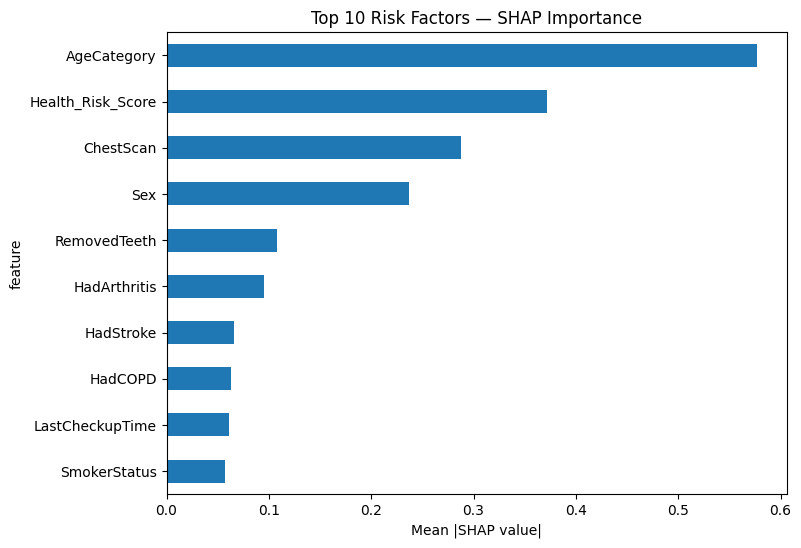

In [ ]:
# nononochkkin============================================================
# SHAP: Global + Local Explainability
# Representative stratified test sample
# ============================================================

import shap
import numpy as np
import pandas as pd
import joblib
import os

# ------------------------------------------------------------
# 1. Create a representative stratified sample from TEST set
# ------------------------------------------------------------

SHAP_SAMPLE_SIZE = 5000

# Keep class proportions representative
from sklearn.model_selection import train_test_split

X_shap, _, y_shap, _ = train_test_split(
    X_test,
    y_test,
    test_size=max(0, len(X_test) - SHAP_SAMPLE_SIZE),
    stratify=y_test,
    random_state=42
)

print("Full test set:", X_test.shape)
print("SHAP sample:", X_shap.shape)
print("SHAP sample class distribution:")
print(y_shap.value_counts(normalize=True))


# ------------------------------------------------------------
# 2. LightGBM needs sanitized feature names
# ------------------------------------------------------------
X_shap_lgbm = X_test_lgbm.loc[X_shap.index].copy()
print("X_shap_lgbm:", X_shap_lgbm.shape)
print("Indices aligned:", X_shap.index.equals(X_shap_lgbm.index))


# ------------------------------------------------------------
# 3. Checkpoint paths
# ------------------------------------------------------------

shap_ckpt = f'{RESULTS_DIR}/ensemble/ensemble_shap_values.pkl'
base_val_ckpt = f'{RESULTS_DIR}/ensemble/ensemble_shap_base.pkl'


# ------------------------------------------------------------
# 4. Compute SHAP for each selected base model
# ------------------------------------------------------------

if os.path.exists(shap_ckpt):

    print("SHAP checkpoint found — loading.")

    sv = joblib.load(shap_ckpt)
    base_values_combined = joblib.load(base_val_ckpt)

else:

    per_model_shap = {}
    per_model_base = {}

    X_shap_map = {
        'random_forest': X_shap,
        'xgboost': X_shap,
        'catboost': X_shap,
        'lightgbm': X_shap_lgbm
    }

    for name, model in base_models.items():

        print(f"[{name}] Computing SHAP...")

        explainer = shap.TreeExplainer(model)

        s = explainer.shap_values(X_shap_map[name])

        if isinstance(s, list):
            s = s[1]

        bv = explainer.expected_value

        if isinstance(bv, (list, np.ndarray)):
            bv = bv[1]

        per_model_shap[name] = s
        per_model_base[name] = bv

        print(f"[{name}] SHAP completed.")


    # --------------------------------------------------------
    # 5. Weighted ensemble SHAP
    # --------------------------------------------------------

    sv = np.zeros_like(
        per_model_shap['random_forest'],
        dtype=float
    )

    base_values_combined = 0.0

    for name in base_models:

        sv += (
            ensemble_weights[name]
            * per_model_shap[name]
        )

        base_values_combined += (
            ensemble_weights[name]
            * per_model_base[name]
        )


    # --------------------------------------------------------
    # 6. Save checkpoint
    # --------------------------------------------------------

    joblib.dump(sv, shap_ckpt)
    joblib.dump(base_values_combined, base_val_ckpt)

    print("Ensemble-level SHAP values saved.")


# ============================================================
# TABLE 10 — Global SHAP Feature Importance
# ============================================================

importance = pd.DataFrame({
    'feature': X_shap.columns,
    'mean_abs_shap': np.abs(sv).mean(axis=0)
})

importance = importance.sort_values(
    'mean_abs_shap',
    ascending=False
)

t10_folder = fig_folder(
    'table10_global_shap_importance'
)

importance.to_csv(
    f'{t10_folder}/table10_global_shap_importance.csv',
    index=False
)

print("\nTop 10 SHAP features:")
print(importance.head(10))


# ============================================================
# TABLE 11 — Risk Factor Importance
# ============================================================

t11_folder = fig_folder(
    'table11_risk_factor_importance'
)

importance.head(10).to_csv(
    f'{t11_folder}/table11_risk_factor_importance.csv',
    index=False
)


# ============================================================
# FIGURE 13 — SHAP Summary Plot
# ============================================================

fig13 = plt.figure(figsize=(9,7))

shap.summary_plot(
    sv,
    X_shap,
    show=False
)

save_figure(
    fig13,
    'figure13_shap_summary_plot'
)

plt.close(fig13)


# ============================================================
# FIGURE 14 — Local SHAP Waterfall
# ============================================================

# First test patient from the SHAP sample
local_idx = 0

fig14 = plt.figure(figsize=(10,7))

shap.plots.waterfall(
    shap.Explanation(
        values=sv[local_idx],
        base_values=base_values_combined,
        data=X_shap.iloc[local_idx],
        feature_names=X_shap.columns
    ),
    show=False
)

save_figure(
    fig14,
    'figure14_shap_waterfall_patient'
)

plt.close(fig14)


# ============================================================
# FIGURE 14b — SHAP Force Plot
# ============================================================

shap.initjs()

force_fig = shap.force_plot(
    base_values_combined,
    sv[local_idx],
    X_shap.iloc[local_idx],
    matplotlib=True,
    show=False
)

force_folder = fig_folder(
    'figure14b_shap_force_plot'
)

force_fig.savefig(
    f'{force_folder}/figure14b_shap_force_plot.pdf',
    dpi=300,
    bbox_inches='tight'
)

force_fig.savefig(
    f'{force_folder}/figure14b_shap_force_plot.png',
    dpi=300,
    bbox_inches='tight'
)

print(
    f"Saved: {force_folder}/figure14b_shap_force_plot.pdf and .png"
)

plt.close(force_fig)


# ============================================================
# FIGURE 15 — SHAP Dependence Plot
# ============================================================

top_feature = importance.iloc[0]['feature']

fig15, ax15 = plt.subplots(
    figsize=(8,6)
)

shap.dependence_plot(
    top_feature,
    sv,
    X_shap,
    ax=ax15,
    show=False
)

ax15.set_title(
    f'SHAP Dependence Plot — {top_feature}'
)

save_figure(
    fig15,
    'figure15_shap_dependence_plot'
)

plt.close(fig15)


# ============================================================
# FIGURE 16 — Top 10 Risk Factors
# ============================================================

fig16, ax16 = plt.subplots(
    figsize=(8,6)
)

importance.head(10).plot(
    kind='barh',
    x='feature',
    y='mean_abs_shap',
    ax=ax16,
    legend=False
)

ax16.invert_yaxis()

ax16.set_title(
    'Top 10 Risk Factors — SHAP Importance'
)

ax16.set_xlabel(
    'Mean |SHAP value|'
)

save_figure(
    fig16,
    'figure16_risk_factor_distribution'
)

plt.show()




In [ ]:
# NONONO============================================================
# FIX SHAP OUTPUT SHAPE + BUILD ENSEMBLE SHAP
# ============================================================

# Convert every model's SHAP output to (samples, features)
# for binary classification.

for name in per_model_shap:

    s = per_model_shap[name]

    print(name, "original SHAP shape:", s.shape)

    # Newer SHAP versions may return:
    # (n_samples, n_features, 2)
    if s.ndim == 3 and s.shape[2] == 2:
        s = s[:, :, 1]

    # Older SHAP versions may return:
    # (n_samples, n_features, 2) in another orientation
    elif s.ndim == 3 and s.shape[1] == 2:
        s = s[:, 1, :]

    if s.ndim != 2:
        raise ValueError(
            f"{name} SHAP has unexpected shape: {s.shape}"
        )

    per_model_shap[name] = s

    print(name, "fixed SHAP shape:", s.shape)


# ------------------------------------------------------------
# Check that all models have identical shape
# ------------------------------------------------------------

shapes = {
    name: value.shape
    for name, value in per_model_shap.items()
}

print("\nSHAP shapes after fixing:")
print(shapes)


# ------------------------------------------------------------
# Build weighted ensemble SHAP
# ------------------------------------------------------------

first_model = next(iter(per_model_shap))

sv = np.zeros_like(
    per_model_shap[first_model],
    dtype=float
)

base_values_combined = 0.0

for name in base_models:

    sv += (
        float(ensemble_weights[name])
        * per_model_shap[name]
    )

    base_values_combined += (
        float(ensemble_weights[name])
        * float(per_model_base[name])
    )


print("\nFinal ensemble SHAP shape:", sv.shape)
print("Combined base value:", base_values_combined)


# ------------------------------------------------------------
# Save corrected SHAP checkpoint
# ------------------------------------------------------------

joblib.dump(sv, shap_ckpt)
joblib.dump(
    base_values_combined,
    base_val_ckpt
)

print("Corrected ensemble SHAP values saved successfully.")

NameError: name 'per_model_shap' is not defined

In [ ]:
# NONON============================================================
# VERIFY SAVED ENSEMBLE SHAP
# ============================================================

import joblib
import numpy as np
import os

shap_ckpt = f'{RESULTS_DIR}/ensemble/newensemble_shap_values.pkl'
base_val_ckpt = f'{RESULTS_DIR}/ensemble/newensemble_shap_base.pkl'

sv = joblib.load(shap_ckpt)
base_values_combined = joblib.load(base_val_ckpt)

print("Loaded ensemble SHAP shape:", sv.shape)
print("Expected shape:", X_shap.shape)
print("Base value:", base_values_combined)

assert sv.shape == X_shap.shape, \
    f"Shape mismatch: SHAP={sv.shape}, X_shap={X_shap.shape}"

print("\n✅ SHAP checkpoint is valid.")
print("✅ Ensemble SHAP has correct 2D shape.")
print("✅ No need to recompute SHAP.")

Loaded ensemble SHAP shape: (5000, 47)
Expected shape: (5000, 47)
Base value: -1.4178198856347868

✅ SHAP checkpoint is valid.
✅ Ensemble SHAP has correct 2D shape.
✅ No need to recompute SHAP.


In [ ]:
# ============================================================
# RESTORE X_shap_lgbm FOR SHAP ADDITIVITY AUDIT
# ============================================================

print("=" * 60)
print("RESTORING X_shap_lgbm")
print("=" * 60)

# X_shap must already exist because it was used to generate
# newensemble_shap_values.pkl
if 'X_shap' not in globals():
    raise NameError(
        "X_shap is missing. Please run the original SHAP sample "
        "creation cell first."
    )

# X_test_lgbm must already exist because LightGBM uses its
# own feature representation in your notebook
if 'X_test_lgbm' not in globals():
    raise NameError(
        "X_test_lgbm is missing. Please run the LightGBM preprocessing/"
        "test-data preparation cell first."
    )

# Reconstruct exactly as in your original SHAP code
X_shap_lgbm = X_test_lgbm.loc[X_shap.index].copy()

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("X_shap shape:       ", X_shap.shape)
print("X_shap_lgbm shape:  ", X_shap_lgbm.shape)

print(
    "Indices aligned:    ",
    X_shap.index.equals(X_shap_lgbm.index)
)

if not X_shap.index.equals(X_shap_lgbm.index):
    raise ValueError(
        "X_shap and X_shap_lgbm indices are NOT aligned."
    )

if len(X_shap) != len(X_shap_lgbm):
    raise ValueError(
        "X_shap and X_shap_lgbm have different numbers of rows."
    )

print("\nX_shap_lgbm successfully restored.")

RESTORING X_shap_lgbm
X_shap shape:        (5000, 47)
X_shap_lgbm shape:   (5000, 47)
Indices aligned:     True

X_shap_lgbm successfully restored.


In [ ]:
# ============================================================
# SHAP VALIDITY / ADDITIVITY AUDIT
# FOR CURRENT newensemble SHAP CHECKPOINT
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("=" * 60)
print("SHAP VALIDITY / ADDITIVITY AUDIT")
print("=" * 60)

# ------------------------------------------------------------
# 1. CURRENT SHAP CHECKPOINT
# ------------------------------------------------------------
SHAP_VALUES_CKPT = f'{RESULTS_DIR}/ensemble/newensemble_shap_values.pkl'
SHAP_BASE_CKPT = f'{RESULTS_DIR}/ensemble/newensemble_shap_base.pkl'

assert os.path.exists(SHAP_VALUES_CKPT), (
    f"SHAP values checkpoint not found:\n{SHAP_VALUES_CKPT}"
)

assert os.path.exists(SHAP_BASE_CKPT), (
    f"SHAP base checkpoint not found:\n{SHAP_BASE_CKPT}"
)

# ------------------------------------------------------------
# 2. LOAD SAVED SHAP
# ------------------------------------------------------------
sv = joblib.load(SHAP_VALUES_CKPT)
base_values_combined = joblib.load(SHAP_BASE_CKPT)

print("Loaded SHAP:", sv.shape)
print("Loaded base value:", base_values_combined)

# ------------------------------------------------------------
# 3. VERIFY REQUIRED VARIABLES FROM YOUR NOTEBOOK
# ------------------------------------------------------------
required_vars = [
    'X_shap',
    'X_shap_lgbm',
    'base_models',
    'ensemble_weights'
]

missing_vars = [v for v in required_vars if v not in globals()]

if missing_vars:
    raise NameError(
        "These notebook variables are missing: "
        + ", ".join(missing_vars)
        + "\n\nRun the original SHAP setup/model cells first."
    )

print("\nNotebook variables found:")
print("X_shap:", X_shap.shape)
print("X_shap_lgbm:", X_shap_lgbm.shape)
print("base_models:", list(base_models.keys()))
print("ensemble_weights:", ensemble_weights)

# ------------------------------------------------------------
# 4. BASIC SHAP SHAPE CHECK
# ------------------------------------------------------------
assert sv.ndim == 2, (
    f"Expected 2D SHAP array, got {sv.ndim}D: {sv.shape}"
)

assert sv.shape == X_shap.shape, (
    f"SHAP/X_shap mismatch: {sv.shape} vs {X_shap.shape}"
)

assert X_shap.index.equals(X_shap_lgbm.index), (
    "X_shap and X_shap_lgbm indices are not aligned."
)

print("\nShape checks: PASSED")

# ------------------------------------------------------------
# 5. RECONSTRUCT THE OUTPUT REPRESENTED BY SAVED SHAP
# ------------------------------------------------------------
reconstructed_output = (
    float(base_values_combined)
    + np.sum(sv, axis=1)
)

print("\nReconstructed SHAP output:")
print("Min:", reconstructed_output.min())
print("Max:", reconstructed_output.max())
print("Mean:", reconstructed_output.mean())

print(
    "Is reconstructed output in [0,1]?:",
    bool(
        np.all(
            (reconstructed_output >= 0)
            & (reconstructed_output <= 1)
        )
    )
)

# ------------------------------------------------------------
# 6. RE-COMPUTE ACTUAL WEIGHTED ENSEMBLE PROBABILITY
#    USING THE EXACT SAME INPUT LOGIC AS YOUR NOTEBOOK
# ------------------------------------------------------------
actual_ensemble_output = np.zeros(len(X_shap), dtype=float)

for name, model in base_models.items():

    if name == 'lightgbm':
        Xin = X_shap_lgbm
    else:
        Xin = X_shap

    model_proba = model.predict_proba(Xin)[:, 1]

    actual_ensemble_output += (
        float(ensemble_weights[name]) * model_proba
    )

# ------------------------------------------------------------
# 7. COMPARE SHAP RECONSTRUCTION VS ACTUAL ENSEMBLE PROBABILITY
# ------------------------------------------------------------
mae = mean_absolute_error(
    actual_ensemble_output,
    reconstructed_output
)

rmse = np.sqrt(
    mean_squared_error(
        actual_ensemble_output,
        reconstructed_output
    )
)

correlation = np.corrcoef(
    actual_ensemble_output,
    reconstructed_output
)[0, 1]

max_abs_error = np.max(
    np.abs(
        actual_ensemble_output
        - reconstructed_output
    )
)

print("\n" + "=" * 60)
print("ADDITIVITY / OUTPUT COMPARISON")
print("=" * 60)

print("Actual ensemble probability:")
print("Min:", actual_ensemble_output.min())
print("Max:", actual_ensemble_output.max())
print("Mean:", actual_ensemble_output.mean())

print("\nSHAP reconstruction:")
print("Min:", reconstructed_output.min())
print("Max:", reconstructed_output.max())
print("Mean:", reconstructed_output.mean())

print("\nDifference metrics:")
print("MAE:", mae)
print("RMSE:", rmse)
print("Correlation:", correlation)
print("Max absolute error:", max_abs_error)

# ------------------------------------------------------------
# 8. SAMPLE-WISE COMPARISON
# ------------------------------------------------------------
audit_table = pd.DataFrame({
    'actual_ensemble_probability': actual_ensemble_output,
    'shap_reconstructed_output': reconstructed_output,
    'absolute_error': np.abs(
        actual_ensemble_output
        - reconstructed_output
    )
})

print("\nFirst 10 observations:")
print(audit_table.head(10))

# ------------------------------------------------------------
# 9. INTERPRETATION
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("AUDIT INTERPRETATION")
print("=" * 60)

if correlation >= 0.99 and mae < 0.01:
    print(
        "PASS: SHAP reconstruction closely matches "
        "the actual weighted ensemble output."
    )

elif correlation >= 0.95 and mae < 0.05:
    print(
        "PARTIAL: SHAP reconstruction is strongly correlated "
        "with the ensemble, but there is a noticeable "
        "output-scale/additivity difference."
    )

else:
    print(
        "WARNING: Saved aggregated SHAP values do not "
        "closely reconstruct the final ensemble probability."
    )

print("=" * 60)

SHAP VALIDITY / ADDITIVITY AUDIT
Loaded SHAP: (5000, 47)
Loaded base value: -1.4178198856347868

Notebook variables found:
X_shap: (5000, 47)
X_shap_lgbm: (5000, 47)
base_models: ['random_forest', 'xgboost', 'lightgbm', 'catboost']
ensemble_weights: {'random_forest': np.float64(0.21232062304580207), 'xgboost': np.float64(0.2663098920982783), 'lightgbm': np.float64(0.2548131058368417), 'catboost': np.float64(0.2665563790190779)}

Shape checks: PASSED

Reconstructed SHAP output:
Min: -4.623260730091667
Max: 1.5804513213594558
Mean: -1.9143176100853154
Is reconstructed output in [0,1]?: False

ADDITIVITY / OUTPUT COMPARISON
Actual ensemble probability:
Min: 0.015022139884660904
Max: 0.7673836022851583
Mean: 0.2572663512653519

SHAP reconstruction:
Min: -4.623260730091667
Max: 1.5804513213594558
Mean: -1.9143176100853154

Difference metrics:
MAE: 2.1805858268286165
RMSE: 2.4592468916250874
Correlation: 0.9795329247692226
Max absolute error: 4.638389699635057

First 10 observations:
   actu

In [ ]:
# ================================================================
# DIAGNOSE SAVED SHAP FILE FORMAT
# ================================================================

import os

SHAP_DIR = "/content/drive/MyDrive/CVD/results/ensemble"

files = [
    "newensemble_probability_shap_X.pkl",
    "newensemble_probability_shap_values.pkl",
    "newensemble_probability_shap_base.pkl",
]

print("=" * 70)
print("DIAGNOSING SAVED SHAP FILES")
print("=" * 70)

for fname in files:

    path = os.path.join(SHAP_DIR, fname)

    print("\n" + "-" * 70)
    print(fname)

    if not os.path.exists(path):
        print("FILE NOT FOUND")
        continue

    size_mb = os.path.getsize(path) / (1024 * 1024)
    print("Size:", round(size_mb, 3), "MB")

    with open(path, "rb") as f:
        header = f.read(32)

    print("First 32 bytes:", header)
    print("Hex:", header.hex())

    # Detect common formats
    if header.startswith(b"\x80"):
        print("Possible: Python pickle")

    elif header.startswith(b"\x1f\x8b"):
        print("Possible: GZIP compressed")

    elif header.startswith(b"PK"):
        print("Possible: ZIP / compressed archive")

    elif header.startswith(b"BZh"):
        print("Possible: BZIP2 compressed")

    elif header.startswith(b"\xfd7zXZ"):
        print("Possible: LZMA/XZ compressed")

    else:
        print("Format not immediately recognized.")

print("\n" + "=" * 70)
print("DIAGNOSTIC COMPLETE")
print("=" * 70)

DIAGNOSING SAVED SHAP FILES

----------------------------------------------------------------------
newensemble_probability_shap_X.pkl
Size: 0.152 MB
First 32 bytes: b'\x80\x04\x95c\x01\x00\x00\x00\x00\x00\x00\x8c\x11pandas.core.frame\x94\x8c'
Hex: 80049563010000000000008c1170616e6461732e636f72652e6672616d65948c
Possible: Python pickle

----------------------------------------------------------------------
newensemble_probability_shap_values.pkl
Size: 0.18 MB
First 32 bytes: b'\x80\x04\x95\xd4\x00\x00\x00\x00\x00\x00\x00\x8c\x13joblib.numpy_pickle'
Hex: 800495d4000000000000008c136a6f626c69622e6e756d70795f7069636b6c65
Possible: Python pickle

----------------------------------------------------------------------
newensemble_probability_shap_base.pkl
Size: 0.0 MB
First 32 bytes: b'\x80\x04\x95\n\x00\x00\x00\x00\x00\x00\x00G?\xcf\xbf\xb9\x94Ut-.'
Hex: 8004950a00000000000000473fcfbfb99455742d2e
Possible: Python pickle

DIAGNOSTIC COMPLETE


In [ ]:
# ================================================================
# LOAD SAVED PROBABILITY-SHAP RESULTS + ALIGN TRUE LABELS
# ================================================================

import os
import numpy as np
import pandas as pd
import joblib

print("=" * 70)
print("LOADING SAVED PROBABILITY-SHAP RESULTS")
print("=" * 70)

SHAP_DIR = "/content/drive/MyDrive/CVD/results/ensemble"

# ------------------------------------------------
# 1. Load saved files with joblib
# ------------------------------------------------

X_explain = joblib.load(
    os.path.join(
        SHAP_DIR,
        "newensemble_probability_shap_X.pkl"
    )
)

shap_values = joblib.load(
    os.path.join(
        SHAP_DIR,
        "newensemble_probability_shap_values.pkl"
    )
)

shap_base = joblib.load(
    os.path.join(
        SHAP_DIR,
        "newensemble_probability_shap_base.pkl"
    )
)

# Ensure DataFrame
if not isinstance(X_explain, pd.DataFrame):
    X_explain = pd.DataFrame(X_explain)

shap_values = np.asarray(shap_values)
shap_base = float(shap_base)

print("\nLoaded successfully!")

print("X_explain:", X_explain.shape)
print("SHAP values:", shap_values.shape)
print("SHAP base:", shap_base)

# ------------------------------------------------
# 2. Verify dimensions
# ------------------------------------------------

assert X_explain.shape == shap_values.shape, (
    f"Mismatch: X={X_explain.shape}, "
    f"SHAP={shap_values.shape}"
)

assert X_explain.shape[0] == 500, (
    f"Expected 500 SHAP cases, got {X_explain.shape[0]}"
)

print("\nDimension check: PASS")

# ------------------------------------------------
# 3. Check original 5000-row SHAP sample
# ------------------------------------------------

print("\nChecking original SHAP sample variables...")

if "X_shap" not in globals():
    raise NameError(
        "X_shap is not available in the notebook."
    )

if "y_shap" not in globals():
    raise NameError(
        "y_shap is not available in the notebook."
    )

X_reference = X_shap.copy()
y_reference = np.asarray(y_shap).reshape(-1)

print("X_shap:", X_reference.shape)
print("y_shap:", y_reference.shape)

# ------------------------------------------------
# 4. Align columns
# ------------------------------------------------

if set(X_explain.columns) != set(X_reference.columns):
    missing = [
        c for c in X_explain.columns
        if c not in X_reference.columns
    ]

    extra = [
        c for c in X_reference.columns
        if c not in X_explain.columns
    ]

    print("\nMissing columns:", missing)
    print("Extra columns:", extra)

    raise ValueError(
        "X_explain and X_shap do not contain identical features."
    )

# Put reference in exactly same order
X_reference = X_reference[X_explain.columns]

print(
    "\nFeature alignment:",
    list(X_explain.columns) == list(X_reference.columns)
)

# ------------------------------------------------
# 5. Match 500 saved cases to original 5000 cases
# ------------------------------------------------

print("\nMatching saved 500 SHAP cases to original 5000 cases...")

X_ref_np = X_reference.to_numpy(dtype=float)
X_exp_np = X_explain.to_numpy(dtype=float)

matched_indices = []

for i in range(len(X_exp_np)):

    row = X_exp_np[i]

    matches = np.where(
        np.all(
            np.isclose(
                X_ref_np,
                row,
                rtol=1e-10,
                atol=1e-12,
                equal_nan=True
            ),
            axis=1
        )
    )[0]

    if len(matches) == 0:
        raise ValueError(
            f"Could not match saved SHAP case {i}."
        )

    if len(matches) > 1:
        raise ValueError(
            f"Multiple matches found for case {i}."
        )

    matched_indices.append(matches[0])

matched_indices = np.asarray(matched_indices)

print("Matched:", len(matched_indices))
print("Unique:", len(np.unique(matched_indices)))

assert len(matched_indices) == 500
assert len(np.unique(matched_indices)) == 500

# ------------------------------------------------
# 6. Extract TRUE labels
# ------------------------------------------------

y_explain = y_reference[matched_indices]

print("\nTrue labels successfully aligned!")

print("y_explain shape:", y_explain.shape)

print("\nTrue-label distribution:")
print(
    pd.Series(y_explain)
    .value_counts()
    .sort_index()
)

print("\nTrue-label proportions:")
print(
    pd.Series(y_explain)
    .value_counts(normalize=True)
    .sort_index()
)

# ------------------------------------------------
# 7. Reconstruct ensemble probabilities
# ------------------------------------------------

reconstructed_probability = (
    shap_base +
    shap_values.sum(axis=1)
)

print("\nProbability reconstruction:")
print(
    "Min:",
    reconstructed_probability.min()
)

print(
    "Max:",
    reconstructed_probability.max()
)

# ------------------------------------------------
# 8. Final F1-constrained threshold
# ------------------------------------------------

FINAL_THRESHOLD = 0.364586

predicted_class = (
    reconstructed_probability >= FINAL_THRESHOLD
).astype(int)

print("\nFinal threshold:", FINAL_THRESHOLD)

print("\nPredicted distribution:")
print(
    pd.Series(predicted_class)
    .value_counts()
    .sort_index()
)

# ------------------------------------------------
# 9. Identify False Negatives
# ------------------------------------------------

false_negative_mask = (
    (y_explain == 1) &
    (predicted_class == 0)
)

fn_indices = np.where(false_negative_mask)[0]

print("\n" + "=" * 70)
print("FALSE NEGATIVE ANALYSIS")
print("=" * 70)

print("Total False Negatives:", len(fn_indices))

if len(fn_indices) > 0:

    # Select the FN with lowest predicted probability
    fn_idx = fn_indices[
        np.argmin(
            reconstructed_probability[fn_indices]
        )
    ]

    print("\nSelected False Negative")
    print("-" * 40)
    print("SHAP case index:", fn_idx)
    print("True label:", y_explain[fn_idx])
    print(
        "Predicted probability:",
        reconstructed_probability[fn_idx]
    )
    print(
        "Predicted class:",
        predicted_class[fn_idx]
    )

    print("\nFeature values:")
    display(
        X_explain.iloc[[fn_idx]]
        .T
        .rename(columns={fn_idx: "Value"})
    )

else:

    print(
        "\nNo False Negatives were found "
        "among the 500 saved SHAP cases."
    )

print("\n" + "=" * 70)
print("COMPLETE")
print("=" * 70)

LOADING SAVED PROBABILITY-SHAP RESULTS

Loaded successfully!
X_explain: (500, 47)
SHAP values: (500, 47)
SHAP base: 0.248038480213752

Dimension check: PASS

Checking original SHAP sample variables...
X_shap: (5000, 47)
y_shap: (5000,)

Feature alignment: True

Matching saved 500 SHAP cases to original 5000 cases...
Matched: 500
Unique: 500

True labels successfully aligned!
y_explain shape: (500,)

True-label distribution:
0    455
1     45
Name: count, dtype: int64

True-label proportions:
0    0.91
1    0.09
Name: proportion, dtype: float64

Probability reconstruction:
Min: 0.015022139884660918
Max: 0.7673836022851585

Final threshold: 0.364586

Predicted distribution:
0    328
1    172
Name: count, dtype: int64

FALSE NEGATIVE ANALYSIS
Total False Negatives: 8

Selected False Negative
----------------------------------------
SHAP case index: 356
True label: 1
Predicted probability: 0.08585768120647161
Predicted class: 0

Feature values:


,49718
Sex,1
GeneralHealth,1
PhysicalHealthDays,0.319049
MentalHealthDays,-0.03731
LastCheckupTime,2
PhysicalActivities,1
SleepHours,-0.683586
RemovedTeeth,0
HadStroke,0
HadAsthma,0



COMPLETE


FALSE NEGATIVE SHAP EXPLANATION
Case index: 356
True label: 1
Predicted class: 0
Predicted probability: 0.08585768120647161
Threshold: 0.364586


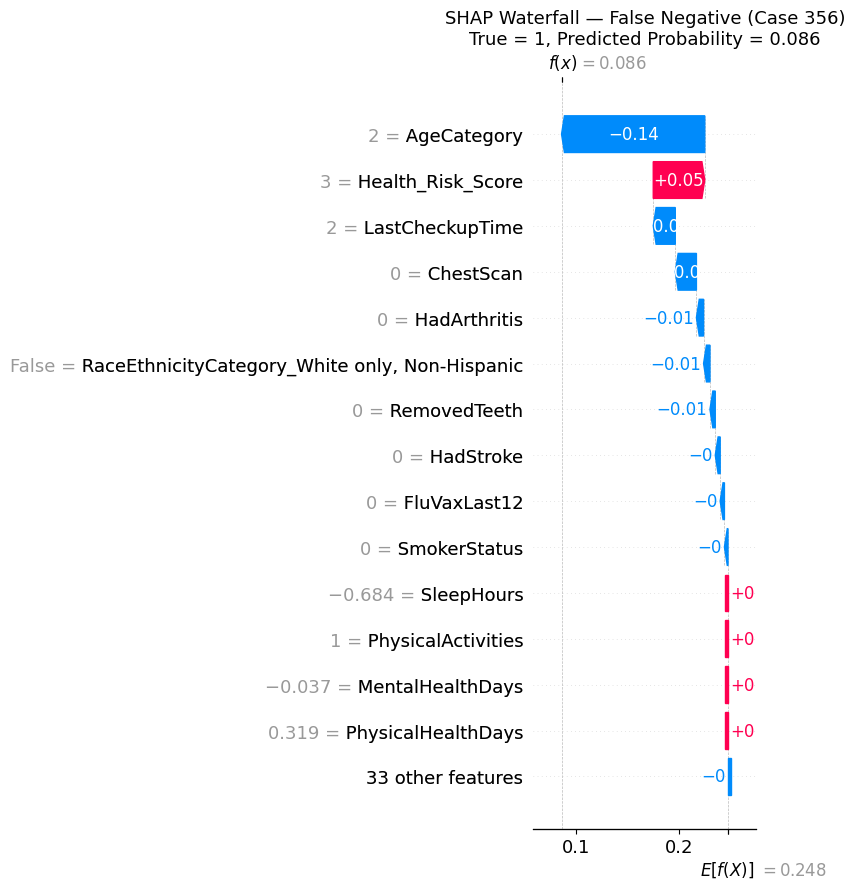


Waterfall saved:
/content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_false_negative_waterfall.png


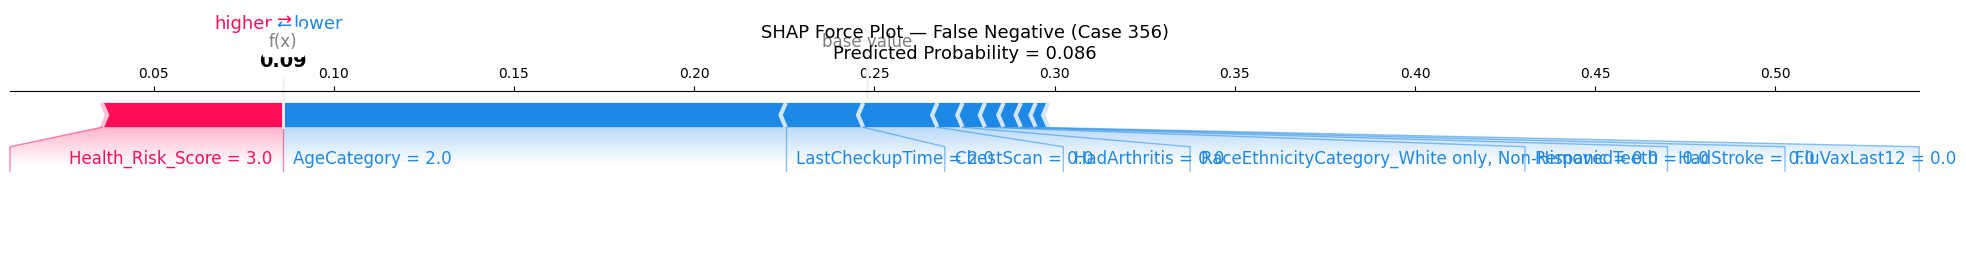


Force plot saved:
/content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_false_negative_force.png

TOP 15 CONTRIBUTIONS FOR FALSE NEGATIVE


,Feature,Feature_Value,SHAP_Value
24,AgeCategory,2,-0.139554
45,Health_Risk_Score,3,0.050205
4,LastCheckupTime,2,-0.021482
23,ChestScan,0,-0.020583
14,HadArthritis,0,-0.006976
37,"RaceEthnicityCategory_White only, Non-Hispanic",False,-0.006231
7,RemovedTeeth,0,-0.005153
8,HadStroke,0,-0.004804
30,FluVaxLast12,0,-0.004125
21,SmokerStatus,0,-0.003478



FEATURES PUSHING RISK UP


,Feature,Feature_Value,SHAP_Value
45,Health_Risk_Score,3,0.050205



FEATURES PUSHING RISK DOWN


,Feature,Feature_Value,SHAP_Value
24,AgeCategory,2,-0.139554
4,LastCheckupTime,2,-0.021482
23,ChestScan,0,-0.020583
14,HadArthritis,0,-0.006976
37,"RaceEthnicityCategory_White only, Non-Hispanic",False,-0.006231
7,RemovedTeeth,0,-0.005153
8,HadStroke,0,-0.004804
30,FluVaxLast12,0,-0.004125
21,SmokerStatus,0,-0.003478



Contribution table saved:
/content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_false_negative_contributions.csv

FALSE NEGATIVE SHAP ANALYSIS COMPLETE


In [ ]:
# ================================================================
# FALSE NEGATIVE SHAP EXPLANATION
# WATERFALL + FORCE PLOT
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

SHAP_DIR = "/content/drive/MyDrive/CVD/results/ensemble"

# ------------------------------------------------
# 1. Use already-loaded SHAP objects
# ------------------------------------------------

fn_idx = 356

X_fn = X_explain.iloc[fn_idx]
shap_fn = np.asarray(shap_values[fn_idx])

pred_prob_fn = float(reconstructed_probability[fn_idx])
true_label_fn = int(y_explain[fn_idx])
pred_class_fn = int(predicted_class[fn_idx])

print("=" * 70)
print("FALSE NEGATIVE SHAP EXPLANATION")
print("=" * 70)

print("Case index:", fn_idx)
print("True label:", true_label_fn)
print("Predicted class:", pred_class_fn)
print("Predicted probability:", pred_prob_fn)
print("Threshold:", FINAL_THRESHOLD)

# ------------------------------------------------
# 2. Create SHAP Explanation object
# ------------------------------------------------

explanation_fn = shap.Explanation(
    values=shap_fn,
    base_values=shap_base,
    data=X_fn.values,
    feature_names=X_explain.columns.tolist()
)

# ------------------------------------------------
# 3. WATERFALL PLOT
# ------------------------------------------------

plt.figure(figsize=(10, 8))

shap.plots.waterfall(
    explanation_fn,
    max_display=15,
    show=False
)

plt.title(
    f"SHAP Waterfall — False Negative (Case {fn_idx})\n"
    f"True = {true_label_fn}, "
    f"Predicted Probability = {pred_prob_fn:.3f}",
    fontsize=13
)

plt.tight_layout()

waterfall_path = os.path.join(
    SHAP_DIR,
    "final_probability_shap_false_negative_waterfall.png"
)

plt.savefig(
    waterfall_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nWaterfall saved:")
print(waterfall_path)

# ------------------------------------------------
# 4. FORCE PLOT
# ------------------------------------------------

force_plot = shap.force_plot(
    base_value=shap_base,
    shap_values=shap_fn,
    features=X_fn,
    feature_names=X_explain.columns.tolist(),
    matplotlib=True,
    show=False
)

plt.title(
    f"SHAP Force Plot — False Negative (Case {fn_idx})\n"
    f"Predicted Probability = {pred_prob_fn:.3f}",
    fontsize=13
)

plt.tight_layout()

force_path = os.path.join(
    SHAP_DIR,
    "final_probability_shap_false_negative_force.png"
)

plt.savefig(
    force_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nForce plot saved:")
print(force_path)

# ------------------------------------------------
# 5. TOP CONTRIBUTIONS TABLE
# ------------------------------------------------

contribution_df = pd.DataFrame({
    "Feature": X_explain.columns,
    "Feature_Value": X_fn.values,
    "SHAP_Value": shap_fn
})

contribution_df["Abs_SHAP"] = (
    contribution_df["SHAP_Value"].abs()
)

contribution_df = contribution_df.sort_values(
    "Abs_SHAP",
    ascending=False
)

print("\n" + "=" * 70)
print("TOP 15 CONTRIBUTIONS FOR FALSE NEGATIVE")
print("=" * 70)

display(
    contribution_df[
        [
            "Feature",
            "Feature_Value",
            "SHAP_Value"
        ]
    ].head(15)
)

# ------------------------------------------------
# 6. Positive / negative contributions separately
# ------------------------------------------------

print("\n" + "=" * 70)
print("FEATURES PUSHING RISK UP")
print("=" * 70)

display(
    contribution_df[
        contribution_df["SHAP_Value"] > 0
    ][
        [
            "Feature",
            "Feature_Value",
            "SHAP_Value"
        ]
    ].sort_values(
        "SHAP_Value",
        ascending=False
    ).head(10)
)

print("\n" + "=" * 70)
print("FEATURES PUSHING RISK DOWN")
print("=" * 70)

display(
    contribution_df[
        contribution_df["SHAP_Value"] < 0
    ][
        [
            "Feature",
            "Feature_Value",
            "SHAP_Value"
        ]
    ].sort_values(
        "SHAP_Value",
        ascending=True
    ).head(10)
)

# ------------------------------------------------
# 7. Save contribution table
# ------------------------------------------------

fn_table_path = os.path.join(
    SHAP_DIR,
    "final_probability_shap_false_negative_contributions.csv"
)

contribution_df.to_csv(
    fn_table_path,
    index=False
)

print("\nContribution table saved:")
print(fn_table_path)

print("\n" + "=" * 70)
print("FALSE NEGATIVE SHAP ANALYSIS COMPLETE")
print("=" * 70)

In [ ]:
# never============================================================
# NEW FINAL ENSEMBLE SHAP — BOOTSTRAP EXPLANATION STABILITY
# Uses existing 500 probability-space SHAP values
# NO model retraining / NO SHAP recalculation
# ============================================================

from scipy.stats import spearmanr
import numpy as np
import pandas as pd
import os
import joblib

STAB_CKPT = f'{RESULTS_DIR}/ensemble/final_probability_shap_stability.pkl'

# ------------------------------------------------------------
# Load existing NEW probability-SHAP results
# ------------------------------------------------------------

shap_values = joblib.load(
    f'{RESULTS_DIR}/ensemble/newensemble_probability_shap_values.pkl'
)

X_explain = joblib.load(
    f'{RESULTS_DIR}/ensemble/newensemble_probability_shap_X.pkl'
)

shap_values = np.asarray(shap_values)

feature_names = X_explain.columns
n_cases, n_features = shap_values.shape

print("SHAP shape:", shap_values.shape)
print("Cases:", n_cases)
print("Features:", n_features)

# ------------------------------------------------------------
# If checkpoint already exists, LOAD IT
# ------------------------------------------------------------

if os.path.exists(STAB_CKPT):

    print("\n✅ Stability checkpoint found — loading.")
    stability_results = joblib.load(STAB_CKPT)

else:

    print("\nNo checkpoint found.")
    print("Running bootstrap stability analysis...")

    N_BOOTSTRAP = 1000
    rng = np.random.default_rng(42)

    # Original global ranking
    original_importance = np.abs(
        shap_values
    ).mean(axis=0)

    original_rank = pd.Series(
        original_importance,
        index=feature_names
    ).rank(
        ascending=False,
        method='average'
    )

    bootstrap_rho = []

    for b in range(N_BOOTSTRAP):

        # Resample existing SHAP cases
        idx = rng.integers(
            0,
            n_cases,
            size=n_cases
        )

        boot_importance = np.abs(
            shap_values[idx]
        ).mean(axis=0)

        boot_rank = pd.Series(
            boot_importance,
            index=feature_names
        ).rank(
            ascending=False,
            method='average'
        )

        rho, _ = spearmanr(
            original_rank,
            boot_rank
        )

        bootstrap_rho.append(rho)

        if (b + 1) % 100 == 0:
            print(
                f"Completed {b+1}/{N_BOOTSTRAP}"
            )

    bootstrap_rho = np.asarray(
        bootstrap_rho
    )

    stability_results = {

        'mean_spearman_rho':
            float(np.mean(bootstrap_rho)),

        'std_spearman_rho':
            float(np.std(bootstrap_rho)),

        'min_spearman_rho':
            float(np.min(bootstrap_rho)),

        'max_spearman_rho':
            float(np.max(bootstrap_rho)),

        'ci_lower':
            float(np.percentile(bootstrap_rho, 2.5)),

        'ci_upper':
            float(np.percentile(bootstrap_rho, 97.5)),

        'n_bootstrap':
            N_BOOTSTRAP,

        'n_shap_cases':
            n_cases,

        'method':
            'Bootstrap stability of existing probability-space SHAP values'
    }

    # --------------------------------------------------------
    # SAVE PERMANENTLY TO GOOGLE DRIVE
    # --------------------------------------------------------

    joblib.dump(
        stability_results,
        STAB_CKPT
    )

    print("\n✅ Stability checkpoint saved:")
    print(STAB_CKPT)


# ============================================================
# TABLE 5
# ============================================================

table5 = pd.DataFrame([{

    'Mean_Spearman_Rho':
        stability_results['mean_spearman_rho'],

    'Std_Spearman_Rho':
        stability_results['std_spearman_rho'],

    'Min_Spearman_Rho':
        stability_results['min_spearman_rho'],

    'Max_Spearman_Rho':
        stability_results['max_spearman_rho'],

    'CI_2.5':
        stability_results['ci_lower'],

    'CI_97.5':
        stability_results['ci_upper']

}])

t5_folder = fig_folder(
    'table5_explainability_metrics'
)

table5.to_csv(
    f'{t5_folder}/table5_explainability_metrics.csv',
    index=False
)

print("\n===================================")
print("EXPLANATION STABILITY RESULTS")
print("===================================")

print(
    f"Mean Spearman's rho: "
    f"{stability_results['mean_spearman_rho']:.4f}"
)

print(
    f"Std: "
    f"{stability_results['std_spearman_rho']:.4f}"
)

print(
    f"Min: "
    f"{stability_results['min_spearman_rho']:.4f}"
)

print(
    f"Max: "
    f"{stability_results['max_spearman_rho']:.4f}"
)

print(
    f"95% CI: "
    f"[{stability_results['ci_lower']:.4f}, "
    f"{stability_results['ci_upper']:.4f}]"
)

print(
    "\n✅ Table 5 saved to Google Drive."
)

SHAP shape: (500, 47)
Cases: 500
Features: 47

No checkpoint found.
Running bootstrap stability analysis...
Completed 100/1000
Completed 200/1000
Completed 300/1000
Completed 400/1000
Completed 500/1000
Completed 600/1000
Completed 700/1000
Completed 800/1000
Completed 900/1000
Completed 1000/1000

✅ Stability checkpoint saved:
/content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_stability.pkl

EXPLANATION STABILITY RESULTS
Mean Spearman's rho: 0.9932
Std: 0.0023
Min: 0.9801
Max: 0.9988
95% CI: [0.9878, 0.9970]

✅ Table 5 saved to Google Drive.


In [ ]:
# ================================================================
# 5-FOLD EXPLANATION STABILITY
# FINAL WEIGHTED ENSEMBLE + PROBABILITY-SPACE KERNEL SHAP
# ================================================================
#
# IMPORTANT:
# - This is a NEW analysis.
# - Existing final SHAP will NOT be recalculated.
# - Existing tuned models will NOT be overwritten.
# - LightGBM uses SANITIZED feature names.
# - Other models use ORIGINAL feature names.
# - Checkpoint is saved after every fold.
# ================================================================

import os
import re
import gc
import time
import joblib
import numpy as np
import pandas as pd
import shap

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

print("=" * 75)
print("5-FOLD EXPLANATION STABILITY — FINAL WEIGHTED ENSEMBLE")
print("=" * 75)


# ================================================================
# 1. RESTORE PATHS
# ================================================================

BASE = '/content/drive/MyDrive/CVD'
MODELS_DIR = f'{BASE}/models'
RESULTS_DIR = f'{BASE}/results'

STABILITY_DIR = f'{RESULTS_DIR}/ensemble/explanation_stability'
os.makedirs(STABILITY_DIR, exist_ok=True)

print("\nStability directory:")
print(STABILITY_DIR)


# ================================================================
# 2. REQUIRED PARAMETERS
# ================================================================

N_FOLDS = 5

# 300 is a reasonable compromise between stability and runtime
STAB_SHAP_SAMPLE = 300

# Background points for KernelExplainer
STAB_BACKGROUND_SIZE = 30

# Kernel SHAP approximation
KERNEL_NSAMPLES = 50

TOP_K = 10

RANDOM_STATE = 42


# ================================================================
# 3. CHECK REQUIRED VARIABLES
# ================================================================

required_vars = [
    'X_train',
    'y_train',
    'X_train_lgbm',
    'base_models',
    'base_models_cw',
    'training_config',
    'ensemble_weights'
]

missing_vars = [v for v in required_vars if v not in globals()]

if missing_vars:
    raise RuntimeError(
        "Required variables missing from RAM: "
        + ", ".join(missing_vars)
        + "\n\nRun the notebook/model-loading cells first."
    )

print("\nRequired variables available.")


# ================================================================
# 4. VERIFY ORIGINAL + LIGHTGBM MATRICES
# ================================================================

print("\n" + "=" * 75)
print("VERIFYING TRAINING MATRICES")
print("=" * 75)

print("X_train:", X_train.shape)
print("X_train_lgbm:", X_train_lgbm.shape)

assert X_train.shape[1] == 47
assert X_train_lgbm.shape[1] == 47

print("PASS: Both matrices have 47 features.")


# ================================================================
# 5. LIGHTGBM SANITIZATION FUNCTION
# ================================================================

def sanitize_columns(df):
    """
    Same sanitization used in the original notebook.
    ONLY used for LightGBM.
    """
    df = df.copy()
    df.columns = [
        re.sub(r'[^\w]+', '_', str(c))
        for c in df.columns
    ]
    return df


# Verify that sanitization reproduces the existing LightGBM matrix
X_train_lgbm_check = sanitize_columns(X_train)

if not X_train_lgbm_check.columns.equals(X_train_lgbm.columns):
    print("\nWARNING: Existing X_train_lgbm column order differs.")
    print("Reconstructing sanitized matrix from X_train.")

    X_train_lgbm = X_train_lgbm_check.copy()

else:
    print("PASS: LightGBM column sanitization matches.")


# ================================================================
# 6. FINAL ENSEMBLE WEIGHTS
# ================================================================

print("\n" + "=" * 75)
print("FINAL ENSEMBLE WEIGHTS")
print("=" * 75)

for name, weight in ensemble_weights.items():
    print(f"{name:15s}: {float(weight):.8f}")

assert abs(sum(ensemble_weights.values()) - 1.0) < 1e-6

print("PASS: Ensemble weights sum to 1.")


# ================================================================
# 7. MODEL PARAMETER RECONSTRUCTION
# ================================================================

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


def build_stability_model(name):
    """
    Rebuild ONLY the already-selected model architecture
    using the best parameters stored in training_config.

    NO RandomizedSearchCV.
    """

    params = training_config[name]['best_params'].copy()

    if name == 'random_forest':

        return RandomForestClassifier(
            class_weight='balanced',
            n_jobs=-1,
            random_state=RANDOM_STATE,
            **params
        )

    elif name == 'xgboost':

        return XGBClassifier(
            scale_pos_weight=scale_pos_weight,
            eval_metric='auc',
            random_state=RANDOM_STATE,
            tree_method='hist',
            device='cpu',
            **params
        )

    elif name == 'lightgbm':

        return LGBMClassifier(
            class_weight='balanced',
            random_state=RANDOM_STATE,
            device='cpu',
            verbose=-1,
            **params
        )

    elif name == 'catboost':

        return CatBoostClassifier(
            auto_class_weights='Balanced',
            verbose=False,
            random_state=42,
            task_type='CPU',
            **params
        )

    else:
        raise ValueError(f"Unknown model: {name}")


# ================================================================
# 8. SAFE PREDICTION FUNCTION
# ================================================================

def predict_model_for_stability(
    model,
    name,
    X_original,
    X_lgbm
):

    if name == 'lightgbm':

        return model.predict_proba(
            X_lgbm
        )[:, 1]

    else:

        return model.predict_proba(
            X_original
        )[:, 1]


# ================================================================
# 9. ENSEMBLE PROBABILITY FUNCTION
# ================================================================

def ensemble_probability_for_stability(
    X_array,
    models,
    feature_names,
    lgbm_feature_names
):
    """
    KernelExplainer passes numpy arrays.

    Therefore:
    - reconstruct original DataFrame
    - create sanitized LightGBM DataFrame
    - send correct matrix to each model
    """

    X_original = pd.DataFrame(
        X_array,
        columns=feature_names
    )

    X_lgbm = X_original.copy()

    X_lgbm.columns = lgbm_feature_names

    final_probability = np.zeros(
        len(X_original),
        dtype=float
    )

    for name, model in models.items():

        if name == 'lightgbm':

            model_probability = model.predict_proba(
                X_lgbm
            )[:, 1]

        else:

            model_probability = model.predict_proba(
                X_original
            )[:, 1]

        final_probability += (
            float(ensemble_weights[name])
            * model_probability
        )

    return final_probability


# ================================================================
# 10. CHECKPOINT
# ================================================================

checkpoint_path = (
    f'{STABILITY_DIR}/'
    'final_5fold_probability_shap_stability.pkl'
)

results_checkpoint_path = (
    f'{STABILITY_DIR}/'
    'final_5fold_probability_shap_stability_results.pkl'
)


# ================================================================
# 11. LOAD PREVIOUS CHECKPOINT IF AVAILABLE
# ================================================================

if os.path.exists(checkpoint_path):

    print("\n" + "=" * 75)
    print("EXISTING STABILITY CHECKPOINT FOUND")
    print("=" * 75)

    stability_checkpoint = joblib.load(
        checkpoint_path
    )

    fold_results = stability_checkpoint.get(
        'fold_results',
        []
    )

    completed_folds = len(fold_results)

    print(
        f"Completed folds already saved: "
        f"{completed_folds}/{N_FOLDS}"
    )

else:

    fold_results = []
    completed_folds = 0

    print("\nNo previous stability checkpoint found.")
    print("Starting from Fold 1.")


# ================================================================
# 12. FEATURE NAMES
# ================================================================

feature_names = X_train.columns.tolist()

lgbm_feature_names = X_train_lgbm.columns.tolist()

assert len(feature_names) == 47
assert len(lgbm_feature_names) == 47


# ================================================================
# 13. 5-FOLD SPLIT
# ================================================================

skf = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)


# ================================================================
# 14. RUN FOLDS
# ================================================================

for fold_number, (train_idx, val_idx) in enumerate(
    skf.split(X_train, y_train),
    start=1
):

    # ------------------------------------------------------------
    # Skip folds already completed
    # ------------------------------------------------------------

    if fold_number <= completed_folds:

        print(
            f"\nFold {fold_number}: "
            f"already completed — SKIPPING."
        )

        continue


    print("\n" + "=" * 75)
    print(f"STARTING FOLD {fold_number}/{N_FOLDS}")
    print("=" * 75)

    fold_start = time.time()


    # ------------------------------------------------------------
    # Fold data
    # ------------------------------------------------------------

    X_tr = X_train.iloc[train_idx].copy()
    X_va = X_train.iloc[val_idx].copy()

    y_tr = y_train.iloc[train_idx].copy()
    y_va = y_train.iloc[val_idx].copy()

    print(
        f"Training fold shape: "
        f"{X_tr.shape}"
    )

    print(
        f"Validation fold shape: "
        f"{X_va.shape}"
    )


    # ------------------------------------------------------------
    # LightGBM versions
    # ------------------------------------------------------------

    X_tr_lgbm = sanitize_columns(X_tr)
    X_va_lgbm = sanitize_columns(X_va)


    # ------------------------------------------------------------
    # Build models using already-selected best parameters
    # ------------------------------------------------------------

    fold_models = {}

    for name in [
        'random_forest',
        'xgboost',
        'lightgbm',
        'catboost'
    ]:

        print(
            f"\nTraining {name} "
            f"for Fold {fold_number}..."
        )

        model = build_stability_model(name)

        if name == 'lightgbm':

            model.fit(
                X_tr_lgbm,
                y_tr
            )

        else:

            model.fit(
                X_tr,
                y_tr
            )

        fold_models[name] = model

        print(
            f"{name}: trained."
        )


    # ------------------------------------------------------------
    # Representative validation sample
    # ------------------------------------------------------------

    sample_size = min(
        STAB_SHAP_SAMPLE,
        len(X_va)
    )

    if sample_size < len(X_va):

        X_explain_fold, _, _, _ = train_test_split(
            X_va,
            y_va,
            train_size=sample_size,
            stratify=y_va,
            random_state=RANDOM_STATE + fold_number
        )

    else:

        X_explain_fold = X_va.copy()


    X_explain_fold = X_explain_fold.reset_index(
        drop=True
    )

    X_explain_fold_lgbm = sanitize_columns(
        X_explain_fold
    )


    print(
        f"\nSHAP explanation sample: "
        f"{X_explain_fold.shape}"
    )


    # ------------------------------------------------------------
    # Background sample
    # ------------------------------------------------------------

    background_size = min(
        STAB_BACKGROUND_SIZE,
        len(X_tr)
    )

    X_background_fold = (
        X_tr.sample(
            n=background_size,
            random_state=RANDOM_STATE + fold_number
        )
        .reset_index(drop=True)
    )


    X_background_fold_lgbm = sanitize_columns(
        X_background_fold
    )


    print(
        f"SHAP background sample: "
        f"{X_background_fold.shape}"
    )


    # ------------------------------------------------------------
    # Convert to numpy
    # ------------------------------------------------------------

    X_background_array = (
        X_background_fold
        .to_numpy(dtype=float)
    )

    X_explain_array = (
        X_explain_fold
        .to_numpy(dtype=float)
    )


    # ------------------------------------------------------------
    # Test ensemble function before SHAP
    # ------------------------------------------------------------

    test_probability = (
        ensemble_probability_for_stability(
            X_explain_array[:5],
            fold_models,
            feature_names,
            lgbm_feature_names
        )
    )

    print(
        "\nTest ensemble probabilities:"
    )

    print(test_probability)

    assert test_probability.shape == (5,)

    assert np.all(
        (test_probability >= 0)
        &
        (test_probability <= 1)
    )

    print(
        "PASS: Fold ensemble probability function works."
    )


    # ------------------------------------------------------------
    # KernelExplainer
    # ------------------------------------------------------------

    print(
        "\nCreating KernelExplainer..."
    )

    kernel_explainer = shap.KernelExplainer(
        lambda z: ensemble_probability_for_stability(
            z,
            fold_models,
            feature_names,
            lgbm_feature_names
        ),
        X_background_array
    )

    print(
        "KernelExplainer created."
    )


    # ------------------------------------------------------------
    # Compute SHAP
    # ------------------------------------------------------------

    print(
        f"\nComputing SHAP for Fold {fold_number}..."
    )

    print(
        f"Samples: {len(X_explain_array)}"
    )

    print(
        f"Kernel nsamples: {KERNEL_NSAMPLES}"
    )

    shap_values_fold = (
        kernel_explainer.shap_values(
            X_explain_array,
            nsamples=KERNEL_NSAMPLES
        )
    )


    # ------------------------------------------------------------
    # Normalize SHAP output
    # ------------------------------------------------------------

    if isinstance(
        shap_values_fold,
        list
    ):

        if len(shap_values_fold) == 2:

            shap_values_fold = (
                shap_values_fold[1]
            )

        else:

            shap_values_fold = (
                shap_values_fold[0]
            )


    shap_values_fold = np.asarray(
        shap_values_fold,
        dtype=float
    )


    print(
        "\nSHAP shape:",
        shap_values_fold.shape
    )


    assert shap_values_fold.shape == (
        len(X_explain_fold),
        len(feature_names)
    )


    print(
        "PASS: SHAP dimensions correct."
    )


    # ------------------------------------------------------------
    # Global importance for this fold
    # ------------------------------------------------------------

    mean_abs_shap_fold = (
        np.abs(shap_values_fold)
        .mean(axis=0)
    )


    fold_importance = pd.DataFrame({
        'feature': feature_names,
        'mean_abs_shap': mean_abs_shap_fold
    })


    fold_importance = (
        fold_importance
        .sort_values(
            'mean_abs_shap',
            ascending=False
        )
        .reset_index(drop=True)
    )


    # ------------------------------------------------------------
    # Top 10 for this fold
    # ------------------------------------------------------------

    top10 = (
        fold_importance
        .head(TOP_K)
        .copy()
    )

    top10['rank'] = np.arange(
        1,
        TOP_K + 1
    )

    top10['fold'] = fold_number

    print("\n" + "-" * 75)
    print(
        f"FOLD {fold_number} — TOP 10 SHAP FEATURES"
    )
    print("-" * 75)

    print(
        top10[
            [
                'rank',
                'feature',
                'mean_abs_shap'
            ]
        ].to_string(index=False)
    )


    # ------------------------------------------------------------
    # Save fold-specific CSV
    # ------------------------------------------------------------

    fold_csv_path = (
        f'{STABILITY_DIR}/'
        f'fold_{fold_number}_top10_shap.csv'
    )

    top10.to_csv(
        fold_csv_path,
        index=False
    )


    # ------------------------------------------------------------
    # Store fold result
    # ------------------------------------------------------------

    fold_result = {
        'fold': fold_number,
        'top10': top10,
        'importance': fold_importance,
        'shap_values': shap_values_fold,
        'X_explain': X_explain_fold,
        'base_value': float(
            np.asarray(
                kernel_explainer.expected_value
            ).flatten()[0]
        ),
        'validation_indices': val_idx,
        'training_indices': train_idx,
        'sample_size': len(X_explain_fold),
        'background_size': len(X_background_fold),
        'kernel_nsamples': KERNEL_NSAMPLES,
        'elapsed_seconds': time.time() - fold_start
    }


    fold_results.append(
        fold_result
    )


    # ------------------------------------------------------------
    # SAVE CHECKPOINT IMMEDIATELY
    # ------------------------------------------------------------

    stability_checkpoint = {
        'fold_results': fold_results,
        'completed_folds': fold_number,
        'n_folds': N_FOLDS,
        'top_k': TOP_K,
        'shap_sample_size': STAB_SHAP_SAMPLE,
        'background_size': STAB_BACKGROUND_SIZE,
        'kernel_nsamples': KERNEL_NSAMPLES,
        'random_state': RANDOM_STATE,
        'ensemble_weights': dict(
            ensemble_weights
        )
    }

    joblib.dump(
        stability_checkpoint,
        checkpoint_path
    )


    print(
        f"\nCHECKPOINT SAVED AFTER FOLD {fold_number}:"
    )

    print(
        checkpoint_path
    )


    # ------------------------------------------------------------
    # Memory cleanup
    # ------------------------------------------------------------

    del fold_models
    del kernel_explainer
    del shap_values_fold

    gc.collect()

    fold_elapsed = (
        time.time() - fold_start
    )

    print(
        f"\nFold {fold_number} completed "
        f"in {fold_elapsed / 60:.2f} minutes."
    )


# ================================================================
# 15. CHECK ALL FOLDS
# ================================================================

print("\n" + "=" * 75)
print("ALL FOLDS PROCESSED")
print("=" * 75)

print(
    f"Completed folds: "
    f"{len(fold_results)}/{N_FOLDS}"
)

if len(fold_results) < N_FOLDS:

    raise RuntimeError(
        "Not all folds completed. "
        "Checkpoint has been saved. "
        "Rerun this same cell to continue."
    )


# ================================================================
# 16. SORT FOLDS
# ================================================================

fold_results = sorted(
    fold_results,
    key=lambda x: x['fold']
)


# ================================================================
# 17. DISPLAY EACH FOLD TOP 10
# ================================================================

print("\n" + "=" * 75)
print("INDEPENDENT TOP-10 SHAP FEATURES — EACH FOLD")
print("=" * 75)

for result in fold_results:

    print(
        f"\nFOLD {result['fold']}"
    )

    print(
        result['top10'][
            [
                'rank',
                'feature',
                'mean_abs_shap'
            ]
        ].to_string(index=False)
    )


# ================================================================
# 18. PAIRWISE SPEARMAN STABILITY
# ================================================================
#
# IMPORTANT:
# Each fold has its OWN Top-10.
#
# For pairwise comparison:
# - take union of both folds' Top-10 features
# - actual rank = 1..10
# - feature absent from a fold's Top-10 = rank 11
#
# This avoids choosing Fold 1 as an arbitrary reference.
# ================================================================

pairwise_results = []


def get_rank_map(top10_df):

    return dict(
        zip(
            top10_df['feature'],
            top10_df['rank']
        )
    )


for i in range(len(fold_results)):

    for j in range(
        i + 1,
        len(fold_results)
    ):

        fold_a = fold_results[i]
        fold_b = fold_results[j]

        rank_a = get_rank_map(
            fold_a['top10']
        )

        rank_b = get_rank_map(
            fold_b['top10']
        )

        union_features = sorted(
            set(rank_a.keys())
            |
            set(rank_b.keys())
        )


        ranks_a = [
            rank_a.get(
                feature,
                TOP_K + 1
            )
            for feature in union_features
        ]

        ranks_b = [
            rank_b.get(
                feature,
                TOP_K + 1
            )
            for feature in union_features
        ]


        rho, p_value = spearmanr(
            ranks_a,
            ranks_b
        )


        overlap = len(
            set(rank_a.keys())
            &
            set(rank_b.keys())
        )


        pairwise_results.append({

            'Fold_A':
                fold_a['fold'],

            'Fold_B':
                fold_b['fold'],

            'Spearman_Rho':
                float(rho),

            'P_Value':
                float(p_value),

            'Top10_Overlap':
                overlap,

            'Union_Size':
                len(union_features)
        })


pairwise_df = pd.DataFrame(
    pairwise_results
)


# ================================================================
# 19. SAVE PAIRWISE RESULTS
# ================================================================

pairwise_csv = (
    f'{STABILITY_DIR}/'
    '5fold_shap_stability_pairwise_spearman.csv'
)

pairwise_df.to_csv(
    pairwise_csv,
    index=False
)


print("\n" + "=" * 75)
print("PAIRWISE SPEARMAN STABILITY")
print("=" * 75)

print(
    pairwise_df.to_string(index=False)
)


# ================================================================
# 20. SUMMARY STATISTICS
# ================================================================

mean_rho = (
    pairwise_df['Spearman_Rho']
    .mean()
)

std_rho = (
    pairwise_df['Spearman_Rho']
    .std(ddof=1)
)

min_rho = (
    pairwise_df['Spearman_Rho']
    .min()
)

max_rho = (
    pairwise_df['Spearman_Rho']
    .max()
)

mean_overlap = (
    pairwise_df['Top10_Overlap']
    .mean()
)


# ================================================================
# 21. FINAL STABILITY SUMMARY
# ================================================================

stability_summary = pd.DataFrame({

    'Metric': [
        'Number of folds',
        'Top-K features',
        'Mean Spearman rho',
        'Std Spearman rho',
        'Minimum Spearman rho',
        'Maximum Spearman rho',
        'Mean Top-10 overlap'
    ],

    'Value': [
        N_FOLDS,
        TOP_K,
        mean_rho,
        std_rho,
        min_rho,
        max_rho,
        mean_overlap
    ]
})


summary_csv = (
    f'{STABILITY_DIR}/'
    '5fold_shap_stability_summary.csv'
)

stability_summary.to_csv(
    summary_csv,
    index=False
)


# ================================================================
# 22. SAVE ALL FOLD TOP-10 FEATURES
# ================================================================

all_top10_df = pd.concat(
    [
        result['top10']
        for result in fold_results
    ],
    ignore_index=True
)

top10_csv = (
    f'{STABILITY_DIR}/'
    '5fold_shap_top10_features.csv'
)

all_top10_df.to_csv(
    top10_csv,
    index=False
)


# ================================================================
# 23. FINAL CHECKPOINT
# ================================================================

final_results = {

    'pairwise_results':
        pairwise_df,

    'stability_summary':
        stability_summary,

    'fold_top10':
        all_top10_df,

    'fold_results':
        fold_results,

    'method': {
        'model':
            'Final PR-AUC^4 weighted ensemble',

        'shap_method':
            'Probability-space Kernel SHAP',

        'n_folds':
            N_FOLDS,

        'top_k':
            TOP_K,

        'shap_sample_per_fold':
            STAB_SHAP_SAMPLE,

        'background_per_fold':
            STAB_BACKGROUND_SIZE,

        'kernel_nsamples':
            KERNEL_NSAMPLES,

        'ranking_method':
            'Pairwise union of fold Top-10; absent feature assigned rank 11'
    },

    'ensemble_weights':
        dict(ensemble_weights)
}


joblib.dump(
    final_results,
    results_checkpoint_path
)


# ================================================================
# 24. FINAL OUTPUT
# ================================================================

print("\n" + "=" * 75)
print("5-FOLD EXPLANATION STABILITY COMPLETE")
print("=" * 75)

print(
    f"\nMean Spearman's rho: "
    f"{mean_rho:.4f}"
)

print(
    f"Std: "
    f"{std_rho:.4f}"
)

print(
    f"Min: "
    f"{min_rho:.4f}"
)

print(
    f"Max: "
    f"{max_rho:.4f}"
)

print(
    f"Mean Top-10 overlap: "
    f"{mean_overlap:.2f}/10"
)

print("\nSaved files:")

print(pairwise_csv)
print(summary_csv)
print(top10_csv)
print(results_checkpoint_path)

print("\n" + "=" * 75)
print("DONE")
print("=" * 75)

5-FOLD EXPLANATION STABILITY — FINAL WEIGHTED ENSEMBLE

Stability directory:
/content/drive/MyDrive/CVD/results/ensemble/explanation_stability

Required variables available.

VERIFYING TRAINING MATRICES
X_train: (354903, 47)
X_train_lgbm: (354903, 47)
PASS: Both matrices have 47 features.
PASS: LightGBM column sanitization matches.

FINAL ENSEMBLE WEIGHTS
random_forest  : 0.21232062
xgboost        : 0.26630989
lightgbm       : 0.25481311
catboost       : 0.26655638
PASS: Ensemble weights sum to 1.

No previous stability checkpoint found.
Starting from Fold 1.

STARTING FOLD 1/5
Training fold shape: (283922, 47)
Validation fold shape: (70981, 47)

Training random_forest for Fold 1...
random_forest: trained.

Training xgboost for Fold 1...
xgboost: trained.

Training lightgbm for Fold 1...
lightgbm: trained.

Training catboost for Fold 1...
catboost: trained.

SHAP explanation sample: (300, 47)
SHAP background sample: (30, 47)

Test ensemble probabilities:
[0.55329836 0.40321556 0.278270

  0%|          | 0/300 [00:00<?, ?it/s]


SHAP shape: (300, 47)
PASS: SHAP dimensions correct.

---------------------------------------------------------------------------
FOLD 1 — TOP 10 SHAP FEATURES
---------------------------------------------------------------------------
 rank           feature  mean_abs_shap
    1       AgeCategory       0.068895
    2 Health_Risk_Score       0.041686
    3         ChestScan       0.031162
    4               Sex       0.023063
    5      RemovedTeeth       0.009366
    6      HadArthritis       0.006354
    7         HadStroke       0.005945
    8           HadCOPD       0.005282
    9   LastCheckupTime       0.004050
   10     PneumoVaxEver       0.003098

CHECKPOINT SAVED AFTER FOLD 1:
/content/drive/MyDrive/CVD/results/ensemble/explanation_stability/final_5fold_probability_shap_stability.pkl

Fold 1 completed in 4.82 minutes.

STARTING FOLD 2/5
Training fold shape: (283922, 47)
Validation fold shape: (70981, 47)

Training random_forest for Fold 2...
random_forest: trained.

Trainin

  0%|          | 0/300 [00:00<?, ?it/s]


SHAP shape: (300, 47)
PASS: SHAP dimensions correct.

---------------------------------------------------------------------------
FOLD 2 — TOP 10 SHAP FEATURES
---------------------------------------------------------------------------
 rank           feature  mean_abs_shap
    1       AgeCategory       0.072625
    2 Health_Risk_Score       0.039523
    3         ChestScan       0.034621
    4               Sex       0.025512
    5      RemovedTeeth       0.006901
    6      HadArthritis       0.005815
    7         HadStroke       0.005120
    8   LastCheckupTime       0.004580
    9           HadCOPD       0.004170
   10     PneumoVaxEver       0.003598

CHECKPOINT SAVED AFTER FOLD 2:
/content/drive/MyDrive/CVD/results/ensemble/explanation_stability/final_5fold_probability_shap_stability.pkl

Fold 2 completed in 4.22 minutes.

STARTING FOLD 3/5
Training fold shape: (283922, 47)
Validation fold shape: (70981, 47)

Training random_forest for Fold 3...
random_forest: trained.

Trainin

  0%|          | 0/300 [00:00<?, ?it/s]


SHAP shape: (300, 47)
PASS: SHAP dimensions correct.

---------------------------------------------------------------------------
FOLD 3 — TOP 10 SHAP FEATURES
---------------------------------------------------------------------------
 rank            feature  mean_abs_shap
    1        AgeCategory       0.070912
    2  Health_Risk_Score       0.038424
    3          ChestScan       0.030274
    4                Sex       0.021570
    5       RemovedTeeth       0.009018
    6    LastCheckupTime       0.006242
    7       HadArthritis       0.006133
    8          HadStroke       0.005952
    9            HadCOPD       0.005055
   10 PhysicalHealthDays       0.003002

CHECKPOINT SAVED AFTER FOLD 3:
/content/drive/MyDrive/CVD/results/ensemble/explanation_stability/final_5fold_probability_shap_stability.pkl

Fold 3 completed in 4.22 minutes.

STARTING FOLD 4/5
Training fold shape: (283923, 47)
Validation fold shape: (70980, 47)

Training random_forest for Fold 4...
random_forest: traine

  0%|          | 0/300 [00:00<?, ?it/s]


SHAP shape: (300, 47)
PASS: SHAP dimensions correct.

---------------------------------------------------------------------------
FOLD 4 — TOP 10 SHAP FEATURES
---------------------------------------------------------------------------
 rank                                        feature  mean_abs_shap
    1                                    AgeCategory       0.073081
    2                              Health_Risk_Score       0.038145
    3                                      ChestScan       0.026829
    4                                            Sex       0.024239
    5                                   RemovedTeeth       0.006390
    6                                LastCheckupTime       0.005801
    7                                   HadArthritis       0.005533
    8                                      HadStroke       0.005009
    9 RaceEthnicityCategory_White only, Non-Hispanic       0.003595
   10                                        HadCOPD       0.003181

CHECKPOINT SAV

  0%|          | 0/300 [00:00<?, ?it/s]


SHAP shape: (300, 47)
PASS: SHAP dimensions correct.

---------------------------------------------------------------------------
FOLD 5 — TOP 10 SHAP FEATURES
---------------------------------------------------------------------------
 rank           feature  mean_abs_shap
    1       AgeCategory       0.086174
    2 Health_Risk_Score       0.037599
    3         ChestScan       0.029846
    4               Sex       0.025211
    5      RemovedTeeth       0.007678
    6      HadArthritis       0.007012
    7         HadStroke       0.006378
    8   LastCheckupTime       0.005651
    9     PneumoVaxEver       0.004020
   10           HadCOPD       0.002887

CHECKPOINT SAVED AFTER FOLD 5:
/content/drive/MyDrive/CVD/results/ensemble/explanation_stability/final_5fold_probability_shap_stability.pkl

Fold 5 completed in 4.23 minutes.

ALL FOLDS PROCESSED
Completed folds: 5/5

INDEPENDENT TOP-10 SHAP FEATURES — EACH FOLD

FOLD 1
 rank           feature  mean_abs_shap
    1       AgeCategory

In [ ]:
# ================================================================
# CHECK TRAINING MATRICES BEFORE 5-FOLD SHAP STABILITY
# ================================================================

print("=" * 70)
print("CHECKING TRAINING MATRICES")
print("=" * 70)

print("\nX_train:")
print("Shape:", X_train.shape)

print("\nX_train_lgbm:")
print("Shape:", X_train_lgbm.shape)

print("\nX_train columns missing from X_train_lgbm:")

missing_from_lgbm = [
    c for c in X_train.columns
    if c not in X_train_lgbm.columns
]

print("Count:", len(missing_from_lgbm))

for c in missing_from_lgbm:
    print(" -", c)

print("\nColumns in X_train_lgbm but not X_train:")

extra_in_lgbm = [
    c for c in X_train_lgbm.columns
    if c not in X_train.columns
]

print("Count:", len(extra_in_lgbm))

for c in extra_in_lgbm:
    print(" -", c)

print("\n" + "=" * 70)
print("FIRST 20 X_train COLUMNS")
print("=" * 70)

print(X_train.columns[:20].tolist())

print("\n" + "=" * 70)
print("FIRST 20 X_train_lgbm COLUMNS")
print("=" * 70)

print(X_train_lgbm.columns[:20].tolist())

CHECKING TRAINING MATRICES

X_train:
Shape: (354903, 47)

X_train_lgbm:
Shape: (354903, 47)

X_train columns missing from X_train_lgbm:
Count: 8
 - RaceEthnicityCategory_Multiracial, Non-Hispanic
 - RaceEthnicityCategory_Other race only, Non-Hispanic
 - RaceEthnicityCategory_White only, Non-Hispanic
 - HadDiabetes_No, pre-diabetes or borderline diabetes
 - HadDiabetes_Yes, but only during pregnancy (female)
 - TetanusLast10Tdap_Yes, received Tdap
 - TetanusLast10Tdap_Yes, received tetanus shot but not sure what type
 - TetanusLast10Tdap_Yes, received tetanus shot, but not Tdap

Columns in X_train_lgbm but not X_train:
Count: 8
 - RaceEthnicityCategory_Multiracial_Non_Hispanic
 - RaceEthnicityCategory_Other_race_only_Non_Hispanic
 - RaceEthnicityCategory_White_only_Non_Hispanic
 - HadDiabetes_No_pre_diabetes_or_borderline_diabetes
 - HadDiabetes_Yes_but_only_during_pregnancy_female_
 - TetanusLast10Tdap_Yes_received_Tdap
 - TetanusLast10Tdap_Yes_received_tetanus_shot_but_not_sure_what_t

In [ ]:
# ============================================================
# FIND SAVED FINAL SHAP CHECKPOINT
# ============================================================

import os

BASE = '/content/drive/MyDrive/CVD'
RESULTS_DIR = f'{BASE}/results'

print("=" * 70)
print("SEARCHING FOR SAVED FINAL SHAP FILES")
print("=" * 70)

search_dirs = [
    f'{RESULTS_DIR}/ensemble',
    f'{RESULTS_DIR}/ensemble/explanation_stability'
]

for folder in search_dirs:
    print(f"\nFolder: {folder}")

    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            for file in files:
                if (
                    'shap' in file.lower()
                    and file.lower().endswith(('.pkl', '.pickle'))
                ):
                    print(os.path.join(root, file))
    else:
        print("Folder does not exist.")

SEARCHING FOR SAVED FINAL SHAP FILES

Folder: /content/drive/MyDrive/CVD/results/ensemble
/content/drive/MyDrive/CVD/results/ensemble/ensemble_shap_values.pkl
/content/drive/MyDrive/CVD/results/ensemble/ensemble_shap_base.pkl
/content/drive/MyDrive/CVD/results/ensemble/newensemble_shap_values.pkl
/content/drive/MyDrive/CVD/results/ensemble/newensemble_shap_base.pkl
/content/drive/MyDrive/CVD/results/ensemble/2newensemble_shap_base_models.pkl
/content/drive/MyDrive/CVD/results/ensemble/2newensemble_shap_base_values.pkl
/content/drive/MyDrive/CVD/results/ensemble/newensemble_probability_shap_values.pkl
/content/drive/MyDrive/CVD/results/ensemble/newensemble_probability_shap_base.pkl
/content/drive/MyDrive/CVD/results/ensemble/newensemble_probability_shap_X.pkl
/content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_stability.pkl
/content/drive/MyDrive/CVD/results/ensemble/explanation_stability/final_5fold_probability_shap_stability.pkl
/content/drive/MyDrive/CVD/results/ensemb

In [ ]:
# ============================================================
# INSPECT SAVED FINAL PROBABILITY SHAP VALUES
# ============================================================

import joblib
import numpy as np

SHAP_VALUES_FILE = '/content/drive/MyDrive/CVD/results/ensemble/newensemble_probability_shap_values.pkl'

print("Loading:", SHAP_VALUES_FILE)

shap_obj = joblib.load(SHAP_VALUES_FILE)

print("\nObject type:", type(shap_obj))

if isinstance(shap_obj, dict):
    print("\nSaved keys:")
    for k, v in shap_obj.items():
        print(f" - {k}: type={type(v)}, shape={getattr(v, 'shape', 'N/A')}")
else:
    print("Shape:", getattr(shap_obj, 'shape', 'N/A'))

Loading: /content/drive/MyDrive/CVD/results/ensemble/newensemble_probability_shap_values.pkl

Object type: <class 'numpy.ndarray'>
Shape: (500, 47)


In [37]:
# ============================================================
# RESTORE SAVED SHAP VALUES AS `sv`
# ============================================================

import joblib
import numpy as np

SHAP_VALUES_FILE = '/content/drive/MyDrive/CVD/results/ensemble/newensemble_probability_shap_values.pkl'

sv = joblib.load(SHAP_VALUES_FILE)

print("SHAP values restored successfully.")
print("sv type:", type(sv))
print("sv shape:", sv.shape)
print("Expected: (500, 47)")

# Safety check
assert isinstance(sv, np.ndarray)
assert sv.shape == (500, 47)

print("\n✓ sv is ready for Faithfulness analysis.")
print("✓ No SHAP recalculation was performed.")

SHAP values restored successfully.
sv type: <class 'numpy.ndarray'>
sv shape: (500, 47)
Expected: (500, 47)

✓ sv is ready for Faithfulness analysis.
✓ No SHAP recalculation was performed.


In [ ]:
# ============================================================
# FAITHFULNESS ANALYSIS — FINAL WEIGHTED ENSEMBLE
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
BASE = '/content/drive/MyDrive/CVD'
RESULTS_DIR = f'{BASE}/results'

FAITH_DIR = f'{RESULTS_DIR}/ensemble/faithfulness'
os.makedirs(FAITH_DIR, exist_ok=True)

FAITH_CKPT = f'{FAITH_DIR}/faithfulness_final_weighted_ensemble.pkl'

# ------------------------------------------------------------
# 2. Safety checks
# ------------------------------------------------------------
required_vars = [
    'X_test',
    'X_test_lgbm',
    'X_train',
    'X_train_lgbm',
    'y_test',
    'ensemble_predict_proba',
    'sv'
]

missing = [v for v in required_vars if v not in globals()]

if missing:
    raise NameError(f"Missing required variables: {missing}")

assert sv.shape[1] == X_test.shape[1], (
    f"SHAP features ({sv.shape[1]}) != test features ({X_test.shape[1]})"
)

print("✓ All required variables are available.")
print("✓ SHAP values shape:", sv.shape)
print("✓ No SHAP recalculation will be performed.")

# ------------------------------------------------------------
# 3. Global SHAP ranking
# ------------------------------------------------------------
TOP_K = 5

global_ranking = pd.Series(
    np.abs(sv).mean(axis=0),
    index=X_test.columns
).sort_values(ascending=False)

top_k_features = global_ranking.index[:TOP_K].tolist()

print("\nTop-5 features used for faithfulness:")
for i, feat in enumerate(top_k_features, 1):
    print(f"{i}. {feat}  | mean(|SHAP|) = {global_ranking[feat]:.6f}")

# ------------------------------------------------------------
# 4. Stratified test subsample
# ------------------------------------------------------------
sample_size = min(500, len(X_test))

sample_idx, _ = train_test_split(
    np.arange(len(X_test)),
    train_size=sample_size,
    stratify=y_test,
    random_state=42
)

X_sample = X_test.iloc[sample_idx].copy()
X_sample_lgbm = X_test_lgbm.iloc[sample_idx].copy()

print("\nFaithfulness sample size:", len(X_sample))

# ------------------------------------------------------------
# 5. Original predictions
# ------------------------------------------------------------
original_proba = ensemble_predict_proba(
    X_sample,
    X_sample_lgbm
)

# ------------------------------------------------------------
# 6. Create masked copies
# ------------------------------------------------------------
X_masked = X_sample.copy()
X_masked_lgbm = X_sample_lgbm.copy()

# Explicit mapping:
# original feature names -> LightGBM sanitized names
lgbm_name_map = dict(
    zip(X_train.columns, X_train_lgbm.columns)
)

# ------------------------------------------------------------
# 7. Mask Top-5 features using training-set means
# ------------------------------------------------------------
print("\nMasking features...")

for feat in top_k_features:

    # Original-model matrix
    if feat in X_masked.columns:
        X_masked[feat] = X_train[feat].mean()

    # LightGBM matrix
    lgbm_feat = lgbm_name_map.get(feat)

    if (
        lgbm_feat is not None
        and lgbm_feat in X_masked_lgbm.columns
    ):
        X_masked_lgbm[lgbm_feat] = X_train_lgbm[lgbm_feat].mean()

    print(f"✓ Masked: {feat}")

# ------------------------------------------------------------
# 8. Predictions after masking
# ------------------------------------------------------------
masked_proba = ensemble_predict_proba(
    X_masked,
    X_masked_lgbm
)

# ------------------------------------------------------------
# 9. Probability change
# ------------------------------------------------------------
prob_drop = original_proba - masked_proba

# ------------------------------------------------------------
# 10. Faithfulness metrics
# ------------------------------------------------------------
mean_drop = float(np.mean(prob_drop))
std_drop = float(np.std(prob_drop))

mean_abs_change = float(np.mean(np.abs(prob_drop)))
median_drop = float(np.median(prob_drop))
median_abs_change = float(np.median(np.abs(prob_drop)))

fraction_decreased = float(np.mean(prob_drop > 0))
fraction_increased = float(np.mean(prob_drop < 0))

pct_meaningful_drop = float(
    np.mean(prob_drop > 0.05) * 100
)

faithfulness_result = {
    'top_k': TOP_K,
    'top_k_features': top_k_features,

    'n_patients': len(X_sample),

    'mean_original_probability':
        float(np.mean(original_proba)),

    'mean_masked_probability':
        float(np.mean(masked_proba)),

    'mean_probability_drop':
        mean_drop,

    'std_probability_drop':
        std_drop,

    'mean_absolute_probability_change':
        mean_abs_change,

    'median_probability_drop':
        median_drop,

    'median_absolute_probability_change':
        median_abs_change,

    'fraction_probability_decreased':
        fraction_decreased,

    'fraction_probability_increased':
        fraction_increased,

    'pct_patients_with_gt_0.05_probability_drop':
        pct_meaningful_drop
}

# ------------------------------------------------------------
# 11. Save results
# ------------------------------------------------------------
joblib.dump(
    faithfulness_result,
    FAITH_CKPT
)

pd.DataFrame([faithfulness_result]).to_csv(
    f'{FAITH_DIR}/faithfulness_result.csv',
    index=False
)

# ------------------------------------------------------------
# 12. Display final results
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("FAITHFULNESS RESULTS")
print("=" * 70)

print(f"Top-{TOP_K} features:")
for i, feat in enumerate(top_k_features, 1):
    print(f"  {i}. {feat}")

print(f"\nMean original probability : {np.mean(original_proba):.6f}")
print(f"Mean masked probability   : {np.mean(masked_proba):.6f}")

print(f"\nMean probability drop     : {mean_drop:.6f}")
print(f"Std probability drop      : {std_drop:.6f}")

print(f"\nMean absolute change      : {mean_abs_change:.6f}")
print(f"Median probability drop   : {median_drop:.6f}")
print(f"Median absolute change    : {median_abs_change:.6f}")

print(f"\nProbability decreased     : {fraction_decreased*100:.2f}%")
print(f"Probability increased     : {fraction_increased*100:.2f}%")
print(f">0.05 probability drop    : {pct_meaningful_drop:.2f}%")

print("\nSaved to:")
print(FAITH_CKPT)
print(f'{FAITH_DIR}/faithfulness_result.csv')

print("\n✓ Faithfulness analysis completed.")
print("✓ SHAP was NOT recalculated.")

✓ All required variables are available.
✓ SHAP values shape: (500, 47)
✓ No SHAP recalculation will be performed.

Top-5 features used for faithfulness:
1. AgeCategory  | mean(|SHAP|) = 0.082161
2. Health_Risk_Score  | mean(|SHAP|) = 0.054307
3. ChestScan  | mean(|SHAP|) = 0.038554
4. Sex  | mean(|SHAP|) = 0.036090
5. RemovedTeeth  | mean(|SHAP|) = 0.011368

Faithfulness sample size: 500

Masking features...
✓ Masked: AgeCategory
✓ Masked: Health_Risk_Score
✓ Masked: ChestScan
✓ Masked: Sex
✓ Masked: RemovedTeeth

FAITHFULNESS RESULTS
Top-5 features:
  1. AgeCategory
  2. Health_Risk_Score
  3. ChestScan
  4. Sex
  5. RemovedTeeth

Mean original probability : 0.263538
Mean masked probability   : 0.269819

Mean probability drop     : -0.006281
Std probability drop      : 0.158865

Mean absolute change      : 0.141009
Median probability drop   : -0.044753
Median absolute change    : 0.141940

Probability decreased     : 45.20%
Probability increased     : 54.80%
>0.05 probability drop    

In [38]:
#doing for myself u should niit do this
# ============================================================
# FAITHFULNESS ANALYSIS — FINAL WEIGHTED ENSEMBLE
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
BASE = '/content/drive/MyDrive/CVD'
RESULTS_DIR = f'{BASE}/results'

FAITH_DIR = f'{RESULTS_DIR}/ensemble/faithfulness'
os.makedirs(FAITH_DIR, exist_ok=True)

FAITH_CKPT = f'{FAITH_DIR}/faithfulness_final_weighted_ensemble.pkl'

# ------------------------------------------------------------
# 2. Safety checks
# ------------------------------------------------------------
required_vars = [
    'X_test',
    'X_test_lgbm',
    'X_train',
    'X_train_lgbm',
    'y_test',
    'ensemble_predict_proba',
    'sv'
]

missing = [v for v in required_vars if v not in globals()]

if missing:
    raise NameError(f"Missing required variables: {missing}")

assert sv.shape[1] == X_test.shape[1], (
    f"SHAP features ({sv.shape[1]}) != test features ({X_test.shape[1]})"
)

print("✓ All required variables are available.")
print("✓ SHAP values shape:", sv.shape)
print("✓ No SHAP recalculation will be performed.")

# ------------------------------------------------------------
# 3. Global SHAP ranking
# ------------------------------------------------------------
TOP_K = 5

global_ranking = pd.Series(
    np.abs(sv).mean(axis=0),
    index=X_test.columns
).sort_values(ascending=False)

top_k_features = global_ranking.index[:TOP_K].tolist()

print("\nTop-5 features used for faithfulness:")
for i, feat in enumerate(top_k_features, 1):
    print(f"{i}. {feat}  | mean(|SHAP|) = {global_ranking[feat]:.6f}")

# ------------------------------------------------------------
# 4. Stratified test subsample
# ------------------------------------------------------------
sample_size = min(500, len(X_test))

sample_idx, _ = train_test_split(
    np.arange(len(X_test)),
    train_size=sample_size,
    stratify=y_test,
    random_state=42
)

X_sample = X_test.iloc[sample_idx].copy()
X_sample_lgbm = X_test_lgbm.iloc[sample_idx].copy()

print("\nFaithfulness sample size:", len(X_sample))

# ------------------------------------------------------------
# 5. Original predictions
# ------------------------------------------------------------
original_proba = ensemble_predict_proba(
    X_sample,
    X_sample_lgbm
)

# ------------------------------------------------------------
# 6. Create masked copies
# ------------------------------------------------------------
X_masked = X_sample.copy()
X_masked_lgbm = X_sample_lgbm.copy()

# Explicit mapping:
# original feature names -> LightGBM sanitized names
lgbm_name_map = dict(
    zip(X_train.columns, X_train_lgbm.columns)
)

# ------------------------------------------------------------
# 7. Mask Top-5 features using training-set means
# ------------------------------------------------------------
print("\nMasking features...")

for feat in top_k_features:

    # Original-model matrix
    if feat in X_masked.columns:
        X_masked[feat] = X_train[feat].mean()

    # LightGBM matrix
    lgbm_feat = lgbm_name_map.get(feat)

    if (
        lgbm_feat is not None
        and lgbm_feat in X_masked_lgbm.columns
    ):
        X_masked_lgbm[lgbm_feat] = X_train_lgbm[lgbm_feat].mean()

    print(f"✓ Masked: {feat}")

# ------------------------------------------------------------
# 8. Predictions after masking
# ------------------------------------------------------------
masked_proba = ensemble_predict_proba(
    X_masked,
    X_masked_lgbm
)

# ------------------------------------------------------------
# 9. Probability change
# ------------------------------------------------------------
prob_drop = original_proba - masked_proba

# ------------------------------------------------------------
# 10. Faithfulness metrics
# ------------------------------------------------------------
mean_drop = float(np.mean(prob_drop))
std_drop = float(np.std(prob_drop))

mean_abs_change = float(np.mean(np.abs(prob_drop)))
median_drop = float(np.median(prob_drop))
median_abs_change = float(np.median(np.abs(prob_drop)))

fraction_decreased = float(np.mean(prob_drop > 0))
fraction_increased = float(np.mean(prob_drop < 0))

pct_meaningful_drop = float(
    np.mean(prob_drop > 0.05) * 100
)

faithfulness_result = {
    'top_k': TOP_K,
    'top_k_features': top_k_features,

    'n_patients': len(X_sample),

    'mean_original_probability':
        float(np.mean(original_proba)),

    'mean_masked_probability':
        float(np.mean(masked_proba)),

    'mean_probability_drop':
        mean_drop,

    'std_probability_drop':
        std_drop,

    'mean_absolute_probability_change':
        mean_abs_change,

    'median_probability_drop':
        median_drop,

    'median_absolute_probability_change':
        median_abs_change,

    'fraction_probability_decreased':
        fraction_decreased,

    'fraction_probability_increased':
        fraction_increased,

    'pct_patients_with_gt_0.05_probability_drop':
        pct_meaningful_drop
}

# ------------------------------------------------------------
# 11. Save results
# ------------------------------------------------------------





# ------------------------------------------------------------
# 12. Display final results
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("FAITHFULNESS RESULTS")
print("=" * 70)

print(f"Top-{TOP_K} features:")
for i, feat in enumerate(top_k_features, 1):
    print(f"  {i}. {feat}")

print(f"\nMean original probability : {np.mean(original_proba):.6f}")
print(f"Mean masked probability   : {np.mean(masked_proba):.6f}")

print(f"\nMean probability drop     : {mean_drop:.6f}")
print(f"Std probability drop      : {std_drop:.6f}")

print(f"\nMean absolute change      : {mean_abs_change:.6f}")
print(f"Median probability drop   : {median_drop:.6f}")
print(f"Median absolute change    : {median_abs_change:.6f}")

print(f"\nProbability decreased     : {fraction_decreased*100:.2f}%")
print(f"Probability increased     : {fraction_increased*100:.2f}%")
print(f">0.05 probability drop    : {pct_meaningful_drop:.2f}%")



print("\n✓ Faithfulness analysis completed.")
print("✓ SHAP was NOT recalculated.")

✓ All required variables are available.
✓ SHAP values shape: (500, 47)
✓ No SHAP recalculation will be performed.

Top-5 features used for faithfulness:
1. AgeCategory  | mean(|SHAP|) = 0.082161
2. Health_Risk_Score  | mean(|SHAP|) = 0.054307
3. ChestScan  | mean(|SHAP|) = 0.038554
4. Sex  | mean(|SHAP|) = 0.036090
5. RemovedTeeth  | mean(|SHAP|) = 0.011368

Faithfulness sample size: 500

Masking features...
✓ Masked: AgeCategory
✓ Masked: Health_Risk_Score
✓ Masked: ChestScan
✓ Masked: Sex
✓ Masked: RemovedTeeth

FAITHFULNESS RESULTS
Top-5 features:
  1. AgeCategory
  2. Health_Risk_Score
  3. ChestScan
  4. Sex
  5. RemovedTeeth

Mean original probability : 0.263538
Mean masked probability   : 0.269819

Mean probability drop     : -0.006281
Std probability drop      : 0.158865

Mean absolute change      : 0.141009
Median probability drop   : -0.044753
Median absolute change    : 0.141940

Probability decreased     : 45.20%
Probability increased     : 54.80%
>0.05 probability drop    

In [39]:
Xs = joblib.load(f'{RESULTS_DIR}/ensemble/newensemble_probability_shap_X.pkl')
top5 = ['AgeCategory','Health_Risk_Score','ChestScan','Sex','RemovedTeeth']
p0 = ensemble_predict_proba(Xs, sanitize_columns(Xs)); rng = np.random.RandomState(42); drops = []
for _ in range(20):
    Xm = Xs.copy()
    for f in top5: Xm[f] = rng.choice(X_train[f].values, size=len(Xm), replace=True)   # training marginal se sample
    drops.append(p0 - ensemble_predict_proba(Xm, sanitize_columns(Xm)))
d = np.mean(drops, axis=0)
print("mean drop", d.mean(), "| mean |change|", np.abs(d).mean(), "| % decreased", (d > 0).mean()*100)

mean drop 0.009696583389992519 | mean |change| 0.1395051638958845 | % decreased 46.400000000000006


In [40]:
print("Number of cases:", len(Xs))
print("Feature columns present:", [f for f in top5 if f in Xs.columns])
print("Missing features:", [f for f in top5 if f not in Xs.columns])

Number of cases: 500
Feature columns present: ['AgeCategory', 'Health_Risk_Score', 'ChestScan', 'Sex', 'RemovedTeeth']
Missing features: []


In [41]:

# ============================================================
# ALTERNATIVE PERTURBATION: FIXED-REFERENCE MASKING
# Compare with existing training-marginal resampling analysis
# Same 500 cases; no retraining; no threshold/weight changes
# ============================================================

import numpy as np
import pandas as pd

# Use the same 500 cases and original predictions
Xs_mask = Xs.copy()
p_original = np.asarray(
    ensemble_predict_proba(Xs_mask, sanitize_columns(Xs_mask))
).ravel()

# Fixed reference values from training data
# Mode for categorical/binary features; median for risk score
mask_features = [
    'AgeCategory',
    'Health_Risk_Score',
    'ChestScan',
    'Sex',
    'RemovedTeeth'
]

reference_values = {}

for f in mask_features:
    s = X_train[f].dropna()

    if f == 'Health_Risk_Score':
        reference_values[f] = s.median()
    else:
        reference_values[f] = s.mode().iloc[0]

print("Fixed reference values:", reference_values)

def summarize_change(original, perturbed):
    # Positive drop means the perturbed prediction is lower
    change = original - perturbed
    return {
        "Mean signed drop": change.mean(),
        "Mean absolute change": np.abs(change).mean(),
        "% predictions decreased": (change > 0).mean() * 100
    }

# A) Mask all five features simultaneously
X_all_masked = Xs_mask.copy()
for f in mask_features:
    X_all_masked[f] = reference_values[f]

p_all_masked = np.asarray(
    ensemble_predict_proba(
        X_all_masked, sanitize_columns(X_all_masked)
    )
).ravel()

results = [{
    "Method": "Marginal resampling (existing, 20 repeats)",
    "Mean signed drop": np.nan,  # existing result inserted below
    "Mean absolute change": np.nan,
    "% predictions decreased": np.nan
}]

# Insert your already calculated marginal-resampling results
results[0]["Mean signed drop"] = 0.009696583389992519
results[0]["Mean absolute change"] = 0.1395051638958845
results[0]["% predictions decreased"] = 46.4

results.append({
    "Method": "Fixed-reference masking (all 5 features)",
    **summarize_change(p_original, p_all_masked)
})

# B) Mask each feature separately to assess its individual effect
for f in mask_features:
    X_one_masked = Xs_mask.copy()
    X_one_masked[f] = reference_values[f]

    p_one_masked = np.asarray(
        ensemble_predict_proba(
            X_one_masked, sanitize_columns(X_one_masked)
        )
    ).ravel()

    results.append({
        "Method": f"Fixed-reference masking: {f}",
        **summarize_change(p_original, p_one_masked)
    })

results_df = pd.DataFrame(results)
print("\nPerturbation comparison:")
print(results_df.round(4).to_string(index=False))


Fixed reference values: {'AgeCategory': np.int64(9), 'Health_Risk_Score': 2.0, 'ChestScan': np.int64(0), 'Sex': np.int64(0), 'RemovedTeeth': np.int64(0)}

Perturbation comparison:
                                    Method  Mean signed drop  Mean absolute change  % predictions decreased
Marginal resampling (existing, 20 repeats)            0.0097                0.1395                     46.4
  Fixed-reference masking (all 5 features)            0.0521                0.1404                     50.8
      Fixed-reference masking: AgeCategory           -0.0360                0.0774                     30.4
Fixed-reference masking: Health_Risk_Score           -0.0056                0.0550                     30.2
        Fixed-reference masking: ChestScan            0.0337                0.0337                     43.0
              Fixed-reference masking: Sex            0.0327                0.0327                     47.6
     Fixed-reference masking: RemovedTeeth            0.0112    

In [35]:
#yes..doing for faithfull ness again running
# ================================================================
# RESTORE FINAL ENSEMBLE VARIABLES AFTER RUNTIME RESET
# NO RETRAINING — NO SHAP — NO ABLATION
# ================================================================

import os
import joblib
import numpy as np
from sklearn.metrics import roc_auc_score

# ------------------------------------------------
# Paths
# ------------------------------------------------

RESULTS_DIR = "/content/drive/MyDrive/CVD/results"
MODELS_DIR = "/content/drive/MyDrive/CVD/models"

ENSEMBLE_DIR = os.path.join(
    MODELS_DIR,
    "ensemble"
)

print("=" * 70)
print("RESTORING FINAL ENSEMBLE VARIABLES")
print("=" * 70)


# ------------------------------------------------
# 1. Restore final PR-AUC^4 ensemble weights
# ------------------------------------------------

weights_path = os.path.join(
    ENSEMBLE_DIR,
    "ensemble_weights.pkl"
)

if not os.path.exists(weights_path):
    raise FileNotFoundError(
        f"Ensemble weights checkpoint not found:\n{weights_path}"
    )

ensemble_weights = joblib.load(
    weights_path
)

print("\n✓ ensemble_weights restored:")
print(ensemble_weights)


# ------------------------------------------------
# 2. Restore thresholds
# ------------------------------------------------

thresholds_path = os.path.join(
    ENSEMBLE_DIR,
    "all_thresholds.pkl"
)

best_threshold_path = os.path.join(
    ENSEMBLE_DIR,
    "best_threshold.pkl"
)

if not os.path.exists(thresholds_path):
    raise FileNotFoundError(
        f"Threshold checkpoint not found:\n{thresholds_path}"
    )

base_thresholds = joblib.load(
    thresholds_path
)

if os.path.exists(best_threshold_path):
    best_threshold = float(
        joblib.load(best_threshold_path)
    )
else:
    # final primary threshold already established
    best_threshold = 0.3316376663571651

# Ensure Weighted_Ensemble entry exists
base_thresholds["Weighted_Ensemble"] = best_threshold

print("\n✓ base_thresholds restored:")
print(base_thresholds)

print(
    f"\n✓ Final ensemble threshold: "
    f"{best_threshold:.6f}"
)


# ------------------------------------------------
# 3. Restore / verify final base models
# ------------------------------------------------
# If base_models already exist in memory, reuse them.
# Otherwise rerun ONLY the existing checkpoint-loading
# model-loading section from your notebook.

if "base_models" in globals():

    print("\n✓ base_models already available in memory.")

else:

    print(
        "\n⚠ base_models are not currently in memory."
    )

    print(
        "Please run the ORIGINAL model-loading/training cell "
        "from your notebook that loads the class-weighted "
        "models from checkpoints."
    )

    raise RuntimeError(
        "base_models missing. Stop here — do NOT retrain."
    )


# ------------------------------------------------
# 4. Verify prediction helper
# ------------------------------------------------

if "predict_proba_safe" not in globals():

    def predict_proba_safe(
        model,
        name,
        X,
        X_lgbm=None
    ):
        if name == "lightgbm":
            return model.predict_proba(
                X_lgbm
            )[:, 1]

        return model.predict_proba(
            X
        )[:, 1]

    print(
        "✓ predict_proba_safe restored."
    )

else:

    print(
        "✓ predict_proba_safe already available."
    )


# ------------------------------------------------
# 5. Recreate proba_dict
# ------------------------------------------------
# Prediction only — NO TRAINING

proba_dict = {}

print()
print("=" * 70)
print("GENERATING TEST-SET PROBABILITIES")
print("Prediction only — no model training")
print("=" * 70)

for name, model in base_models.items():

    proba = predict_proba_safe(
        model,
        name,
        X_test,
        X_test_lgbm
    )

    proba_dict[name] = np.asarray(
        proba
    ).astype(float)

    print(
        f"✓ {name}: "
        f"{len(proba_dict[name])} predictions"
    )


# ------------------------------------------------
# 6. Recreate final weighted ensemble probability
# ------------------------------------------------

ens_proba_test = np.zeros(
    len(X_test),
    dtype=float
)

for name in base_models.keys():

    ens_proba_test += (
        ensemble_weights[name]
        * proba_dict[name]
    )


# ------------------------------------------------
# 7. Recreate final ensemble prediction
# ------------------------------------------------

ens_pred = (
    ens_proba_test
    >= best_threshold
).astype(int)


# ------------------------------------------------
# 8. Validate restoration
# ------------------------------------------------

print()
print("=" * 70)
print("RESTORATION CHECK")
print("=" * 70)

print(
    f"Test samples: {len(y_test)}"
)

print(
    f"Ensemble probability shape: "
    f"{ens_proba_test.shape}"
)

print(
    f"Ensemble threshold: "
    f"{best_threshold:.6f}"
)

print(
    f"Ensemble ROC-AUC: "
    f"{roc_auc_score(y_test, ens_proba_test):.6f}"
)

print(
    f"Predicted positives: "
    f"{ens_pred.sum():,}"
)

print(
    f"Positive prediction rate: "
    f"{ens_pred.mean():.4%}"
)


# ------------------------------------------------
# 9. Identify best base learner
# ------------------------------------------------
# Use validation AUC from saved/reconstructed model predictions.

val_aucs = {}

for name, model in base_models.items():

    val_proba = predict_proba_safe(
        model,
        name,
        X_val,
        X_val_lgbm
    )

    val_aucs[name] = roc_auc_score(
        y_val,
        val_proba
    )

best_name = max(
    val_aucs,
    key=val_aucs.get
)

best_base_proba = proba_dict[
    best_name
]


print()
print(
    f"✓ Best base learner: {best_name}"
)

print(
    "Validation ROC-AUCs:"
)

for name, auc in val_aucs.items():

    print(
        f"  {name}: {auc:.6f}"
    )


# ------------------------------------------------
# 10. FINAL CHECK
# ------------------------------------------------

print()
print("=" * 70)
print("✓ FINAL VARIABLES RESTORED")
print("=" * 70)

print("✓ ensemble_weights")
print("✓ base_thresholds")
print("✓ best_threshold")
print("✓ proba_dict")
print("✓ ens_proba_test")
print("✓ ens_pred")
print("✓ val_aucs")
print("✓ best_name")
print("✓ best_base_proba")

print()
print(
    "IMPORTANT: No SHAP recalculation."
)
print(
    "IMPORTANT: No ablation retraining."
)
print(
    "IMPORTANT: No hyperparameter search."
)

RESTORING FINAL ENSEMBLE VARIABLES

✓ ensemble_weights restored:
{'random_forest': np.float64(0.21232062304580207), 'xgboost': np.float64(0.2663098920982783), 'lightgbm': np.float64(0.2548131058368417), 'catboost': np.float64(0.2665563790190779)}

✓ base_thresholds restored:
{'random_forest': np.float64(0.4542710218018506), 'xgboost': np.float32(0.009582936), 'lightgbm': np.float64(0.5084383088226246), 'catboost': np.float64(0.49119162878327577), 'Weighted_Ensemble': 0.3316376663571651}

✓ Final ensemble threshold: 0.331638

✓ base_models already available in memory.
✓ predict_proba_safe already available.

GENERATING TEST-SET PROBABILITIES
Prediction only — no model training
✓ random_forest: 44514 predictions
✓ xgboost: 44514 predictions
✓ lightgbm: 44514 predictions
✓ catboost: 44514 predictions

RESTORATION CHECK
Test samples: 44514
Ensemble probability shape: (44514,)
Ensemble threshold: 0.331638
Ensemble ROC-AUC: 0.851792
Predicted positives: 15,536
Positive prediction rate: 34.90

In [ ]:
#don't run this is wrong no run its old

from scipy.stats import spearmanr

STAB_CKPT = f'{RESULTS_DIR}/ensemble/explanation_stability.pkl'

if os.path.exists(STAB_CKPT):

    print("Stability checkpoint found — loading.")
    stability_results = joblib.load(STAB_CKPT)

else:

    fold_rankings = []

    for fold_idx, (tr_idx, val_idx) in enumerate(
        cv.split(X_train, y_train)
    ):

        print(f"\n========== Fold {fold_idx+1}/5 ==========")

        # ----------------------------------------------------
        # Train fold-specific models
        # Same class-weighted strategy as final models
        # ----------------------------------------------------

        fold_models = {}

        for name in base_models:

            Xtr_fold = (
                X_train_lgbm.iloc[tr_idx]
                if name == 'lightgbm'
                else X_train.iloc[tr_idx]
            )

            ytr_fold = y_train.iloc[tr_idx]

            m = build_estimator(name, True)

            m.fit(Xtr_fold, ytr_fold)

            fold_models[name] = m

            print(f"{name} trained.")

        # ----------------------------------------------------
        # Fold validation data
        # ----------------------------------------------------

        Xva = X_train.iloc[val_idx]
        Xva_lgbm = X_train_lgbm.iloc[val_idx]

        # ----------------------------------------------------
        # Ensemble SHAP
        # ----------------------------------------------------

        fold_sv = np.zeros(
            (len(val_idx), X_train.shape[1]),
            dtype=float
        )

        for name, m in fold_models.items():

            expl = shap.TreeExplainer(m)

            Xin = (
                Xva_lgbm
                if name == 'lightgbm'
                else Xva
            )

            s = expl.shap_values(Xin)

            # Handle different SHAP output formats
            if isinstance(s, list):
                s = s[1]

            elif isinstance(s, np.ndarray) and s.ndim == 3:
                s = s[:, :, 1]

            fold_sv += (
                ensemble_weights[name] * s
            )

        # ----------------------------------------------------
        # Global SHAP importance for this fold
        # ----------------------------------------------------

        ranking = pd.Series(
            np.abs(fold_sv).mean(axis=0),
            index=X_train.columns
        ).sort_values(
            ascending=False
        )

        fold_rankings.append(ranking)

        print(
            f"Fold {fold_idx+1}/5 completed."
        )

    # ========================================================
    # Spearman Stability Across ALL 47 Features
    # ========================================================

    rho_scores = []

    for i in range(len(fold_rankings)):

        for j in range(i + 1, len(fold_rankings)):

            # Same 47 features in same feature universe
            r1 = fold_rankings[i].reindex(
                X_train.columns
            ).rank(
                method='average'
            )

            r2 = fold_rankings[j].reindex(
                X_train.columns
            ).rank(
                method='average'
            )

            rho, p_value = spearmanr(
                r1,
                r2
            )

            rho_scores.append(rho)

    stability_results = {

        'mean_spearman_rho':
            float(np.mean(rho_scores)),

        'std_spearman_rho':
            float(np.std(rho_scores)),

        'min_spearman_rho':
            float(np.min(rho_scores)),

        'max_spearman_rho':
            float(np.max(rho_scores)),

        'all_pairwise_rho':
            rho_scores
    }

    joblib.dump(
        stability_results,
        STAB_CKPT
    )


# ============================================================
# TABLE 5 — Explanation Stability
# ============================================================

table5 = pd.DataFrame([{

    'Mean_Spearman_Rho':
        stability_results['mean_spearman_rho'],

    'Std_Spearman_Rho':
        stability_results['std_spearman_rho'],

    'Min_Spearman_Rho':
        stability_results['min_spearman_rho'],

    'Max_Spearman_Rho':
        stability_results['max_spearman_rho']

}])

t5_folder = fig_folder(
    'table5_explainability_metrics'
)

table5.to_csv(
    f'{t5_folder}/table5_explainability_metrics.csv',
    index=False
)

print("\n===================================")
print("EXPLANATION STABILITY RESULTS")
print("===================================")

print(
    f"Mean Spearman's rho: "
    f"{stability_results['mean_spearman_rho']:.4f}"
)

print(
    f"Std: "
    f"{stability_results['std_spearman_rho']:.4f}"
)

print(
    f"Min: "
    f"{stability_results['min_spearman_rho']:.4f}"
)

print(
    f"Max: "
    f"{stability_results['max_spearman_rho']:.4f}"
)


========== Fold 1/5 ==========
random_forest trained.
xgboost trained.
[LightGBM] [Info] Number of positive: 25439, number of negative: 258483
[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 799
[LightGBM] [Info] Number of data points in the train set: 283922, number of used features: 47
[LightGBM] [Info] Using GPU Device: Tesla T4, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 15 dense feature groups (4.33 MB) transferred to GPU in 0.007805 secs. 1 sparse feature groups
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
lightgbm trained.
catboost trained.


In [ ]:
#NOOO ITS OLD
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.model_selection import train_test_split

STAB_CKPT = f'{RESULTS_DIR}/ensemble/explanation_stability.pkl'
STAB_SHAP_SAMPLE = 3000   # per-fold SHAP sample size (adjust if needed)

def make_cpu_stability_model(name):
    """Clone the FINAL tuned estimator (keeps best hyperparameters),
    force it onto CPU."""
    model = clone(base_models[name])

    if name == 'random_forest':
        model.set_params(n_jobs=-1)
    elif name == 'xgboost':
        model.set_params(device='cpu')
    elif name == 'lightgbm':
        model.set_params(device='cpu')
    elif name == 'catboost':
        # must clear BOTH — 'devices' lingers from the GPU config
        # and CatBoost errors if it's set while task_type='CPU'
        model.set_params(task_type='CPU', devices=None)

    return model


if os.path.exists(STAB_CKPT):

    print("Stability checkpoint found — loading.")
    stability_results = joblib.load(STAB_CKPT)

else:

    fold_rankings = []

    for fold_idx, (tr_idx, val_idx) in enumerate(cv.split(X_train, y_train)):

        print(f"\n========== Fold {fold_idx+1}/5 ==========")

        # ----------------------------------------------------
        # Train fold-specific models — SAME tuned hyperparams, CPU
        # ----------------------------------------------------
        fold_models = {}

        for name in base_models:

            Xtr_fold = (
                X_train_lgbm.iloc[tr_idx]
                if name == 'lightgbm'
                else X_train.iloc[tr_idx]
            )
            ytr_fold = y_train.iloc[tr_idx]

            m = make_cpu_stability_model(name)
            m.fit(Xtr_fold, ytr_fold)
            fold_models[name] = m

            print(f"{name} trained on CPU (tuned config).")

        # ----------------------------------------------------
        # Fold validation data — STRATIFIED SUBSAMPLE for SHAP speed
        # ----------------------------------------------------
        y_val_fold = y_train.iloc[val_idx]

        if len(val_idx) > STAB_SHAP_SAMPLE:
            val_idx_sub, _ = train_test_split(
                val_idx,
                train_size=STAB_SHAP_SAMPLE,
                stratify=y_val_fold,
                random_state=42
            )
        else:
            val_idx_sub = val_idx

        Xva = X_train.iloc[val_idx_sub]
        Xva_lgbm = X_train_lgbm.iloc[val_idx_sub]

        # ----------------------------------------------------
        # Ensemble SHAP for this fold
        # ----------------------------------------------------
        fold_sv = np.zeros((len(val_idx_sub), X_train.shape[1]), dtype=float)

        for name, m in fold_models.items():

            print(f"Computing SHAP: {name}")
            expl = shap.TreeExplainer(m)

            Xin = Xva_lgbm if name == 'lightgbm' else Xva
            s = expl.shap_values(Xin)

            if isinstance(s, list):
                s = s[1]
            elif isinstance(s, np.ndarray) and s.ndim == 3:
                s = s[:, :, 1]

            if s.ndim != 2:
                raise ValueError(f"{name} SHAP has unexpected shape: {s.shape}")

            fold_sv += float(ensemble_weights[name]) * s

        # ----------------------------------------------------
        # Global SHAP importance for this fold
        # ----------------------------------------------------
        ranking = pd.Series(
            np.abs(fold_sv).mean(axis=0),
            index=X_train.columns
        ).sort_values(ascending=False)

        fold_rankings.append(ranking)
        print(f"Fold {fold_idx+1}/5 completed.")

    # ========================================================
    # Spearman Stability — TOP 10 features (matches methodology text)
    # ========================================================
    # Reference top-10 taken from fold 1; swap for a combined/global
    # top-10 if you prefer, just be consistent with your write-up.
    top10_features = fold_rankings[0].head(10).index

    rho_scores = []
    for i in range(len(fold_rankings)):
        for j in range(i + 1, len(fold_rankings)):
            r1 = fold_rankings[i].reindex(top10_features).rank(method='average')
            r2 = fold_rankings[j].reindex(top10_features).rank(method='average')
            rho, p_value = spearmanr(r1, r2)
            rho_scores.append(rho)

    stability_results = {
        'mean_spearman_rho': float(np.mean(rho_scores)),
        'std_spearman_rho': float(np.std(rho_scores)),
        'min_spearman_rho': float(np.min(rho_scores)),
        'max_spearman_rho': float(np.max(rho_scores)),
        'all_pairwise_rho': rho_scores
    }

    joblib.dump(stability_results, STAB_CKPT)
    print("\nStability checkpoint saved successfully.")


# ============================================================
# TABLE 5 — Explanation Stability
# ============================================================
table5 = pd.DataFrame([{
    'Mean_Spearman_Rho': stability_results['mean_spearman_rho'],
    'Std_Spearman_Rho': stability_results['std_spearman_rho'],
    'Min_Spearman_Rho': stability_results['min_spearman_rho'],
    'Max_Spearman_Rho': stability_results['max_spearman_rho']
}])

t5_folder = fig_folder('table5_explainability_metrics')
table5.to_csv(f'{t5_folder}/table5_explainability_metrics.csv', index=False)

print("\n===================================")
print("EXPLANATION STABILITY RESULTS")
print("===================================")
print(f"Mean Spearman's rho: {stability_results['mean_spearman_rho']:.4f}")
print(f"Std: {stability_results['std_spearman_rho']:.4f}")
print(f"Min: {stability_results['min_spearman_rho']:.4f}")
print(f"Max: {stability_results['max_spearman_rho']:.4f}")


========== Fold 1/5 ==========
random_forest trained on CPU (tuned config).
xgboost trained on CPU (tuned config).
[LightGBM] [Info] Number of positive: 25439, number of negative: 258483
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.129243 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 799
[LightGBM] [Info] Number of data points in the train set: 283922, number of used features: 47
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
lightgbm trained on CPU (tuned config).
catboost trained on CPU (tuned config).
Computing SHAP: random_forest
Computing SHAP: xgboost
Computing SHAP: lightgbm


/usr/local/lib/python3.12/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


Computing SHAP: catboost
Fold 1/5 completed.

========== Fold 2/5 ==========
random_forest trained on CPU (tuned config).
xgboost trained on CPU (tuned config).
[LightGBM] [Info] Number of positive: 25439, number of negative: 258483
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.108552 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 798
[LightGBM] [Info] Number of data points in the train set: 283922, number of used features: 47
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
lightgbm trained on CPU (tuned config).
catboost trained on CPU (tuned config).
Computing SHAP: random_forest
Computing SHAP: xgboost
Computing SHAP: lightgbm


/usr/local/lib/python3.12/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


Computing SHAP: catboost
Fold 2/5 completed.

========== Fold 3/5 ==========
random_forest trained on CPU (tuned config).
xgboost trained on CPU (tuned config).
[LightGBM] [Info] Number of positive: 25439, number of negative: 258483
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.102477 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 796
[LightGBM] [Info] Number of data points in the train set: 283922, number of used features: 47
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
lightgbm trained on CPU (tuned config).
catboost trained on CPU (tuned config).
Computing SHAP: random_forest
Computing SHAP: xgboost
Computing SHAP: lightgbm


/usr/local/lib/python3.12/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


Computing SHAP: catboost
Fold 3/5 completed.

========== Fold 4/5 ==========
random_forest trained on CPU (tuned config).
xgboost trained on CPU (tuned config).
[LightGBM] [Info] Number of positive: 25440, number of negative: 258483
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.102540 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 797
[LightGBM] [Info] Number of data points in the train set: 283923, number of used features: 47
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
lightgbm trained on CPU (tuned config).
catboost trained on CPU (tuned config).
Computing SHAP: random_forest
Computing SHAP: xgboost
Computing SHAP: lightgbm


/usr/local/lib/python3.12/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


Computing SHAP: catboost
Fold 4/5 completed.

========== Fold 5/5 ==========
random_forest trained on CPU (tuned config).
xgboost trained on CPU (tuned config).
[LightGBM] [Info] Number of positive: 25439, number of negative: 258484
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.134586 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 800
[LightGBM] [Info] Number of data points in the train set: 283923, number of used features: 47
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
lightgbm trained on CPU (tuned config).
catboost trained on CPU (tuned config).
Computing SHAP: random_forest
Computing SHAP: xgboost
Computing SHAP: lightgbm


/usr/local/lib/python3.12/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


Computing SHAP: catboost
Fold 5/5 completed.

Stability checkpoint saved successfully.

EXPLANATION STABILITY RESULTS
Mean Spearman's rho: 0.9952
Std: 0.0059
Min: 0.9879
Max: 1.0000


In [ ]:
#don't run this is wrong
#noooo its old Faithfulness
FAITH_CKPT = f'{RESULTS_DIR}/ensemble/faithfulness.pkl'

if os.path.exists(FAITH_CKPT):
    faithfulness_result = joblib.load(FAITH_CKPT)
else:
    top_k = 5
    global_ranking = pd.Series(
        np.abs(sv).mean(axis=0), index=X_test.columns
    ).sort_values(ascending=False)
    top_k_features = global_ranking.index[:top_k].tolist()

    # stratified + seeded subsample (matches rest of the pipeline)
    sample_idx, _ = train_test_split(
        np.arange(len(X_test)),
        train_size=min(500, len(X_test)),
        stratify=y_test,
        random_state=42
    )

    X_sample = X_test.iloc[sample_idx].copy()
    X_sample_lgbm = X_test_lgbm.iloc[sample_idx].copy()

    original_proba = ensemble_predict_proba(X_sample, X_sample_lgbm)

    X_masked = X_sample.copy()
    X_masked_lgbm = X_sample_lgbm.copy()

    # explicit name mapping original -> sanitized, so masking
    # never silently skips a feature for LightGBM
    lgbm_name_map = dict(zip(X_train.columns, X_train_lgbm.columns))

    for feat in top_k_features:
        X_masked[feat] = X_train[feat].mean()
        lgbm_feat = lgbm_name_map.get(feat)
        if lgbm_feat is not None and lgbm_feat in X_masked_lgbm.columns:
            X_masked_lgbm[lgbm_feat] = X_train_lgbm[lgbm_feat].mean()

    masked_proba = ensemble_predict_proba(X_masked, X_masked_lgbm)
    prob_drop = original_proba - masked_proba

    faithfulness_result = {
        'top_k_features': top_k_features,
        'mean_probability_drop': float(prob_drop.mean()),
        'std_probability_drop': float(prob_drop.std()),
        'mean_absolute_probability_change': float(np.abs(prob_drop).mean())  # ADD THIS
    }
    joblib.dump(faithfulness_result, FAITH_CKPT)

print("Faithfulness:", faithfulness_result)
folder = fig_folder('faithfulness_check')
pd.DataFrame([faithfulness_result]).to_csv(f'{folder}/faithfulness_result.csv', index=False)



Faithfulness: {'top_k': 5, 'top_k_features': ['AgeCategory', 'Health_Risk_Score', 'ChestScan', 'Sex', 'RemovedTeeth'], 'mean_original_probability': 0.24749040986348173, 'mean_masked_probability': 0.27031950879458794, 'mean_probability_drop': -0.02282909893110623, 'std_probability_drop': 0.15165864560269082, 'mean_absolute_probability_change': 0.13521738185643756, 'median_probability_drop': -0.05636864123020638, 'fraction_probability_decreased': 0.39, 'fraction_probability_increased': 0.61}


In [ ]:
# don't run this is wrong cell  Code no itsold
faithfulness_result['pct_patients_meaningful_drop'] = float(
    (np.abs(prob_drop) > 0.05).mean() * 100
)

# Fix: Use np.median(np.abs(prob_drop)) instead of np.abs(prob_drop).median()
faithfulness_result['median_absolute_probability_change'] = float(
    np.median(np.abs(prob_drop))
)

print(
    f"Mean absolute probability change:"
    f" {faithfulness_result['mean_absolute_probability_change']:.4f}"
)
print(
    f"Median absolute change:"
    f" {faithfulness_result['median_absolute_probability_change']:.4f}"
)
print(
    f"% patients with >0.05 probability change when top-5 features masked:"
    f" {faithfulness_result['pct_patients_meaningful_drop']:.1f}%"
)

Mean absolute probability change: 0.1342
Median absolute change: 0.1368
% patients with >0.05 probability change when top-5 features masked: 83.2%


In [ ]:
# don't run this is wrong=no its  old ===========================================================
# FAITHFULNESS — DIAGNOSTIC VERSION
# ============================================================

FAITH_CKPT = f'{RESULTS_DIR}/ensemble/faithfulness.pkl'

top_k = 5

# ------------------------------------------------------------
# 1. Global SHAP ranking from FINAL ensemble SHAP
# ------------------------------------------------------------
global_ranking = pd.Series(
    np.abs(sv).mean(axis=0),
    index=X_test.columns
).sort_values(ascending=False)

top_k_features = global_ranking.head(top_k).index.tolist()

print("Top-5 SHAP features:")
for i, feat in enumerate(top_k_features, 1):
    print(f"{i}. {feat}")

# ------------------------------------------------------------
# 2. Sample test patients
# ------------------------------------------------------------
rng = np.random.RandomState(42)

sample_idx = rng.choice(
    len(X_test),
    size=min(500, len(X_test)),
    replace=False
)

X_sample = X_test.iloc[sample_idx].copy()
X_sample_lgbm = X_test_lgbm.iloc[sample_idx].copy()

# ------------------------------------------------------------
# 3. Original predictions
# ------------------------------------------------------------
original_proba = ensemble_predict_proba(
    X_sample,
    X_sample_lgbm
)

# ------------------------------------------------------------
# 4. Mask TOP-5 SHAP features
# ------------------------------------------------------------
X_masked = X_sample.copy()
X_masked_lgbm = X_sample_lgbm.copy()

for feat in top_k_features:

    if feat in X_masked.columns:
        X_masked[feat] = X_train[feat].mean()

    if feat in X_masked_lgbm.columns:
        X_masked_lgbm[feat] = X_train_lgbm[feat].mean()

# ------------------------------------------------------------
# 5. Predictions after masking
# ------------------------------------------------------------
masked_proba = ensemble_predict_proba(
    X_masked,
    X_masked_lgbm
)

# ------------------------------------------------------------
# 6. Probability change
# ------------------------------------------------------------
prob_drop = original_proba - masked_proba

# ------------------------------------------------------------
# 7. Diagnostics
# ------------------------------------------------------------
faithfulness_result = {
    'top_k': top_k,
    'top_k_features': top_k_features,

    'mean_original_probability':
        float(np.mean(original_proba)),

    'mean_masked_probability':
        float(np.mean(masked_proba)),

    'mean_probability_drop':
        float(np.mean(prob_drop)),

    'std_probability_drop':
        float(np.std(prob_drop)),

    'mean_absolute_probability_change':
        float(np.mean(np.abs(prob_drop))),

    'median_probability_drop':
        float(np.median(prob_drop)),

    'fraction_probability_decreased':
        float(np.mean(prob_drop > 0)),

    'fraction_probability_increased':
        float(np.mean(prob_drop < 0))
}

joblib.dump(faithfulness_result, FAITH_CKPT)

print("\n======================================")
print("FAITHFULNESS DIAGNOSTIC RESULTS")
print("======================================")

for k, v in faithfulness_result.items():
    print(f"{k}: {v}")

Top-5 SHAP features:
1. AgeCategory
2. Health_Risk_Score
3. ChestScan
4. Sex
5. RemovedTeeth

FAITHFULNESS DIAGNOSTIC RESULTS
top_k: 5
top_k_features: ['AgeCategory', 'Health_Risk_Score', 'ChestScan', 'Sex', 'RemovedTeeth']
mean_original_probability: 0.2425001143872237
mean_masked_probability: 0.26678296141908153
mean_probability_drop: -0.024282847031857825
std_probability_drop: 0.1502124244715439
mean_absolute_probability_change: 0.13424747009227
median_probability_drop: -0.05749102566957538
fraction_probability_decreased: 0.384
fraction_probability_increased: 0.616


In [ ]:
# ============================================================
# Shared helper — tuned hyperparameters, forced CPU
# Reused by Ablation (Cell 20) and Significance Testing (Cell 21)
# ============================================================

def build_estimator_cpu_tuned(name):
    params = training_config[name]['best_params']

    if name == 'random_forest':
        return RandomForestClassifier(
            class_weight='balanced',
            n_jobs=-1,
            random_state=42,
            **params
        )

    if name == 'xgboost':
        return XGBClassifier(
            scale_pos_weight=scale_pos_weight,
            eval_metric='auc',
            random_state=42,
            tree_method='hist',
            device='cpu',
            **params
        )

    if name == 'lightgbm':
        return LGBMClassifier(
            class_weight='balanced',
            random_state=42,
            device='cpu',
            verbose=-1,
            **params
        )

    if name == 'catboost':
        return CatBoostClassifier(
            auto_class_weights='Balanced',
            verbose=False,
            random_state=42,
            task_type='CPU',
            **params
        )

    raise ValueError(f"Unknown model name: {name}")

print("✓ CPU-tuned estimator helper defined successfully.")

✓ CPU-tuned estimator helper defined successfully.


✓ All required variables are available.
✓ Fixed classification threshold: 0.331638
✓ SHAP values are NOT used.
✓ Each ablation configuration will be retrained.

ABLATION CONFIGURATIONS
full_ensemble: all engineered features retained
no_BMI_Category: remove ['BMI_Category']
no_Health_Risk_Score: remove ['Health_Risk_Score']
no_Lifestyle_Risk_Interaction: remove ['Lifestyle_Risk_Interaction']

CONFIGURATION: full_ensemble
✓ Valid checkpoint found.
✓ Skipping retraining for this configuration.

CONFIGURATION: no_BMI_Category
✓ Valid checkpoint found.
✓ Skipping retraining for this configuration.

CONFIGURATION: no_Health_Risk_Score
✓ Valid checkpoint found.
✓ Skipping retraining for this configuration.

CONFIGURATION: no_Lifestyle_Risk_Interaction
✓ Valid checkpoint found.
✓ Skipping retraining for this configuration.

TABLE 14 — COMPONENT-WISE ABLATION STUDY
                                ROC_AUC    PR_AUC  Accuracy  Precision  \
full_ensemble                  0.851736  0.369706  0.7135

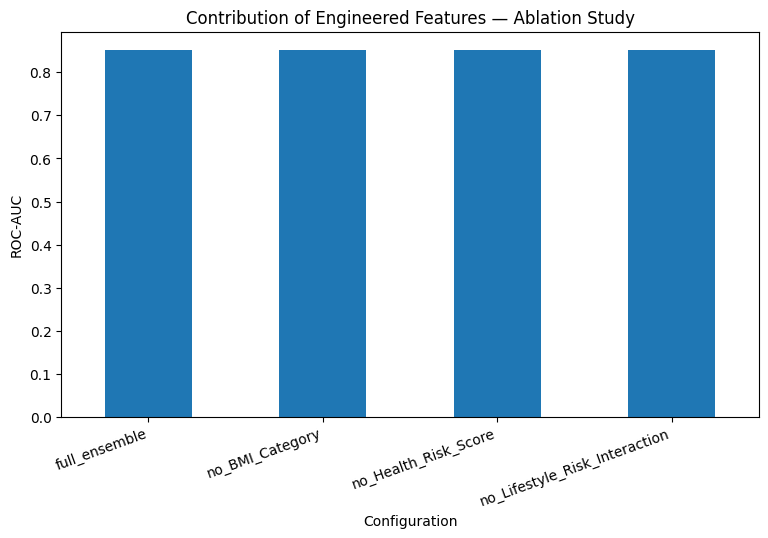

Saved: /content/drive/MyDrive/CVD/figures/figure19_ablation_f1_comparison/figure19_ablation_f1_comparison.pdf and .png


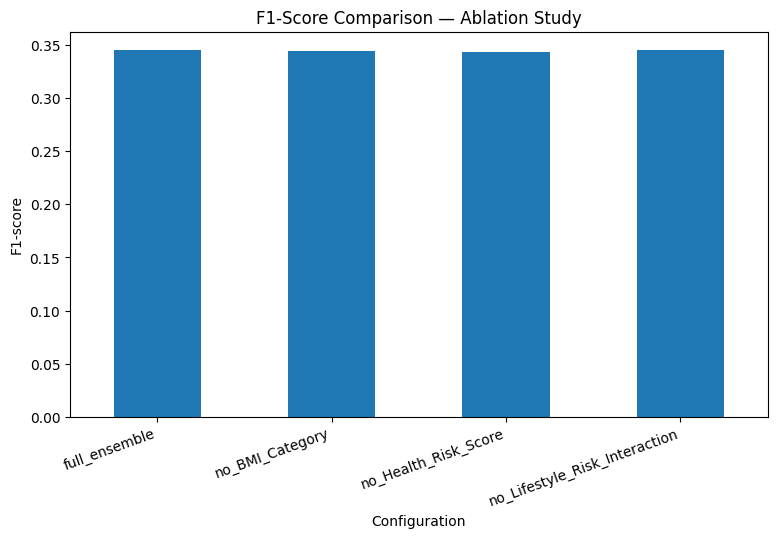


✓ ABLATION STUDY COMPLETED
✓ Four configurations evaluated.
✓ Each configuration uses retrained base learners.
✓ PR-AUC^4 weighting applied independently.
✓ Fixed final threshold used for F1.
✓ ROC-AUC and F1 reported as required by synopsis.
✓ No SHAP recalculation performed.


In [ ]:
# ============================================================
# CELL 20 — COMPONENT-WISE ABLATION STUDY
# ============================================================
#
# Synopsis requirement:
# "The ensemble will be retrained with four configurations:
#  (i) without BMI_Category,
#  (ii) without Health_Risk_Score,
#  (iii) without Lifestyle_Risk_Interaction,
#  (iv) with all engineered features,
#  to quantify the individual contribution of each engineered
#  feature. The impact ... will be reported in terms of
#  ROC-AUC and F1-score."
#
# Methodology:
# - 4 tuned base learners
# - CPU only
# - Each ablation configuration is retrained
# - PR-AUC^4 validation weighting, consistent with final ensemble
# - Fixed final threshold used for classification metrics
# - No SHAP calculation
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. Safety checks
# ------------------------------------------------------------

required_vars = [
    'X_train',
    'y_train',
    'X_test',
    'y_test',
    'X_val',
    'y_val',
    'X_train_lgbm',
    'X_val_lgbm',
    'X_test_lgbm',
    'training_config',
    'scale_pos_weight',
    'best_threshold',
    'RESULTS_DIR'
]

missing = [v for v in required_vars if v not in globals()]

if missing:
    raise NameError(
        f"Missing required variables: {missing}"
    )

print("✓ All required variables are available.")
print(f"✓ Fixed classification threshold: {best_threshold:.6f}")
print("✓ SHAP values are NOT used.")
print("✓ Each ablation configuration will be retrained.")

# ------------------------------------------------------------
# 2. PR-AUC^4 weighting function
# ------------------------------------------------------------

def calculate_prauc4_weights(
    models,
    X_val_current,
    X_val_lgbm_current,
    y_val_current
):
    """
    Calculate ensemble weights using validation PR-AUC^4.

    This keeps the ablation weighting methodology consistent
    with the final PR-AUC^4 weighted ensemble.
    """

    val_prauc = {}

    for name, model in models.items():

        if name == 'lightgbm':
            Xv = X_val_lgbm_current
        else:
            Xv = X_val_current

        pred = model.predict_proba(Xv)[:, 1]

        val_prauc[name] = average_precision_score(
            y_val_current,
            pred
        )

    # PR-AUC^4 weighting
    raw_weights = {
        name: score ** 4
        for name, score in val_prauc.items()
    }

    total_weight = sum(raw_weights.values())

    weights = {
        name: value / total_weight
        for name, value in raw_weights.items()
    }

    return val_prauc, weights


# ------------------------------------------------------------
# 3. Train one ablation configuration
# ------------------------------------------------------------

def train_ablation_ensemble(
    X_tr,
    y_tr,
    X_te,
    X_tr_lgbm,
    X_te_lgbm,
    X_val_current,
    X_val_lgbm_current,
    y_val_current
):

    models = {}

    model_names = [
        'random_forest',
        'xgboost',
        'lightgbm',
        'catboost'
    ]

    # --------------------------------------------------------
    # Train all four base learners
    # --------------------------------------------------------

    for name in model_names:

        print(f"   Training {name}...")

        model = build_estimator_cpu_tuned(name)

        if name == 'lightgbm':
            X_fit = X_tr_lgbm
        else:
            X_fit = X_tr

        model.fit(
            X_fit,
            y_tr
        )

        models[name] = model

        print(f"   ✓ {name} trained.")

    # --------------------------------------------------------
    # Calculate fresh PR-AUC^4 weights
    # using THIS ablation configuration's validation data
    # --------------------------------------------------------

    val_prauc, weights = calculate_prauc4_weights(
        models=models,
        X_val_current=X_val_current,
        X_val_lgbm_current=X_val_lgbm_current,
        y_val_current=y_val_current
    )

    print("\n   Validation PR-AUC:")
    for name, score in val_prauc.items():
        print(f"      {name}: {score:.6f}")

    print("\n   Fresh PR-AUC^4 weights:")
    for name, weight in weights.items():
        print(f"      {name}: {weight:.6f}")

    # --------------------------------------------------------
    # Test probabilities
    # --------------------------------------------------------

    test_proba = np.zeros(len(X_te), dtype=float)

    for name, model in models.items():

        if name == 'lightgbm':
            X_predict = X_te_lgbm
        else:
            X_predict = X_te

        model_proba = model.predict_proba(
            X_predict
        )[:, 1]

        test_proba += (
            weights[name] * model_proba
        )

    return {
        'models': models,
        'val_prauc': val_prauc,
        'weights': weights,
        'test_proba': test_proba
    }


# ------------------------------------------------------------
# 4. Ablation configurations
# ------------------------------------------------------------

configs = {
    'full_ensemble': [],

    'no_BMI_Category': [
        'BMI_Category'
    ],

    'no_Health_Risk_Score': [
        'Health_Risk_Score'
    ],

    'no_Lifestyle_Risk_Interaction': [
        'Lifestyle_Risk_Interaction'
    ]
}

print("\n" + "=" * 70)
print("ABLATION CONFIGURATIONS")
print("=" * 70)

for cname, drop_cols in configs.items():
    if drop_cols:
        print(f"{cname}: remove {drop_cols}")
    else:
        print(f"{cname}: all engineered features retained")


# ------------------------------------------------------------
# 5. Run ablation study
# ------------------------------------------------------------

ablation_results = {}
ablation_details = {}

for cname, drop_cols in configs.items():

    print("\n" + "=" * 70)
    print(f"CONFIGURATION: {cname}")
    print("=" * 70)

    ckpt = (
        f'{RESULTS_DIR}/ensemble/'
        f'ablation_{cname}.pkl'
    )

    # --------------------------------------------------------
    # Use existing valid checkpoint if available
    # --------------------------------------------------------

    if os.path.exists(ckpt):

        try:
            cached = joblib.load(ckpt)

            required_result_keys = {
                'ROC_AUC',
                'PR_AUC',
                'Accuracy',
                'Precision',
                'Recall',
                'F1'
            }

            if (
                isinstance(cached, dict)
                and required_result_keys.issubset(
                    cached.keys()
                )
            ):

                print("✓ Valid checkpoint found.")
                print("✓ Skipping retraining for this configuration.")

                ablation_results[cname] = cached

                # If detailed information was saved
                if 'weights' in cached:
                    ablation_details[cname] = cached

                continue

            else:
                print(
                    "⚠ Existing checkpoint is incomplete."
                )
                print(
                    "→ This configuration will be recomputed."
                )

        except Exception as e:

            print(
                f"⚠ Could not load checkpoint: {e}"
            )
            print(
                "→ This configuration will be recomputed."
            )

    # --------------------------------------------------------
    # Remove selected engineered feature(s)
    # --------------------------------------------------------

    Xtr = X_train.drop(
        columns=drop_cols,
        errors='ignore'
    )

    Xte = X_test.drop(
        columns=drop_cols,
        errors='ignore'
    )

    Xval = X_val.drop(
        columns=drop_cols,
        errors='ignore'
    )

    # LightGBM matrices
    Xtr_lgbm = X_train_lgbm.drop(
        columns=drop_cols,
        errors='ignore'
    )

    Xte_lgbm = X_test_lgbm.drop(
        columns=drop_cols,
        errors='ignore'
    )

    Xval_lgbm = X_val_lgbm.drop(
        columns=drop_cols,
        errors='ignore'
    )

    print("\nFeature dimensions:")
    print(f"   X_train:      {Xtr.shape}")
    print(f"   X_validation: {Xval.shape}")
    print(f"   X_test:       {Xte.shape}")

    # --------------------------------------------------------
    # Retrain ensemble
    # --------------------------------------------------------

    output = train_ablation_ensemble(
        X_tr=Xtr,
        y_tr=y_train,
        X_te=Xte,
        X_tr_lgbm=Xtr_lgbm,
        X_te_lgbm=Xte_lgbm,
        X_val_current=Xval,
        X_val_lgbm_current=Xval_lgbm,
        y_val_current=y_val
    )

    proba = output['test_proba']

    # --------------------------------------------------------
    # Fixed final threshold
    #
    # IMPORTANT:
    # Do NOT optimize a new threshold on the test set.
    # --------------------------------------------------------

    FINAL_THRESHOLD = f1_threshold
    y_pred = (proba >= FINAL_THRESHOLD).astype(int)


    # --------------------------------------------------------
    # Evaluation
    # --------------------------------------------------------

    res = {
        'ROC_AUC': float(
            roc_auc_score(
                y_test,
                proba
            )
        ),

        'PR_AUC': float(
            average_precision_score(
                y_test,
                proba
            )
        ),

        'Accuracy': float(
            accuracy_score(
                y_test,
                y_pred
            )
        ),

        'Precision': float(
            precision_score(
                y_test,
                y_pred,
                zero_division=0
            )
        ),

        'Recall': float(
            recall_score(
                y_test,
                y_pred,
                zero_division=0
            )
        ),

        'F1': float(
            f1_score(
                y_test,
                y_pred,
                zero_division=0
            )
        ),

        # Additional information
        'threshold': float(
            best_threshold
        ),

        'dropped_features': drop_cols,

        'val_PR_AUC_RF': float(
            output['val_prauc']['random_forest']
        ),

        'val_PR_AUC_XGB': float(
            output['val_prauc']['xgboost']
        ),

        'val_PR_AUC_LGBM': float(
            output['val_prauc']['lightgbm']
        ),

        'val_PR_AUC_CatBoost': float(
            output['val_prauc']['catboost']
        ),

        'weight_RF': float(
            output['weights']['random_forest']
        ),

        'weight_XGB': float(
            output['weights']['xgboost']
        ),

        'weight_LGBM': float(
            output['weights']['lightgbm']
        ),

        'weight_CatBoost': float(
            output['weights']['catboost']
        )
    }

    ablation_results[cname] = res
    ablation_details[cname] = res

    # --------------------------------------------------------
    # Save checkpoint
    # --------------------------------------------------------

    joblib.dump(
        res,
        ckpt
    )

    print("\n" + "-" * 60)
    print(f"RESULT: {cname}")
    print("-" * 60)

    print(f"ROC-AUC : {res['ROC_AUC']:.6f}")
    print(f"PR-AUC  : {res['PR_AUC']:.6f}")
    print(f"Accuracy: {res['Accuracy']:.6f}")
    print(f"Precision: {res['Precision']:.6f}")
    print(f"Recall  : {res['Recall']:.6f}")
    print(f"F1      : {res['F1']:.6f}")

    print("\n✓ Checkpoint saved.")


# ------------------------------------------------------------
# 6. Final Ablation Table
# ------------------------------------------------------------

table14 = pd.DataFrame(
    ablation_results
).T

# Ensure intended order
table14 = table14.reindex(
    [
        'full_ensemble',
        'no_BMI_Category',
        'no_Health_Risk_Score',
        'no_Lifestyle_Risk_Interaction'
    ]
)

print("\n" + "=" * 70)
print("TABLE 14 — COMPONENT-WISE ABLATION STUDY")
print("=" * 70)

print(
    table14[
        [
            'ROC_AUC',
            'PR_AUC',
            'Accuracy',
            'Precision',
            'Recall',
            'F1'
        ]
    ].round(6)
)


# ------------------------------------------------------------
# 7. Calculate contribution relative to full ensemble
# ------------------------------------------------------------

full_auc = table14.loc[
    'full_ensemble',
    'ROC_AUC'
]

full_f1 = table14.loc[
    'full_ensemble',
    'F1'
]

table14['ROC_AUC_change_vs_full'] = (
    table14['ROC_AUC'] - full_auc
)

table14['F1_change_vs_full'] = (
    table14['F1'] - full_f1
)

print("\n" + "=" * 70)
print("CHANGE RELATIVE TO FULL ENSEMBLE")
print("=" * 70)

print(
    table14[
        [
            'ROC_AUC',
            'ROC_AUC_change_vs_full',
            'F1',
            'F1_change_vs_full'
        ]
    ].round(6)
)


# ------------------------------------------------------------
# 8. Save Table 14
# ------------------------------------------------------------

t14_folder = fig_folder(
    'table14_ablation_analysis'
)

table14.to_csv(
    f'{t14_folder}/table14_ablation_analysis.csv'
)

print(
    f"\n✓ Table 14 saved to:"
    f"\n{t14_folder}/table14_ablation_analysis.csv"
)


# ------------------------------------------------------------
# 9. Figure 18 — ROC-AUC contribution
# ------------------------------------------------------------

fig18, ax18 = plt.subplots(
    figsize=(9, 5)
)

table14[
    'ROC_AUC'
].plot(
    kind='bar',
    ax=ax18
)

ax18.set_title(
    'Contribution of Engineered Features — Ablation Study'
)

ax18.set_ylabel(
    'ROC-AUC'
)

ax18.set_xlabel(
    'Configuration'
)

plt.xticks(
    rotation=20,
    ha='right'
)

save_figure(
    fig18,
    'figure18_ablation_contribution'
)

plt.show()


# ------------------------------------------------------------
# 10. Figure — F1 comparison
# ------------------------------------------------------------

fig19, ax19 = plt.subplots(
    figsize=(9, 5)
)

table14[
    'F1'
].plot(
    kind='bar',
    ax=ax19
)

ax19.set_title(
    'F1-Score Comparison — Ablation Study'
)

ax19.set_ylabel(
    'F1-score'
)

ax19.set_xlabel(
    'Configuration'
)

plt.xticks(
    rotation=20,
    ha='right'
)

save_figure(
    fig19,
    'figure19_ablation_f1_comparison'
)

plt.show()

print("\n" + "=" * 70)
print("✓ ABLATION STUDY COMPLETED")
print("=" * 70)

print(
    "✓ Four configurations evaluated."
)
print(
    "✓ Each configuration uses retrained base learners."
)
print(
    "✓ PR-AUC^4 weighting applied independently."
)
print(
    "✓ Fixed final threshold used for F1."
)
print(
    "✓ ROC-AUC and F1 reported as required by synopsis."
)
print(
    "✓ No SHAP recalculation performed."
)

In [ ]:
#don't run this its wrong
#NOO ITS OLD Ablation study
required_keys = {'ROC_AUC', 'PR_AUC', 'Accuracy', 'Precision', 'Recall', 'F1'}

ablation_results = {}
for cname, drop_cols in configs.items():
    ckpt = f'{RESULTS_DIR}/ensemble/ablation_{cname}.pkl'

    if os.path.exists(ckpt):
        cached = joblib.load(ckpt)
        if required_keys.issubset(cached.keys()):
            ablation_results[cname] = cached
            continue
        else:
            print(f"[{cname}] Stale checkpoint (old metrics only) — recomputing.")

    Xtr = X_train.drop(columns=drop_cols, errors='ignore')
    Xte = X_test.drop(columns=drop_cols, errors='ignore')
    Xtr_lgbm = X_train_lgbm.drop(columns=drop_cols, errors='ignore')
    Xte_lgbm = X_test_lgbm.drop(columns=drop_cols, errors='ignore')

    proba = train_ensemble_on(Xtr, y_train, Xte, Xtr_lgbm, Xte_lgbm)
    y_pred = (proba >= best_threshold).astype(int)

    res = {
        'ROC_AUC': roc_auc_score(y_test, proba),
        'PR_AUC': average_precision_score(y_test, proba),
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred)
    }
    ablation_results[cname] = res
    joblib.dump(res, ckpt)
    print(f"[{cname}] {res}")

                                ROC_AUC    PR_AUC  Accuracy  Precision  \
full_ensemble                  0.851736  0.369706  0.713528   0.216889   
no_BMI_Category                0.851713  0.369864  0.713146   0.216469   
no_Health_Risk_Score           0.851629  0.369640  0.711214   0.215239   
no_Lifestyle_Risk_Interaction  0.851589  0.369711  0.713686   0.216878   

                                 Recall        F1  
full_ensemble                  0.845786  0.345245  
no_BMI_Category                0.844528  0.344608  
no_Health_Risk_Score           0.844277  0.343027  
no_Lifestyle_Risk_Interaction  0.845031  0.345168  
Saved: /content/drive/MyDrive/CVD/figures/figure18_ablation_contribution/figure18_ablation_contribution.pdf and .png


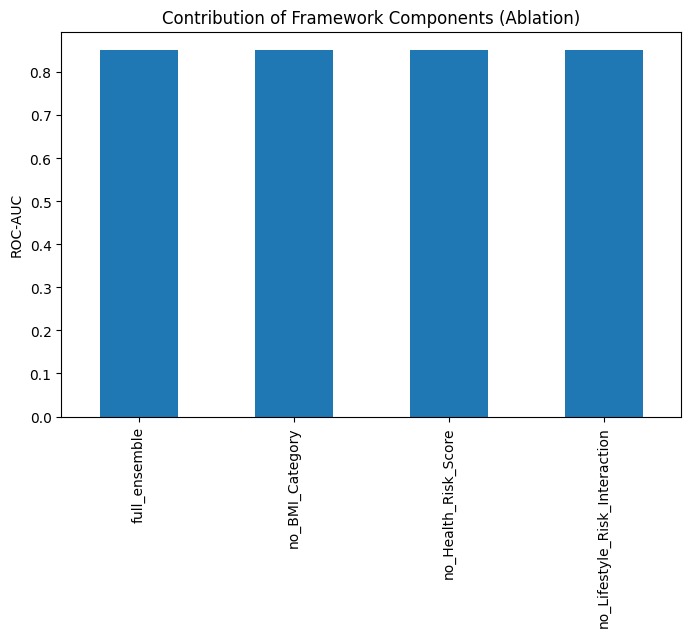

In [ ]:
#NO ITS OLD Ablation study
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def train_ensemble_on(X_tr, y_tr, X_te, X_tr_lgbm, X_te_lgbm):
    models, val_a = {}, {}
    for name in ['random_forest','xgboost','lightgbm','catboost']:
        m = build_estimator_cpu_tuned(name)
        Xin_tr = X_tr_lgbm if name == 'lightgbm' else X_tr
        m.fit(Xin_tr, y_tr)
        models[name] = m
        Xin_val = (X_val_lgbm.reindex(columns=X_tr_lgbm.columns, fill_value=0)
                   if name == 'lightgbm'
                   else X_val.reindex(columns=X_tr.columns, fill_value=0))
        val_a[name] = roc_auc_score(y_val, m.predict_proba(Xin_val)[:,1])
    tot = sum(val_a.values())
    w = {n: a/tot for n, a in val_a.items()}
    proba = np.zeros(len(X_te))
    for name, m in models.items():
        Xin_te = X_te_lgbm if name == 'lightgbm' else X_te
        proba += w[name] * m.predict_proba(Xin_te)[:,1]
    return proba

configs = {'full_ensemble': [], 'no_BMI_Category': ['BMI_Category'],
           'no_Health_Risk_Score': ['Health_Risk_Score'],
           'no_Lifestyle_Risk_Interaction': ['Lifestyle_Risk_Interaction']}

ablation_results = {}
for cname, drop_cols in configs.items():
    ckpt = f'{RESULTS_DIR}/ensemble/ablation_{cname}.pkl'
    if os.path.exists(ckpt):
        ablation_results[cname] = joblib.load(ckpt); continue

    Xtr = X_train.drop(columns=drop_cols, errors='ignore')
    Xte = X_test.drop(columns=drop_cols, errors='ignore')
    Xtr_lgbm = X_train_lgbm.drop(columns=drop_cols, errors='ignore')
    Xte_lgbm = X_test_lgbm.drop(columns=drop_cols, errors='ignore')

    proba = train_ensemble_on(Xtr, y_train, Xte, Xtr_lgbm, Xte_lgbm)
    y_pred = (proba >= best_threshold).astype(int)   # ADD THIS — single source of truth

    res = {
        'ROC_AUC': roc_auc_score(y_test, proba),
        'PR_AUC': average_precision_score(y_test, proba),
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, (proba >= best_threshold).astype(int))  # consistent threshold
    }
    ablation_results[cname] = res
    joblib.dump(res, ckpt)
    print(f"[{cname}] {res}")

table14 = pd.DataFrame(ablation_results).T
t14_folder = fig_folder('table14_ablation_analysis')
table14.to_csv(f'{t14_folder}/table14_ablation_analysis.csv')
print(table14)

fig18, ax18 = plt.subplots(figsize=(8,5))
table14['ROC_AUC'].plot(kind='bar', ax=ax18)
ax18.set_title('Contribution of Framework Components (Ablation)'); ax18.set_ylabel('ROC-AUC')
save_figure(fig18, 'figure18_ablation_contribution')
plt.show()

In [ ]:
#yes
# ================================================================
# RESTORE FINAL ENSEMBLE VARIABLES AFTER RUNTIME RESET
# NO RETRAINING — NO SHAP — NO ABLATION
# ================================================================

import os
import joblib
import numpy as np
from sklearn.metrics import roc_auc_score

# ------------------------------------------------
# Paths
# ------------------------------------------------

RESULTS_DIR = "/content/drive/MyDrive/CVD/results"
MODELS_DIR = "/content/drive/MyDrive/CVD/models"

ENSEMBLE_DIR = os.path.join(
    MODELS_DIR,
    "ensemble"
)

print("=" * 70)
print("RESTORING FINAL ENSEMBLE VARIABLES")
print("=" * 70)


# ------------------------------------------------
# 1. Restore final PR-AUC^4 ensemble weights
# ------------------------------------------------

weights_path = os.path.join(
    ENSEMBLE_DIR,
    "ensemble_weights.pkl"
)

if not os.path.exists(weights_path):
    raise FileNotFoundError(
        f"Ensemble weights checkpoint not found:\n{weights_path}"
    )

ensemble_weights = joblib.load(
    weights_path
)

print("\n✓ ensemble_weights restored:")
print(ensemble_weights)


# ------------------------------------------------
# 2. Restore thresholds
# ------------------------------------------------

thresholds_path = os.path.join(
    ENSEMBLE_DIR,
    "all_thresholds.pkl"
)

best_threshold_path = os.path.join(
    ENSEMBLE_DIR,
    "best_threshold.pkl"
)

if not os.path.exists(thresholds_path):
    raise FileNotFoundError(
        f"Threshold checkpoint not found:\n{thresholds_path}"
    )

base_thresholds = joblib.load(
    thresholds_path
)

if os.path.exists(best_threshold_path):
    best_threshold = float(
        joblib.load(best_threshold_path)
    )
else:
    # final primary threshold already established
    best_threshold = 0.3316376663571651

# Ensure Weighted_Ensemble entry exists
base_thresholds["Weighted_Ensemble"] = best_threshold

print("\n✓ base_thresholds restored:")
print(base_thresholds)

print(
    f"\n✓ Final ensemble threshold: "
    f"{best_threshold:.6f}"
)


# ------------------------------------------------
# 3. Restore / verify final base models
# ------------------------------------------------
# If base_models already exist in memory, reuse them.
# Otherwise rerun ONLY the existing checkpoint-loading
# model-loading section from your notebook.

if "base_models" in globals():

    print("\n✓ base_models already available in memory.")

else:

    print(
        "\n⚠ base_models are not currently in memory."
    )

    print(
        "Please run the ORIGINAL model-loading/training cell "
        "from your notebook that loads the class-weighted "
        "models from checkpoints."
    )

    raise RuntimeError(
        "base_models missing. Stop here — do NOT retrain."
    )


# ------------------------------------------------
# 4. Verify prediction helper
# ------------------------------------------------

if "predict_proba_safe" not in globals():

    def predict_proba_safe(
        model,
        name,
        X,
        X_lgbm=None
    ):
        if name == "lightgbm":
            return model.predict_proba(
                X_lgbm
            )[:, 1]

        return model.predict_proba(
            X
        )[:, 1]

    print(
        "✓ predict_proba_safe restored."
    )

else:

    print(
        "✓ predict_proba_safe already available."
    )


# ------------------------------------------------
# 5. Recreate proba_dict
# ------------------------------------------------
# Prediction only — NO TRAINING

proba_dict = {}

print()
print("=" * 70)
print("GENERATING TEST-SET PROBABILITIES")
print("Prediction only — no model training")
print("=" * 70)

for name, model in base_models.items():

    proba = predict_proba_safe(
        model,
        name,
        X_test,
        X_test_lgbm
    )

    proba_dict[name] = np.asarray(
        proba
    ).astype(float)

    print(
        f"✓ {name}: "
        f"{len(proba_dict[name])} predictions"
    )


# ------------------------------------------------
# 6. Recreate final weighted ensemble probability
# ------------------------------------------------

ens_proba_test = np.zeros(
    len(X_test),
    dtype=float
)

for name in base_models.keys():

    ens_proba_test += (
        ensemble_weights[name]
        * proba_dict[name]
    )


# ------------------------------------------------
# 7. Recreate final ensemble prediction
# ------------------------------------------------

ens_pred = (
    ens_proba_test
    >= best_threshold
).astype(int)


# ------------------------------------------------
# 8. Validate restoration
# ------------------------------------------------

print()
print("=" * 70)
print("RESTORATION CHECK")
print("=" * 70)

print(
    f"Test samples: {len(y_test)}"
)

print(
    f"Ensemble probability shape: "
    f"{ens_proba_test.shape}"
)

print(
    f"Ensemble threshold: "
    f"{best_threshold:.6f}"
)

print(
    f"Ensemble ROC-AUC: "
    f"{roc_auc_score(y_test, ens_proba_test):.6f}"
)

print(
    f"Predicted positives: "
    f"{ens_pred.sum():,}"
)

print(
    f"Positive prediction rate: "
    f"{ens_pred.mean():.4%}"
)


# ------------------------------------------------
# 9. Identify best base learner
# ------------------------------------------------
# Use validation AUC from saved/reconstructed model predictions.

val_aucs = {}

for name, model in base_models.items():

    val_proba = predict_proba_safe(
        model,
        name,
        X_val,
        X_val_lgbm
    )

    val_aucs[name] = roc_auc_score(
        y_val,
        val_proba
    )

best_name = max(
    val_aucs,
    key=val_aucs.get
)

best_base_proba = proba_dict[
    best_name
]


print()
print(
    f"✓ Best base learner: {best_name}"
)

print(
    "Validation ROC-AUCs:"
)

for name, auc in val_aucs.items():

    print(
        f"  {name}: {auc:.6f}"
    )


# ------------------------------------------------
# 10. FINAL CHECK
# ------------------------------------------------

print()
print("=" * 70)
print("✓ FINAL VARIABLES RESTORED")
print("=" * 70)

print("✓ ensemble_weights")
print("✓ base_thresholds")
print("✓ best_threshold")
print("✓ proba_dict")
print("✓ ens_proba_test")
print("✓ ens_pred")
print("✓ val_aucs")
print("✓ best_name")
print("✓ best_base_proba")

print()
print(
    "IMPORTANT: No SHAP recalculation."
)
print(
    "IMPORTANT: No ablation retraining."
)
print(
    "IMPORTANT: No hyperparameter search."
)

RESTORING FINAL ENSEMBLE VARIABLES

✓ ensemble_weights restored:
{'random_forest': np.float64(0.21232062304580207), 'xgboost': np.float64(0.2663098920982783), 'lightgbm': np.float64(0.2548131058368417), 'catboost': np.float64(0.2665563790190779)}

✓ base_thresholds restored:
{'random_forest': np.float64(0.4542710218018506), 'xgboost': np.float32(0.009582936), 'lightgbm': np.float64(0.5084383088226246), 'catboost': np.float64(0.49119162878327577), 'Weighted_Ensemble': 0.3316376663571651}

✓ Final ensemble threshold: 0.331638

✓ base_models already available in memory.
✓ predict_proba_safe already available.

GENERATING TEST-SET PROBABILITIES
Prediction only — no model training
✓ random_forest: 44514 predictions
✓ xgboost: 44514 predictions
✓ lightgbm: 44514 predictions
✓ catboost: 44514 predictions

RESTORATION CHECK
Test samples: 44514
Ensemble probability shape: (44514,)
Ensemble threshold: 0.331638
Ensemble ROC-AUC: 0.851792
Predicted positives: 15,536
Positive prediction rate: 34.90

In [ ]:
# ================================================================
# CELL — BOOTSTRAP CI + PAIRED DELONG + WILCOXON + McNEMAR
# ================================================================
# Synopsis requirement:
# 1. 95% CIs for ALL performance metrics using 1,000 bootstrap iterations
# 2. Paired DeLong test: Ensemble vs best single base learner
# 3. Wilcoxon signed-rank test across CV folds:
#       F1, Recall, Accuracy
# 4. McNemar's test:
#       Ensemble vs best base learner misclassification pattern
#
# IMPORTANT:
# - No SHAP recalculation
# - Existing final test probabilities are reused
# - CV models are trained only where fold-wise comparisons are required
# - CPU only
# - Checkpoint after every CV fold
# ================================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from scipy.stats import wilcoxon, norm
from statsmodels.stats.contingency_tables import mcnemar


# ================================================================
# 0. SAFETY CHECKS
# ================================================================

required_vars = [
    'y_test',
    'ens_proba_test',
    'ens_pred',
    'proba_dict',
    'val_aucs',
    'base_thresholds',
    'best_threshold',
    'f1_threshold',
    'ensemble_weights',
    'X_train',
    'X_train_lgbm',
    'cv',
    'base_models'
]

missing_vars = [v for v in required_vars if v not in globals()]

if missing_vars:
    raise NameError(
        "Missing required variables: " + ", ".join(missing_vars)
    )

print("✓ All required variables are available.")
print("✓ SHAP values are NOT used.")
print("✓ Bootstrap iterations: 1000")
print("✓ CV folds:", cv.n_splits)


# ================================================================
# 1. DIRECTORIES
# ================================================================

RESULTS_DIR = "/content/drive/MyDrive/CVD/results"

SIG_DIR = os.path.join(
    RESULTS_DIR,
    "ensemble",
    "statistical_significance"
)

os.makedirs(SIG_DIR, exist_ok=True)

print("✓ Results directory:", SIG_DIR)


# ================================================================
# 2. BEST BASE LEARNER
# ================================================================
# # Weighted Ensemble vs LightGBM.
# LightGBM is explicitly fixed as the comparison base learner.

# ============================================================
# SUPERVISOR-REQUESTED COMPARISON
# Weighted Ensemble vs LightGBM
# ============================================================

best_name = "lightgbm"

best_base_proba = predict_proba_safe(
    base_models["lightgbm"],
    "lightgbm",
    X_test,
    X_test_lgbm
)

print(
    f"Statistical comparison base model: {best_name}"
)



y_test_np = np.asarray(y_test).astype(int)
ens_proba_test_np = np.asarray(ens_proba_test).astype(float)
ens_pred_np =  (
    ens_proba_test_np >= f1_threshold
).astype(int)

base_pred_default = (
    best_base_proba >= base_thresholds[best_name]
).astype(int)

print()
print("=" * 70)
print("BEST SINGLE BASE LEARNER")
print("=" * 70)
print(f"Best model: {best_name}")
print(f"Validation ROC-AUC: {val_aucs[best_name]:.6f}")
print(f"Base threshold: {base_thresholds[best_name]:.6f}")
print(f"Ensemble Youden threshold: {best_threshold:.6f}")
print(f"Ensemble FINAL F1-constrained threshold: {f1_threshold:.6f}")

# ================================================================
# 3. BOOTSTRAP 95% CIs
# ================================================================
# Requirement:
# "All performance metrics will be reported with 95% confidence
# intervals generated by bootstrapping (1,000 iterations) of
# the test set."
#
# Metrics:
# ROC-AUC
# PR-AUC
# Accuracy
# Precision
# Recall
# F1
#
# Positive class = 1
# ================================================================

BOOTSTRAP_N = 1000
BOOTSTRAP_SEED = 42


def calculate_metrics(y_true, proba, threshold):
    """
    Calculate all required test-set performance metrics.
    """
    y_true = np.asarray(y_true).astype(int)
    proba = np.asarray(proba).astype(float)

    pred = (proba >= threshold).astype(int)

    return {
        "ROC_AUC": roc_auc_score(y_true, proba),
        "PR_AUC": average_precision_score(y_true, proba),
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(
            y_true, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, pred, zero_division=0
        )
    }


def bootstrap_metric_cis(
    y_true,
    proba,
    threshold,
    n_bootstrap=1000,
    seed=42
):
    """
    Bootstrap 95% percentile CIs for all performance metrics.
    """

    y_true = np.asarray(y_true).astype(int)
    proba = np.asarray(proba).astype(float)

    rng = np.random.RandomState(seed)

    metric_names = [
        "ROC_AUC",
        "PR_AUC",
        "Accuracy",
        "Precision",
        "Recall",
        "F1"
    ]

    scores = {
        metric: []
        for metric in metric_names
    }

    n = len(y_true)

    for i in range(n_bootstrap):

        idx = rng.choice(
            n,
            size=n,
            replace=True
        )

        y_b = y_true[idx]
        p_b = proba[idx]

        # ROC-AUC and PR-AUC require both classes
        if len(np.unique(y_b)) < 2:
            continue

        pred_b = (
            p_b >= threshold
        ).astype(int)

        scores["ROC_AUC"].append(
            roc_auc_score(y_b, p_b)
        )

        scores["PR_AUC"].append(
            average_precision_score(y_b, p_b)
        )

        scores["Accuracy"].append(
            accuracy_score(y_b, pred_b)
        )

        scores["Precision"].append(
            precision_score(
                y_b,
                pred_b,
                zero_division=0
            )
        )

        scores["Recall"].append(
            recall_score(
                y_b,
                pred_b,
                zero_division=0
            )
        )

        scores["F1"].append(
            f1_score(
                y_b,
                pred_b,
                zero_division=0
            )
        )

    ci_results = {}

    for metric in metric_names:

        values = np.asarray(
            scores[metric]
        )

        ci_results[metric] = {
            "point_estimate": float(
                np.mean(
                    values
                )
            ),
            "ci_lower": float(
                np.percentile(values, 2.5)
            ),
            "ci_upper": float(
                np.percentile(values, 97.5)
            ),
            "n_bootstrap_valid": int(
                len(values)
            )
        }

    return ci_results


print()
print("=" * 70)
print("BOOTSTRAP 95% CONFIDENCE INTERVALS")
print("=" * 70)
print(f"Running {BOOTSTRAP_N} bootstrap iterations...")


# ------------------------------------------------
# Ensemble bootstrap
# ------------------------------------------------

ensemble_ci = bootstrap_metric_cis(
    y_true=y_test_np,
    proba=ens_proba_test_np,
    threshold=f1_threshold,
    n_bootstrap=BOOTSTRAP_N,
    seed=BOOTSTRAP_SEED
)


# ------------------------------------------------
# Best base learner bootstrap
# ------------------------------------------------

base_ci = bootstrap_metric_cis(
    y_true=y_test_np,
    proba=best_base_proba,
    threshold=base_thresholds[best_name],
    n_bootstrap=BOOTSTRAP_N,
    seed=BOOTSTRAP_SEED
)


print()
print("ENSEMBLE — 95% CIs")

for metric, result in ensemble_ci.items():
    print(
        f"{metric:12s}: "
        f"{result['point_estimate']:.6f} "
        f"[{result['ci_lower']:.6f}, "
        f"{result['ci_upper']:.6f}]"
    )


print()
print(f"{best_name} — 95% CIs")

for metric, result in base_ci.items():
    print(
        f"{metric:12s}: "
        f"{result['point_estimate']:.6f} "
        f"[{result['ci_lower']:.6f}, "
        f"{result['ci_upper']:.6f}]"
    )


# ================================================================
# 4. PAIRED DELONG TEST
# ================================================================
# Compare correlated ROC curves on the SAME test patients.
#
# Ensemble vs best single base learner.
# ================================================================


def compute_midrank(x):

    J = np.argsort(x)
    Z = x[J]
    N = len(x)

    T = np.zeros(N, dtype=float)

    i = 0

    while i < N:

        j = i

        while j < N and Z[j] == Z[i]:
            j += 1

        T[i:j] = (
            0.5 * (i + j - 1) + 1
        )

        i = j

    T2 = np.empty(N, dtype=float)
    T2[J] = T

    return T2


def fast_delong(preds_list, y_true):

    y_true = np.asarray(
        y_true
    ).astype(int)

    order = np.argsort(
        -y_true,
        kind="mergesort"
    )

    y_sorted = y_true[order]

    m = int(
        np.sum(y_sorted == 1)
    )

    n = int(
        np.sum(y_sorted == 0)
    )

    if m == 0 or n == 0:
        raise ValueError(
            "DeLong requires both positive and negative classes."
        )

    k = len(preds_list)

    preds_sorted = np.vstack([
        np.asarray(p)[order]
        for p in preds_list
    ])

    tx = np.empty([k, m])
    ty = np.empty([k, n])
    tz = np.empty([k, m + n])

    for r in range(k):

        tx[r] = compute_midrank(
            preds_sorted[r, :m]
        )

        ty[r] = compute_midrank(
            preds_sorted[r, m:]
        )

        tz[r] = compute_midrank(
            preds_sorted[r, :]
        )

    aucs = (
        tz[:, :m].sum(axis=1)
        / (m * n)
        - (m + 1.0)
        / (2.0 * n)
    )

    v01 = (
        tz[:, :m]
        - tx[:, :]
    ) / n

    v10 = 1.0 - (
        tz[:, m:]
        - ty[:, :]
    ) / m

    sx = np.cov(v01)
    sy = np.cov(v10)

    # np.cov returns scalar for k=1; here k=2
    if np.ndim(sx) == 0:
        sx = np.array([[sx]])

    if np.ndim(sy) == 0:
        sy = np.array([[sy]])

    covariance = (
        sx / m
        + sy / n
    )

    return aucs, covariance


print()
print("=" * 70)
print("PAIRED DELONG TEST")
print("=" * 70)

delong_aucs, delong_cov = fast_delong(
    [
        ens_proba_test_np,
        best_base_proba
    ],
    y_test_np
)

var_diff = (
    delong_cov[0, 0]
    + delong_cov[1, 1]
    - 2 * delong_cov[0, 1]
)

if var_diff <= 0:
    print(
        "Warning: non-positive DeLong variance encountered."
    )
    p_delong = np.nan
    z_delong = np.nan
else:

    z_delong = (
        delong_aucs[0]
        - delong_aucs[1]
    ) / np.sqrt(var_diff)

    p_delong = 2 * (
        1 - norm.cdf(
            abs(z_delong)
        )
    )

print(
    f"Ensemble AUC: "
    f"{delong_aucs[0]:.6f}"
)

print(
    f"{best_name} AUC: "
    f"{delong_aucs[1]:.6f}"
)

print(
    f"AUC difference: "
    f"{delong_aucs[0] - delong_aucs[1]:+.6f}"
)

print(
    f"DeLong z = {z_delong:.6f}"
)

print(
    f"DeLong p = {p_delong:.6f}"
)


# ================================================================
# 5. WILCOXON SIGNED-RANK TEST ACROSS 5 CV FOLDS
# ================================================================
# Synopsis:
# "Wilcoxon signed-rank test across cross-validation folds to test
# for differences in F1-score/Recall/Accuracy."
#
# IMPORTANT:
# The ensemble and best base learner are evaluated on the SAME
# validation fold in every iteration.
#
# The ensemble uses the FINAL PR-AUC^4 ensemble weights.
# ================================================================


WILCOXON_CKPT = os.path.join(
    SIG_DIR,
    "wilcoxon_cv_checkpoint.pkl"
)

if os.path.exists(WILCOXON_CKPT):

    wilcoxon_checkpoint = joblib.load(
        WILCOXON_CKPT
    )

    ens_fold_metrics = wilcoxon_checkpoint[
        "ens_fold_metrics"
    ]

    base_fold_metrics = wilcoxon_checkpoint[
        "base_fold_metrics"
    ]

    completed_folds = wilcoxon_checkpoint[
        "completed_folds"
    ]

    print()
    print(
        "✓ Existing Wilcoxon checkpoint found."
    )
    print(
        f"✓ Completed folds: {completed_folds}"
    )

else:

    ens_fold_metrics = []
    base_fold_metrics = []

    completed_folds = []

    print()
    print(
        "No Wilcoxon checkpoint found."
    )
    print(
        "Starting 5-fold paired CV evaluation."
    )


# ------------------------------------------------
# Run only missing folds
# ------------------------------------------------

for fold_number, (tr_idx, val_idx) in enumerate(
    cv.split(X_train, y_train),
    start=1
):

    if fold_number in completed_folds:

        print(
            f"✓ Fold {fold_number} already completed — skipping."
        )

        continue

    print()
    print("-" * 70)
    print(f"WILCOXON CV FOLD {fold_number}/{cv.n_splits}")
    print("-" * 70)

    Xtr_f = X_train.iloc[tr_idx]
    ytr_f = np.asarray(y_train)[tr_idx]

    Xva_f = X_train.iloc[val_idx]
    yva_f = np.asarray(y_train)[val_idx]

    Xtr_f_lgbm = X_train_lgbm.iloc[tr_idx]
    Xva_f_lgbm = X_train_lgbm.iloc[val_idx]

    # ------------------------------------------------------------
    # Ensemble predictions
    # ------------------------------------------------------------

    fold_ens_proba = np.zeros(
        len(val_idx),
        dtype=float
    )

    fold_models = {}

    for name in base_models:

        print(
            f"Training {name}..."
        )

        m = build_estimator_cpu_tuned(
            name
        )

        Xin_tr = (
            Xtr_f_lgbm
            if name == "lightgbm"
            else Xtr_f
        )

        m.fit(
            Xin_tr,
            ytr_f
        )

        fold_models[name] = m

        Xin_va = (
            Xva_f_lgbm
            if name == "lightgbm"
            else Xva_f
        )

        fold_proba = m.predict_proba(
            Xin_va
        )[:, 1]

        # FINAL PR-AUC^4 WEIGHTING
        fold_ens_proba += (
            ensemble_weights[name]
            * fold_proba
        )

    fold_ens_pred = (
        fold_ens_proba
        >= f1_threshold
    ).astype(int)

    # ------------------------------------------------------------
    # Best base learner prediction
    # ------------------------------------------------------------

    base_model = fold_models.get(
        best_name
    )

    if base_model is None:

        base_model = build_estimator_cpu_tuned(
            best_name
        )

        Xin_tr_base = (
            Xtr_f_lgbm
            if best_name == "lightgbm"
            else Xtr_f
        )

        base_model.fit(
            Xin_tr_base,
            ytr_f
        )

    Xin_va_base = (
        Xva_f_lgbm
        if best_name == "lightgbm"
        else Xva_f
    )

    base_fold_proba = base_model.predict_proba(
        Xin_va_base
    )[:, 1]

    base_fold_pred = (
        base_fold_proba
        >= base_thresholds[best_name]
    ).astype(int)

    # ------------------------------------------------------------
    # Calculate paired fold metrics
    # ------------------------------------------------------------

    ens_metrics = {
        "F1": f1_score(
            yva_f,
            fold_ens_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            yva_f,
            fold_ens_pred,
            zero_division=0
        ),
        "Accuracy": accuracy_score(
            yva_f,
            fold_ens_pred
        )
    }

    base_metrics = {
        "F1": f1_score(
            yva_f,
            base_fold_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            yva_f,
            base_fold_pred,
            zero_division=0
        ),
        "Accuracy": accuracy_score(
            yva_f,
            base_fold_pred
        )
    }

    ens_fold_metrics.append(
        ens_metrics
    )

    base_fold_metrics.append(
        base_metrics
    )

    completed_folds.append(
        fold_number
    )

    # ------------------------------------------------------------
    # SAVE CHECKPOINT IMMEDIATELY
    # ------------------------------------------------------------

    wilcoxon_checkpoint = {
        "ens_fold_metrics": ens_fold_metrics,
        "base_fold_metrics": base_fold_metrics,
        "completed_folds": completed_folds,
        "best_base_model": best_name,
        "ensemble_weights": ensemble_weights,
        "ensemble_threshold": float(
            f1_threshold
        ),
        "base_threshold": float(
            base_thresholds[best_name]
        )
    }

    joblib.dump(
        wilcoxon_checkpoint,
        WILCOXON_CKPT
    )

    print(
        f"✓ Fold {fold_number} completed."
    )

    print(
        f"  Ensemble — "
        f"F1={ens_metrics['F1']:.6f}, "
        f"Recall={ens_metrics['Recall']:.6f}, "
        f"Accuracy={ens_metrics['Accuracy']:.6f}"
    )

    print(
        f"  {best_name} — "
        f"F1={base_metrics['F1']:.6f}, "
        f"Recall={base_metrics['Recall']:.6f}, "
        f"Accuracy={base_metrics['Accuracy']:.6f}"
    )


# ================================================================
# 6. WILCOXON TESTS
# ================================================================

print()
print("=" * 70)
print("WILCOXON SIGNED-RANK TESTS")
print("=" * 70)

wilcoxon_results = {}

for metric in [
    "F1",
    "Recall",
    "Accuracy"
]:

    ens_values = np.array([
        x[metric]
        for x in ens_fold_metrics
    ])

    base_values = np.array([
        x[metric]
        for x in base_fold_metrics
    ])

    differences = (
        ens_values
        - base_values
    )

    # If all paired differences are zero,
    # Wilcoxon has no informative statistic.
    if np.allclose(
        differences,
        0
    ):

        statistic = 0.0
        p_value = 1.0

    else:

        statistic, p_value = wilcoxon(
            ens_values,
            base_values,
            alternative="two-sided",
            zero_method="wilcox"
        )

    wilcoxon_results[metric] = {
        "statistic": float(
            statistic
        ),
        "p_value": float(
            p_value
        ),
        "ensemble_mean": float(
            np.mean(ens_values)
        ),
        "base_mean": float(
            np.mean(base_values)
        ),
        "mean_difference": float(
            np.mean(differences)
        ),
        "fold_values_ensemble": [
            float(x) for x in ens_values
        ],
        "fold_values_base": [
            float(x) for x in base_values
        ]
    }

    print(
        f"{metric:10s}: "
        f"Ensemble mean={np.mean(ens_values):.6f}, "
        f"Base mean={np.mean(base_values):.6f}, "
        f"Difference={np.mean(differences):+.6f}, "
        f"stat={statistic:.4f}, "
        f"p={p_value:.6f}"
    )


# ================================================================
# 7. McNEMAR'S TEST
# ================================================================
# Compare misclassification patterns:
#
#                 Ensemble
#                 Correct   Wrong
# Base Correct      a         b
# Base Wrong        c         d
#
# McNemar tests whether b and c differ significantly.
# ================================================================

print()
print("=" * 70)
print("McNEMAR'S TEST")
print("=" * 70)

base_correct = (
    base_pred_default
    == y_test_np
)

ens_correct = (
    ens_pred_np
    == y_test_np
)

# 2x2 table of correctness patterns
#
# rows    = base learner correctness
# columns = ensemble correctness
#
#             Ensemble
#             Wrong Correct
# Base Wrong
# Base Correct
contingency = np.zeros(
    (2, 2),
    dtype=int
)

for base_c, ens_c in zip(
    base_correct,
    ens_correct
):

    contingency[
        int(base_c),
        int(ens_c)
    ] += 1


# statsmodels accepts:
# [[both wrong, base wrong / ensemble correct],
#  [base correct / ensemble wrong, both correct]]

print("Correctness contingency table:")
print(contingency)

mcnemar_result = mcnemar(
    contingency,
    exact=False,
    correction=True
)

mcnemar_stat = float(
    mcnemar_result.statistic
)

mcnemar_p = float(
    mcnemar_result.pvalue
)

print()
print(
    f"McNemar statistic = "
    f"{mcnemar_stat:.6f}"
)

print(
    f"McNemar p-value = "
    f"{mcnemar_p:.6f}"
)


# ================================================================
# 8. FINAL SUMMARY TABLE
# ================================================================

metric_names = [
    "ROC_AUC",
    "PR_AUC",
    "Accuracy",
    "Precision",
    "Recall",
    "F1"
]

summary_rows = []

for metric in metric_names:

    e = ensemble_ci[metric]
    b = base_ci[metric]

    summary_rows.append({
        "Metric": metric,

        "Ensemble": e["point_estimate"],
        "Ensemble_CI_Lower": e["ci_lower"],
        "Ensemble_CI_Upper": e["ci_upper"],

        "Best_Base": b["point_estimate"],
        "Best_Base_CI_Lower": b["ci_lower"],
        "Best_Base_CI_Upper": b["ci_upper"],

        "Best_Base_Model": best_name
    })


ci_summary_df = pd.DataFrame(
    summary_rows
)

print()
print("=" * 70)
print("TABLE — PERFORMANCE METRICS WITH 95% BOOTSTRAP CIs")
print("=" * 70)

print(
    ci_summary_df.to_string(
        index=False
    )
)


# ================================================================
# 9. STATISTICAL TEST SUMMARY
# ================================================================

statistical_summary_df = pd.DataFrame([

    {
        "Comparison": (
            f"Ensemble vs {best_name}"
        ),
        "Test": "Paired DeLong",
        "Metric": "ROC-AUC",
        "Statistic": z_delong,
        "p_value": p_delong
    },

    {
        "Comparison": (
            f"Ensemble vs {best_name}"
        ),
        "Test": "Wilcoxon signed-rank",
        "Metric": "F1",
        "Statistic": wilcoxon_results["F1"]["statistic"],
        "p_value": wilcoxon_results["F1"]["p_value"]
    },

    {
        "Comparison": (
            f"Ensemble vs {best_name}"
        ),
        "Test": "Wilcoxon signed-rank",
        "Metric": "Recall",
        "Statistic": wilcoxon_results["Recall"]["statistic"],
        "p_value": wilcoxon_results["Recall"]["p_value"]
    },

    {
        "Comparison": (
            f"Ensemble vs {best_name}"
        ),
        "Test": "Wilcoxon signed-rank",
        "Metric": "Accuracy",
        "Statistic": wilcoxon_results["Accuracy"]["statistic"],
        "p_value": wilcoxon_results["Accuracy"]["p_value"]
    },

    {
        "Comparison": (
            f"Ensemble vs {best_name}"
        ),
        "Test": "McNemar",
        "Metric": "Misclassification pattern",
        "Statistic": mcnemar_stat,
        "p_value": mcnemar_p
    }

])


print()
print("=" * 70)
print("TABLE — STATISTICAL SIGNIFICANCE TESTS")
print("=" * 70)

print(
    statistical_summary_df.to_string(
        index=False
    )
)


# ================================================================
# 10. SAVE RESULTS
# ================================================================

ci_csv = os.path.join(
    SIG_DIR,
    "bootstrap_95CI_all_metrics.csv"
)

tests_csv = os.path.join(
    SIG_DIR,
    "statistical_significance_tests.csv"
)

ci_summary_df.to_csv(
    ci_csv,
    index=False
)

statistical_summary_df.to_csv(
    tests_csv,
    index=False
)


# ------------------------------------------------
# Detailed JSON
# ------------------------------------------------

sig_results = {

    "best_base_model": best_name,

    "bootstrap": {
        "iterations": BOOTSTRAP_N,
        "seed": BOOTSTRAP_SEED,
        "ensemble": ensemble_ci,
        "best_base": base_ci
    },

    "paired_delong": {
        "ensemble_auc": float(
            delong_aucs[0]
        ),
        "best_base_auc": float(
            delong_aucs[1]
        ),
        "auc_difference": float(
            delong_aucs[0]
            - delong_aucs[1]
        ),
        "z": float(z_delong)
        if not np.isnan(z_delong)
        else None,
        "p_value": float(p_delong)
        if not np.isnan(p_delong)
        else None
    },

    "wilcoxon": wilcoxon_results,

    "mcnemar": {
        "contingency_table": (
            contingency.tolist()
        ),
        "statistic": mcnemar_stat,
        "p_value": mcnemar_p
    },

    "ensemble_weights": {
        k: float(v)
        for k, v in ensemble_weights.items()
    },

    "ensemble_threshold": float(
        f1_threshold
    ),

    "base_threshold": float(
        base_thresholds[best_name]
    )
}


json_path = os.path.join(
    SIG_DIR,
    "significance_results_complete.json"
)

with open(
    json_path,
    "w"
) as f:

    json.dump(
        sig_results,
        f,
        indent=2
    )


# ================================================================
# 11. FINAL STATUS
# ================================================================

print()
print("=" * 70)
print("✓ CONFIDENCE INTERVAL + SIGNIFICANCE TESTING COMPLETED")
print("=" * 70)

print("✓ Bootstrap: 1,000 iterations")
print("✓ 95% CI: ROC-AUC")
print("✓ 95% CI: PR-AUC")
print("✓ 95% CI: Accuracy")
print("✓ 95% CI: Precision")
print("✓ 95% CI: Recall")
print("✓ 95% CI: F1")
print("✓ Paired DeLong: Ensemble vs best base learner")
print("✓ Wilcoxon: F1 across CV folds")
print("✓ Wilcoxon: Recall across CV folds")
print("✓ Wilcoxon: Accuracy across CV folds")
print("✓ McNemar: Ensemble vs best base learner")
print("✓ No SHAP recalculation")

print()
print("Saved files:")
print(ci_csv)
print(tests_csv)
print(json_path)
print(WILCOXON_CKPT)

✓ All required variables are available.
✓ SHAP values are NOT used.
✓ Bootstrap iterations: 1000
✓ CV folds: 5
✓ Results directory: /content/drive/MyDrive/CVD/results/ensemble/statistical_significance
Statistical comparison base model: lightgbm

BEST SINGLE BASE LEARNER
Best model: lightgbm
Validation ROC-AUC: 0.844854
Base threshold: 0.508438
Ensemble Youden threshold: 0.331638
Ensemble FINAL F1-constrained threshold: 0.364586

BOOTSTRAP 95% CONFIDENCE INTERVALS
Running 1000 bootstrap iterations...

ENSEMBLE — 95% CIs
ROC_AUC     : 0.851956 [0.846737, 0.857094]
PR_AUC      : 0.370711 [0.355868, 0.385632]
Accuracy    : 0.742003 [0.738127, 0.745901]
Precision   : 0.231764 [0.224520, 0.238683]
Recall      : 0.816563 [0.804537, 0.827483]
F1          : 0.361039 [0.351956, 0.369792]

lightgbm — 95% CIs
ROC_AUC     : 0.852002 [0.846734, 0.857324]
PR_AUC      : 0.369128 [0.355011, 0.384453]
Accuracy    : 0.745969 [0.742013, 0.749833]
Precision   : 0.233990 [0.227037, 0.241267]
Recall      : 0

In [ ]:
# ============================================================
# McNEMAR EFFECT SIZE
# ============================================================

print("\n" + "=" * 70)
print("McNEMAR EFFECT SIZE")
print("=" * 70)

# contingency:
#
# [[both wrong, base wrong / ensemble correct],
#  [base correct / ensemble wrong, both correct]]

b = int(contingency[0, 1])
c = int(contingency[1, 0])

print(f"Base wrong / Ensemble correct = {b}")
print(f"Base correct / Ensemble wrong = {c}")

# Matched-pairs odds ratio
if b == 0 and c == 0:
    mcnemar_or = np.nan

elif b == 0 or c == 0:
    mcnemar_or = (b + 0.5) / (c + 0.5)

else:
    mcnemar_or = b / c

print(
    f"McNemar matched-pairs odds ratio: "
    f"{mcnemar_or:.6f}"
)

# Directional discordance
total_discordant = b + c

if total_discordant > 0:
    net_discordance = (
        (b - c) / total_discordant
    )

    print(
        f"Net directional discordance: "
        f"{net_discordance:.6f}"
    )

print(
    f"McNemar p-value: "
    f"{mcnemar_p:.6e}"
)


McNEMAR EFFECT SIZE
Base wrong / Ensemble correct = 282
Base correct / Ensemble wrong = 459
McNemar matched-pairs odds ratio: 0.614379
Net directional discordance: -0.238866
McNemar p-value: 1.009500e-10


In [ ]:
#do not run this
import os

WILCOXON_CKPT = "/content/drive/MyDrive/CVD/results/ensemble/statistical_significance/wilcoxon_cv_checkpoint.pkl"

if os.path.exists(WILCOXON_CKPT):
    os.remove(WILCOXON_CKPT)
    print("✓ Old Wilcoxon checkpoint deleted.")
else:
    print("✓ No old Wilcoxon checkpoint found.")

✓ Old Wilcoxon checkpoint deleted.


In [ ]:
# ============================================================
# RESTORE MINIMAL RESULTS DICTIONARY FOR ROBUSTNESS TESTING
# Prediction only — NO training
# ============================================================

from sklearn.metrics import roc_auc_score, average_precision_score
import numpy as np

print("=" * 70)
print("RESTORING MINIMAL RESULTS FOR ROBUSTNESS TESTING")
print("=" * 70)

# Make sure required variables exist
required = ['ens_proba_test', 'ens_pred', 'y_test']

missing = [v for v in required if v not in globals()]

if missing:
    raise NameError(f"Missing required variables: {missing}")

# Convert safely to numpy
y_test_np = np.asarray(y_test).ravel()
ens_proba_test_np = np.asarray(ens_proba_test).ravel()
ens_pred_np = np.asarray(ens_pred).ravel()

# Recalculate baseline metrics from already-generated predictions
baseline_roc_auc = roc_auc_score(
    y_test_np,
    ens_proba_test_np
)

baseline_pr_auc = average_precision_score(
    y_test_np,
    ens_proba_test_np
)

# Restore minimal results dictionary
results = {
    'Weighted_Ensemble': {
        'ROC_AUC': float(baseline_roc_auc),
        'PR_AUC': float(baseline_pr_auc)
    }
}

print(f"✓ Weighted Ensemble ROC-AUC restored: {baseline_roc_auc:.6f}")
print(f"✓ Weighted Ensemble PR-AUC restored:  {baseline_pr_auc:.6f}")

print("\n✓ results dictionary restored.")
print("✓ No model training.")
print("✓ No SHAP.")
print("✓ No ablation.")
print("✓ No hyperparameter search.")

RESTORING MINIMAL RESULTS FOR ROBUSTNESS TESTING
✓ Weighted Ensemble ROC-AUC restored: 0.851792
✓ Weighted Ensemble PR-AUC restored:  0.369912

✓ results dictionary restored.
✓ No model training.
✓ No SHAP.
✓ No ablation.
✓ No hyperparameter search.


FINAL ENSEMBLE ROBUSTNESS TESTING
✓ Required variables available.
✓ Final trained models available.
✓ No model training will be performed.

BASELINE FINAL ENSEMBLE
Baseline ROC-AUC: 0.851792
Final ensemble threshold: 0.331638

Continuous perturbation features:
['BMI', 'SleepHours']

Top SHAP features used for targeted dropout:
1. AgeCategory
2. Health_Risk_Score
3. ChestScan
4. Sex
5. RemovedTeeth

A. GAUSSIAN NOISE INJECTION
σ=0.05 | ROC-AUC=0.851809 | AUC Drop=-0.000017
σ=0.10 | ROC-AUC=0.851751 | AUC Drop=+0.000041
σ=0.15 | ROC-AUC=0.851750 | AUC Drop=+0.000042

B. RANDOM FEATURE DROPOUT
Dropout=10% | Features dropped=4 | ROC-AUC=0.851484 | AUC Drop=+0.000308
Dropout=20% | Features dropped=9 | ROC-AUC=0.843886 | AUC Drop=+0.007907
Dropout=30% | Features dropped=14 | ROC-AUC=0.839202 | AUC Drop=+0.012590

C. TARGETED SINGLE-FEATURE DROPOUT
AgeCategory                    | ROC-AUC=0.824575 | AUC Drop=+0.027217
Health_Risk_Score              | ROC-AUC=0.833705 | AUC Drop=+0.018087
Ches

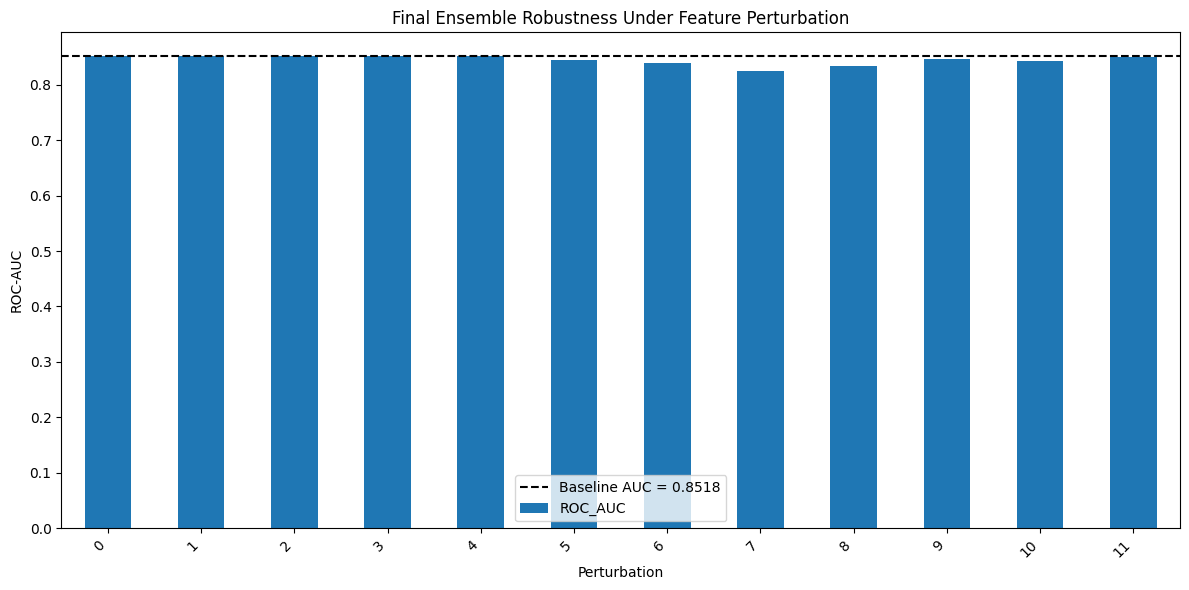


✓ ROBUSTNESS TESTING COMPLETED
✓ Gaussian noise: BMI + SleepHours
✓ Gaussian σ = 0.05
✓ Gaussian σ = 0.10
✓ Gaussian σ = 0.15
✓ Random feature dropout = 10%
✓ Random feature dropout = 20%
✓ Random feature dropout = 30%
✓ Targeted dropout of top-5 SHAP features
✓ ROC-AUC recorded for every perturbation
✓ AUC degradation calculated against baseline
✓ Training-set means used for feature masking
✓ Random seed = 42
✓ No model retraining
✓ No SHAP recalculation
✓ No ablation retraining
✓ No hyperparameter search


In [ ]:
# ============================================================
# ROBUSTNESS TESTING — FINAL ENSEMBLE
# ============================================================
# Gaussian noise injection:
#   BMI + SleepHours
#   sigma = 0.05, 0.10, 0.15
#
# Random feature dropout:
#   10%, 20%, 30%
#
# Targeted single-feature dropout:
#   Top-5 SHAP-ranked features
#
# IMPORTANT:
#   - Uses the already-trained final ensemble
#   - Uses the already-established PR-AUC^4 ensemble weights
#   - NO model retraining
#   - NO SHAP recalculation
#   - NO ablation retraining
#   - NO hyperparameter tuning
# ============================================================

print("=" * 70)
print("FINAL ENSEMBLE ROBUSTNESS TESTING")
print("=" * 70)

# ------------------------------------------------------------
# 0. REQUIRED VARIABLES CHECK
# ------------------------------------------------------------

required_vars = [
    'X_test',
    'X_test_lgbm',
    'X_train',
    'X_train_lgbm',
    'y_test',
    'base_models',
    'ensemble_predict_proba',
    'results'
]

missing_vars = [v for v in required_vars if v not in globals()]

if missing_vars:
    raise NameError(
        f"Missing required variables: {missing_vars}"
    )

print("✓ Required variables available.")
print("✓ Final trained models available.")
print("✓ No model training will be performed.")

# ------------------------------------------------------------
# 1. BASELINE
# ------------------------------------------------------------

y_test_np = np.asarray(y_test).ravel()

baseline_proba = np.asarray(ens_proba_test).ravel()

baseline_auc = roc_auc_score(
    y_test_np,
    baseline_proba
)

print("\n" + "=" * 70)
print("BASELINE FINAL ENSEMBLE")
print("=" * 70)

print(f"Baseline ROC-AUC: {baseline_auc:.6f}")
print(f"Final ensemble threshold: {best_threshold:.6f}")

# ------------------------------------------------------------
# 2. SETTINGS
# ------------------------------------------------------------

rng = np.random.RandomState(42)

noise_levels = [0.05, 0.10, 0.15]
dropout_levels = [0.10, 0.20, 0.30]

# Supervisor specifically requested BMI + SleepTime.
# In the actual dataset/model this variable is named SleepHours.
continuous_target_features = [
    c for c in ['BMI', 'SleepHours']
    if c in X_test.columns
]

if len(continuous_target_features) == 0:
    raise ValueError(
        "Neither BMI nor SleepHours was found in X_test."
    )

print("\nContinuous perturbation features:")
print(continuous_target_features)

# ------------------------------------------------------------
# 3. TOP-5 SHAP FEATURES
# ------------------------------------------------------------
# These are the already-established SHAP top features.
# NO SHAP calculation is performed here.

top5_shap_features = [
    'AgeCategory',
    'Health_Risk_Score',
    'ChestScan',
    'Sex',
    'RemovedTeeth'
]

top5_shap_features = [
    c for c in top5_shap_features
    if c in X_test.columns
]

if len(top5_shap_features) == 0:
    raise ValueError(
        "None of the specified top-5 SHAP features "
        "were found in X_test."
    )

print("\nTop SHAP features used for targeted dropout:")
for i, feature in enumerate(top5_shap_features, 1):
    print(f"{i}. {feature}")

# ------------------------------------------------------------
# 4. RESULTS CONTAINER
# ------------------------------------------------------------

robustness_results = {}

# ============================================================
# A. GAUSSIAN NOISE INJECTION
# ============================================================

print("\n" + "=" * 70)
print("A. GAUSSIAN NOISE INJECTION")
print("=" * 70)

for sigma in noise_levels:

    X_noisy = X_test.copy()
    X_noisy_lgbm = X_test_lgbm.copy()

    # Generate one reproducible noise matrix
    noise = rng.normal(
        loc=0.0,
        scale=sigma,
        size=X_noisy[continuous_target_features].shape
    )

    # Apply identical perturbation to both model input matrices
    X_noisy[continuous_target_features] = (
        X_noisy[continuous_target_features].to_numpy()
        + noise
    )

    X_noisy_lgbm[continuous_target_features] = (
        X_noisy_lgbm[continuous_target_features].to_numpy()
        + noise
    )

    # Final frozen ensemble prediction
    proba_noisy = ensemble_predict_proba(
        X_noisy,
        X_noisy_lgbm
    )

    auc_noisy = roc_auc_score(
        y_test_np,
        proba_noisy
    )

    auc_drop = baseline_auc - auc_noisy

    key = f'gaussian_noise_sigma_{sigma}'

    robustness_results[key] = {
        'Perturbation_Type': 'Gaussian_Noise',
        'Level': sigma,
        'Affected_Features': continuous_target_features,
        'ROC_AUC': float(auc_noisy),
        'AUC_Drop_from_Baseline': float(auc_drop)
    }

    print(
        f"σ={sigma:.2f} | "
        f"ROC-AUC={auc_noisy:.6f} | "
        f"AUC Drop={auc_drop:+.6f}"
    )

# ============================================================
# B. RANDOM FEATURE DROPOUT
# ============================================================

print("\n" + "=" * 70)
print("B. RANDOM FEATURE DROPOUT")
print("=" * 70)

for dropout_frac in dropout_levels:

    X_drop = X_test.copy()
    X_drop_lgbm = X_test_lgbm.copy()

    n_drop = max(
        1,
        int(len(X_test.columns) * dropout_frac)
    )

    drop_cols = rng.choice(
        X_test.columns.to_numpy(),
        size=n_drop,
        replace=False
    )

    drop_cols = list(drop_cols)

    # Replace dropped features with TRAINING mean.
    # This avoids using test-set statistics.
    for c in drop_cols:

        X_drop[c] = X_train[c].mean()

        if c in X_drop_lgbm.columns:
            X_drop_lgbm[c] = X_train_lgbm[c].mean()

    # Final frozen ensemble prediction
    proba_drop = ensemble_predict_proba(
        X_drop,
        X_drop_lgbm
    )

    auc_drop_model = roc_auc_score(
        y_test_np,
        proba_drop
    )

    auc_drop = baseline_auc - auc_drop_model

    key = f'feature_dropout_{int(dropout_frac * 100)}pct'

    robustness_results[key] = {
        'Perturbation_Type': 'Random_Feature_Dropout',
        'Level': dropout_frac,
        'Affected_Features': drop_cols,
        'ROC_AUC': float(auc_drop_model),
        'AUC_Drop_from_Baseline': float(auc_drop)
    }

    print(
        f"Dropout={dropout_frac * 100:.0f}% | "
        f"Features dropped={n_drop} | "
        f"ROC-AUC={auc_drop_model:.6f} | "
        f"AUC Drop={auc_drop:+.6f}"
    )

# ============================================================
# C. TARGETED SINGLE-FEATURE DROPOUT
# ============================================================

print("\n" + "=" * 70)
print("C. TARGETED SINGLE-FEATURE DROPOUT")
print("=" * 70)

for feature in top5_shap_features:

    X_single = X_test.copy()
    X_single_lgbm = X_test_lgbm.copy()

    # Replace only this one feature by TRAINING mean
    X_single[feature] = X_train[feature].mean()

    if feature in X_single_lgbm.columns:
        X_single_lgbm[feature] = X_train_lgbm[feature].mean()

    # Final frozen ensemble prediction
    proba_single = ensemble_predict_proba(
        X_single,
        X_single_lgbm
    )

    auc_single = roc_auc_score(
        y_test_np,
        proba_single
    )

    auc_drop = baseline_auc - auc_single

    key = f'single_feature_dropout_{feature}'

    robustness_results[key] = {
        'Perturbation_Type': 'Targeted_Single_Feature_Dropout',
        'Level': 1.0,
        'Affected_Features': [feature],
        'ROC_AUC': float(auc_single),
        'AUC_Drop_from_Baseline': float(auc_drop)
    }

    print(
        f"{feature:30s} | "
        f"ROC-AUC={auc_single:.6f} | "
        f"AUC Drop={auc_drop:+.6f}"
    )

# ============================================================
# 5. SAVE CHECKPOINT
# ============================================================

ROBUST_CKPT = (
    f'{RESULTS_DIR}/ensemble/'
    f'robustness_results.pkl'
)

joblib.dump(
    robustness_results,
    ROBUST_CKPT
)

print("\n✓ Robustness checkpoint saved:")
print(ROBUST_CKPT)

# ============================================================
# 6. FINAL ROBUSTNESS TABLE
# ============================================================

table_robust = pd.DataFrame(
    robustness_results
).T.reset_index()

table_robust = table_robust.rename(
    columns={'index': 'Perturbation'}
)

# Add baseline row
baseline_row = pd.DataFrame([{
    'Perturbation': 'Baseline',
    'Perturbation_Type': 'Baseline',
    'Level': 0.0,
    'Affected_Features': ['None'],
    'ROC_AUC': float(baseline_auc),
    'AUC_Drop_from_Baseline': 0.0
}])

table_robust = pd.concat(
    [baseline_row, table_robust],
    ignore_index=True
)

print("\n" + "=" * 70)
print("ROBUSTNESS RESULTS")
print("=" * 70)

print(
    table_robust[
        [
            'Perturbation',
            'Perturbation_Type',
            'Level',
            'ROC_AUC',
            'AUC_Drop_from_Baseline'
        ]
    ].to_string(index=False)
)

# ============================================================
# 7. SAVE CSV
# ============================================================

t_robust_folder = fig_folder(
    'table_robustness_analysis'
)

robust_csv = (
    f'{t_robust_folder}/'
    f'table_robustness_analysis.csv'
)

table_robust.to_csv(
    robust_csv,
    index=False
)

print("\n✓ Robustness table saved:")
print(robust_csv)

# ============================================================
# 8. SAVE DETAILED CSV INCLUDING DROPPED FEATURES
# ============================================================

detailed_rows = []

for key, value in robustness_results.items():

    detailed_rows.append({
        'Perturbation': key,
        'Perturbation_Type': value['Perturbation_Type'],
        'Level': value['Level'],
        'Affected_Features': ', '.join(
            map(str, value['Affected_Features'])
        ),
        'ROC_AUC': value['ROC_AUC'],
        'AUC_Drop_from_Baseline':
            value['AUC_Drop_from_Baseline']
    })

detailed_robustness_df = pd.DataFrame(
    detailed_rows
)

detailed_csv = (
    f'{t_robust_folder}/'
    f'table_robustness_detailed.csv'
)

detailed_robustness_df.to_csv(
    detailed_csv,
    index=False
)

print("✓ Detailed robustness table saved:")
print(detailed_csv)

# ============================================================
# 9. ROBUSTNESS FIGURE
# ============================================================

fig_robust, ax_robust = plt.subplots(
    figsize=(12, 6)
)

plot_df = table_robust.copy()

plot_df['ROC_AUC'].plot(
    kind='bar',
    ax=ax_robust
)

ax_robust.axhline(
    baseline_auc,
    color='black',
    linestyle='--',
    label=f'Baseline AUC = {baseline_auc:.4f}'
)

ax_robust.set_title(
    'Final Ensemble Robustness Under Feature Perturbation'
)

ax_robust.set_ylabel('ROC-AUC')
ax_robust.set_xlabel('Perturbation')

plt.xticks(
    rotation=45,
    ha='right'
)

ax_robust.legend()

plt.tight_layout()

save_figure(
    fig_robust,
    'figure_robustness_analysis'
)

plt.show()

# ============================================================
# 10. COMPLETION CHECK
# ============================================================

print("\n" + "=" * 70)
print("✓ ROBUSTNESS TESTING COMPLETED")
print("=" * 70)

print("✓ Gaussian noise: BMI + SleepHours")
print("✓ Gaussian σ = 0.05")
print("✓ Gaussian σ = 0.10")
print("✓ Gaussian σ = 0.15")
print("✓ Random feature dropout = 10%")
print("✓ Random feature dropout = 20%")
print("✓ Random feature dropout = 30%")
print("✓ Targeted dropout of top-5 SHAP features")
print("✓ ROC-AUC recorded for every perturbation")
print("✓ AUC degradation calculated against baseline")
print("✓ Training-set means used for feature masking")
print("✓ Random seed = 42")
print("✓ No model retraining")
print("✓ No SHAP recalculation")
print("✓ No ablation retraining")
print("✓ No hyperparameter search")

Robustness checkpoint found — loading.
                            ROC_AUC AUC_Drop_from_baseline  \
gaussian_noise_sigma_0.05  0.851626               0.000035   
gaussian_noise_sigma_0.1   0.851556               0.000105   
gaussian_noise_sigma_0.15  0.851757              -0.000096   
feature_dropout_0.1        0.851128               0.000534   
feature_dropout_0.2        0.849261               0.002401   
feature_dropout_0.3        0.818805               0.032856   

                                                            dropped_features  
gaussian_noise_sigma_0.05                                                NaN  
gaussian_noise_sigma_0.1                                                 NaN  
gaussian_noise_sigma_0.15                                                NaN  
feature_dropout_0.1        [BMI_Category, HadKidneyDisease, FluVaxLast12,...  
feature_dropout_0.2        [TetanusLast10Tdap_Yes, received Tdap, HadDiab...  
feature_dropout_0.3        [HeightInMeters, Lifestyl

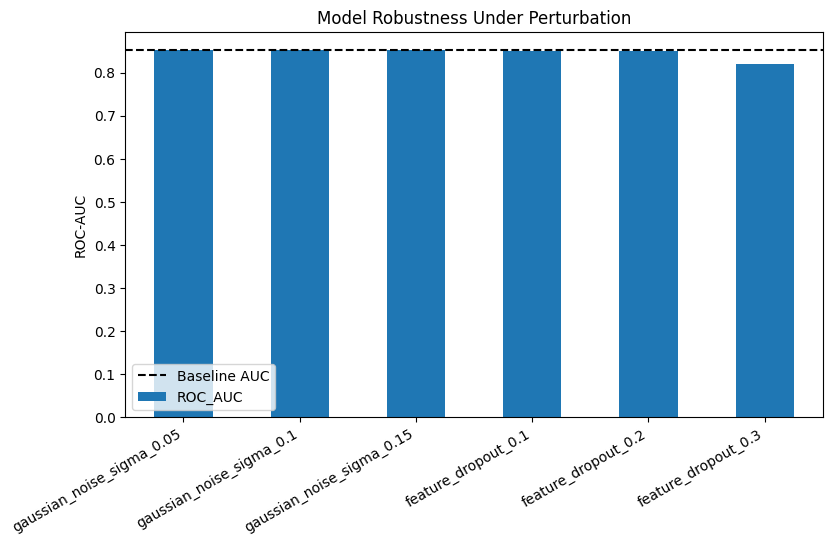

In [ ]:

# ================================================================
# CLINICAL DECISION-SUPPORT MODULE
# FINAL WEIGHTED ENSEMBLE
# Uses EXISTING 500 probability-space SHAP cases
# NO MODEL RETRAINING
# NO SHAP RECALCULATION
# ================================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

print("=" * 70)
print("CLINICAL DECISION-SUPPORT MODULE")
print("FINAL WEIGHTED ENSEMBLE")
print("=" * 70)

# ------------------------------------------------
# 1. Paths
# ------------------------------------------------

BASE = "/content/drive/MyDrive/CVD"
SHAP_DIR = f"{BASE}/results/ensemble"
CLINICAL_DIR = f"{SHAP_DIR}/clinical_decision_support"

os.makedirs(CLINICAL_DIR, exist_ok=True)

# ------------------------------------------------
# 2. Final clinical threshold
# ------------------------------------------------
# Final model in the thesis:
# Weighted Ensemble + F1-constrained threshold
# Recall floor = 0.80

CLINICAL_THRESHOLD = 0.36458617702918966

print("\nFinal clinical threshold:",
      f"{CLINICAL_THRESHOLD:.6f}")

# ------------------------------------------------
# 3. Load EXISTING probability-space SHAP results
# ------------------------------------------------

SHAP_VALUES_FILE = (
    f"{SHAP_DIR}/newensemble_probability_shap_values.pkl"
)

SHAP_X_FILE = (
    f"{SHAP_DIR}/newensemble_probability_shap_X.pkl"
)

SHAP_BASE_FILE = (
    f"{SHAP_DIR}/newensemble_probability_shap_base.pkl"
)

print("\nLoading existing SHAP files...")

clinical_shap_values = joblib.load(SHAP_VALUES_FILE)
clinical_X = joblib.load(SHAP_X_FILE)
clinical_base_value = joblib.load(SHAP_BASE_FILE)

clinical_shap_values = np.asarray(
    clinical_shap_values,
    dtype=float
)

if not isinstance(clinical_X, pd.DataFrame):
    clinical_X = pd.DataFrame(
        clinical_X,
        columns=X_test.columns
    )

clinical_base_value = float(
    np.asarray(clinical_base_value).flatten()[0]
)

print("SHAP values shape:", clinical_shap_values.shape)
print("X explain shape:", clinical_X.shape)
print("Base probability:", clinical_base_value)

# ------------------------------------------------
# 4. SAFETY CHECKS
# ------------------------------------------------

assert clinical_shap_values.ndim == 2

assert clinical_shap_values.shape[0] == len(clinical_X), (
    "SHAP rows and X_explain rows do not match."
)

assert clinical_shap_values.shape[1] == clinical_X.shape[1], (
    "SHAP features and X_explain features do not match."
)

assert clinical_X.shape[1] == X_test.shape[1], (
    f"Clinical SHAP features ({clinical_X.shape[1]}) "
    f"do not match X_test features ({X_test.shape[1]})."
)

assert list(clinical_X.columns) == list(X_test.columns), (
    "Clinical SHAP feature order does not match X_test."
)

print("\n✓ SHAP dimensions are valid.")
print("✓ Feature count = 47.")
print("✓ Feature order matches X_test.")
print("✓ No SHAP recalculation performed.")

# ------------------------------------------------
# 5. Reconstruct FINAL ensemble probabilities
# ------------------------------------------------
# Probability-space SHAP:
#
# prediction = base_value + sum(SHAP values)
#
# This is already validated in the SHAP analysis.

clinical_probability = (
    clinical_base_value
    + clinical_shap_values.sum(axis=1)
)

clinical_probability = np.asarray(
    clinical_probability,
    dtype=float
)

print("\nClinical probability range:")
print("Min:", clinical_probability.min())
print("Max:", clinical_probability.max())

# Safety check
assert np.all(
    clinical_probability >= -1e-6
)

assert np.all(
    clinical_probability <= 1 + 1e-6
)

print("✓ Probability reconstruction is valid.")

# ------------------------------------------------
# 6. Clinical risk classification
# ------------------------------------------------
# Threshold-based classification:
#
# Low        < 0.5 × threshold
# Moderate   0.5 × threshold to threshold
# High       threshold to 1.5 × threshold
# Very High  >= 1.5 × threshold
#
# Threshold = 0.364586

LOW_BOUND = 0.50 * CLINICAL_THRESHOLD
HIGH_BOUND = 1.50 * CLINICAL_THRESHOLD

def classify_clinical_risk(probability):

    if probability < LOW_BOUND:
        return "Low"

    elif probability < CLINICAL_THRESHOLD:
        return "Moderate"

    elif probability < HIGH_BOUND:
        return "High"

    else:
        return "Very High"


clinical_risk = np.array([
    classify_clinical_risk(p)
    for p in clinical_probability
])

# ------------------------------------------------
# 7. Clinical recommendation
# ------------------------------------------------

def clinical_recommendation(risk_level):

    if risk_level == "Low":
        return (
            "Low predicted risk. Continue routine preventive "
            "health monitoring and healthy lifestyle practices."
        )

    elif risk_level == "Moderate":
        return (
            "Moderate predicted risk. Consider preventive "
            "risk-factor assessment and routine clinical follow-up."
        )

    elif risk_level == "High":
        return (
            "High predicted risk. Clinical review and assessment "
            "of modifiable cardiovascular risk factors are recommended."
        )

    else:
        return (
            "Very high predicted risk. Prompt clinical evaluation "
            "and comprehensive cardiovascular risk assessment are recommended."
        )


clinical_recommendations = np.array([
    clinical_recommendation(r)
    for r in clinical_risk
])

# ------------------------------------------------
# 8. Top SHAP factors for each patient
# ------------------------------------------------

TOP_K = 5

feature_names = clinical_X.columns.tolist()

top_features = []
top_shap_values = []
top_directions = []

for i in range(len(clinical_shap_values)):

    patient_shap = clinical_shap_values[i]

    # Highest absolute contributions
    top_idx = np.argsort(
        np.abs(patient_shap)
    )[::-1][:TOP_K]

    patient_features = []
    patient_values = []
    patient_directions = []

    for idx in top_idx:

        feature = feature_names[idx]
        value = float(patient_shap[idx])

        patient_features.append(feature)
        patient_values.append(value)

        if value > 0:
            patient_directions.append("Increases predicted risk")
        elif value < 0:
            patient_directions.append("Decreases predicted risk")
        else:
            patient_directions.append("Neutral")

    top_features.append(patient_features)
    top_shap_values.append(patient_values)
    top_directions.append(patient_directions)

# ------------------------------------------------
# 9. Build clinical report table
# ------------------------------------------------

clinical_report = pd.DataFrame({

    "Case_ID": [
        f"SHAP_CASE_{i+1:04d}"
        for i in range(len(clinical_probability))
    ],

    "Predicted_Probability": clinical_probability,

    "Risk_Level": clinical_risk,

    "Clinical_Threshold": CLINICAL_THRESHOLD,

    "Recommendation": clinical_recommendations,

    "Top_1_Feature": [
        x[0] for x in top_features
    ],

    "Top_1_SHAP": [
        x[0] for x in top_shap_values
    ],

    "Top_1_Direction": [
        x[0] for x in top_directions
    ],

    "Top_2_Feature": [
        x[1] for x in top_features
    ],

    "Top_2_SHAP": [
        x[1] for x in top_shap_values
    ],

    "Top_2_Direction": [
        x[1] for x in top_directions
    ],

    "Top_3_Feature": [
        x[2] for x in top_features
    ],

    "Top_3_SHAP": [
        x[2] for x in top_shap_values
    ],

    "Top_3_Direction": [
        x[2] for x in top_directions
    ],

    "Top_4_Feature": [
        x[3] for x in top_features
    ],

    "Top_4_SHAP": [
        x[3] for x in top_shap_values
    ],

    "Top_4_Direction": [
        x[3] for x in top_directions
    ],

    "Top_5_Feature": [
        x[4] for x in top_features
    ],

    "Top_5_SHAP": [
        x[4] for x in top_shap_values
    ],

    "Top_5_Direction": [
        x[4] for x in top_directions
    ]
})

# ------------------------------------------------
# 10. Save CSV
# ------------------------------------------------

clinical_csv = (
    f"{CLINICAL_DIR}/clinical_decision_support_reports.csv"
)

clinical_report.to_csv(
    clinical_csv,
    index=False
)

print("\n✓ Clinical report CSV saved:")
print(clinical_csv)

# ------------------------------------------------
# 11. Risk distribution
# ------------------------------------------------

risk_order = [
    "Low",
    "Moderate",
    "High",
    "Very High"
]

risk_counts = (
    clinical_report["Risk_Level"]
    .value_counts()
    .reindex(risk_order, fill_value=0)
)

print("\n" + "=" * 70)
print("CLINICAL RISK DISTRIBUTION")
print("=" * 70)

for risk, count in risk_counts.items():

    percentage = (
        count / len(clinical_report) * 100
    )

    print(
        f"{risk:12s}: "
        f"{count:4d} "
        f"({percentage:.2f}%)"
    )

# ------------------------------------------------
# 12. Save risk distribution
# ------------------------------------------------

risk_distribution = pd.DataFrame({

    "Risk_Level": risk_order,

    "Count": [
        int(risk_counts[r])
        for r in risk_order
    ],

    "Percentage": [
        float(
            risk_counts[r] /
            len(clinical_report) * 100
        )
        for r in risk_order
    ]
})

risk_csv = (
    f"{CLINICAL_DIR}/clinical_risk_distribution.csv"
)

risk_distribution.to_csv(
    risk_csv,
    index=False
)

# ------------------------------------------------
# 13. JSON clinical reports
# ------------------------------------------------

json_records = []

for i, row in clinical_report.iterrows():

    json_records.append({

        "case_id": row["Case_ID"],

        "predicted_probability": float(
            row["Predicted_Probability"]
        ),

        "risk_level": row["Risk_Level"],

        "clinical_threshold": float(
            CLINICAL_THRESHOLD
        ),

        "recommendation": row["Recommendation"],

        "top_shap_factors": [

            {
                "feature": row["Top_1_Feature"],
                "shap_value": float(row["Top_1_SHAP"]),
                "direction": row["Top_1_Direction"]
            },

            {
                "feature": row["Top_2_Feature"],
                "shap_value": float(row["Top_2_SHAP"]),
                "direction": row["Top_2_Direction"]
            },

            {
                "feature": row["Top_3_Feature"],
                "shap_value": float(row["Top_3_SHAP"]),
                "direction": row["Top_3_Direction"]
            },

            {
                "feature": row["Top_4_Feature"],
                "shap_value": float(row["Top_4_SHAP"]),
                "direction": row["Top_4_Direction"]
            },

            {
                "feature": row["Top_5_Feature"],
                "shap_value": float(row["Top_5_SHAP"]),
                "direction": row["Top_5_Direction"]
            }
        ]
    })

clinical_json = (
    f"{CLINICAL_DIR}/clinical_decision_support_reports.json"
)

with open(
    clinical_json,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        json_records,
        f,
        indent=2,
        ensure_ascii=False
    )

# ------------------------------------------------
# 14. Final validation
# ------------------------------------------------

assert len(clinical_report) == len(clinical_shap_values)

assert clinical_report[
    "Predicted_Probability"
].notna().all()

assert clinical_report[
    "Risk_Level"
].isin(risk_order).all()

print("\n" + "=" * 70)
print("CLINICAL DECISION-SUPPORT COMPLETED")
print("=" * 70)

print(f"✓ Cases explained: {len(clinical_report)}")
print(f"✓ Features per case: {clinical_shap_values.shape[1]}")
print(f"✓ Clinical threshold: {CLINICAL_THRESHOLD:.6f}")
print("✓ SHAP values reused from existing checkpoint")
print("✓ No SHAP recalculation")
print("✓ No model retraining")
print("✓ No hyperparameter tuning")

print("\nSaved files:")
print(clinical_csv)
print(risk_csv)
print(clinical_json)

print("\nRisk boundaries:")
print(f"Low:       probability < {LOW_BOUND:.6f}")
print(
    f"Moderate:  {LOW_BOUND:.6f} "
    f"to < {CLINICAL_THRESHOLD:.6f}"
)
print(
    f"High:      {CLINICAL_THRESHOLD:.6f} "
    f"to < {HIGH_BOUND:.6f}"
)
print(f"Very High: probability >= {HIGH_BOUND:.6f}")

print("\nDONE.")


CLINICAL DECISION-SUPPORT MODULE
FINAL WEIGHTED ENSEMBLE

Final clinical threshold: 0.364586

Loading existing SHAP files...
SHAP values shape: (500, 47)
X explain shape: (500, 47)
Base probability: 0.248038480213752

✓ SHAP dimensions are valid.
✓ Feature count = 47.
✓ Feature order matches X_test.
✓ No SHAP recalculation performed.

Clinical probability range:
Min: 0.015022139884660918
Max: 0.7673836022851585
✓ Probability reconstruction is valid.

✓ Clinical report CSV saved:
/content/drive/MyDrive/CVD/results/ensemble/clinical_decision_support/clinical_decision_support_reports.csv

CLINICAL RISK DISTRIBUTION
Low         :  235 (47.00%)
Moderate    :   93 (18.60%)
High        :  112 (22.40%)
Very High   :   60 (12.00%)

CLINICAL DECISION-SUPPORT COMPLETED
✓ Cases explained: 500
✓ Features per case: 47
✓ Clinical threshold: 0.364586
✓ SHAP values reused from existing checkpoint
✓ No SHAP recalculation
✓ No model retraining
✓ No hyperparameter tuning

Saved files:
/content/drive/MyDri

In [ ]:
#Dashboard


CARDIOINSIGHT — FINAL DASHBOARD
✓ Loaded: table9
  /content/drive/MyDrive/CVD/figures/table9_individual_vs_ensemble/table9_individual_vs_ensemble.csv
✓ Loaded: global_shap
  /content/drive/MyDrive/CVD/results/ensemble/final_probability_shap_global_importance.csv
✓ Loaded: stability
  /content/drive/MyDrive/CVD/results/ensemble/explanation_stability/5fold_shap_stability_summary.csv
✓ Loaded: faithfulness
  /content/drive/MyDrive/CVD/results/ensemble/faithfulness/faithfulness_final_weighted_ensemble.pkl
✓ Loaded: table14
  /content/drive/MyDrive/CVD/figures/table14_ablation_analysis/table14_ablation_analysis.csv
✓ Loaded: robustness
  /content/drive/MyDrive/CVD/results/ensemble/robustness_results.pkl
✓ Loaded: significance
  /content/drive/MyDrive/CVD/results/ensemble/statistical_significance/significance_results_complete.json
✓ Loaded: bootstrap_ci
  /content/drive/MyDrive/CVD/results/ensemble/statistical_significance/bootstrap_95CI_all_metrics.csv
✓ Loaded: significance_tests
  /conten

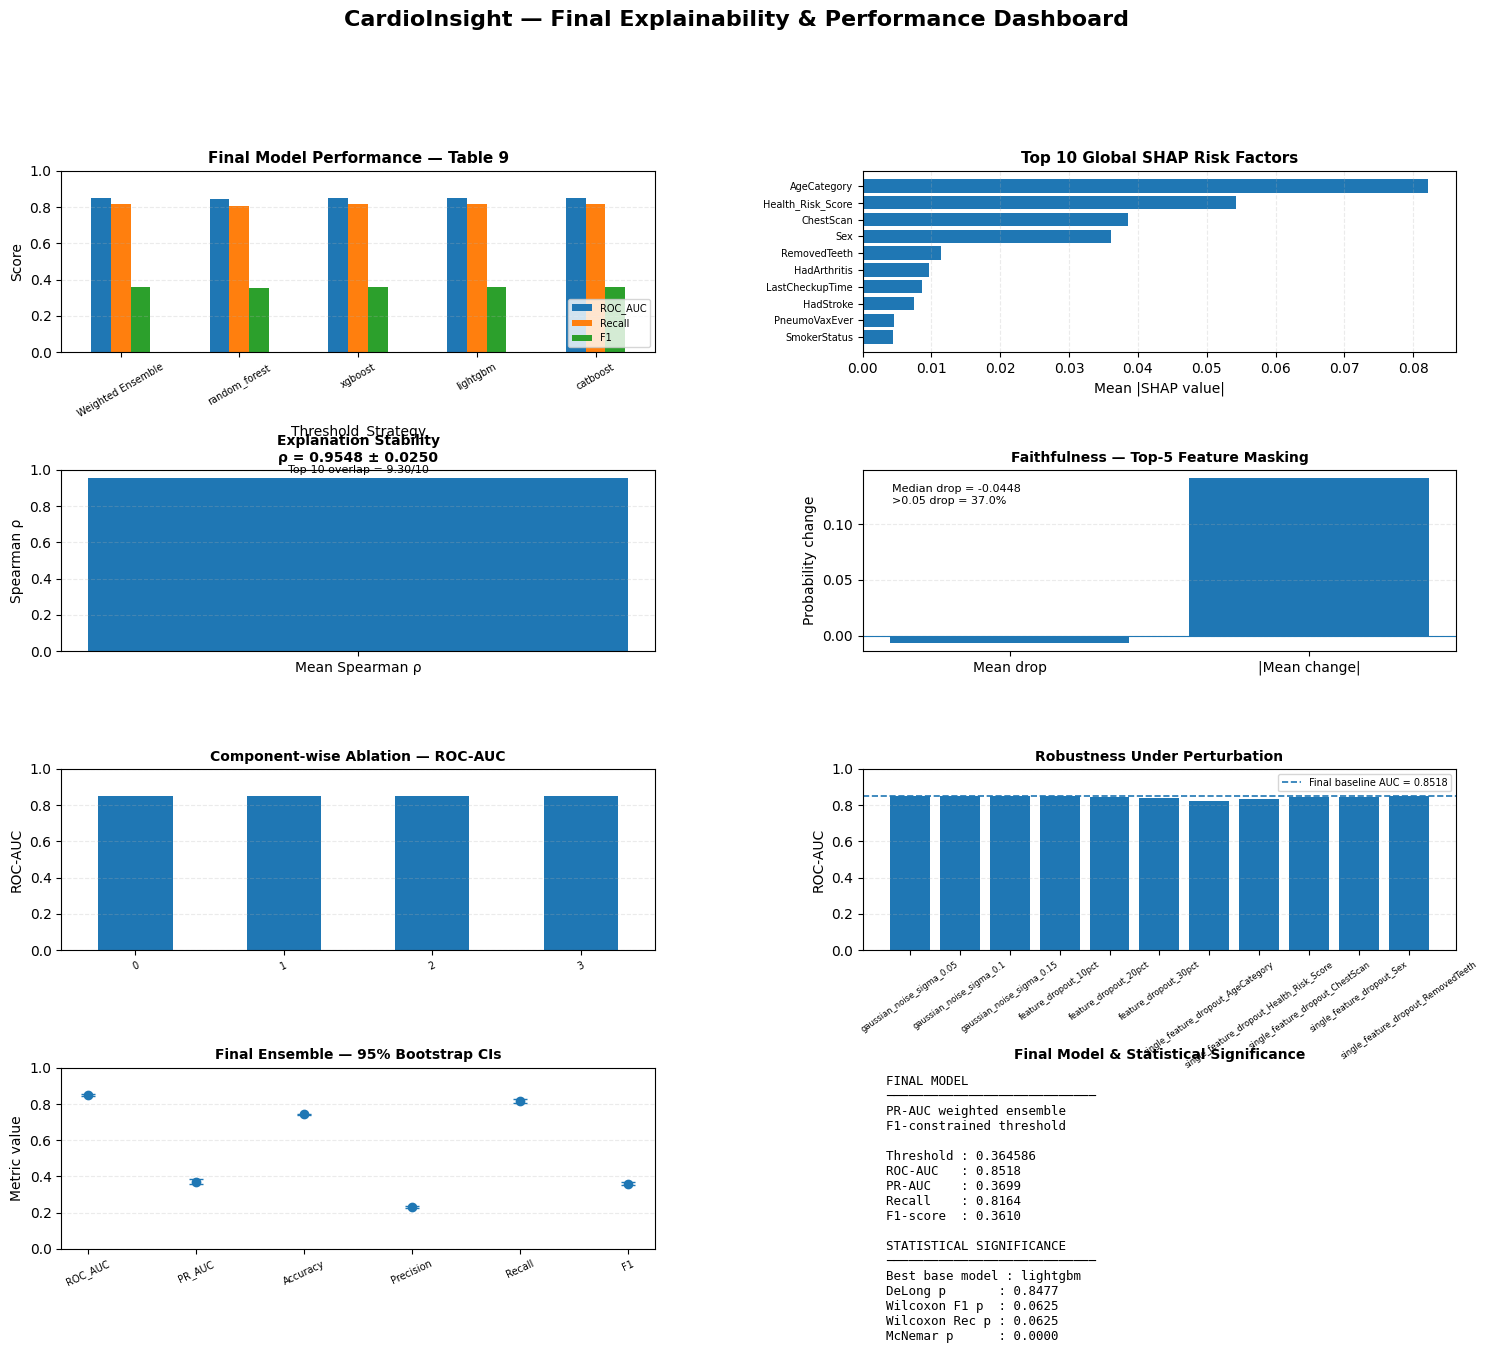

In [ ]:

# ============================================================
# CELL 23 — CARDIOINSIGHT FINAL EXPLAINABILITY & PERFORMANCE DASHBOARD
# ============================================================
#
# IMPORTANT:
# This dashboard uses ONLY the CURRENTLY SAVED outputs from
# the latest CardioInsight pipeline in ncvd(10).
#
# NO MODEL RETRAINING
# NO SHAP RECALCULATION
# NO NEW PREDICTIONS
# NO HYPERPARAMETER SEARCH
#
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec


# ============================================================
# 1. CURRENT PROJECT PATHS — EXACT
# ============================================================

BASE = '/content/drive/MyDrive/CVD'

RESULTS_DIR = f'{BASE}/results'
FIGURES_DIR = f'{BASE}/figures'

ENSEMBLE_DIR = f'{RESULTS_DIR}/ensemble'


# ============================================================
# 2. EXACT CURRENT SAVED FILES
# ============================================================

dashboard_sources = {

    # --------------------------------------------------------
    # TABLE 9 — INDIVIDUAL VS ENSEMBLE
    # --------------------------------------------------------
    'table9':
        f'{FIGURES_DIR}/table9_individual_vs_ensemble/'
        f'table9_individual_vs_ensemble.csv',

    # --------------------------------------------------------
    # CURRENT GLOBAL SHAP IMPORTANCE
    # --------------------------------------------------------
    'global_shap':
        f'{ENSEMBLE_DIR}/'
        f'final_probability_shap_global_importance.csv',

    # --------------------------------------------------------
    # 5-FOLD SHAP EXPLANATION STABILITY
    # --------------------------------------------------------
    'stability':
        f'{ENSEMBLE_DIR}/explanation_stability/'
        f'5fold_shap_stability_summary.csv',

    # --------------------------------------------------------
    # FAITHFULNESS
    # --------------------------------------------------------
    'faithfulness':
        f'{ENSEMBLE_DIR}/faithfulness/'
        f'faithfulness_final_weighted_ensemble.pkl',

    # --------------------------------------------------------
    # TABLE 14 — COMPONENT-WISE ABLATION
    # --------------------------------------------------------
    'table14':
        f'{FIGURES_DIR}/table14_ablation_analysis/'
        f'table14_ablation_analysis.csv',

    # --------------------------------------------------------
    # ROBUSTNESS
    # --------------------------------------------------------
    'robustness':
        f'{ENSEMBLE_DIR}/robustness_results.pkl',

    # --------------------------------------------------------
    # STATISTICAL SIGNIFICANCE
    # --------------------------------------------------------
    'significance':
        f'{ENSEMBLE_DIR}/statistical_significance/'
        f'significance_results_complete.json',

    # --------------------------------------------------------
    # BOOTSTRAP CI TABLE
    # --------------------------------------------------------
    'bootstrap_ci':
        f'{ENSEMBLE_DIR}/statistical_significance/'
        f'bootstrap_95CI_all_metrics.csv',

    # --------------------------------------------------------
    # STATISTICAL TEST TABLE
    # --------------------------------------------------------
    'significance_tests':
        f'{ENSEMBLE_DIR}/statistical_significance/'
        f'statistical_significance_tests.csv',

    # --------------------------------------------------------
    # FINAL PROBABILITY-SHAP CHECKPOINT
    # --------------------------------------------------------
    'shap_values':
        f'{ENSEMBLE_DIR}/'
        f'newensemble_probability_shap_values.pkl',

    'shap_base':
        f'{ENSEMBLE_DIR}/'
        f'newensemble_probability_shap_base.pkl',

    'shap_X':
        f'{ENSEMBLE_DIR}/'
        f'newensemble_probability_shap_X.pkl',
}


# ============================================================
# 3. LOAD SAVED RESULTS ONLY
# ============================================================

print("=" * 80)
print("CARDIOINSIGHT — FINAL DASHBOARD")
print("=" * 80)

loaded = {}

for key, path in dashboard_sources.items():

    if not os.path.exists(path):

        print(f"⚠ MISSING: {key}")
        print(f"  {path}")

        loaded[key] = None
        continue

    try:

        if path.endswith('.csv'):

            loaded[key] = pd.read_csv(path)

        elif path.endswith('.pkl'):

            loaded[key] = joblib.load(path)

        elif path.endswith('.json'):

            with open(path, 'r') as f:
                loaded[key] = json.load(f)

        print(f"✓ Loaded: {key}")
        print(f"  {path}")

    except Exception as e:

        loaded[key] = None

        print(f"✗ ERROR loading: {key}")
        print(f"  {e}")


# ============================================================
# 4. VERIFY IMPORTANT CURRENT FILES
# ============================================================

print("\n" + "=" * 80)
print("CURRENT RESULT VERIFICATION")
print("=" * 80)


# ------------------------------------------------------------
# Table 9
# ------------------------------------------------------------

if loaded['table9'] is not None:

    table9 = loaded['table9'].copy()

    # Current Table 9 has Threshold_Strategy as index
    if 'Threshold_Strategy' in table9.columns:

        table9 = table9.set_index(
            'Threshold_Strategy'
        )

    print("\n✓ TABLE 9")
    print(table9.round(6))


# ------------------------------------------------------------
# Global SHAP
# ------------------------------------------------------------

if loaded['global_shap'] is not None:

    global_shap = loaded['global_shap'].copy()

    print("\n✓ GLOBAL SHAP")
    print(
        global_shap.head(10).round(6)
    )


# ------------------------------------------------------------
# Stability
# ------------------------------------------------------------

if loaded['stability'] is not None:

    stability_df = loaded['stability'].copy()

    print("\n✓ EXPLANATION STABILITY")
    print(stability_df)


# ------------------------------------------------------------
# Faithfulness
# ------------------------------------------------------------

if loaded['faithfulness'] is not None:

    faithfulness = loaded['faithfulness']

    print("\n✓ FAITHFULNESS")

    if isinstance(faithfulness, dict):

        print(
            "Mean probability drop:",
            faithfulness.get(
                'mean_probability_drop',
                np.nan
            )
        )

        print(
            "Mean absolute change:",
            faithfulness.get(
                'mean_absolute_probability_change',
                np.nan
            )
        )


# ============================================================
# 5. CREATE FINAL DASHBOARD
# ============================================================

fig = plt.figure(
    figsize=(18, 14)
)

gs = gridspec.GridSpec(
    4,
    2,
    figure=fig,
    hspace=0.65,
    wspace=0.35
)


# ============================================================
# PANEL 1 — FINAL MODEL PERFORMANCE
# TABLE 9
# ============================================================

ax1 = fig.add_subplot(
    gs[0, 0]
)

if loaded['table9'] is not None:

    df = table9.copy()

    metrics = [
        'ROC_AUC',
        'Recall',
        'F1'
    ]

    available = [
        m for m in metrics
        if m in df.columns
    ]

    if available:

        df[available].plot(
            kind='bar',
            ax=ax1
        )

        ax1.set_title(
            'Final Model Performance — Table 9',
            fontsize=11,
            fontweight='bold'
        )

        ax1.set_ylabel(
            'Score'
        )

        ax1.set_ylim(
            0,
            1
        )

        ax1.tick_params(
            axis='x',
            rotation=30,
            labelsize=7
        )

        ax1.grid(
            axis='y',
            linestyle='--',
            alpha=0.25
        )

        ax1.legend(
            fontsize=7,
            loc='lower right'
        )

    else:

        ax1.text(
            0.5,
            0.5,
            'Required metrics unavailable',
            ha='center',
            va='center'
        )

        ax1.axis('off')

else:

    ax1.text(
        0.5,
        0.5,
        'Table 9 unavailable',
        ha='center',
        va='center'
    )

    ax1.axis('off')


# ============================================================
# PANEL 2 — TOP 10 GLOBAL SHAP FEATURES
# CURRENT SHAP FILE
# ============================================================

ax2 = fig.add_subplot(
    gs[0, 1]
)

if loaded['global_shap'] is not None:

    shap_df = global_shap.copy()

    if (
        'feature' in shap_df.columns
        and
        'mean_abs_shap' in shap_df.columns
    ):

        top10 = (
            shap_df
            .sort_values(
                'mean_abs_shap',
                ascending=False
            )
            .head(10)
            .copy()
        )

        ax2.barh(
            top10['feature'][::-1],
            top10['mean_abs_shap'][::-1]
        )

        ax2.set_title(
            'Top 10 Global SHAP Risk Factors',
            fontsize=11,
            fontweight='bold'
        )

        ax2.set_xlabel(
            'Mean |SHAP value|'
        )

        ax2.tick_params(
            axis='y',
            labelsize=7
        )

        ax2.grid(
            axis='x',
            linestyle='--',
            alpha=0.25
        )

    else:

        ax2.text(
            0.5,
            0.5,
            'SHAP importance columns unavailable',
            ha='center',
            va='center'
        )

        ax2.axis('off')

else:

    ax2.text(
        0.5,
        0.5,
        'Global SHAP file unavailable',
        ha='center',
        va='center'
    )

    ax2.axis('off')


# ============================================================
# PANEL 3 — EXPLANATION STABILITY
# ============================================================

ax3 = fig.add_subplot(
    gs[1, 0]
)

if loaded['stability'] is not None:

    stab = stability_df.copy()

    if (
        'Metric' in stab.columns
        and
        'Value' in stab.columns
    ):

        metric_map = dict(
            zip(
                stab['Metric'],
                stab['Value']
            )
        )

        mean_rho = float(
            metric_map.get(
                'Mean Spearman rho',
                np.nan
            )
        )

        std_rho = float(
            metric_map.get(
                'Std Spearman rho',
                np.nan
            )
        )

        mean_overlap = float(
            metric_map.get(
                'Mean Top-10 overlap',
                np.nan
            )
        )

        if np.isfinite(mean_rho):

            ax3.bar(
                ['Mean Spearman ρ'],
                [mean_rho]
            )

            ax3.set_ylim(
                0,
                1
            )

            title = (
                f'Explanation Stability\n'
                f'ρ = {mean_rho:.4f} ± {std_rho:.4f}'
            )

            ax3.set_title(
                title,
                fontsize=10,
                fontweight='bold'
            )

            ax3.set_ylabel(
                'Spearman ρ'
            )

            ax3.grid(
                axis='y',
                linestyle='--',
                alpha=0.25
            )

            ax3.text(
                0,
                mean_rho + 0.03,
                f'Top-10 overlap = {mean_overlap:.2f}/10',
                ha='center',
                fontsize=8
            )

        else:

            ax3.text(
                0.5,
                0.5,
                'Stability value unavailable',
                ha='center',
                va='center'
            )

            ax3.axis('off')

    else:

        ax3.text(
            0.5,
            0.5,
            'Unexpected stability format',
            ha='center',
            va='center'
        )

        ax3.axis('off')

else:

    ax3.text(
        0.5,
        0.5,
        'Stability results unavailable',
        ha='center',
        va='center'
    )

    ax3.axis('off')


# ============================================================
# PANEL 4 — FAITHFULNESS
# ============================================================

ax4 = fig.add_subplot(
    gs[1, 1]
)

if loaded['faithfulness'] is not None:

    f = loaded['faithfulness']

    mean_drop = float(
        f.get(
            'mean_probability_drop',
            np.nan
        )
    )

    mean_abs_change = float(
        f.get(
            'mean_absolute_probability_change',
            np.nan
        )
    )

    median_drop = float(
        f.get(
            'median_probability_drop',
            np.nan
        )
    )

    meaningful_drop = float(
        f.get(
            'pct_patients_with_gt_0.05_probability_drop',
            np.nan
        )
    )

    labels = []
    values = []

    if np.isfinite(mean_drop):

        labels.append(
            'Mean drop'
        )

        values.append(
            mean_drop
        )

    if np.isfinite(mean_abs_change):

        labels.append(
            '|Mean change|'
        )

        values.append(
            mean_abs_change
        )

    if len(values) > 0:

        ax4.bar(
            labels,
            values
        )

        ax4.axhline(
            0,
            linewidth=0.8
        )

        ax4.set_title(
            'Faithfulness — Top-5 Feature Masking',
            fontsize=10,
            fontweight='bold'
        )

        ax4.set_ylabel(
            'Probability change'
        )

        ax4.grid(
            axis='y',
            linestyle='--',
            alpha=0.25
        )

        ax4.text(
            0.05,
            0.92,
            (
                f'Median drop = {median_drop:.4f}\n'
                f'>0.05 drop = {meaningful_drop:.1f}%'
            ),
            transform=ax4.transAxes,
            fontsize=8,
            va='top'
        )

    else:

        ax4.text(
            0.5,
            0.5,
            'Faithfulness metrics unavailable',
            ha='center',
            va='center'
        )

        ax4.axis('off')

else:

    ax4.text(
        0.5,
        0.5,
        'Faithfulness results unavailable',
        ha='center',
        va='center'
    )

    ax4.axis('off')


# ============================================================
# PANEL 5 — TABLE 14 ABLATION
# ============================================================

ax5 = fig.add_subplot(
    gs[2, 0]
)

if loaded['table14'] is not None:

    abl = loaded['table14'].copy()

    if 'ROC_AUC' in abl.columns:

        abl['ROC_AUC'].plot(
            kind='bar',
            ax=ax5
        )

        ax5.set_title(
            'Component-wise Ablation — ROC-AUC',
            fontsize=10,
            fontweight='bold'
        )

        ax5.set_ylabel(
            'ROC-AUC'
        )

        ax5.set_ylim(
            0,
            1
        )

        ax5.tick_params(
            axis='x',
            rotation=25,
            labelsize=7
        )

        ax5.grid(
            axis='y',
            linestyle='--',
            alpha=0.25
        )

    else:

        ax5.text(
            0.5,
            0.5,
            'ROC_AUC unavailable',
            ha='center',
            va='center'
        )

        ax5.axis('off')

else:

    ax5.text(
        0.5,
        0.5,
        'Table 14 unavailable',
        ha='center',
        va='center'
    )

    ax5.axis('off')


# ============================================================
# PANEL 6 — ROBUSTNESS
# ============================================================

ax6 = fig.add_subplot(
    gs[2, 1]
)

if loaded['robustness'] is not None:

    try:

        robustness_dict = loaded['robustness']

        robustness_df = (
            pd.DataFrame(
                robustness_dict
            )
            .T
            .reset_index()
            .rename(
                columns={
                    'index': 'Perturbation'
                }
            )
        )

        # ----------------------------------------------------
        # Baseline is the FINAL weighted ensemble ROC-AUC
        # from Table 9
        # ----------------------------------------------------

        baseline_auc = np.nan

        if (
            loaded['table9'] is not None
            and
            'ROC_AUC' in table9.columns
            and
            'Weighted Ensemble' in table9.index
        ):

            baseline_auc = float(
                table9.loc[
                    'Weighted Ensemble',
                    'ROC_AUC'
                ]
            )

        if 'ROC_AUC' in robustness_df.columns:

            plot_values = robustness_df[
                'ROC_AUC'
            ].astype(float)

            ax6.bar(
                robustness_df['Perturbation'],
                plot_values
            )

            if np.isfinite(baseline_auc):

                ax6.axhline(
                    baseline_auc,
                    linestyle='--',
                    linewidth=1.2,
                    label=(
                        f'Final baseline AUC = '
                        f'{baseline_auc:.4f}'
                    )
                )

                ax6.legend(
                    fontsize=7
                )

            ax6.set_title(
                'Robustness Under Perturbation',
                fontsize=10,
                fontweight='bold'
            )

            ax6.set_ylabel(
                'ROC-AUC'
            )

            ax6.set_ylim(
                0,
                1
            )

            ax6.tick_params(
                axis='x',
                rotation=35,
                labelsize=6
            )

            ax6.grid(
                axis='y',
                linestyle='--',
                alpha=0.25
            )

        else:

            ax6.text(
                0.5,
                0.5,
                'ROC_AUC unavailable',
                ha='center',
                va='center'
            )

            ax6.axis('off')

    except Exception as e:

        ax6.text(
            0.5,
            0.5,
            f'Robustness plotting error:\n{e}',
            ha='center',
            va='center'
        )

        ax6.axis('off')

else:

    ax6.text(
        0.5,
        0.5,
        'Robustness results unavailable',
        ha='center',
        va='center'
    )

    ax6.axis('off')


# ============================================================
# PANEL 7 — BOOTSTRAP CONFIDENCE INTERVALS
# ============================================================

ax7 = fig.add_subplot(
    gs[3, 0]
)

if loaded['bootstrap_ci'] is not None:

    ci_df = loaded['bootstrap_ci'].copy()

    required_ci_cols = [
        'Metric',
        'Ensemble',
        'Ensemble_CI_Lower',
        'Ensemble_CI_Upper'
    ]

    if all(
        c in ci_df.columns
        for c in required_ci_cols
    ):

        metrics = [
            'ROC_AUC',
            'PR_AUC',
            'Accuracy',
            'Precision',
            'Recall',
            'F1'
        ]

        ci_plot = ci_df[
            ci_df['Metric'].isin(metrics)
        ].copy()

        if len(ci_plot) > 0:

            x = np.arange(
                len(ci_plot)
            )

            values = (
                ci_plot['Ensemble']
                .astype(float)
                .to_numpy()
            )

            lower = (
                values
                -
                ci_plot[
                    'Ensemble_CI_Lower'
                ].astype(float).to_numpy()
            )

            upper = (
                ci_plot[
                    'Ensemble_CI_Upper'
                ].astype(float).to_numpy()
                -
                values
            )

            ax7.errorbar(
                x,
                values,
                yerr=[
                    lower,
                    upper
                ],
                fmt='o',
                capsize=5
            )

            ax7.set_xticks(
                x
            )

            ax7.set_xticklabels(
                ci_plot['Metric'],
                rotation=25,
                fontsize=7
            )

            ax7.set_ylim(
                0,
                1
            )

            ax7.set_ylabel(
                'Metric value'
            )

            ax7.set_title(
                'Final Ensemble — 95% Bootstrap CIs',
                fontsize=10,
                fontweight='bold'
            )

            ax7.grid(
                axis='y',
                linestyle='--',
                alpha=0.25
            )

        else:

            ax7.text(
                0.5,
                0.5,
                'CI metrics unavailable',
                ha='center',
                va='center'
            )

            ax7.axis('off')

    else:

        ax7.text(
            0.5,
            0.5,
            'Unexpected CI table format',
            ha='center',
            va='center'
        )

        ax7.axis('off')

else:

    ax7.text(
        0.5,
        0.5,
        'Bootstrap CI results unavailable',
        ha='center',
        va='center'
    )

    ax7.axis('off')


# ============================================================
# PANEL 8 — FINAL MODEL + STATISTICAL SIGNIFICANCE
# ============================================================

ax8 = fig.add_subplot(
    gs[3, 1]
)

ax8.axis('off')


# ------------------------------------------------------------
# Default values
# ------------------------------------------------------------

final_threshold = 0.364586
final_auc = np.nan
final_pr_auc = np.nan
final_recall = np.nan
final_f1 = np.nan

best_base = 'N/A'
delong_p = np.nan
wilcoxon_f1_p = np.nan
wilcoxon_recall_p = np.nan
mcnemar_p = np.nan


# ------------------------------------------------------------
# Read final metrics from Table 9
# ------------------------------------------------------------

if loaded['table9'] is not None:

    if 'Weighted Ensemble' in table9.index:

        row = table9.loc[
            'Weighted Ensemble'
        ]

        if 'Threshold' in row.index:
            final_threshold = float(
                row['Threshold']
            )

        if 'ROC_AUC' in row.index:
            final_auc = float(
                row['ROC_AUC']
            )

        if 'PR_AUC' in row.index:
            final_pr_auc = float(
                row['PR_AUC']
            )

        if 'Recall' in row.index:
            final_recall = float(
                row['Recall']
            )

        if 'F1' in row.index:
            final_f1 = float(
                row['F1']
            )


# ------------------------------------------------------------
# Read significance JSON
# ------------------------------------------------------------

if loaded['significance'] is not None:

    sig = loaded['significance']

    best_base = sig.get(
        'best_base_model',
        'N/A'
    )

    paired_delong = sig.get(
        'paired_delong',
        {}
    )

    delong_p = paired_delong.get(
        'p_value',
        np.nan
    )

    wilcoxon = sig.get(
        'wilcoxon',
        {}
    )

    if isinstance(
        wilcoxon,
        dict
    ):

        wilcoxon_f1_p = (
            wilcoxon
            .get('F1', {})
            .get('p_value', np.nan)
        )

        wilcoxon_recall_p = (
            wilcoxon
            .get('Recall', {})
            .get('p_value', np.nan)
        )

    mcnemar = sig.get(
        'mcnemar',
        {}
    )

    if isinstance(
        mcnemar,
        dict
    ):

        mcnemar_p = mcnemar.get(
            'p_value',
            np.nan
        )


# ------------------------------------------------------------
# Build dashboard text
# ------------------------------------------------------------

def fmt(value, digits=4):

    try:

        if np.isfinite(float(value)):

            return f'{float(value):.{digits}f}'

    except Exception:

        pass

    return 'N/A'


dashboard_text = (
    "FINAL MODEL\n"
    "────────────────────────────\n"
    "PR-AUC weighted ensemble\n"
    "F1-constrained threshold\n\n"

    f"Threshold : {fmt(final_threshold, 6)}\n"
    f"ROC-AUC   : {fmt(final_auc)}\n"
    f"PR-AUC    : {fmt(final_pr_auc)}\n"
    f"Recall    : {fmt(final_recall)}\n"
    f"F1-score  : {fmt(final_f1)}\n\n"

    "STATISTICAL SIGNIFICANCE\n"
    "────────────────────────────\n"
    f"Best base model : {best_base}\n"
    f"DeLong p       : {fmt(delong_p)}\n"
    f"Wilcoxon F1 p  : {fmt(wilcoxon_f1_p)}\n"
    f"Wilcoxon Rec p : {fmt(wilcoxon_recall_p)}\n"
    f"McNemar p      : {fmt(mcnemar_p)}"
)


ax8.text(
    0.04,
    0.96,
    dashboard_text,
    fontsize=9,
    va='top',
    family='monospace'
)

ax8.set_title(
    'Final Model & Statistical Significance',
    fontsize=10,
    fontweight='bold'
)


# ============================================================
# 6. MAIN DASHBOARD TITLE
# ============================================================

fig.suptitle(
    'CardioInsight — Final Explainability & Performance Dashboard',
    fontsize=16,
    fontweight='bold',
    y=0.995
)


# ============================================================
# 7. FINAL DASHBOARD OUTPUT PATH
# ============================================================

dashboard_folder = (
    f'{FIGURES_DIR}/dashboard_summary'
)

os.makedirs(
    dashboard_folder,
    exist_ok=True
)

dashboard_pdf = (
    f'{dashboard_folder}/'
    f'dashboard_summary.pdf'
)

dashboard_png = (
    f'{dashboard_folder}/'
    f'dashboard_summary.png'
)


# ============================================================
# 8. SAVE
# ============================================================

fig.savefig(
    dashboard_pdf,
    dpi=300,
    bbox_inches='tight'
)

fig.savefig(
    dashboard_png,
    dpi=300,
    bbox_inches='tight'
)


# ============================================================
# 9. FINAL STATUS
# ============================================================

print("\n" + "=" * 80)
print("✓ CARDIOINSIGHT FINAL DASHBOARD COMPLETED")
print("=" * 80)

print("\nDashboard PDF:")
print(dashboard_pdf)

print("\nDashboard PNG:")
print(dashboard_png)

print("\n✓ Current Table 9 used.")
print("✓ Current probability-space SHAP importance used.")
print("✓ Current 5-fold explanation stability used.")
print("✓ Current faithfulness checkpoint used.")
print("✓ Current Table 14 used.")
print("✓ Current robustness checkpoint used.")
print("✓ Current statistical significance results used.")

print("\n✓ NO MODEL RETRAINING")
print("✓ NO SHAP RECALCULATION")
print("✓ NO NEW PREDICTIONS")
print("✓ NO HYPERPARAMETER SEARCH")

plt.show()


In [ ]:

# ============================================================
# CELL 23 — CARDIOINSIGHT FINAL DASHBOARD
# INDIVIDUAL FIGURES + COMPLETE DASHBOARD
# ============================================================
#
# CURRENT SAVED FILES ONLY
#
# NO MODEL RETRAINING
# NO SHAP RECALCULATION
# NO NEW PREDICTIONS
#
# Every individual figure:
#   -> PDF
#   -> PNG at 300 DPI
#
# Complete dashboard:
#   -> PDF
#   -> PNG at 300 DPI
#
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec


# ============================================================
# 1. CURRENT PROJECT PATHS
# ============================================================

BASE = '/content/drive/MyDrive/CVD'

RESULTS_DIR = f'{BASE}/results'
FIGURES_DIR = f'{BASE}/figures'
ENSEMBLE_DIR = f'{RESULTS_DIR}/ensemble'


# ============================================================
# 2. EXACT CURRENT SAVED FILES
# ============================================================

dashboard_sources = {

    'table9':
        f'{FIGURES_DIR}/table9_individual_vs_ensemble/'
        f'table9_individual_vs_ensemble.csv',

    'global_shap':
        f'{ENSEMBLE_DIR}/'
        f'final_probability_shap_global_importance.csv',

    'stability':
        f'{ENSEMBLE_DIR}/explanation_stability/'
        f'5fold_shap_stability_summary.csv',

    'faithfulness':
        f'{ENSEMBLE_DIR}/faithfulness/'
        f'faithfulness_final_weighted_ensemble.pkl',

    'table14':
        f'{FIGURES_DIR}/table14_ablation_analysis/'
        f'table14_ablation_analysis.csv',

    'robustness':
        f'{ENSEMBLE_DIR}/robustness_results.pkl',

    'significance':
        f'{ENSEMBLE_DIR}/statistical_significance/'
        f'significance_results_complete.json',

    'bootstrap_ci':
        f'{ENSEMBLE_DIR}/statistical_significance/'
        f'bootstrap_95CI_all_metrics.csv',

    'significance_tests':
        f'{ENSEMBLE_DIR}/statistical_significance/'
        f'statistical_significance_tests.csv',

    'shap_values':
        f'{ENSEMBLE_DIR}/'
        f'newensemble_probability_shap_values.pkl',

    'shap_base':
        f'{ENSEMBLE_DIR}/'
        f'newensemble_probability_shap_base.pkl',

    'shap_X':
        f'{ENSEMBLE_DIR}/'
        f'newensemble_probability_shap_X.pkl',
}


# ============================================================
# 3. LOAD SAVED RESULTS ONLY
# ============================================================

print("=" * 80)
print("CARDIOINSIGHT — FINAL DASHBOARD")
print("=" * 80)

loaded = {}

for key, path in dashboard_sources.items():

    if not os.path.exists(path):

        print(f"⚠ MISSING: {key}")
        print(f"  {path}")

        loaded[key] = None
        continue

    try:

        if path.endswith('.csv'):

            loaded[key] = pd.read_csv(path)

        elif path.endswith('.pkl'):

            loaded[key] = joblib.load(path)

        elif path.endswith('.json'):

            with open(path, 'r') as f:
                loaded[key] = json.load(f)

        print(f"✓ Loaded: {key}")

    except Exception as e:

        loaded[key] = None

        print(f"✗ ERROR loading: {key}")
        print(f"  {e}")


# ============================================================
# 4. PREPARE TABLE 9
# ============================================================

table9 = None

if loaded['table9'] is not None:

    table9 = loaded['table9'].copy()

    if 'Threshold_Strategy' in table9.columns:

        table9 = table9.set_index(
            'Threshold_Strategy'
        )

    print("\n✓ TABLE 9 loaded")


# ============================================================
# 5. PREPARE GLOBAL SHAP
# ============================================================

global_shap = None

if loaded['global_shap'] is not None:

    global_shap = loaded['global_shap'].copy()

    print("✓ GLOBAL SHAP loaded")


# ============================================================
# 6. PREPARE STABILITY
# ============================================================

stability_df = None

if loaded['stability'] is not None:

    stability_df = loaded['stability'].copy()

    print("✓ STABILITY loaded")


# ============================================================
# 7. OUTPUT FOLDER
# ============================================================

dashboard_folder = (
    f'{FIGURES_DIR}/dashboard_summary'
)

os.makedirs(
    dashboard_folder,
    exist_ok=True
)


# ============================================================
# 8. HELPER FUNCTION
# SAVE EACH FIGURE AS:
#   PDF
#   PNG — 300 DPI
# ============================================================

def save_individual_figure(
    fig,
    folder_name,
    file_name
):

    folder = (
        f'{dashboard_folder}/{folder_name}'
    )

    os.makedirs(
        folder,
        exist_ok=True
    )

    pdf_path = (
        f'{folder}/{file_name}.pdf'
    )

    png_path = (
        f'{folder}/{file_name}.png'
    )

    # --------------------------------------------------------
    # PDF
    # --------------------------------------------------------

    fig.savefig(
        pdf_path,
        format='pdf',
        bbox_inches='tight'
    )

    # --------------------------------------------------------
    # PNG — 300 DPI
    # --------------------------------------------------------

    fig.savefig(
        png_path,
        format='png',
        dpi=300,
        bbox_inches='tight'
    )

    print(
        f"✓ Saved figure: {folder_name}/{file_name}"
    )

    print(
        f"  PDF: {pdf_path}"
    )

    print(
        f"  PNG: {png_path}"
    )

    return pdf_path, png_path


# ============================================================
# 9. FIGURE 1 — MODEL PERFORMANCE
# TABLE 9
# ============================================================

fig1, ax1 = plt.subplots(
    figsize=(10, 6)
)

if table9 is not None:

    metrics = [
        'ROC_AUC',
        'Recall',
        'F1'
    ]

    available = [
        m for m in metrics
        if m in table9.columns
    ]

    if available:

        table9[available].plot(
            kind='bar',
            ax=ax1
        )

        ax1.set_title(
            'Model Performance — Individual vs Ensemble',
            fontsize=13,
            fontweight='bold'
        )

        ax1.set_ylabel(
            'Score'
        )

        ax1.set_ylim(
            0,
            1
        )

        ax1.set_xlabel(
            'Model'
        )

        ax1.tick_params(
            axis='x',
            rotation=30
        )

        ax1.grid(
            axis='y',
            linestyle='--',
            alpha=0.25
        )

        ax1.legend(
            fontsize=9
        )

else:

    ax1.text(
        0.5,
        0.5,
        'Table 9 unavailable',
        ha='center',
        va='center'
    )

    ax1.axis('off')


fig1.tight_layout()

save_individual_figure(
    fig1,
    '01_model_performance',
    'figure_model_performance'
)

plt.close(fig1)


# ============================================================
# 10. FIGURE 2 — GLOBAL SHAP
# ============================================================

fig2, ax2 = plt.subplots(
    figsize=(10, 7)
)

if global_shap is not None:

    if (
        'feature' in global_shap.columns
        and
        'mean_abs_shap' in global_shap.columns
    ):

        top10 = (
            global_shap
            .sort_values(
                'mean_abs_shap',
                ascending=False
            )
            .head(10)
            .copy()
        )

        ax2.barh(
            top10['feature'][::-1],
            top10['mean_abs_shap'][::-1]
        )

        ax2.set_title(
            'Top 10 Global SHAP Risk Factors',
            fontsize=13,
            fontweight='bold'
        )

        ax2.set_xlabel(
            'Mean |SHAP value|'
        )

        ax2.set_ylabel(
            'Feature'
        )

        ax2.grid(
            axis='x',
            linestyle='--',
            alpha=0.25
        )

        ax2.tick_params(
            axis='y',
            labelsize=9
        )

else:

    ax2.text(
        0.5,
        0.5,
        'Global SHAP unavailable',
        ha='center',
        va='center'
    )

    ax2.axis('off')


fig2.tight_layout()

save_individual_figure(
    fig2,
    '02_global_shap',
    'figure_global_shap'
)

plt.close(fig2)


# ============================================================
# 11. FIGURE 3 — EXPLANATION STABILITY
# ============================================================

fig3, ax3 = plt.subplots(
    figsize=(8, 6)
)

if stability_df is not None:

    if (
        'Metric' in stability_df.columns
        and
        'Value' in stability_df.columns
    ):

        metric_map = dict(
            zip(
                stability_df['Metric'],
                stability_df['Value']
            )
        )

        mean_rho = float(
            metric_map.get(
                'Mean Spearman rho',
                np.nan
            )
        )

        std_rho = float(
            metric_map.get(
                'Std Spearman rho',
                np.nan
            )
        )

        if np.isfinite(mean_rho):

            ax3.bar(
                ['Mean Spearman ρ'],
                [mean_rho]
            )

            ax3.errorbar(
                [0],
                [mean_rho],
                yerr=[std_rho],
                fmt='none',
                capsize=6,
                linewidth=1.5
            )

            ax3.set_ylim(
                0,
                1
            )

            ax3.set_ylabel(
                'Spearman ρ'
            )

            ax3.set_title(
                (
                    'Explanation Stability\n'
                    f'ρ = {mean_rho:.4f} ± {std_rho:.4f}'
                ),
                fontsize=13,
                fontweight='bold'
            )

            ax3.grid(
                axis='y',
                linestyle='--',
                alpha=0.25
            )

        else:

            ax3.text(
                0.5,
                0.5,
                'Stability value unavailable',
                ha='center',
                va='center'
            )

            ax3.axis('off')

else:

    ax3.text(
        0.5,
        0.5,
        'Stability unavailable',
        ha='center',
        va='center'
    )

    ax3.axis('off')


fig3.tight_layout()

save_individual_figure(
    fig3,
    '03_explanation_stability',
    'figure_explanation_stability'
)

plt.close(fig3)


# ============================================================
# 12. FIGURE 4 — FAITHFULNESS
# ============================================================

fig4, ax4 = plt.subplots(
    figsize=(8, 6)
)

faithfulness = loaded['faithfulness']

if isinstance(
    faithfulness,
    dict
):

    mean_drop = float(
        faithfulness.get(
            'mean_probability_drop',
            np.nan
        )
    )

    mean_abs_change = float(
        faithfulness.get(
            'mean_absolute_probability_change',
            np.nan
        )
    )

    labels = []
    values = []

    if np.isfinite(mean_drop):

        labels.append(
            'Mean probability drop'
        )

        values.append(
            mean_drop
        )

    if np.isfinite(mean_abs_change):

        labels.append(
            'Mean absolute change'
        )

        values.append(
            mean_abs_change
        )

    if values:

        ax4.bar(
            labels,
            values
        )

        ax4.axhline(
            0,
            linewidth=0.8
        )

        ax4.set_title(
            'Faithfulness — Top-5 Feature Masking',
            fontsize=13,
            fontweight='bold'
        )

        ax4.set_ylabel(
            'Probability change'
        )

        ax4.grid(
            axis='y',
            linestyle='--',
            alpha=0.25
        )

        ax4.tick_params(
            axis='x',
            rotation=15
        )

    else:

        ax4.text(
            0.5,
            0.5,
            'Faithfulness metrics unavailable',
            ha='center',
            va='center'
        )

        ax4.axis('off')

else:

    ax4.text(
        0.5,
        0.5,
        'Faithfulness unavailable',
        ha='center',
        va='center'
    )

    ax4.axis('off')


fig4.tight_layout()

save_individual_figure(
    fig4,
    '04_faithfulness',
    'figure_faithfulness'
)

plt.close(fig4)


# ============================================================
# 13. FIGURE 5 — ABLATION
# TABLE 14
# ============================================================

fig5, ax5 = plt.subplots(
    figsize=(10, 6)
)

if loaded['table14'] is not None:

    abl = loaded['table14'].copy()

    if 'ROC_AUC' in abl.columns:

        abl['ROC_AUC'].plot(
            kind='bar',
            ax=ax5
        )

        ax5.set_title(
            'Component-wise Ablation — ROC-AUC',
            fontsize=13,
            fontweight='bold'
        )

        ax5.set_ylabel(
            'ROC-AUC'
        )

        ax5.set_xlabel(
            'Configuration'
        )

        ax5.set_ylim(
            0,
            1
        )

        ax5.tick_params(
            axis='x',
            rotation=25
        )

        ax5.grid(
            axis='y',
            linestyle='--',
            alpha=0.25
        )

else:

    ax5.text(
        0.5,
        0.5,
        'Table 14 unavailable',
        ha='center',
        va='center'
    )

    ax5.axis('off')


fig5.tight_layout()

save_individual_figure(
    fig5,
    '05_ablation',
    'figure_ablation_roc_auc'
)

plt.close(fig5)


# ============================================================
# 14. FIGURE 6 — ROBUSTNESS
# ============================================================

fig6, ax6 = plt.subplots(
    figsize=(12, 7)
)

if loaded['robustness'] is not None:

    try:

        robustness_df = (
            pd.DataFrame(
                loaded['robustness']
            )
            .T
            .reset_index()
            .rename(
                columns={
                    'index': 'Perturbation'
                }
            )
        )

        if 'ROC_AUC' in robustness_df.columns:

            ax6.bar(
                robustness_df['Perturbation'],
                robustness_df['ROC_AUC']
            )

            baseline_auc = np.nan

            if (
                table9 is not None
                and
                'Weighted Ensemble' in table9.index
                and
                'ROC_AUC' in table9.columns
            ):

                baseline_auc = float(
                    table9.loc[
                        'Weighted Ensemble',
                        'ROC_AUC'
                    ]
                )

            if np.isfinite(baseline_auc):

                ax6.axhline(
                    baseline_auc,
                    linestyle='--',
                    linewidth=1.5,
                    label=(
                        f'Final baseline AUC = '
                        f'{baseline_auc:.4f}'
                    )
                )

                ax6.legend(
                    fontsize=9
                )

            ax6.set_title(
                'Robustness Under Feature Perturbation',
                fontsize=13,
                fontweight='bold'
            )

            ax6.set_ylabel(
                'ROC-AUC'
            )

            ax6.set_xlabel(
                'Perturbation'
            )

            ax6.set_ylim(
                0,
                1
            )

            ax6.tick_params(
                axis='x',
                rotation=40,
                labelsize=8
            )

            ax6.grid(
                axis='y',
                linestyle='--',
                alpha=0.25
            )

    except Exception as e:

        ax6.text(
            0.5,
            0.5,
            f'Robustness error:\n{e}',
            ha='center',
            va='center'
        )

        ax6.axis('off')

else:

    ax6.text(
        0.5,
        0.5,
        'Robustness unavailable',
        ha='center',
        va='center'
    )

    ax6.axis('off')


fig6.tight_layout()

save_individual_figure(
    fig6,
    '06_robustness',
    'figure_robustness'
)

plt.close(fig6)


# ============================================================
# 15. FIGURE 7 — BOOTSTRAP 95% CI
# ============================================================

fig7, ax7 = plt.subplots(
    figsize=(10, 6)
)

if loaded['bootstrap_ci'] is not None:

    ci_df = loaded['bootstrap_ci'].copy()

    required_cols = [
        'Metric',
        'Ensemble',
        'Ensemble_CI_Lower',
        'Ensemble_CI_Upper'
    ]

    if all(
        c in ci_df.columns
        for c in required_cols
    ):

        x = np.arange(
            len(ci_df)
        )

        values = (
            ci_df['Ensemble']
            .astype(float)
            .to_numpy()
        )

        lower = (
            values
            -
            ci_df['Ensemble_CI_Lower']
            .astype(float)
            .to_numpy()
        )

        upper = (
            ci_df['Ensemble_CI_Upper']
            .astype(float)
            .to_numpy()
            -
            values
        )

        ax7.errorbar(
            x,
            values,
            yerr=[
                lower,
                upper
            ],
            fmt='o',
            capsize=6,
            linewidth=1.5
        )

        ax7.set_xticks(
            x
        )

        ax7.set_xticklabels(
            ci_df['Metric'],
            rotation=25
        )

        ax7.set_ylim(
            0,
            1
        )

        ax7.set_ylabel(
            'Metric value'
        )

        ax7.set_xlabel(
            'Performance metric'
        )

        ax7.set_title(
            'Final Ensemble — 95% Bootstrap Confidence Intervals',
            fontsize=13,
            fontweight='bold'
        )

        ax7.grid(
            axis='y',
            linestyle='--',
            alpha=0.25
        )

    else:

        ax7.text(
            0.5,
            0.5,
            'Unexpected CI table format',
            ha='center',
            va='center'
        )

        ax7.axis('off')

else:

    ax7.text(
        0.5,
        0.5,
        'Bootstrap CI results unavailable',
        ha='center',
        va='center'
    )

    ax7.axis('off')


fig7.tight_layout()

save_individual_figure(
    fig7,
    '07_bootstrap_ci',
    'figure_bootstrap_95CI'
)

plt.close(fig7)


# ============================================================
# 16. FIGURE 8 — STATISTICAL SIGNIFICANCE
# ============================================================

fig8, ax8 = plt.subplots(
    figsize=(9, 6)
)

ax8.axis('off')

sig = loaded['significance']

if sig is not None:

    best_base = sig.get(
        'best_base_model',
        'N/A'
    )

    paired_delong = sig.get(
        'paired_delong',
        {}
    )

    delong_p = paired_delong.get(
        'p_value',
        np.nan
    )

    wilcoxon = sig.get(
        'wilcoxon',
        {}
    )

    wilcoxon_f1_p = np.nan
    wilcoxon_recall_p = np.nan

    if isinstance(
        wilcoxon,
        dict
    ):

        wilcoxon_f1_p = (
            wilcoxon
            .get('F1', {})
            .get('p_value', np.nan)
        )

        wilcoxon_recall_p = (
            wilcoxon
            .get('Recall', {})
            .get('p_value', np.nan)
        )

    mcnemar = sig.get(
        'mcnemar',
        {}
    )

    mcnemar_p = np.nan

    if isinstance(
        mcnemar,
        dict
    ):

        mcnemar_p = mcnemar.get(
            'p_value',
            np.nan
        )

    def fmt(
        value,
        digits=4
    ):

        try:

            if np.isfinite(
                float(value)
            ):

                return (
                    f'{float(value):.{digits}f}'
                )

        except Exception:

            pass

        return 'N/A'

    txt = (
        "STATISTICAL SIGNIFICANCE\n"
        "────────────────────────────────\n\n"
        f"Best base model : {best_base}\n\n"
        f"Paired DeLong p : {fmt(delong_p)}\n"
        f"Wilcoxon F1 p   : {fmt(wilcoxon_f1_p)}\n"
        f"Wilcoxon Recall : {fmt(wilcoxon_recall_p)}\n"
        f"McNemar p       : {fmt(mcnemar_p)}"
    )

    ax8.text(
        0.08,
        0.50,
        txt,
        fontsize=12,
        va='center',
        family='monospace'
    )

    ax8.set_title(
        'Statistical Significance Tests',
        fontsize=13,
        fontweight='bold'
    )

else:

    ax8.text(
        0.5,
        0.5,
        'Statistical significance results unavailable',
        ha='center',
        va='center'
    )


fig8.tight_layout()

save_individual_figure(
    fig8,
    '08_statistical_significance',
    'figure_statistical_significance'
)

plt.close(fig8)


# ============================================================
# 17. COMPLETE DASHBOARD
# ============================================================

fig = plt.figure(
    figsize=(18, 24)
)

gs = gridspec.GridSpec(
    4,
    2,
    figure=fig,
    hspace=0.65,
    wspace=0.35
)


# ------------------------------------------------------------
# Dashboard Panel 1
# ------------------------------------------------------------

ax1 = fig.add_subplot(
    gs[0, 0]
)

if table9 is not None:

    metrics = [
        'ROC_AUC',
        'Recall',
        'F1'
    ]

    available = [
        m for m in metrics
        if m in table9.columns
    ]

    if available:

        table9[available].plot(
            kind='bar',
            ax=ax1
        )

        ax1.set_title(
            'Model Performance — Table 9',
            fontsize=10,
            fontweight='bold'
        )

        ax1.set_ylabel(
            'Score'
        )

        ax1.set_ylim(
            0,
            1
        )

        ax1.tick_params(
            axis='x',
            rotation=30,
            labelsize=7
        )

        ax1.grid(
            axis='y',
            linestyle='--',
            alpha=0.25
        )

        ax1.legend(
            fontsize=7
        )


# ------------------------------------------------------------
# Dashboard Panel 2
# ------------------------------------------------------------

ax2 = fig.add_subplot(
    gs[0, 1]
)

if global_shap is not None:

    if (
        'feature' in global_shap.columns
        and
        'mean_abs_shap' in global_shap.columns
    ):

        top10 = (
            global_shap
            .sort_values(
                'mean_abs_shap',
                ascending=False
            )
            .head(10)
        )

        ax2.barh(
            top10['feature'][::-1],
            top10['mean_abs_shap'][::-1]
        )

        ax2.set_title(
            'Top 10 Global SHAP Risk Factors',
            fontsize=10,
            fontweight='bold'
        )

        ax2.set_xlabel(
            'Mean |SHAP value|'
        )

        ax2.tick_params(
            axis='y',
            labelsize=7
        )

        ax2.grid(
            axis='x',
            linestyle='--',
            alpha=0.25
        )


# ------------------------------------------------------------
# Dashboard Panel 3
# ------------------------------------------------------------

ax3 = fig.add_subplot(
    gs[1, 0]
)

if stability_df is not None:

    if (
        'Metric' in stability_df.columns
        and
        'Value' in stability_df.columns
    ):

        metric_map = dict(
            zip(
                stability_df['Metric'],
                stability_df['Value']
            )
        )

        mean_rho = float(
            metric_map.get(
                'Mean Spearman rho',
                np.nan
            )
        )

        if np.isfinite(mean_rho):

            ax3.bar(
                ['Mean Spearman ρ'],
                [mean_rho]
            )

            ax3.set_ylim(
                0,
                1
            )

            ax3.set_ylabel(
                'Spearman ρ'
            )

            ax3.set_title(
                f'Explanation Stability — ρ={mean_rho:.4f}',
                fontsize=10,
                fontweight='bold'
            )

            ax3.grid(
                axis='y',
                linestyle='--',
                alpha=0.25
            )


# ------------------------------------------------------------
# Dashboard Panel 4
# ------------------------------------------------------------

ax4 = fig.add_subplot(
    gs[1, 1]
)

if isinstance(
    faithfulness,
    dict
):

    fd = float(
        faithfulness.get(
            'mean_probability_drop',
            np.nan
        )
    )

    fac = float(
        faithfulness.get(
            'mean_absolute_probability_change',
            np.nan
        )
    )

    labels = []
    values = []

    if np.isfinite(fd):

        labels.append(
            'Mean drop'
        )

        values.append(
            fd
        )

    if np.isfinite(fac):

        labels.append(
            '|Mean change|'
        )

        values.append(
            fac
        )

    if values:

        ax4.bar(
            labels,
            values
        )

        ax4.set_title(
            'Faithfulness — Top-5 Masking',
            fontsize=10,
            fontweight='bold'
        )

        ax4.set_ylabel(
            'Probability change'
        )

        ax4.grid(
            axis='y',
            linestyle='--',
            alpha=0.25
        )


# ------------------------------------------------------------
# Dashboard Panel 5
# ------------------------------------------------------------

ax5 = fig.add_subplot(
    gs[2, 0]
)

if loaded['table14'] is not None:

    abl = loaded['table14']

    if 'ROC_AUC' in abl.columns:

        abl['ROC_AUC'].plot(
            kind='bar',
            ax=ax5
        )

        ax5.set_title(
            'Ablation — ROC-AUC',
            fontsize=10,
            fontweight='bold'
        )

        ax5.set_ylabel(
            'ROC-AUC'
        )

        ax5.set_ylim(
            0,
            1
        )

        ax5.tick_params(
            axis='x',
            rotation=25,
            labelsize=7
        )

        ax5.grid(
            axis='y',
            linestyle='--',
            alpha=0.25
        )


# ------------------------------------------------------------
# Dashboard Panel 6
# ------------------------------------------------------------

ax6 = fig.add_subplot(
    gs[2, 1]
)

if loaded['robustness'] is not None:

    try:

        rob = (
            pd.DataFrame(
                loaded['robustness']
            )
            .T
            .reset_index()
        )

        rob = rob.rename(
            columns={
                'index': 'Perturbation'
            }
        )

        if 'ROC_AUC' in rob.columns:

            ax6.bar(
                rob['Perturbation'],
                rob['ROC_AUC']
            )

            if (
                table9 is not None
                and
                'Weighted Ensemble' in table9.index
            ):

                baseline = float(
                    table9.loc[
                        'Weighted Ensemble',
                        'ROC_AUC'
                    ]
                )

                ax6.axhline(
                    baseline,
                    linestyle='--',
                    linewidth=1.2,
                    label='Final baseline'
                )

                ax6.legend(
                    fontsize=7
                )

            ax6.set_title(
                'Robustness Under Perturbation',
                fontsize=10,
                fontweight='bold'
            )

            ax6.set_ylabel(
                'ROC-AUC'
            )

            ax6.set_ylim(
                0,
                1
            )

            ax6.tick_params(
                axis='x',
                rotation=35,
                labelsize=6
            )

            ax6.grid(
                axis='y',
                linestyle='--',
                alpha=0.25
            )

    except Exception:

        pass


# ------------------------------------------------------------
# Dashboard Panel 7
# ------------------------------------------------------------

ax7 = fig.add_subplot(
    gs[3, 0]
)

if loaded['bootstrap_ci'] is not None:

    ci_df = loaded['bootstrap_ci']

    if all(
        c in ci_df.columns
        for c in [
            'Metric',
            'Ensemble',
            'Ensemble_CI_Lower',
            'Ensemble_CI_Upper'
        ]
    ):

        x = np.arange(
            len(ci_df)
        )

        vals = (
            ci_df['Ensemble']
            .astype(float)
            .to_numpy()
        )

        lo = (
            vals
            -
            ci_df['Ensemble_CI_Lower']
            .astype(float)
            .to_numpy()
        )

        hi = (
            ci_df['Ensemble_CI_Upper']
            .astype(float)
            .to_numpy()
            -
            vals
        )

        ax7.errorbar(
            x,
            vals,
            yerr=[lo, hi],
            fmt='o',
            capsize=5
        )

        ax7.set_xticks(
            x
        )

        ax7.set_xticklabels(
            ci_df['Metric'],
            rotation=25,
            fontsize=7
        )

        ax7.set_ylim(
            0,
            1
        )

        ax7.set_ylabel(
            'Metric value'
        )

        ax7.set_title(
            'Final Ensemble — 95% Bootstrap CIs',
            fontsize=10,
            fontweight='bold'
        )

        ax7.grid(
            axis='y',
            linestyle='--',
            alpha=0.25
        )


# ------------------------------------------------------------
# Dashboard Panel 8
# ------------------------------------------------------------

ax8 = fig.add_subplot(
    gs[3, 1]
)

ax8.axis('off')

final_threshold = 0.364586
final_auc = np.nan
final_pr_auc = np.nan
final_recall = np.nan
final_f1 = np.nan

if table9 is not None:

    if 'Weighted Ensemble' in table9.index:

        row = table9.loc[
            'Weighted Ensemble'
        ]

        if 'Threshold' in row.index:
            final_threshold = float(
                row['Threshold']
            )

        if 'ROC_AUC' in row.index:
            final_auc = float(
                row['ROC_AUC']
            )

        if 'PR_AUC' in row.index:
            final_pr_auc = float(
                row['PR_AUC']
            )

        if 'Recall' in row.index:
            final_recall = float(
                row['Recall']
            )

        if 'F1' in row.index:
            final_f1 = float(
                row['F1']
            )


best_base = 'N/A'
delong_p = np.nan
wilcoxon_f1_p = np.nan
wilcoxon_recall_p = np.nan
mcnemar_p = np.nan

if sig is not None:

    best_base = sig.get(
        'best_base_model',
        'N/A'
    )

    delong_p = (
        sig
        .get('paired_delong', {})
        .get('p_value', np.nan)
    )

    wilcoxon = sig.get(
        'wilcoxon',
        {}
    )

    if isinstance(
        wilcoxon,
        dict
    ):

        wilcoxon_f1_p = (
            wilcoxon
            .get('F1', {})
            .get('p_value', np.nan)
        )

        wilcoxon_recall_p = (
            wilcoxon
            .get('Recall', {})
            .get('p_value', np.nan)
        )

    mcnemar_p = (
        sig
        .get('mcnemar', {})
        .get('p_value', np.nan)
    )


def fmt(
    value,
    digits=4
):

    try:

        if np.isfinite(
            float(value)
        ):

            return (
                f'{float(value):.{digits}f}'
            )

    except Exception:

        pass

    return 'N/A'


txt = (
    "FINAL WEIGHTED ENSEMBLE\n"
    "──────────────────────────────\n"
    f"Threshold : {fmt(final_threshold, 6)}\n"
    f"ROC-AUC   : {fmt(final_auc)}\n"
    f"PR-AUC    : {fmt(final_pr_auc)}\n"
    f"Recall    : {fmt(final_recall)}\n"
    f"F1-score  : {fmt(final_f1)}\n\n"
    "SIGNIFICANCE\n"
    "──────────────────────────────\n"
    f"Best base       : {best_base}\n"
    f"DeLong p       : {fmt(delong_p)}\n"
    f"Wilcoxon F1 p  : {fmt(wilcoxon_f1_p)}\n"
    f"Wilcoxon Rec p : {fmt(wilcoxon_recall_p)}\n"
    f"McNemar p      : {fmt(mcnemar_p)}"
)

ax8.text(
    0.04,
    0.96,
    txt,
    fontsize=9,
    va='top',
    family='monospace'
)

ax8.set_title(
    'Final Model & Statistical Significance',
    fontsize=10,
    fontweight='bold'
)


# ============================================================
# 18. COMPLETE DASHBOARD SAVE
# ============================================================

fig.suptitle(
    'CardioInsight — Final Explainability & Performance Dashboard',
    fontsize=17,
    fontweight='bold',
    y=0.995
)

fig.tight_layout(
    rect=[0, 0, 1, 0.98]
)


dashboard_pdf = (
    f'{dashboard_folder}/'
    f'dashboard_summary.pdf'
)

dashboard_png = (
    f'{dashboard_folder}/'
    f'dashboard_summary.png'
)


# PDF — vector quality
fig.savefig(
    dashboard_pdf,
    format='pdf',
    bbox_inches='tight'
)

# PNG — 300 DPI
fig.savefig(
    dashboard_png,
    format='png',
    dpi=300,
    bbox_inches='tight'
)

plt.close(fig)


# ============================================================
# 19. FINAL STATUS
# ============================================================

print("\n" + "=" * 80)
print("✓ CARDIOINSIGHT DASHBOARD COMPLETED")
print("=" * 80)

print("\nCOMPLETE DASHBOARD:")
print(f"PDF: {dashboard_pdf}")
print(f"PNG: {dashboard_png}")

print("\nINDIVIDUAL FIGURES:")
print(
    f"{dashboard_folder}/01_model_performance/"
)
print(
    f"{dashboard_folder}/02_global_shap/"
)
print(
    f"{dashboard_folder}/03_explanation_stability/"
)
print(
    f"{dashboard_folder}/04_faithfulness/"
)
print(
    f"{dashboard_folder}/05_ablation/"
)
print(
    f"{dashboard_folder}/06_robustness/"
)
print(
    f"{dashboard_folder}/07_bootstrap_ci/"
)
print(
    f"{dashboard_folder}/08_statistical_significance/"
)

print("\n✓ Every individual figure saved as PDF.")
print("✓ Every individual figure saved as PNG at 300 DPI.")
print("✓ Complete dashboard saved as PDF.")
print("✓ Complete dashboard saved as PNG at 300 DPI.")

print("\n✓ NO MODEL RETRAINING")
print("✓ NO SHAP RECALCULATION")
print("✓ NO NEW PREDICTIONS")
print("✓ NO HYPERPARAMETER SEARCH")

print("\n" + "=" * 80)


CARDIOINSIGHT — FINAL DASHBOARD
✓ Loaded: table9
✓ Loaded: global_shap
✓ Loaded: stability
✓ Loaded: faithfulness
✓ Loaded: table14
✓ Loaded: robustness
✓ Loaded: significance
✓ Loaded: bootstrap_ci
✓ Loaded: significance_tests
✓ Loaded: shap_values
✓ Loaded: shap_base
✓ Loaded: shap_X

✓ TABLE 9 loaded
✓ GLOBAL SHAP loaded
✓ STABILITY loaded
✓ Saved figure: 01_model_performance/figure_model_performance
  PDF: /content/drive/MyDrive/CVD/figures/dashboard_summary/01_model_performance/figure_model_performance.pdf
  PNG: /content/drive/MyDrive/CVD/figures/dashboard_summary/01_model_performance/figure_model_performance.png
✓ Saved figure: 02_global_shap/figure_global_shap
  PDF: /content/drive/MyDrive/CVD/figures/dashboard_summary/02_global_shap/figure_global_shap.pdf
  PNG: /content/drive/MyDrive/CVD/figures/dashboard_summary/02_global_shap/figure_global_shap.png
✓ Saved figure: 03_explanation_stability/figure_explanation_stability
  PDF: /content/drive/MyDrive/CVD/figures/dashboard_summa

/tmp/ipykernel_1813/223384872.py:1795: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(



✓ CARDIOINSIGHT DASHBOARD COMPLETED

COMPLETE DASHBOARD:
PDF: /content/drive/MyDrive/CVD/figures/dashboard_summary/dashboard_summary.pdf
PNG: /content/drive/MyDrive/CVD/figures/dashboard_summary/dashboard_summary.png

INDIVIDUAL FIGURES:
/content/drive/MyDrive/CVD/figures/dashboard_summary/01_model_performance/
/content/drive/MyDrive/CVD/figures/dashboard_summary/02_global_shap/
/content/drive/MyDrive/CVD/figures/dashboard_summary/03_explanation_stability/
/content/drive/MyDrive/CVD/figures/dashboard_summary/04_faithfulness/
/content/drive/MyDrive/CVD/figures/dashboard_summary/05_ablation/
/content/drive/MyDrive/CVD/figures/dashboard_summary/06_robustness/
/content/drive/MyDrive/CVD/figures/dashboard_summary/07_bootstrap_ci/
/content/drive/MyDrive/CVD/figures/dashboard_summary/08_statistical_significance/

✓ Every individual figure saved as PDF.
✓ Every individual figure saved as PNG at 300 DPI.
✓ Complete dashboard saved as PDF.
✓ Complete dashboard saved as PNG at 300 DPI.

✓ NO MOD

In [ ]:
print(loaded['shap_importance'].columns)
print(loaded['shap_importance'].head())
print(loaded['shap_importance'].index[:10])

Index(['mean_abs_shap'], dtype='object')
                   mean_abs_shap
feature                         
AgeCategory             0.576976
Health_Risk_Score       0.371858
ChestScan               0.287588
Sex                     0.237403
RemovedTeeth            0.108315
Index(['AgeCategory', 'Health_Risk_Score', 'ChestScan', 'Sex', 'RemovedTeeth',
       'HadArthritis', 'HadStroke', 'HadCOPD', 'LastCheckupTime',
       'SmokerStatus'],
      dtype='object', name='feature')


In [30]:
import sys, platform, numpy, pandas, scipy, sklearn, statsmodels, xgboost, lightgbm, catboost, shap, imblearn
for n, v in [('Python', sys.version.split()[0]), ('OS', platform.platform()), ('numpy', numpy.__version__), ('pandas', pandas.__version__),
             ('scipy', scipy.__version__), ('scikit-learn', sklearn.__version__), ('statsmodels', statsmodels.__version__),
             ('xgboost', xgboost.__version__), ('lightgbm', lightgbm.__version__), ('catboost', catboost.__version__),
             ('shap', shap.__version__), ('imbalanced-learn', imblearn.__version__)]: print(f"{n:18s}{v}")

Python            3.13.16
OS                Linux-6.6.122+-x86_64-with-glibc2.39
numpy             2.1.3
pandas            2.2.3
scipy             1.16.3
scikit-learn      1.6.1
statsmodels       0.15.0
xgboost           3.4.1
lightgbm          4.6.0
catboost          1.2.10
shap              0.52.0
imbalanced-learn  0.14.2


In [22]:

import sys
import platform
import subprocess

print("Python:", sys.version.split()[0])
print("OS:", platform.platform())

try:
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True,
        timeout=10
    )
    if result.returncode == 0:
        print("\nGPU information:")
        print(result.stdout)
    else:
        print("\nNo accessible NVIDIA GPU in the current runtime.")
        print(result.stderr.strip())
except Exception as e:
    print("\nGPU status unavailable:", str(e))

try:
    import torch
    print("\nPyTorch CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU name:", torch.cuda.get_device_name(0))
except ImportError:
    print("\nPyTorch is not installed; this check is not required for your models.")


Python: 3.13.15
OS: Linux-6.6.122+-x86_64-with-glibc2.39

GPU information:
Sun Oct 18 17:33:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P0             28W /   70W |     105MiB /  15360MiB |      0%      Default |
|                                         |                      